# <center>Tolerance score modelling</center>
## <center>Fine-tuning ESM to predict missense tolerance across postsynaptic SynGO proteins</center>

**Goal:** learn a per-residue *tolerance score* (gnomAD density − ClinVar density, built with `convolve_v4`) directly from protein sequence, by fine-tuning a pretrained ESM transformer on Biowulf (NIH HPC).

### Pipeline
| # | Section | Output |
|---|---------|--------|
| 1 | Setup | paths, imports, device |
| 2 | Load + validate data | `psd_seq_df`, `missense_df` (checked) |
| 3 | Tolerance scores (`convolve_v4`) | `tolerance_v4`, `gnomad_y_v4`, `clinvar_y_v4` per gene |
| 4 | ESM scores | per-residue log-prob arrays (`.npz`) + per-variant LLRs |
| 5 | Master per-residue table | one long parquet: every score, every residue |
| 6 | Compare scores | correlation table + figures |
| 7 | Structure: RSA + binding interfaces | PDB (best match) → AlphaFold fallback; interface flags (PDBe-KB / ΔSASA) |
| 8 | Protein annotation features | domains, PANTHER family, motifs (ELM), PTMs, disordered binding (MobiDB) |
| 9 | Structure viewer | 3D view coloured by RSA / tolerance / ESM |
| 10 | Gene-level train/val/test split | split manifest |
| 11 | Tokenization + dataset | token tensors + aligned targets/masks |
| 12 | Model definition | ESM backbone + regression head (`model.py`) |
| 13 | Local smoke test | tiny model, few steps, loss goes down |
| 14 | Feasibility check | target reliability, human data vs ESM, linear probe, learning curve, alternative architectures, ablations, variant-severity task |
| 15 | Package job for Biowulf | `tolerance_job/` folder + `submit.sh` |
| 16 | Final test on untouched genes | the 14h variant model vs ESM on the test genes (pre-registered); later, a returned Biowulf model |

Each section has **Goal → Inputs → Outputs → Steps → Checks**. The *Checks* are the things to verify before moving to the next section.

---
## 1. Setup

**Goal:** same header pattern as the other notebooks: put `figures/` on `sys.path` so `convolve`, `tolerance`, `structure`, and `af_viewer` import cleanly, then define where data lives and where results go.

**Steps**
1. `sys.path.insert(0, os.path.abspath(".."))` → `FIGURES`, `DATA`, `RESULTS`.
2. Define `MODEL_DIR`, which points to `../../Model Training/`. That's where `psd_seq_info.parquet`, `missense_df.parquet`, and `psd_esm_scores.npz` currently live. It may be worth moving or copying these into `figures/data/` so that everything is resolved from one place.
3. Make an output folder for this notebook, e.g. `RESULTS/tolerance_model/`.
4. Imports: `numpy`, `pandas`, `torch`, `esm`, `matplotlib`, `scipy.stats`, plus project modules (`convolve`, `tolerance`, `structure`, `af_viewer`).
5. Pick the device (`mps` locally, `cuda` on Biowulf). Write it as `cuda → mps → cpu` so the same code runs in both places.
6. Set a global random seed (`numpy`, `torch`, `random`). The split in §10 has to be reproducible.

**Checks**
- [ ] `from convolve import convolve_v4` and `from tolerance import build_tolerance_columns` import without error.
- [ ] `print(device)` shows `mps`.

In [1]:
import sys, os, random
sys.path.insert(0, os.path.abspath(".."))   # analysis modules live in figures/

FIGURES   = os.path.abspath("..")             # project root for data/ and results/
DATA      = os.path.join(FIGURES, "data")
RESULTS   = os.path.join(FIGURES, "results")
MODEL_DIR = os.path.abspath(os.path.join(FIGURES, "..", "Model Training"))   # parquets + ESM npz
OUT       = os.path.join(RESULTS, "tolerance_model")                       # this notebook's outputs
os.makedirs(OUT, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import importlib

SEED = 0                                      # the §10 split must be reproducible
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# cuda on Biowulf, mps on the Mac, cpu otherwise -- same code runs in both places
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: mps


---
## 2. Load + validate the data

**Goal:** load the sequences (with AIUPred disorder scores) and the missense variants, then confirm they agree before anything gets computed on top of them.

**Inputs**
- `psd_seq_df` has one row per postsynaptic SynGO gene. Columns include `gene`, `sequence`, `uniprot_id`, and `disorder_scores` (one value per residue). *(The full sequence set is still to come.)*
- `missense_df` has one row per variant. Columns include `gene`, `position`, `reference`, `alternate`, `protein_consequence` (e.g. `R601C`), `database` (`GnomAD` / `ClinVar`), and `total_count`.

**Steps**
1. Load both parquets.
2. Write a `validate_inputs(seq_df, var_df)` function that returns a small report DataFrame instead of just printing.

**Checks** (each of these has silently broken a pipeline before)
- [ ] `len(disorder_scores) == len(sequence)` for every gene. A mismatch means the disorder scores came from a different isoform.
- [ ] Reference residue matches: `sequence[position-1] == reference` for every variant. Report the % mismatch per gene. A gene with a high mismatch rate is a transcript/isoform problem (MANE vs. UniProt canonical), not noise.
- [ ] No variant `position` greater than the sequence length.
- [ ] Count variants per gene per database. Genes with 0 ClinVar variants give a flat ClinVar track, so their tolerance is driven only by gnomAD. Flag them; you may want to exclude or down-weight them in training.
- [ ] Sequences contain only the 20 standard amino acids. Note any `U` (selenocysteine) or `X`, since the ESM tokenizer handles them differently.
- [ ] Duplicate genes or duplicate sequences (e.g. paralogs with identical entries).

In [2]:
psd_seq_df = pd.read_parquet(os.path.join(MODEL_DIR, "psd_seq_info.parquet"))
print(f"psd_seq_df: {len(psd_seq_df)} genes")
print("columns:", list(psd_seq_df.columns))

psd_seq_df: 1082 genes
columns: ['gene', 'transcript_id', 'sequence', 'binding_scores', 'disorder_scores', 'y_diff', 'tolerance_y_BLOSUM62', 'clinvar_y_BLOSUM62', 'gnomad_y_BLOSUM62']


In [3]:
# missense_df + ClinVar labels + gnomAD allele frequencies, built once and saved.
# Delete the annotated parquet to rebuild (e.g. after a new ClinVar download).
import variants
importlib.reload(variants)
from variants import parse_variant_summary, add_clinsig, fetch_gnomad_counts, add_allele_freq

ANNOTATED = os.path.join(MODEL_DIR, "missense_df_annotated.parquet")

if os.path.exists(ANNOTATED):
    missense_df = pd.read_parquet(ANNOTATED)
else:
    missense_df = pd.read_parquet(os.path.join(MODEL_DIR, "missense_df.parquet"))

    clinvar_summary = parse_variant_summary(os.path.join(FIGURES, "..", "clinvar_variant_summary.txt.gz"),
                                            ids=missense_df.id)                     # ~45 s
    missense_df = add_clinsig(missense_df, summary=clinvar_summary)

    counts, missing = fetch_gnomad_counts(missense_df.gene.unique())  # ~40 min first time; cached after
    missense_df = add_allele_freq(missense_df, counts, common=0.01)

    missense_df.to_parquet(ANNOTATED)

print(f"missense_df: {len(missense_df):,} variants in {missense_df.gene.nunique()} genes")
missense_df[["gene", "protein_consequence", "database", "clinsig_group", "af_percent", "common"]].head()

missense_df: 1,288,072 variants in 1078 genes


,gene,protein_consequence,database,clinsig_group,af_percent,common
0,SNAP23,p.E154D,ClinVar,vus,0.000124,False
1,SNAP23,p.L76I,ClinVar,vus,NaN,False
2,SNAP23,p.A98S,ClinVar,vus,0.001549,False
3,SNAP23,p.M152T,ClinVar,vus,NaN,False
4,SNAP23,p.A98T,ClinVar,vus,0.011648,False


**Fix: zygosity counts.** The code that built `missense_df` (`syngo_clinvar_request.ipynb`, cell 45, also copied into the web apps; now fixed there) had three slips:
- **X/Y labels swapped:** it built `[allele count, homozygotes, hemizygotes, heterozygotes]`, then saved index 2 (hemizygotes) as `heterozygote count` and index 3 as `hemizygote count`.
- **X/Y genome heterozygotes:** computed as `ac − 2·hom + hemi` instead of `− hemi`.
- **Autosomal genome heterozygotes:** computed as `ac − hom` instead of `ac − 2·hom`.

`total_count` and `homozygote_count` are correct. The swap was confirmed against the gnomAD API: in NLGN4X and NLGN4Y, every value in `heterozygote count` equals gnomAD's hemizygote count.

This cell adds corrected columns and leaves the originals untouched:
- `n_hemi`: men carrying the variant (X/Y). The cell **detects which column holds it**: the one where men contribute about a third of X alleles on common variants. That keeps it correct for both the current file and one regenerated with the fixed code.
- `n_hom`: homozygous carriers
- `n_het` = `total_count − 2·n_hom − n_hemi`, exact on every chromosome, which sidesteps both formula slips
- `sex_chrom`: `"X"` / `"Y"` outside the pseudoautosomal regions (where men have two copies), else `""`

In [4]:
# corrected zygosity counts (see the cell above); originals kept
PAR_GRCH38 = {"X": [(10_001, 2_781_479), (155_701_383, 156_030_895)],      # pseudoautosomal regions:
              "Y": [(10_001, 2_781_479), (56_887_903, 57_217_415)]}        # men have two copies here
F_MALE_X = 397870 / (397870 + 812388)   # share of X alleles from men, gnomAD v4.1 joint (XY / total allele number)

chrom = missense_df.id.str.split("-").str[0]
gpos = missense_df.id.str.split("-").str[1].astype(int)
in_par = pd.Series(False, index=missense_df.index)
for c, ranges in PAR_GRCH38.items():
    for lo, hi in ranges:
        in_par |= (chrom == c) & gpos.between(lo, hi)
missense_df["sex_chrom"] = chrom.where(chrom.isin(["X", "Y"]) & ~in_par, "")   # "X" / "Y" / "" (autosome or PAR)
sex = missense_df.sex_chrom != ""

# which column holds the hemizygous (male) count? men carry ~1/3 of X alleles on common variants
common = missense_df[(missense_df.database == "GnomAD") & (missense_df.sex_chrom == "X")
                     & missense_df.total_count.between(20, 2000)]
male_share = {c: common[c].fillna(0).sum() / common.total_count.sum() for c in ["heterozygote count", "hemizygote count"]}
HEMI_COL = min(male_share, key=lambda c: abs(male_share[c] - F_MALE_X))

missense_df["n_hom"] = missense_df.homozygote_count.fillna(0)
missense_df["n_hemi"] = np.where(sex, missense_df[HEMI_COL].fillna(0), 0)                     # men (XY)
missense_df["n_het"] = missense_df.total_count - 2 * missense_df.n_hom - missense_df.n_hemi    # exact; NaN for ClinVar

g = missense_df[(missense_df.database == "GnomAD") & (missense_df.total_count > 0)]
print(f"hemizygous count found in '{HEMI_COL}' "
      f"({'mislabelled -- original builder' if HEMI_COL == 'heterozygote count' else 'correctly labelled'})")
print(f"male share of X alleles: {male_share[HEMI_COL]:.2f} (expected {F_MALE_X:.2f}; other column {max(male_share.values()):.2f})")
print(f"negative derived heterozygotes: {(g.n_het < 0).sum()} | "
      f"autosomal rows where the original heterozygote column was off: "
      f"{((g.sex_chrom == '') & (g['heterozygote count'] != g.n_het)).sum():,}")

hemizygous count found in 'heterozygote count' (mislabelled -- original builder)
male share of X alleles: 0.31 (expected 0.33; other column 0.76)
negative derived heterozygotes: 0 | autosomal rows where the original heterozygote column was off: 4,762


In [5]:
STANDARD_AA = set("ACDEFGHIKLMNPQRSTVWY")
TRACK_COLS  = ["disorder_scores", "binding_scores"]     # per-residue arrays that must match the sequence

def validate_inputs(seq_df, var_df, track_cols=TRACK_COLS):
    """One row per gene: lengths, non-standard residues, variant counts and reference-residue
    agreement. Nothing is dropped -- the report is for deciding what to drop.
    Also returns the genes that have variants but no sequence."""
    by_gene = var_df.groupby("gene")
    rows = []
    for row in seq_df.itertuples():
        seq = row.sequence
        r = {"gene": row.gene, "seq_len": len(seq),
             "nonstandard_aa": "".join(sorted(set(seq) - STANDARD_AA))}
        for col in track_cols:
            r[f"{col}_len_ok"] = len(getattr(row, col)) == len(seq)

        if row.gene in by_gene.groups:
            v = by_gene.get_group(row.gene)
            pos = v.position.to_numpy()
            in_range = (pos >= 1) & (pos <= len(seq))
            seq_ref = np.array([seq[p - 1] if ok else "" for p, ok in zip(pos, in_range)])
            mismatch = in_range & (seq_ref != v.reference.to_numpy())
            r.update(n_gnomad=int((v.database == "GnomAD").sum()),
                     n_clinvar=int((v.database == "ClinVar").sum()),
                     n_out_of_range=int((~in_range).sum()),
                     n_ref_mismatch=int(mismatch.sum()),
                     pct_ref_mismatch=100 * mismatch.mean())
        else:
            r.update(n_gnomad=0, n_clinvar=0, n_out_of_range=0, n_ref_mismatch=0,
                     pct_ref_mismatch=np.nan)
        rows.append(r)

    report = pd.DataFrame(rows)
    report["dup_sequence"] = seq_df.sequence.duplicated(keep=False).to_numpy()
    no_seq = sorted(set(var_df.gene) - set(seq_df.gene))
    return report, no_seq

In [6]:
report, no_seq = validate_inputs(psd_seq_df, missense_df)

len_cols = [c for c in report if c.endswith("_len_ok")]
print("Track length != sequence length:", {c: int((~report[c]).sum()) for c in len_cols})
print("Non-standard residues:", report.loc[report.nonstandard_aa != "", ["gene", "nonstandard_aa"]]
      .to_dict("records"))
print("Variant genes missing from psd_seq_df:", no_seq)
print("Variants out of range:", int(report.n_out_of_range.sum()))
print(f"Reference mismatches: {report.n_ref_mismatch.sum():,} "
      f"({100 * report.n_ref_mismatch.sum() / len(missense_df):.2f}% of variants)")
print("Genes with no variants:", report.loc[report.n_gnomad + report.n_clinvar == 0, "gene"].tolist())
print("Genes with 0 ClinVar variants:", report.loc[report.n_clinvar == 0, "gene"].tolist())
print("Identical sequences:", report.loc[report.dup_sequence, "gene"].tolist())
print(f"Proteins longer than ESM's 1022-residue window: {(report.seq_len > 1022).sum()}")

report.to_csv(os.path.join(OUT, "input_validation.csv"), index=False)
report.sort_values("pct_ref_mismatch", ascending=False).head(10)

Track length != sequence length: {'disorder_scores_len_ok': 0, 'binding_scores_len_ok': 0}
Non-standard residues: []
Variant genes missing from psd_seq_df: []
Variants out of range: 0
Reference mismatches: 0 (0.00% of variants)
Genes with no variants: ['MRTFA', 'STIM2', 'EIF4G2', 'CACNG8']
Genes with 0 ClinVar variants: ['C9ORF72', 'NEDD8', 'MRTFA', 'C22ORF39', 'EIF1', 'STIM2', 'EIF4G2', 'RPL38', 'UBE2V1', 'CACNG8', 'RPL36A', 'RPL41']
Identical sequences: ['CALM1', 'CALM2', 'CALM3']
Proteins longer than ESM's 1022-residue window: 211


,gene,seq_len,nonstandard_aa,disorder_scores_len_ok,binding_scores_len_ok,n_gnomad,n_clinvar,n_out_of_range,n_ref_mismatch,pct_ref_mismatch,dup_sequence
0,SNAP23,211,,True,True,282,25,0,0,0.0,False
728,LRFN5,719,,True,True,875,72,0,0,0.0,False
713,DCC,1447,,True,True,2096,223,0,0,0.0,False
714,ERBB4,1308,,True,True,1579,334,0,0,0.0,False
715,CACNG4,327,,True,True,488,42,0,0,0.0,False
716,GSG1L,331,,True,True,920,26,0,0,0.0,False
717,CACNG2,323,,True,True,383,52,0,0,0.0,False
718,CACNG3,315,,True,True,269,18,0,0,0.0,False
720,GRID1,1009,,True,True,1328,151,0,0,0.0,False
721,GRID2,1007,,True,True,1467,183,0,0,0.0,False


---
## 3. Tolerance scores with `convolve_v4`

**Goal:** produce a per-residue tolerance track for every gene. This is the **training target** for the model.

**How it's built** (`tolerance.py`, recipe from the `misc_figures` NLGN3 cell)
- `gnomad_y` = `convolve_v4(gnomAD variants, adjustment_list=disorder)` and `clinvar_y` = the same with ClinVar variants.
- Disorder-dependent settings (`V4_PARAMS`):
  - ordered (disorder < 0.5): BLOSUM62 weighting, window w = 31
  - disordered (disorder ≥ 0.5): Grantham weighting, w = 5
  - `aggregate="max"`: the most severe substitution at a residue wins
- `tolerance = normalize(gnomad_y) − normalize(clinvar_y)`. Positive means tolerant, negative means intolerant.

**Steps**
1. `build_tolerance_columns(psd_seq_df, variant_df, name="v4")` adds `tolerance_v4`, `gnomad_y_v4`, `clinvar_y_v4`.
2. Decide on `gnomad_min_count` (default 1).
3. Save the result.

**⚠ Leakage decision, to settle here before training:**
The target is per-residue and the model input is sequence only, so variants don't leak directly. But the tolerance of residue *i* is built from variants up to ±31 residues away. The leakage that matters is between **genes**: paralogs (NLGN1–4, GRIN2A/B, SHANK1–3, DLG1–4…) have near-identical sequences *and* similar tolerance profiles. That's handled by the gene/family split in §10, not here.
→ Build the tolerance tracks once on **all** variants. Hold out whole genes, not variants.

**Checks**
- [ ] Every track length equals its sequence length.
- [ ] Re-plot NLGN3 and confirm it matches the figure from `misc_figures`. That's your known-good reference.
- [ ] Look at the distribution of track means across genes. `normalize` is per gene (min-max), so every gene spans [0, 1] regardless of how many variants it has. Decide whether that's what you want the model to learn: relative tolerance *within* a protein, versus absolute.

In [7]:
# Which variants feed each track
from tolerance import build_tolerance_columns, V4_PARAMS

GNOMAD_MIN_COUNT = 2            # allele count >= 2 on every chromosome: drops singletons (errors / private variants)
CLINVAR_GROUPS   = None         # None = every ClinVar missense (previous behaviour);
                                # e.g. ("pathogenic", "vus") to leave ClinVar-benign out of the intolerant track

# X / Y-linked genes (outside the pseudoautosomal regions): men have one copy, so a variant seen only in
# heterozygous women may be a recessive deleterious allele masked by their second X. X_MODE chooses the rule
# for gnomAD variants there (uses the corrected n_hemi / n_hom from §2):
#   "hemizygous": keep only variants carried by >= X_MIN_MALE_CARRIERS men (hemizygous) + homozygous women
#   "depletion":  drop a women-only variant only when seeing no male carrier is improbable by chance (< X_DEPLETION_P)
#   "none":       treat X / Y like autosomes
X_MODE              = "hemizygous"
X_MIN_MALE_CARRIERS = 1
X_DEPLETION_P       = 0.05
X_DOMINANT_GENES    = []        # X-linked DOMINANT genes, where heterozygous women are affected too: a healthy woman
                                # carrier is real evidence of tolerance there, so these are treated like autosomes.
                                # Candidates in this set (check OMIM first): CDKL5, DDX3X, HNRNPH2, FLNA, USP9X
def gnomad_keep(df, mode=X_MODE):
    """Boolean mask of gnomAD rows to use: allele count everywhere, plus the X_MODE rule on X / Y."""
    base = (df.database == "GnomAD") & (df.total_count >= GNOMAD_MIN_COUNT)
    sex_linked = (df.sex_chrom != "") & ~df.gene.isin(X_DOMINANT_GENES)
    male_seen = (df.n_hemi + df.n_hom) >= X_MIN_MALE_CARRIERS
    if mode == "hemizygous":
        rule = male_seen
    elif mode == "depletion":
        p_no_male = (1 - F_MALE_X) ** df.total_count.fillna(0)          # chance every carrier is a woman
        rule = male_seen | (p_no_male >= X_DEPLETION_P)
    elif mode == "none":
        rule = pd.Series(True, index=df.index)
    else:
        raise ValueError(f"unknown X_MODE {mode!r}")
    return base & (~sex_linked | rule)

is_gnomad  = missense_df.database == "GnomAD"
is_clinvar = missense_df.database == "ClinVar"
keep_gnomad = gnomad_keep(missense_df)
keep_clinvar = is_clinvar if CLINVAR_GROUPS is None else is_clinvar & missense_df.clinsig_group.isin(CLINVAR_GROUPS)
tolerance_variants = missense_df[keep_gnomad | keep_clinvar]

print(f"gnomAD:  {keep_gnomad.sum():>9,} of {is_gnomad.sum():,} kept")
sl = missense_df.sex_chrom != ""
print(f"  X / Y-linked: {(keep_gnomad & sl).sum():,} of {(is_gnomad & sl & (missense_df.total_count >= GNOMAD_MIN_COUNT)).sum():,} "
      f"with allele count >= {GNOMAD_MIN_COUNT} (X_MODE = '{X_MODE}')")
print(f"ClinVar: {keep_clinvar.sum():>9,} of {is_clinvar.sum():,} kept")
print("convolve_v4 settings:", V4_PARAMS)

gnomAD:    432,831 of 1,081,180 kept
  X / Y-linked: 9,397 of 12,155 with allele count >= 2 (X_MODE = 'hemizygous')
ClinVar:   206,892 of 206,892 kept
convolve_v4 settings: {'window_size': [31, 5], 'matrix': ['blosum62', 'grantham'], 'adjustment_threshold': 0.5, 'aggregate': 'max'}


**X / Y-linked genes: which rule?** The cell below compares the `X_MODE` rules on the 48 X/Y genes by 5-fold cross-validation. Variants are split into five groups by `id`; each group is held out in turn, the tracks are rebuilt from the other four, and the held-out variants are scored. Two measures, both on held-out variants only:
- **pathogenic vs. benign AUROC:** ClinVar, ≥ 1 star; higher = benign scores above pathogenic
- **tolerated gnomAD vs. ClinVar AUROC:** gnomAD variants seen in men, the same set for every rule

The previous rule (with the swapped column) is included for reference.

**First run (2026-10-21), 48 genes, 1,632 labelled variants:**

| rule | gnomAD variants used | path. vs benign | tolerated vs ClinVar |
|---|---|---|---|
| previous (swapped column) | 9,951 | **0.774** | 0.653 |
| none | 12,155 | 0.801 | 0.651 |
| hemizygous (default) | 9,397 | 0.800 | 0.652 |
| depletion | 12,019 | 0.804 | 0.649 |

The swapped column cost accuracy; the corrected rules are within noise of each other. The biology supports the hemizygous rule: with corrected counts, variants seen only in heterozygous women look more damaging to ESM (median LLR −4.54 vs −4.35; 26% vs 21% with LLR < −7). For *common* variants never seen in men (allele count > 20) it's 37% vs 15%, the X-linked recessive signature. But 77% of the women-only variants are singletons, where a missing male carrier is mostly chance (men contribute only a third of X alleles), so the filter also removes many harmless variants. `"depletion"` drops only the cases chance can't explain (allele count ≥ 8).

In [8]:
# X / Y-linked genes: compare X_MODE rules by 5-fold cross-validation (variants held out by id)
from sklearn.metrics import roc_auc_score
from tolerance import score_variants

xy_genes = sorted(missense_df.gene[missense_df.sex_chrom != ""].unique())
d = missense_df[missense_df.gene.isin(xy_genes)]
previous = (d.database == "GnomAD") & (d.total_count >= GNOMAD_MIN_COUNT) & (   # old rule, swapped column
    (d.sex_chrom != "X") | ((d.homozygote_count.fillna(0) + d["hemizygote count"].fillna(0)) >= 2))
rules = {"previous (swapped column)": previous, **{m: gnomad_keep(d, m) for m in ["none", "hemizygous", "depletion"]}}

fold = d.id.map(dict(zip(d.id.unique(), np.random.default_rng(SEED).integers(0, 5, d.id.nunique()))))
labelled = (d.database == "ClinVar") & d.clinsig_group.isin(["pathogenic", "benign"]) & (d.stars >= 1)
tolerated = gnomad_keep(d, "hemizygous")                           # same evaluation set for every rule
keep_cv = (d.database == "ClinVar") & (True if CLINVAR_GROUPS is None else d.clinsig_group.isin(CLINVAR_GROUPS))
seqs_xy = psd_seq_df[psd_seq_df.gene.isin(xy_genes)][["gene", "sequence", "disorder_scores"]]

rows = {}
for name, keep_g in rules.items():
    parts = []
    for k in range(5):                                             # hold out fold k, build from the rest
        built = build_tolerance_columns(seqs_xy, d[(keep_g | keep_cv) & (fold != k)], name="cv",
                                        gnomad_min_count=0, verbose=False)
        parts.append(score_variants(d[(fold == k) & (labelled | tolerated)], built, "tolerance_cv"))
    sc = pd.concat(parts)
    lab = sc[labelled.loc[sc.index]]
    rows[name] = {"gnomAD variants used": int(keep_g.sum()),
                  "pathogenic vs benign AUROC": roc_auc_score(lab.clinsig_group == "benign", lab.tolerance_cv),
                  "tolerated gnomAD vs ClinVar AUROC": roc_auc_score(sc.database == "GnomAD", sc.tolerance_cv)}
print(f"{len(xy_genes)} X/Y genes | {int(labelled.sum())} labelled ClinVar variants (>= 1 star), each scored once")
pd.DataFrame(rows).T.round(3)

48 X/Y genes | 1632 labelled ClinVar variants (>= 1 star), each scored once


,gnomAD variants used,pathogenic vs benign AUROC,tolerated gnomAD vs ClinVar AUROC
previous (swapped column),9951.0,0.774,0.653
none,12155.0,0.801,0.651
hemizygous,9397.0,0.800,0.652
depletion,12019.0,0.804,0.649


In [9]:
# Build tolerance_v4 for every gene (~20 s)
# gnomad_min_count=0: the count filter was already applied above (incl. the X rule)
psd_seq_df = build_tolerance_columns(psd_seq_df, tolerance_variants, name="v4", gnomad_min_count=0)

# genes whose tolerance is only half-informed: no ClinVar -> track is just normalised gnomAD density,
# no variants at all -> flat zeros. Flag them so §10/§11 can drop or down-weight them.
n_by_db = tolerance_variants.groupby(["gene", "database"]).size().unstack(fill_value=0)
psd_seq_df["n_gnomad_used"]  = psd_seq_df.gene.map(n_by_db.get("GnomAD")).fillna(0).astype(int)
psd_seq_df["n_clinvar_used"] = psd_seq_df.gene.map(n_by_db.get("ClinVar")).fillna(0).astype(int)
psd_seq_df["tolerance_ok"]   = (psd_seq_df.n_gnomad_used > 0) & (psd_seq_df.n_clinvar_used > 0)
print(f"{psd_seq_df.tolerance_ok.sum()} genes usable, flagged:",
      psd_seq_df.loc[~psd_seq_df.tolerance_ok, "gene"].tolist())

100/1082 genes
200/1082 genes
300/1082 genes
400/1082 genes
500/1082 genes
600/1082 genes
700/1082 genes
800/1082 genes
900/1082 genes
1000/1082 genes
1070 genes usable, flagged: ['C9ORF72', 'NEDD8', 'MRTFA', 'C22ORF39', 'EIF1', 'STIM2', 'EIF4G2', 'RPL38', 'UBE2V1', 'CACNG8', 'RPL36A', 'RPL41']


track length != sequence length: []


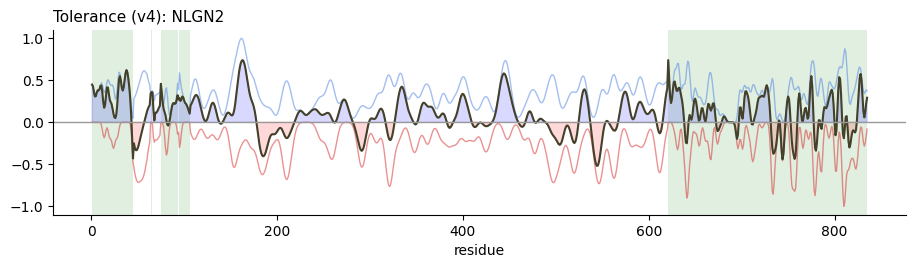

In [10]:
# Checks: track lengths, NLGN3 against the misc_figures plot
bad_len = [g for g, s, t in zip(psd_seq_df.gene, psd_seq_df.sequence, psd_seq_df.tolerance_v4) if len(t) != len(s)]
print("track length != sequence length:", bad_len)

from tracks import lollipops_on_axis

def plot_tolerance(gene, name="v4", variants=None, ax=None):
    """Normalised gnomAD density (up), ClinVar density (down), their difference, disorder shading."""
    from tolerance import normalize
    row = psd_seq_df.set_index("gene").loc[gene]
    tol, gn, cv = (np.asarray(row[f"{c}_{name}"]) for c in ("tolerance", "gnomad_y", "clinvar_y"))
    x = np.arange(1, len(tol) + 1)
    ax = ax or plt.subplots(figsize=(11, 2.4))[1]
    ax.plot(x, normalize(gn), color="#4a7fe0", lw=1, alpha=0.5, label="gnomAD")
    ax.plot(x, -normalize(cv), color="#d62728", lw=1, alpha=0.5, label="ClinVar")
    ax.plot(x, tol, color="#43412a", lw=1.5, label="tolerance")
    ax.fill_between(x, tol, 0, where=tol > 0, color="b", alpha=.15, interpolate=True)
    ax.fill_between(x, tol, 0, where=tol < 0, color="r", alpha=.15, interpolate=True)
    ax.fill_between(x, 0, 1, where=np.asarray(row.disorder_scores) >= 0.5, transform=ax.get_xaxis_transform(),
                    color="green", alpha=.12, lw=0, step="mid", zorder=-1)
    if variants is not None:
        v = variants[variants.gene == gene]
        lollipops_on_axis(ax, v.loc[v.database == "GnomAD", "protein_consequence"].tolist(), up=True,
                          head_color="#4a7fe0", height=0.12, stem_lw=0.6, head_size=8)
        lollipops_on_axis(ax, v.loc[v.database == "ClinVar", "protein_consequence"].tolist(), up=False,
                          head_color="#d62728", height=0.12, stem_lw=0.6, head_size=8)
    ax.axhline(0, color="0.6", lw=1)
    ax.set_title(f"Tolerance ({name}): {gene}", loc="left", fontsize=11)
    ax.set_xlabel("residue"); ax.spines[["top", "right"]].set_visible(False)
    return ax

plot_tolerance("NLGN2")
plt.show()

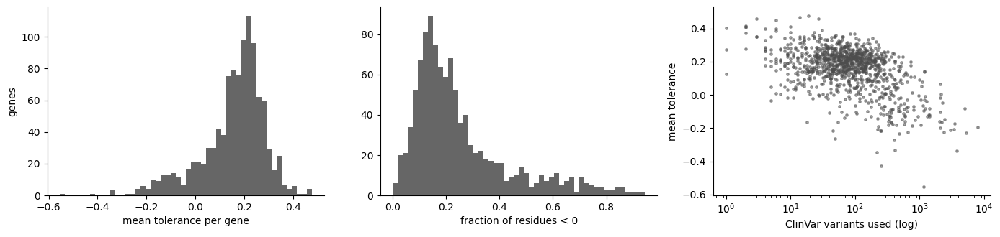

       mean_tolerance  frac_intolerant
count        1070.000         1070.000
mean            0.155            0.255
std             0.131            0.186
min            -0.554            0.001
25%             0.098            0.130
50%             0.183            0.197
75%             0.238            0.313
max             0.476            0.944


In [11]:
# Distribution across genes
summary = pd.DataFrame({
    "gene": psd_seq_df.gene,
    "mean_tolerance": [np.mean(t) for t in psd_seq_df.tolerance_v4],
    "frac_intolerant": [np.mean(np.asarray(t) < 0) for t in psd_seq_df.tolerance_v4],
    "n_clinvar_used": psd_seq_df.n_clinvar_used,
    "tolerance_ok": psd_seq_df.tolerance_ok,
})
ok = summary[summary.tolerance_ok]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].hist(ok.mean_tolerance, bins=50, color="0.4")
axes[0].set_xlabel("mean tolerance per gene"); axes[0].set_ylabel("genes")
axes[1].hist(ok.frac_intolerant, bins=50, color="0.4")
axes[1].set_xlabel("fraction of residues < 0")
axes[2].scatter(ok.n_clinvar_used, ok.mean_tolerance, s=6, alpha=0.5, color="0.3")
axes[2].set_xscale("log"); axes[2].set_xlabel("ClinVar variants used (log)"); axes[2].set_ylabel("mean tolerance")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()
print(ok[["mean_tolerance", "frac_intolerant"]].describe().round(3))

**Decision: what the per-gene scaling does to the target**

The scatter above shows that mean tolerance falls as ClinVar coverage rises. Spearman ρ = −0.40 against the ClinVar count and −0.55 against ClinVar variants per residue. Heavily studied genes look "intolerant" partly *because* they're heavily studied. `normalize()` rescales each gene to [0, 1] on its own, so a gene with a handful of ClinVar hits gets a spiky ClinVar track that is near 0 almost everywhere, and its tolerance sits mostly above 0.

Options before training:
1. Keep it as is, so the model also learns gene-level ascertainment.
2. **Centre each gene**, `tolerance − median(tolerance)`, so that the target only says which regions of a protein are more or less tolerant than the rest of that protein. This is the same idea as `norm(y) - median(norm(y))` in the ESM notebook.
3. Weight genes in the loss by how well-informed their track is, e.g. by `n_clinvar_used`.


In [12]:
# Save
TOL_COLS = ["gene", "transcript_id", "sequence", "disorder_scores", "tolerance_v4", "gnomad_y_v4", "clinvar_y_v4",
            "n_gnomad_used", "n_clinvar_used", "tolerance_ok"]
psd_seq_df[TOL_COLS].to_parquet(os.path.join(OUT, "tolerance_v4.parquet"))
print("saved", os.path.join(OUT, "tolerance_v4.parquet"))

saved /Users/awlehr/LehrPDI/figures/results/tolerance_model/tolerance_v4.parquet


---
## 4. ESM scores

**Goal:** a zero-shot ESM baseline that the tolerance score (and later the fine-tuned model) can be compared against.

**Steps**
1. Load the ESM model. Your previous notebook used ESM-1v (`esm1v_t33_650M_UR90S_1`). Keep the model choice in one variable (`ESM_NAME`), because §12 needs to agree with it.
2. Reuse `gene_log_probs(sequence)` from the ESM notebook. It returns `(L, vocab)` log-probs in one forward pass, tiled with overlap for proteins longer than 1022.
3. Cache per gene to `psd_esm_scores.npz`. If the file exists and has the gene, load instead of recomputing.
4. Derive **per-residue** summaries (one value per position, same shape as the tolerance track):
   - `esm_wt_lp`: log-prob of the wild-type residue (low means ESM is "surprised" by it)
   - `esm_entropy`: entropy over the 20 amino acids (low means constrained)
   - `esm_mean_llr`: mean of `lp[alt] − lp[wt]` over the 19 alternates (more negative means less tolerant)
5. Derive **per-variant** scores: `lp[pos-1, alt] − lp[pos-1, ref]` for every row of `missense_df`. This is the `scores_df` you built before.

**Checks**
- [ ] Restrict to the 20 standard AA tokens before computing entropy or mean LLR. The vocab also contains special tokens such as `<cls>`, `<mask>`, `X`, `B`.
- [ ] Spot-check one variant against `score_variant()` (the masked-marginal version). The two should be close but not identical: wild-type marginal vs. masked marginal.
- [ ] For a long protein (>1022 aa, e.g. SHANK3), confirm there's no visible discontinuity at tile boundaries.

In [13]:
# ESM model + log-prob function
import esm

ESM_NAME  = "esm1v_t33_650M_UR90S_1"         # §11 and §12 must use the same model / alphabet
ESM_CACHE = os.path.join(MODEL_DIR, "psd_esm_scores.npz")   # {gene: (L, 33) log-probs}, built with ESM_NAME
WINDOW, OVERLAP = 1022, 200                  # ESM's max length; tiles overlap for longer proteins

_esm = {}                                    # model is loaded on first use only (~2.6 GB)

def load_esm():
    if not _esm:
        model, alphabet = getattr(esm.pretrained, ESM_NAME)()
        _esm.update(model=model.eval().to(device), alphabet=alphabet,
                    batch_converter=alphabet.get_batch_converter())
    return _esm["model"], _esm["alphabet"], _esm["batch_converter"]

def tile_starts(L, window=WINDOW, overlap=OVERLAP):
    return [0] if L <= window else list(range(0, L - window, window - overlap)) + [L - window]

@torch.no_grad()
def gene_log_probs(sequence, window=WINDOW, overlap=OVERLAP):
    """Log-probs at every residue in one pass (wild-type marginals); tiles proteins longer than
    `window`, keeping each residue from the window where it is most central.
    Returns (L, vocab), 0-based by residue (<cls> offset already removed)."""
    model, alphabet, batch_converter = load_esm()
    L = len(sequence)
    full_lp, best_dist = None, torch.full((L,), -1)
    for start in tile_starts(L, window, overlap):
        end = min(start + window, L)
        _, _, tokens = batch_converter([("wt", sequence[start:end])])
        logits = model(tokens.to(device))["logits"]
        lp = torch.log_softmax(logits[0], dim=-1).cpu()[1:end - start + 1]   # drop <cls>/<eos>
        if full_lp is None:
            full_lp = torch.empty(L, lp.shape[-1])
        local  = torch.arange(end - start)
        dist   = torch.minimum(local, (end - start - 1) - local)             # context on thinner side
        absidx = start + local
        take = dist > best_dist[absidx]                                      # most-central window wins
        full_lp[absidx[take]]   = lp[local[take]]
        best_dist[absidx[take]] = dist[take]
    return full_lp.numpy().astype(np.float32)

@torch.no_grad()
def masked_llr(sequence, pos, ref, alt, window=WINDOW):
    """Masked-marginal score for one variant (pos 1-based) -- the slower, 'proper' ESM-1v score,
    used only to spot-check the wild-type-marginal shortcut."""
    model, alphabet, batch_converter = load_esm()
    half = window // 2
    start = max(0, min(pos - 1 - half, len(sequence) - window))
    seq, p = sequence[start:start + window], pos - start
    assert seq[p - 1] == ref, f"expected {ref} at {pos}, got {seq[p - 1]}"
    _, _, tokens = batch_converter([("wt", seq)])
    tokens[0, p] = alphabet.mask_idx
    lp = torch.log_softmax(model(tokens.to(device))["logits"][0, p], dim=-1)
    return (lp[alphabet.get_idx(alt)] - lp[alphabet.get_idx(ref)]).item()

In [14]:
# load the cache, compute only what's missing
esm_lp = dict(np.load(ESM_CACHE)) if os.path.exists(ESM_CACHE) else {}
todo = [g for g, s in zip(psd_seq_df.gene, psd_seq_df.sequence)
        if g not in esm_lp or esm_lp[g].shape[0] != len(s)]
print(f"{len(esm_lp)} genes cached, {len(todo)} to compute")
for g, s in zip(psd_seq_df.gene, psd_seq_df.sequence):
    if g in todo:
        esm_lp[g] = gene_log_probs(s)
        print(f"  {g} ({len(s)} aa)")
if todo:
    np.savez_compressed(ESM_CACHE, **esm_lp)

1082 genes cached, 0 to compute


### ESM scores at a glance

For every residue, ESM gives a probability for each of the 20 amino acids (log-probabilities `lp`, read with the real sequence visible). Each score below summarises those numbers differently. **LLR** (log-likelihood ratio) = `lp[substituted residue] − lp[wild-type residue]`; more negative = ESM finds the substitution less plausible (more deleterious).

| Score | Level | Built from | Formula | Deleterious / constrained when | Missing when |
|---|---|---|---|---|---|
| `esm_llr` | variant | that one substitution | `lp[alt] − lp[ref]` | more negative | — |
| `esm_wt_lp` | residue | the wild-type residue only | `lp[wt]` | closer to 0 (ESM is sure of the wt residue) | — |
| `esm_entropy` | residue | all 20 amino acids | `−Σ p·log p` (0 = only one fits, 3.0 = any fits) | lower | — |
| `esm_mean_llr` | residue | all 19 possible substitutions | mean of `lp[alt] − lp[wt]` | more negative | — |
| `esm_mean_llr_smooth` (§6 only) | residue | `esm_mean_llr` of nearby residues | binomial smoothing, w = 31 ordered / 5 disordered | more negative | — |
| `esm_obs_min_llr` | residue | substitutions **observed** in the variant data at this residue | min of their `esm_llr` (the worst one seen) | more negative | no observed variant |
| `esm_obs_mean_llr` | residue | substitutions **observed** at this residue | mean of their `esm_llr` | more negative | no observed variant |
| `esm_obs_n` | residue | substitutions observed at this residue | count | — | 0 if none |

**`esm_mean_llr` vs. `esm_obs_*`:** `esm_mean_llr` asks how bad a *random* substitution at this residue would be. The `esm_obs_*` scores ask how bad the substitutions *actually seen* here are. Observed substitutions are filtered by selection (especially gnomAD's), so they should look milder than the all-19 average.

**Leakage note:** the `esm_obs_*` scores use the variant data, like the tolerance track. Compare them with tolerance or evaluate them only after rebuilding from training variants (`observed_esm(train_variants)`, as in §6g); otherwise a variant scores itself.

In [15]:
# per-residue summaries
AA20 = list("ACDEFGHIKLMNPQRSTVWY")
ALPHABET = esm.data.Alphabet.from_architecture("ESM-1b")   # ESM-1v's tokenizer, no weights needed
AA20_IDX = [ALPHABET.get_idx(a) for a in AA20]
AA20_POS = {a: i for i, a in enumerate(AA20)}

def esm_residue_scores(lp, sequence):
    """(L, vocab) log-probs -> per-residue wt log-prob, entropy and mean LLR over the 19 alternates.
    Restricted to the 20 standard amino acids and renormalised, so special tokens carry no mass."""
    lp20 = lp[:, AA20_IDX]
    lp20 = lp20 - np.logaddexp.reduce(lp20, axis=1, keepdims=True)          # renormalise over 20 AAs
    wt = lp20[np.arange(len(sequence)), [AA20_POS[a] for a in sequence]]
    entropy = -(np.exp(lp20) * lp20).sum(axis=1)
    mean_llr = (lp20.sum(axis=1) - wt) / 19 - wt                              # mean of lp[alt] - lp[wt]
    return wt, entropy, mean_llr

scores = [esm_residue_scores(esm_lp[g], s) for g, s in zip(psd_seq_df.gene, psd_seq_df.sequence)]
psd_seq_df["esm_wt_lp"], psd_seq_df["esm_entropy"], psd_seq_df["esm_mean_llr"] = map(list, zip(*scores))

In [16]:
# per-variant LLR
# lp[alt] - lp[ref] at the variant's residue; renormalising over 20 AAs cancels in the difference
missense_df["esm_llr"] = np.nan
pos_all = missense_df.position.to_numpy() - 1
for gene, idx in missense_df.groupby("gene").indices.items():
    lp = esm_lp[gene]
    ref = [ALPHABET.get_idx(a) for a in missense_df.reference.to_numpy()[idx]]
    alt = [ALPHABET.get_idx(a) for a in missense_df.alternate.to_numpy()[idx]]
    p = pos_all[idx]
    missense_df.iloc[idx, missense_df.columns.get_loc("esm_llr")] = lp[p, alt] - lp[p, ref]
print(f"esm_llr: {missense_df.esm_llr.notna().sum():,} of {len(missense_df):,} variants scored")

esm_llr: 1,288,072 of 1,288,072 variants scored


In [17]:
# per-residue ESM over the substitutions actually observed at each residue
OBS_VARIANTS = tolerance_variants          # same variants as the tolerance track (gnomAD AC >= 2 + ClinVar)

def observed_esm(variants, seq_df=psd_seq_df):
    '''Per-residue min / mean ESM LLR over the substitutions observed at each residue, plus their count.
    A substitution in both ClinVar and gnomAD is counted once. Residues with none observed get NaN (n = 0).
    Returns a dict of per-gene arrays, aligned with seq_df.'''
    subs = variants[["gene", "position", "reference", "alternate"]].drop_duplicates()   # one row per substitution
    by_gene = dict(tuple(subs.groupby("gene")))
    out = {"esm_obs_min_llr": [], "esm_obs_mean_llr": [], "esm_obs_n": []}
    for gene, seq in zip(seq_df.gene, seq_df.sequence):
        lo, mean, n = np.full(len(seq), np.nan), np.full(len(seq), np.nan), np.zeros(len(seq), int)
        s = by_gene.get(gene)
        if s is not None:
            p = s.position.to_numpy() - 1                                   # 0-based residue index
            ref = [ALPHABET.get_idx(a) for a in s.reference]
            alt = [ALPHABET.get_idx(a) for a in s.alternate]
            llr = pd.Series(esm_lp[gene][p, alt] - esm_lp[gene][p, ref], index=p)
            agg = llr.groupby(level=0).agg(["min", "mean", "size"])          # per residue
            lo[agg.index], mean[agg.index], n[agg.index] = agg["min"], agg["mean"], agg["size"]
        out["esm_obs_min_llr"].append(lo); out["esm_obs_mean_llr"].append(mean); out["esm_obs_n"].append(n)
    return out

for col, arrays in observed_esm(OBS_VARIANTS).items():
    psd_seq_df[col] = arrays

# coverage and a sanity check: observed substitutions should look milder than a random one
n_all = np.concatenate(psd_seq_df.esm_obs_n.to_list())
obs_mean = np.concatenate(psd_seq_df.esm_obs_mean_llr.to_list())
all_mean = np.concatenate(psd_seq_df.esm_mean_llr.to_list())
has = n_all > 0
print(f"residues with >= 1 observed substitution: {has.mean():.0%} "
      f"(median {np.median(n_all[has]):.0f} substitutions where present)")
print(f"median LLR, observed substitutions: {np.median(obs_mean[has]):.2f} | "
      f"all 19 possible at the same residues: {np.median(all_mean[has]):.2f}")

residues with >= 1 observed substitution: 47% (median 1 substitutions where present)
median LLR, observed substitutions: -4.76 | all 19 possible at the same residues: -5.56


lengths match: True | entropy range 0.00-2.94 (max possible 3.00)


/Users/awlehr/miniconda3/envs/LehrPDI/lib/python3.10/site-packages/esm/pretrained.py:215: UserWarning: Regression weights not found, predicting contacts will not produce correct results.
  warnings.warn(


   gene protein_consequence  esm_llr  esm_llr_masked
   FLNA            p.A1481T    -4.68           -1.75
   MYO6             p.I579F    -9.82           -6.20
   RELN            p.Y3435H    -2.99            0.30
  AKAP9              p.E11G    -9.00           -5.55
 PABPC1             p.G123C   -15.85          -13.25
CACNA1H             p.M923V    -2.94            0.77
    APC             p.Q394L    -3.69           -0.35
    ALK            p.P1543T    -3.87           -0.36
Spearman: 1.0


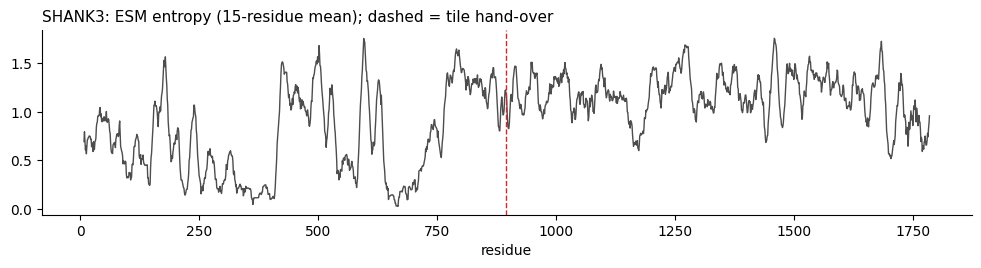

In [18]:
# checks
# 1. the summaries are well-formed
lens_ok = all(len(w) == len(s) for w, s in zip(psd_seq_df.esm_wt_lp, psd_seq_df.sequence))
ent = np.concatenate(psd_seq_df.esm_entropy.to_list())
print("lengths match:", lens_ok, f"| entropy range {ent.min():.2f}-{ent.max():.2f} (max possible {np.log(20):.2f})")

# 2. wild-type-marginal shortcut vs masked-marginal score on a few variants (loads the model)
check = missense_df[missense_df.database == "ClinVar"].sample(8, random_state=SEED)
seqs = dict(zip(psd_seq_df.gene, psd_seq_df.sequence))
check = check.assign(esm_llr_masked=[masked_llr(seqs[g], p, r, a) for g, p, r, a in
                                     zip(check.gene, check.position, check.reference, check.alternate)])
print(check[["gene", "protein_consequence", "esm_llr", "esm_llr_masked"]].round(2).to_string(index=False))
print("Spearman:", round(check[["esm_llr", "esm_llr_masked"]].corr("spearman").iloc[0, 1], 2))

# 3. no jumps where the tiles of a long protein hand over
LONG = "SHANK3"
row = psd_seq_df.set_index("gene").loc[LONG]
L = len(row.sequence)
fig, ax = plt.subplots(figsize=(12, 2.4))
ax.plot(np.arange(1, L + 1), pd.Series(row.esm_entropy).rolling(15, center=True).mean(), color="0.3", lw=1)
starts = tile_starts(L)
for a, b in zip(starts[:-1], starts[1:]):                   # hand-over: middle of each overlap
    ax.axvline((b + a + WINDOW) / 2, color="#d62728", ls="--", lw=1)
ax.set_title(f"{LONG}: ESM entropy (15-residue mean); dashed = tile hand-over", loc="left", fontsize=11)
ax.set_xlabel("residue"); ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [19]:
# save
ESM_COLS = ["gene", "esm_wt_lp", "esm_entropy", "esm_mean_llr",
            "esm_obs_min_llr", "esm_obs_mean_llr", "esm_obs_n"]
psd_seq_df[ESM_COLS].to_parquet(os.path.join(OUT, "esm_residue_scores.parquet"))
missense_df[["id", "gene", "position", "reference", "alternate", "database", "esm_llr"]].to_parquet(
    os.path.join(OUT, "esm_variant_llr.parquet"))
print("saved esm_residue_scores.parquet, esm_variant_llr.parquet")

saved esm_residue_scores.parquet, esm_variant_llr.parquet


---
## 5. Master per-residue table

**Goal:** one tidy, long table that every later section reads from, so that each score is computed once and stored once.

**Layout:** one row per (gene, residue)

| gene | uniprot_id | pos | aa | disorder | tolerance_v4 | gnomad_y_v4 | clinvar_y_v4 | esm_wt_lp | esm_entropy | esm_mean_llr | rsa | rsa_source | plddt | split |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|

- `rsa`, `rsa_source`, `plddt` are filled in §7 (NaN until then).
- `split` is filled in §10.
- A separate **per-variant** table (`missense_df` + `esm_llr` + `tolerance_v4` looked up with `score_variants`) is useful for ClinVar pathogenic/benign comparisons.

**Steps**
1. Write `explode_tracks(seq_df, columns)`. It turns the array-per-gene columns into rows.
2. Merge the ESM summaries by `(gene, pos)`.
3. Save as `RESULTS/tolerance_model/residue_scores.parquet`.

**Checks**
- [ ] Row count equals `sum(len(seq))` over genes.
- [ ] `aa` column equals `sequence[pos-1]` (this catches off-by-one errors).

In [20]:
# gene -> UniProt accession
# Offline, from UniProt's idmapping file. Map by the exact MANE transcript first (gives the isoform
# that matches our sequence) -- but only if that entry is reviewed (Swiss-Prot): some MANE transcripts
# match an unreviewed TrEMBL entry, which AlphaFold / PDBe / InterPro don't index (e.g. SHANK3 ->
# A0A8I5KZC4). Otherwise fall back to the reviewed entry for the gene symbol; §7 aligns to MANE anyway.
IDMAP = os.path.join(FIGURES, "..", "HUMAN_9606_idmapping.dat")

def uniprot_lookup(path=IDMAP):
    trs_to_iso, gene_to_accs, entry_name = {}, {}, {}
    with open(path) as f:
        for line in f:
            acc, kind, val = line.rstrip("\n").split("\t")
            if kind == "Ensembl_TRS":
                trs_to_iso.setdefault(val.split(".")[0], acc)      # drop the transcript version
            elif kind == "Gene_Name":
                gene_to_accs.setdefault(val.upper(), []).append(acc)
            elif kind == "UniProtKB-ID":
                entry_name[acc] = val
    # TrEMBL entry names look like "<ACC>_HUMAN"; Swiss-Prot use a mnemonic (e.g. NLGN3_HUMAN)
    reviewed = lambda a: not entry_name.get(a, "").startswith(a + "_")
    gene_to_rev = {g: next((a for a in accs if reviewed(a)), None) for g, accs in gene_to_accs.items()}
    return trs_to_iso, gene_to_rev, reviewed

trs_to_iso, gene_to_rev, reviewed = uniprot_lookup()
iso_any = psd_seq_df.transcript_id.map(trs_to_iso)
iso = iso_any.where(iso_any.str.split("-").str[0].map(lambda a: isinstance(a, str) and reviewed(a)))
print(f"transcript matched a TrEMBL entry -> gene-name fallback: {(iso_any.notna() & iso.isna()).sum()} genes")
psd_seq_df["uniprot_isoform"] = iso                                      # e.g. O00161-1, or NaN
psd_seq_df["uniprot_id"] = iso.str.split("-").str[0].fillna(psd_seq_df.gene.str.upper().map(gene_to_rev))
psd_seq_df["uniprot_source"] = np.where(iso.notna(), "transcript",
                                        np.where(psd_seq_df.uniprot_id.notna(), "gene_name", "none"))
print(psd_seq_df.uniprot_source.value_counts().to_dict())
print("no accession:", psd_seq_df.loc[psd_seq_df.uniprot_id.isna(), "gene"].tolist())

transcript matched a TrEMBL entry -> gene-name fallback: 39 genes
{'transcript': 1043, 'gene_name': 39}
no accession: []


In [21]:
# explode the per-gene arrays into one row per residue
# median-centred tolerance (option 2 from the §3 decision) is added alongside, so §6 can compare both
psd_seq_df["tolerance_v4_centered"] = [np.asarray(t) - np.median(t) for t in psd_seq_df.tolerance_v4]

TRACKS = {                                # master-table column <- psd_seq_df array column
    "disorder": "disorder_scores", "binding": "binding_scores",
    "tolerance_v4": "tolerance_v4", "tolerance_v4_centered": "tolerance_v4_centered",
    "gnomad_y_v4": "gnomad_y_v4", "clinvar_y_v4": "clinvar_y_v4",
    "esm_wt_lp": "esm_wt_lp", "esm_entropy": "esm_entropy", "esm_mean_llr": "esm_mean_llr",
    "esm_obs_min_llr": "esm_obs_min_llr", "esm_obs_mean_llr": "esm_obs_mean_llr",
    "esm_obs_n": "esm_obs_n",            # NaN / 0 where no variant was observed
}
PER_GENE = ["uniprot_id", "tolerance_ok"]  # repeated on every residue of the gene

def explode_tracks(seq_df, tracks=TRACKS, per_gene=PER_GENE):
    lengths = seq_df.sequence.str.len().to_numpy()
    out = {"gene": np.repeat(seq_df.gene.to_numpy(), lengths)}
    for col in per_gene:
        out[col] = np.repeat(seq_df[col].to_numpy(), lengths)
    out["pos"] = np.concatenate([np.arange(1, n + 1) for n in lengths])
    out["aa"] = np.array(list("".join(seq_df.sequence)))
    for name, col in tracks.items():
        out[name] = np.concatenate([np.asarray(a, dtype=np.float32) for a in seq_df[col]])
    return pd.DataFrame(out)

residue_df = explode_tracks(psd_seq_df)
residue_df["rsa"] = np.nan                # filled in §7
residue_df["rsa_source"] = pd.Series(pd.NA, index=residue_df.index, dtype="string")
residue_df["plddt"] = np.nan              # filled in §7
residue_df["split"] = pd.Series(pd.NA, index=residue_df.index, dtype="string")   # filled in §10
print(f"residue_df: {len(residue_df):,} residues x {residue_df.shape[1]} columns")
residue_df.head()

residue_df: 780,750 residues x 21 columns


,gene,uniprot_id,tolerance_ok,pos,aa,disorder,binding,tolerance_v4,tolerance_v4_centered,gnomad_y_v4,...,esm_wt_lp,esm_entropy,esm_mean_llr,esm_obs_min_llr,esm_obs_mean_llr,esm_obs_n,rsa,rsa_source,plddt,split
0,SNAP23,O00161,True,1,M,0.780117,0.792961,-0.000689,-0.196697,0.080375,...,-0.001660,0.016786,-9.708652,NaN,NaN,0.0,NaN,<NA>,NaN,<NA>
1,SNAP23,O00161,True,2,D,0.714087,0.623168,0.045285,-0.150723,0.094647,...,-0.737269,1.396719,-4.960403,-3.913183,-3.913183,1.0,NaN,<NA>,NaN,<NA>
2,SNAP23,O00161,True,3,N,0.712254,0.547053,0.085564,-0.110444,0.094556,...,-0.185692,0.888341,-5.175474,-3.605134,-3.605134,1.0,NaN,<NA>,NaN,<NA>
3,SNAP23,O00161,True,4,L,0.696932,0.503253,0.104695,-0.091313,0.079947,...,-0.074093,0.450285,-5.907872,-5.019074,-5.019074,1.0,NaN,<NA>,NaN,<NA>
4,SNAP23,O00161,True,5,S,0.651147,0.470096,0.127041,-0.068967,0.072668,...,-0.047311,0.262972,-7.516792,NaN,NaN,0.0,NaN,<NA>,NaN,<NA>


In [22]:
# per-variant table
# every variant with the residue-level scores at its position (one lookup, no recomputation)
variant_df = missense_df.merge(
    residue_df[["gene", "pos", "aa", "disorder", "tolerance_v4", "tolerance_v4_centered",
                "esm_entropy", "tolerance_ok"]],
    left_on=["gene", "position"], right_on=["gene", "pos"], how="left").drop(columns="pos")
print(f"variant_df: {len(variant_df):,} variants")

variant_df: 1,288,072 variants


In [23]:
# checks
expected = psd_seq_df.sequence.str.len().sum()
print("rows == total residues:", len(residue_df) == expected, f"({expected:,})")
print("unique (gene, pos):", not residue_df.duplicated(["gene", "pos"]).any())
# independent cross-check of the numbering: the master table's residue must equal each variant's reference
print("variant reference == residue aa:", (variant_df.aa == variant_df.reference).mean())
print("NaN per column:", residue_df.isna().sum()[lambda s: s > 0].to_dict())

rows == total residues: True (780,750)
unique (gene, pos): True
variant reference == residue aa: 1.0
NaN per column: {'esm_obs_min_llr': 413968, 'esm_obs_mean_llr': 413968, 'rsa': 780750, 'rsa_source': 780750, 'plddt': 780750, 'split': 780750}


In [24]:
# save
residue_df.to_parquet(os.path.join(OUT, "residue_scores.parquet"), index=False)
variant_df.to_parquet(os.path.join(OUT, "variant_scores.parquet"), index=False)
print("saved residue_scores.parquet, variant_scores.parquet")

saved residue_scores.parquet, variant_scores.parquet


---
## 6. Compare the scores

**Goal:** a table and figures that show how much tolerance, ESM, disorder, and (later) RSA agree, and *where* they disagree.

**Table**
- Spearman ρ between each pair of per-residue scores:
  - pooled across all residues
  - per gene, reported as median and IQR across genes
  - stratified by **ordered vs. disordered** residues. Expect ESM to be weakest in disordered regions, which is exactly where `convolve_v4` switches to Grantham with a short window.
- Variant level: AUROC of each score for ClinVar pathogenic vs. benign. Use the ClinVar significance labels if they're in `missense_df`.

**Figures**
1. Hexbin or 2D density of `tolerance_v4` vs. `esm_mean_llr`, faceted by ordered/disordered.
2. Per-gene correlation distribution (strip or violin plot).
3. Track plot for a few example genes, with stacked lines or heatmap rows for tolerance, ESM, disorder, and RSA. Reuse your imshow track code from the ESM notebook.
4. Correlation matrix heatmap of all scores.

**⚠ Statistical caution:** smoothed tracks are heavily autocorrelated, so neighbouring residues aren't independent and pooled p-values will be wildly over-confident. Report effect sizes (ρ). If you need significance, compare against your noise baseline from the ESM notebook (convolved random noise) or use a per-gene permutation with block shuffling.

**Checks**
- [ ] Each figure states *n* (genes, residues).
- [ ] The sign convention is consistent: decide whether higher means more tolerant for every score, and flip ESM if needed so that positive correlation means agreement.

### 6a. Put every score on the same footing

Before comparing, flip any score whose sign means the opposite, so that **higher = more tolerant** everywhere and a positive correlation always means agreement.

| score | raw meaning | flip? |
|---|---|---|
| `tolerance_v4`, `_centered` | > 0 = more gnomAD than ClinVar | no |
| `esm_mean_llr` | less negative = substitutions look harmless | no |
| `esm_entropy` | high = many residues fit here | no |
| `esm_wt_lp` | high = ESM is sure of the wild-type residue (constrained) | **yes**, renamed `esm_wt_surprise` |
| `esm_obs_min_llr` | worst ESM LLR among substitutions observed at the residue; less negative = milder | no |
| `esm_obs_mean_llr` | mean ESM LLR of the observed substitutions | no |
| `disorder` | high = disordered, usually more tolerant | no |

`tolerance_v4` is smoothed, but the ESM tracks are raw per-residue values. As a like-for-like control, `esm_mean_llr_smooth` applies convolve_v4's kernel (binomial; w = 31 if ordered, 5 if disordered; renormalised at the ends) to ESM too.

**The two `esm_obs_*` scores exist only at residues with at least one observed variant (≈ 47%), so every comparison involving them uses those residues only.** In 6a–6f they are built from *all* variants, which describes how the scores relate. In 6g they are rebuilt from the training variants only, so a held-out variant never scores itself.

In [25]:
# orient scores
SCORES = {                                   # column -> sign that makes "higher = more tolerant"
    "tolerance_v4": 1, "tolerance_v4_centered": 1,
    "esm_mean_llr": 1, "esm_entropy": 1, "esm_wt_lp": -1,
    "esm_obs_min_llr": 1, "esm_obs_mean_llr": 1,      # NaN where no variant was observed
    "disorder": 1,
}
RENAME = {"esm_wt_lp": "esm_wt_surprise"}   # flipped columns get a name that matches their new meaning

cmp_df = residue_df[residue_df.tolerance_ok].copy()          # drop the 12 genes with half-built tracks
for col, sign in SCORES.items():
    cmp_df[RENAME.get(col, col)] = sign * cmp_df[col]
cmp_df["region"] = np.where(cmp_df.disorder >= 0.5, "disordered", "ordered")   # same 0.5 cut as convolve_v4

# smoothing control: same kernel rule as convolve_v4, applied to a continuous track
from scipy.stats import binom
from scipy.ndimage import convolve1d

def smooth_like_v4(x, disorder, windows=(31, 5), threshold=0.5):
    """Binomial smoothing with w = windows[0] where disorder < threshold, windows[1] elsewhere;
    divides by the kernel area inside the protein, like convolve_v4's edge='renormalize'."""
    x = np.asarray(x, float)
    sm = {}
    for w in windows:
        k = binom.pmf(np.arange(2 * w + 1), 2 * w, 0.5)                   # kernel spans 2w+1 residues
        sm[w] = convolve1d(x, k, mode="constant") / convolve1d(np.ones_like(x), k, mode="constant")
    return np.where(np.asarray(disorder) < threshold, sm[windows[0]], sm[windows[1]])

cmp_df["esm_mean_llr_smooth"] = np.concatenate(                         # cmp_df is ordered by gene, pos
    [smooth_like_v4(g.esm_mean_llr, g.disorder) for _, g in cmp_df.groupby("gene", sort=False)])
SCORE_COLS = [RENAME.get(c, c) for c in SCORES] + ["esm_mean_llr_smooth"]

print(f"{cmp_df.gene.nunique()} genes, {len(cmp_df):,} residues "
      f"({(cmp_df.region == 'disordered').mean():.0%} disordered)")

1070 genes, 776,513 residues (36% disordered)


### 6b. Pooled correlations, split by ordered vs. disordered

Spearman ρ between the tolerance target and each ESM score, over all residues together, then within ordered and disordered residues separately. `convolve_v4` switches matrix and window at disorder = 0.5, and ESM is known to be weaker in disordered regions, so the split is where disagreement should show up.

*Report ρ (effect size), not p-values: smoothed tracks are strongly autocorrelated, so 780k residues are far fewer independent observations and any p-value would be meaningless.*

In [26]:
# pooled + stratified Spearman
from scipy.stats import spearmanr

TARGETS = ["tolerance_v4", "tolerance_v4_centered"]
ESM_COLS = ["esm_mean_llr", "esm_mean_llr_smooth", "esm_entropy", "esm_wt_surprise",
            "esm_obs_min_llr", "esm_obs_mean_llr"]

def rho(x, y):
    """Spearman rho over the residues where both scores exist (the esm_obs_* scores have gaps)."""
    ok = x.notna() & y.notna()
    return spearmanr(x[ok], y[ok]).statistic

rows = []
for t in TARGETS:
    for e in ESM_COLS + ["disorder"]:
        r = {"target": t, "score": e, "n_residues": int(cmp_df[e].notna().sum()),
             "rho_all": rho(cmp_df[t], cmp_df[e])}
        for region, sub in cmp_df.groupby("region"):
            r[f"rho_{region}"] = rho(sub[t], sub[e])                     # rho_ordered / rho_disordered
        rows.append(r)
pooled = pd.DataFrame(rows)
pooled.round(3)

,target,score,n_residues,rho_all,rho_disordered,rho_ordered
0,tolerance_v4,esm_mean_llr,776513,0.006,0.005,0.030
1,tolerance_v4,esm_mean_llr_smooth,776513,0.002,0.006,0.032
2,tolerance_v4,esm_entropy,776513,0.007,0.007,0.028
3,tolerance_v4,esm_wt_surprise,776513,0.012,0.009,0.032
4,tolerance_v4,esm_obs_min_llr,366349,-0.001,-0.024,0.021
5,tolerance_v4,esm_obs_mean_llr,366349,-0.013,-0.036,0.008
6,tolerance_v4,disorder,776513,0.000,0.075,0.037
7,tolerance_v4_centered,esm_mean_llr,776513,0.036,0.020,0.078
8,tolerance_v4_centered,esm_mean_llr_smooth,776513,0.036,0.023,0.085
9,tolerance_v4_centered,esm_entropy,776513,0.035,0.019,0.073


### 6c. Per-gene correlations against a shifted null

Pooled ρ mixes two things: whether *genes* differ in average tolerance, and whether the *regions within a gene* line up. Correlating within each gene isolates the second.

To know what ρ "by chance" looks like for two smooth tracks, use a **circular-shift null**: rotate the ESM track by a random offset (wrapping the end round to the start) and correlate again. That keeps each track's smoothness but breaks the residue-to-residue alignment, so smoothness alone can't produce a high ρ.

In [27]:
# per-gene rho, real vs shifted
rng = np.random.default_rng(SEED)

def per_gene_rho(df, a, b, shift=False, min_len=50):
    """Spearman rho of columns a and b within each gene, over residues where both exist.
    shift=True rotates b by a random offset (at least 10% of the length away) -> a null
    distribution with the same autocorrelation. Genes with < min_len usable residues are skipped."""
    out = {}
    for gene, g in df.groupby("gene", sort=False):
        x, y = g[a].to_numpy(float), g[b].to_numpy(float)
        if shift:
            k = int(len(y) * 0.1)
            y = np.roll(y, rng.integers(k, len(y) - k))               # rotate (gaps move with it)
        ok = np.isfinite(x) & np.isfinite(y)                           # drop residues missing either score
        x, y = x[ok], y[ok]
        if len(x) < min_len or np.ptp(x) == 0 or np.ptp(y) == 0:      # too few residues / flat track -> skip
            continue
        out[gene] = spearmanr(x, y).statistic
    return pd.Series(out, name=f"{a}~{b}")

TARGET = "tolerance_v4_centered"            # per-gene rho is the same for raw and centred (rank-based)
gene_rho = {e: per_gene_rho(cmp_df, TARGET, e) for e in ESM_COLS + ["disorder"]}
gene_rho_null = {e: per_gene_rho(cmp_df, TARGET, e, shift=True) for e in ESM_COLS + ["disorder"]}
print("genes with >= 50 usable residues:", {e: len(s) for e, s in gene_rho.items()})

genes with >= 50 usable residues: {'esm_mean_llr': 1070, 'esm_mean_llr_smooth': 1070, 'esm_entropy': 1070, 'esm_wt_surprise': 1070, 'esm_obs_min_llr': 1007, 'esm_obs_mean_llr': 1007, 'disorder': 1070}


### 6d. Summary table

One row per score: pooled ρ, ordered and disordered ρ, and the per-gene median (with IQR) next to its shifted-null median. A score only "agrees" with tolerance within genes if its per-gene median is clearly above the null.

In [28]:
# combine + save
q = lambda s, p: s.quantile(p)
summary = pooled[pooled.target == TARGET].set_index("score")[
    ["n_residues", "rho_all", "rho_ordered", "rho_disordered"]]
summary["n_genes"] = {e: len(s) for e, s in gene_rho.items()}
summary["gene_median"] = {e: s.median() for e, s in gene_rho.items()}
summary["gene_IQR"] = {e: f"{q(s, .25):.2f} to {q(s, .75):.2f}" for e, s in gene_rho.items()}
summary["null_median"] = {e: s.median() for e, s in gene_rho_null.items()}
summary["frac_genes_above_null_95th"] = {                  # share of genes beating 95% of the null
    e: (gene_rho[e] > gene_rho_null[e].quantile(0.95)).mean() for e in gene_rho}
summary.to_csv(os.path.join(OUT, "score_comparison.csv"))
summary.round(3)

,n_residues,rho_all,rho_ordered,rho_disordered,n_genes,gene_median,gene_IQR,null_median,frac_genes_above_null_95th
score,,,,,,,,,
esm_mean_llr,776513,0.036,0.078,0.020,1070,0.020,-0.07 to 0.13,0.005,0.156
esm_mean_llr_smooth,776513,0.036,0.085,0.023,1070,0.027,-0.09 to 0.17,-0.003,0.147
esm_entropy,776513,0.035,0.073,0.019,1070,0.020,-0.06 to 0.12,0.000,0.156
esm_wt_surprise,776513,0.036,0.072,0.019,1070,0.019,-0.05 to 0.11,0.006,0.152
esm_obs_min_llr,366349,0.019,0.058,-0.023,1007,-0.006,-0.10 to 0.09,-0.002,0.125
esm_obs_mean_llr,366349,0.016,0.051,-0.018,1007,-0.008,-0.10 to 0.09,0.002,0.133
disorder,776513,-0.017,0.053,0.057,1070,-0.044,-0.18 to 0.09,0.003,0.088


### 6e. Figures

1. **Correlation matrix**: every score against every other (pooled Spearman), on a diverging scale centred at 0.
2. **Density plots**: tolerance against ESM mean LLR (all 19 substitutions) and against the worst and the average *observed* substitution, each split into ordered and disordered residues.
3. **Per-gene ρ**: the real distribution for each score next to its shifted null.

The `esm_obs_*` scores use only residues with an observed variant, so their *n* is smaller. It's shown on each plot.

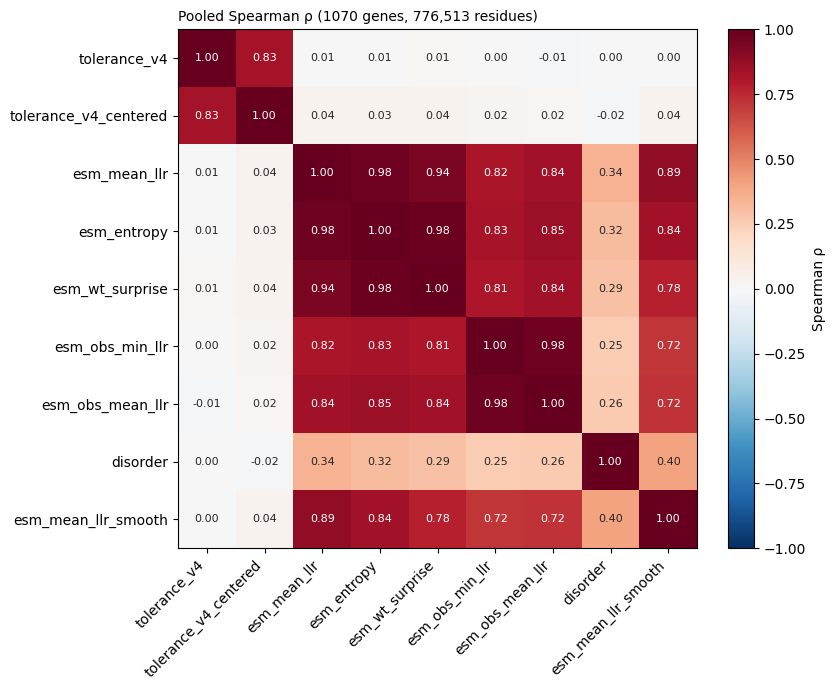

In [29]:
# correlation matrix
corr = cmp_df[SCORE_COLS].rank().corr()                    # Spearman = Pearson on ranks; pairwise,
                                                            # so esm_obs_* pairs use residues where both exist

fig, ax = plt.subplots(figsize=(8.4, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)        # diverging, white = 0
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):                                  # print rho in each cell
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "0.15")
fig.colorbar(im, ax=ax, label="Spearman ρ", fraction=0.046)
ax.set_title(f"Pooled Spearman ρ ({cmp_df.gene.nunique()} genes, {len(cmp_df):,} residues)",
             loc="left", fontsize=10)
fig.tight_layout(); plt.show()

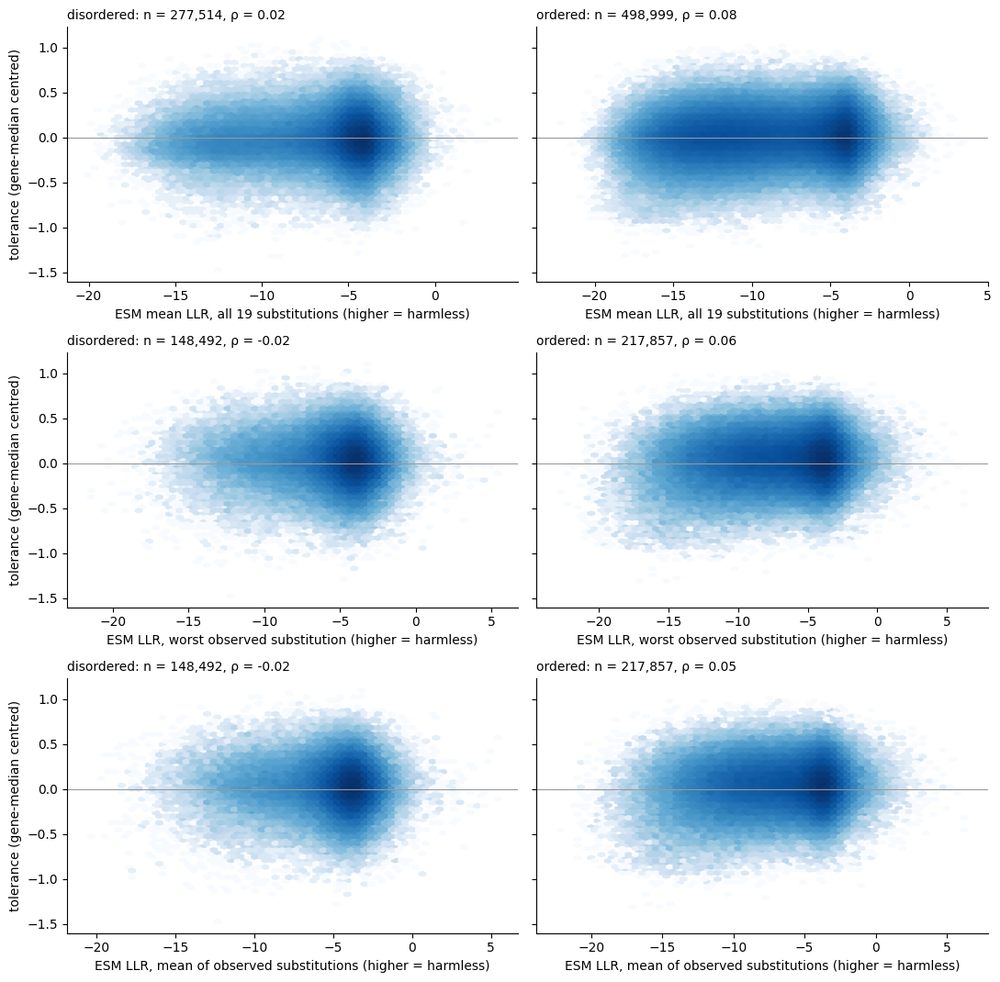

In [30]:
# density, ordered vs disordered -- one row per ESM score
XS = {"esm_mean_llr": "ESM mean LLR, all 19 substitutions",
      "esm_obs_min_llr": "ESM LLR, worst observed substitution",
      "esm_obs_mean_llr": "ESM LLR, mean of observed substitutions"}
Y = TARGET
fig, axes = plt.subplots(len(XS), 2, figsize=(11, 3.6 * len(XS)), sharey=True)
for row, (X, label) in zip(axes, XS.items()):
    for ax, (region, sub) in zip(row, cmp_df.groupby("region")):
        sub = sub[sub[X].notna()]                                   # obs scores: residues with a variant
        ax.hexbin(sub[X], sub[Y], gridsize=60, bins="log", cmap="Blues", mincnt=1)   # log counts
        ax.set_title(f"{region}: n = {len(sub):,}, ρ = {spearmanr(sub[X], sub[Y]).statistic:.2f}",
                     loc="left", fontsize=10)
        ax.set_xlabel(f"{label} (higher = harmless)")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    row[0].set_ylabel("tolerance (gene-median centred)")
fig.tight_layout(); plt.show()

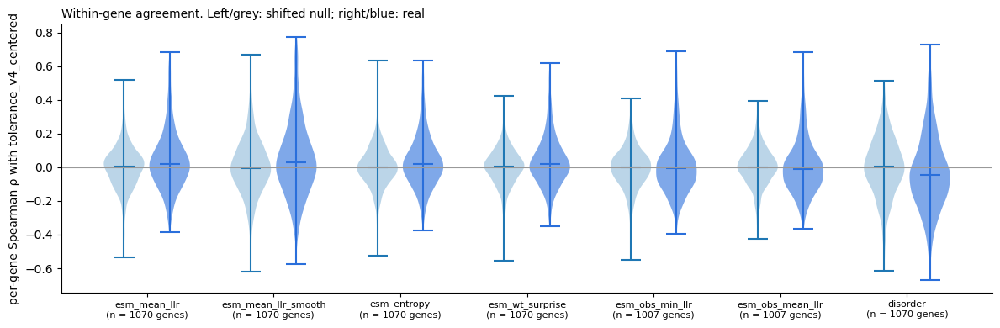

In [31]:
# per-gene rho vs null
names = list(gene_rho)
fig, ax = plt.subplots(figsize=(12, 4))
pos = np.arange(len(names))
ax.violinplot([gene_rho_null[n].dropna() for n in names], positions=pos - 0.18, widths=0.32,
              showmedians=True)                                    # null: left of each pair
real = ax.violinplot([gene_rho[n].dropna() for n in names], positions=pos + 0.18, widths=0.32,
                     showmedians=True)                             # real: right of each pair
for body in real["bodies"]:
    body.set_facecolor("#2a6fdb"); body.set_alpha(0.6)
for k in ("cmedians", "cbars", "cmins", "cmaxes"):
    real[k].set_color("#2a6fdb")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xticks(pos, [f"{n}\n(n = {len(gene_rho[n])} genes)" for n in names], fontsize=8)
ax.set_ylabel(f"per-gene Spearman ρ with {TARGET}")
ax.set_title("Within-gene agreement. Left/grey: shifted null; right/blue: real",
             loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 6f. Example genes as stacked tracks

Each row is one score, converted to its percentile within the gene and oriented so that dark = intolerant, which makes regions where the scores agree easy to spot by eye. Percentiles rather than min-max because raw ESM tracks are spiky: a few extreme residues would otherwise squash everything else into one colour. Light grey in the `esm_obs_*` rows = no observed variant at that residue. RSA joins these rows once §7 fills it.

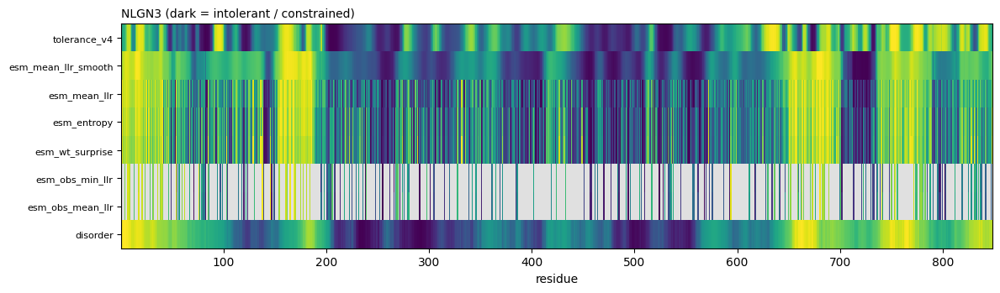

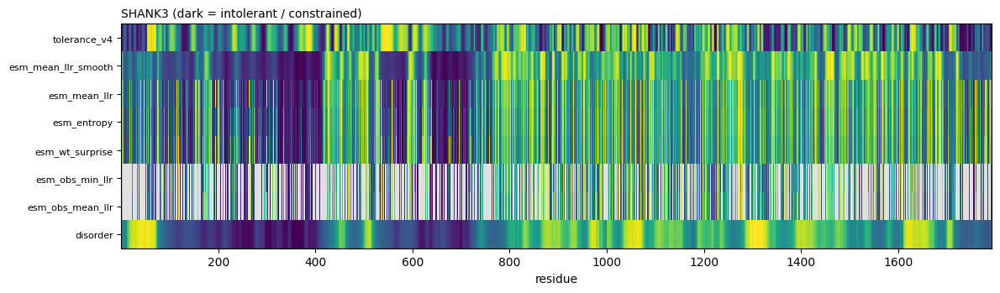

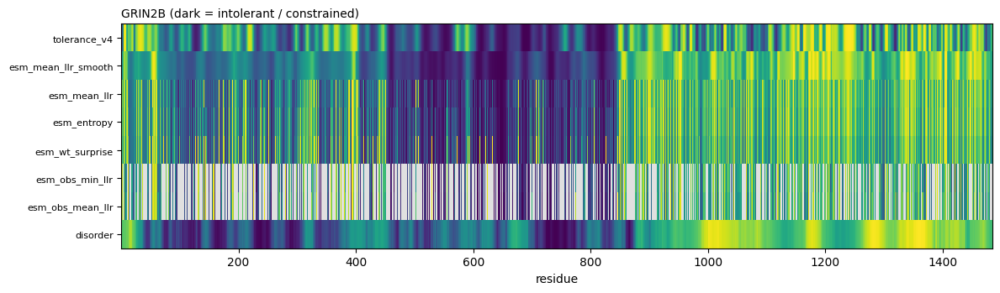

In [32]:
# track heatmaps
def plot_tracks(gene, cols=("tolerance_v4", "esm_mean_llr_smooth", "esm_mean_llr", "esm_entropy",
                            "esm_wt_surprise", "esm_obs_min_llr", "esm_obs_mean_llr", "disorder"),
                region=None, ax=None):
    """One heatmap row per score for one gene; region=(start, end) zooms to residues (1-based, inclusive)."""
    g = cmp_df[cmp_df.gene == gene]                                # percentiles use the whole gene ...
    mat = np.vstack([g[c].rank(pct=True).to_numpy() for c in cols])  # 0 = lowest residue, 1 = highest
    if region:                                                     # ... then zoom
        keep = ((g.pos >= region[0]) & (g.pos <= region[1])).to_numpy()
        mat, g = mat[:, keep], g[keep]
    ax = ax or plt.subplots(figsize=(12, 0.35 * len(cols) + 0.8))[1]
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("0.88")                                           # NaN (no observed variant) -> light grey
    ax.imshow(np.ma.masked_invalid(mat), aspect="auto", cmap=cmap, interpolation="nearest",
              extent=(g.pos.min() - 0.5, g.pos.max() + 0.5, len(cols) - 0.5, -0.5))
    ax.set_yticks(range(len(cols)), cols, fontsize=8)
    ax.set_title(f"{gene} (dark = intolerant / constrained)", loc="left", fontsize=10)
    ax.set_xlabel("residue")
    return ax

for gene in ["NLGN3", "SHANK3", "GRIN2B"]:
    plot_tracks(gene).figure.tight_layout(); plt.show()
# zoom example: plot_tracks("NLGN3", region=(600, 848))

### 6g. Held-out validation: do unseen gnomAD variants score higher than unseen ClinVar variants?

`tolerance_v4` is built from gnomAD **and** ClinVar variants, so any variant used to build it has pushed the track at its own position: gnomAD variants up, ClinVar variants down. Scoring those same variants would partly read back their own contribution. The fix is to hide some variants, rebuild, and score only the hidden ones:

1. **Hold out ~10% per gene.** Within each gene, randomly pick 10% of its gnomAD variants and 10% of its ClinVar variants.
2. **Hold out the variant, not the row.** 136k variants are in *both* databases (two rows, same genomic `id`). If only the ClinVar row were hidden, the gnomAD row would still feed the gnomAD track at that residue and lift the variant's own score. So every row with a held-out `id` is removed.
3. **Rebuild** the tracks from the remaining 90% (`tolerance_v4_train`).
4. **Score** each held-out variant by the rebuilt track at its residue. That value comes only from *other* variants nearby.
5. **Compare** held-out gnomAD against held-out ClinVar, and training against held-out. If the training variants separate much better than the held-out ones, the score is mostly echoing its inputs.

In [33]:
# choose the held-out variants
from tolerance import score_variants
from distributions import compare_train_val, plot_score_distribution

HOLDOUT_FRAC = 0.10

# one row per (gene, database, variant); a variant in both databases appears once under each
uniq = tolerance_variants[["gene", "database", "id"]].drop_duplicates()
held = uniq.groupby(["gene", "database"]).sample(frac=HOLDOUT_FRAC, random_state=SEED)  # 10% of each group
held_ids = set(held.id)

is_held = tolerance_variants.id.isin(held_ids)                  # drops BOTH rows of a held-out variant
train_variants = tolerance_variants[~is_held]
val_variants   = tolerance_variants[is_held]

# variants present in both databases can't be cleanly called "gnomAD" or "ClinVar"; flag them
in_both = set(uniq.id[uniq.id.duplicated()])
print(f"held out {len(held_ids):,} variants ({len(val_variants):,} rows); "
      f"{len(held_ids & in_both):,} of them are in both databases")
print(val_variants.groupby("database").size().to_dict(), "held-out rows by database")

held out 62,942 variants (83,194 rows); 20,252 of them are in both databases
{'ClinVar': 30367, 'GnomAD': 52827} held-out rows by database


In [34]:
# rebuild the tracks from the 90%
held_seq = build_tolerance_columns(psd_seq_df[["gene", "sequence", "disorder_scores"]], train_variants,
                                   name="v4_train", gnomad_min_count=0, verbose=False)   # ~20 s
held_seq["tolerance_v4_train_centered"] = [t - np.median(t) for t in held_seq.tolerance_v4_train]

In [35]:
# score training and held-out variants on the rebuilt track
ok_genes = set(psd_seq_df.gene[psd_seq_df.tolerance_ok])

# observed-substitution ESM scores from the 90% only, so a held-out variant never counts towards its own residue
# (for TRAINING rows these do include the variant itself; only held-out rows are evaluated with them)
obs_train = psd_seq_df[["gene"]].assign(**observed_esm(train_variants))

def score_all(df):
    """Look up the rebuilt tracks, residue disorder and observed-ESM scores at each variant; add the
    variant's own ESM LLR; keep usable genes."""
    df = df[df.gene.isin(ok_genes)]
    for col in ["tolerance_v4_train", "tolerance_v4_train_centered", "disorder_scores"]:
        df = score_variants(df, held_seq, col)
    for col in ["esm_obs_min_llr", "esm_obs_mean_llr"]:
        df = score_variants(df, obs_train, col)                      # NaN if nothing else seen at that residue
    df = df.merge(variant_df[["id", "database", "esm_llr"]], on=["id", "database"], how="left")
    df["in_both"] = df.id.isin(in_both)
    return df

train_scored, val_scored = score_all(train_variants), score_all(val_variants)
print(f"train: {len(train_scored):,} rows | held-out: {len(val_scored):,} rows | "
      f"held-out with an observed-ESM score: {val_scored.esm_obs_min_llr.notna().mean():.0%}")

# the scores compared in every held-out figure below: column, short title, x label
VAL_SCORES = [
    ("tolerance_v4_train", "Tolerance (rebuilt from 90%)", "tolerance (higher = more tolerant)"),
    ("esm_llr", "ESM LLR: this substitution", "ESM LLR (higher = looks harmless)"),
    ("esm_obs_min_llr", "ESM: worst observed at residue", "min observed ESM LLR"),
    ("esm_obs_mean_llr", "ESM: mean observed at residue", "mean observed ESM LLR"),
]

train: 556,004 rows | held-out: 83,136 rows | held-out with an observed-ESM score: 52%


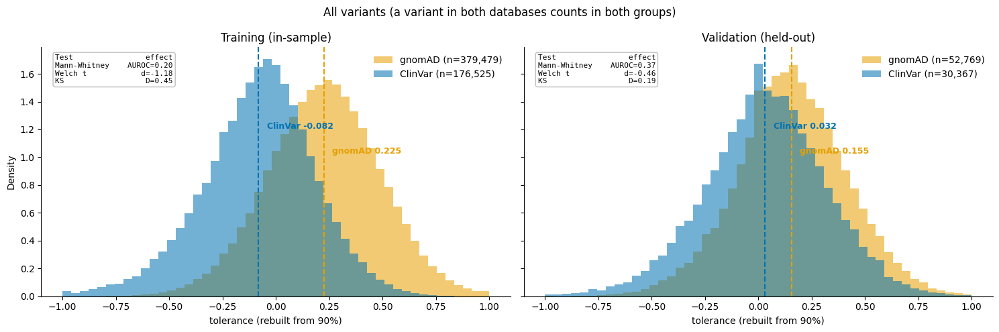

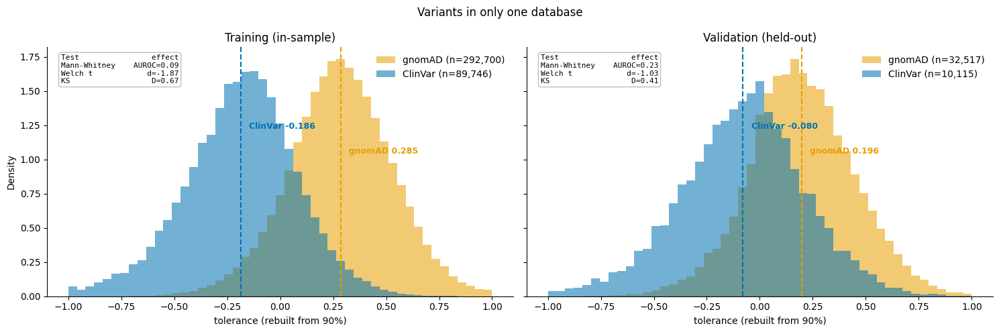

,auroc,cohend,clin_mean,gnom_mean,n_clin,n_gnom
Training (in-sample) (all),0.201,-1.179,-0.082,0.225,176525.0,379479.0
Validation (held-out) (all),0.374,-0.455,0.032,0.155,30367.0,52769.0
Training (in-sample) (one-db only),0.090,-1.870,-0.186,0.285,89746.0,292700.0
Validation (held-out) (one-db only),0.231,-1.027,-0.080,0.196,10115.0,32517.0


In [36]:
# gnomAD vs ClinVar, training vs held-out
# AUROC here = P(ClinVar score > gnomAD score): below 0.5 means ClinVar scores lower, as hoped
fig, stats = compare_train_val(train_scored, val_scored, "tolerance_v4_train",
                               xlabel="tolerance (rebuilt from 90%)",
                               suptitle="All variants (a variant in both databases counts in both groups)")
plt.show()

# same comparison without the variants that are in both databases -> cleaner labels
fig, stats_excl = compare_train_val(train_scored[~train_scored.in_both], val_scored[~val_scored.in_both],
                                    "tolerance_v4_train", xlabel="tolerance (rebuilt from 90%)",
                                    suptitle="Variants in only one database")
plt.show()

pd.DataFrame({f"{k} ({sub})": {m: v[m] for m in ("auroc", "cohend", "clin_mean", "gnom_mean", "n_clin", "n_gnom")}
              for sub, s in [("all", stats), ("one-db only", stats_excl)] for k, v in s.items()}).T.round(3)

**Tolerance vs. ESM: ClinVar and gnomAD side by side.** The same held-out variants (in only one database) scored four ways:
- tolerance rebuilt from the other 90%
- ESM LLR for the exact substitution
- `esm_obs_min_llr`: the worst ESM LLR among *other* substitutions observed at the same residue
- `esm_obs_mean_llr`: the mean of those

The two observed scores come from the **training** variants only, so a held-out variant never counts towards its own residue. They're missing when nothing else was seen at that residue, so all four panels use only the variants that have them. That makes the means directly comparable. The table also lists tolerance and ESM LLR on all held-out variants for reference.

In every panel, AUROC = P(ClinVar > gnomAD), so further below 0.5 means better separation.

20,659 of 42,632 held-out variants have another substitution at their residue


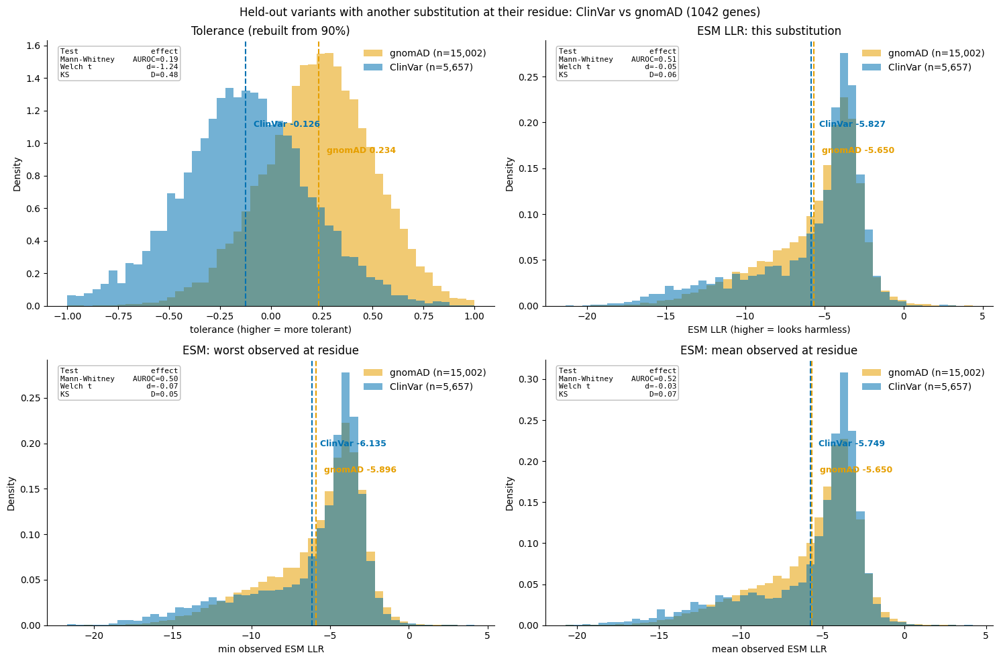

,auroc,cohend,ks_d,clin_mean,gnom_mean,n_clin,n_gnom
Tolerance (rebuilt from 90%),0.189,-1.238,0.485,-0.126,0.234,5657.0,15002.0
ESM LLR: this substitution,0.514,-0.052,0.062,-5.827,-5.650,5657.0,15002.0
ESM: worst observed at residue,0.502,-0.070,0.048,-6.135,-5.896,5657.0,15002.0
ESM: mean observed at residue,0.518,-0.030,0.071,-5.749,-5.650,5657.0,15002.0
Tolerance (rebuilt from 90%) [all held-out],0.231,-1.027,0.412,-0.080,0.196,10115.0,32517.0
ESM LLR: this substitution [all held-out],0.492,-0.111,0.057,-6.158,-5.774,10115.0,32517.0


In [37]:
# tolerance vs ESM on the same held-out variants
from distributions import separation_stats, split_scores

dist_df = val_scored[~val_scored.in_both]                       # one-database variants only: clean labels
common = dist_df[dist_df.esm_obs_min_llr.notna()]                # variants all four scores cover
print(f"{len(common):,} of {len(dist_df):,} held-out variants have another substitution at their residue")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
dist_stats = {title: plot_score_distribution(common, col, ax=ax, title=title, xlabel=xlabel)
              for (col, title, xlabel), ax in zip(VAL_SCORES, axes.flat)}
fig.suptitle(f"Held-out variants with another substitution at their residue: ClinVar vs gnomAD "
             f"({common.gene.nunique()} genes)")
fig.tight_layout(); plt.show()

for col, title, _ in VAL_SCORES[:2]:                             # reference: every held-out variant
    dist_stats[f"{title} [all held-out]"] = separation_stats(*split_scores(dist_df, col))
pd.DataFrame(dist_stats).T[["auroc", "cohend", "ks_d", "clin_mean", "gnom_mean", "n_clin", "n_gnom"]].round(3)

**Per gene.** A pooled result can be driven by a few large genes. Here each gene is checked on its own: is its held-out gnomAD median above its held-out ClinVar median? Only genes with ≥ 5 held-out variants of each kind are included, counted separately for each score, since the observed-ESM scores have gaps.

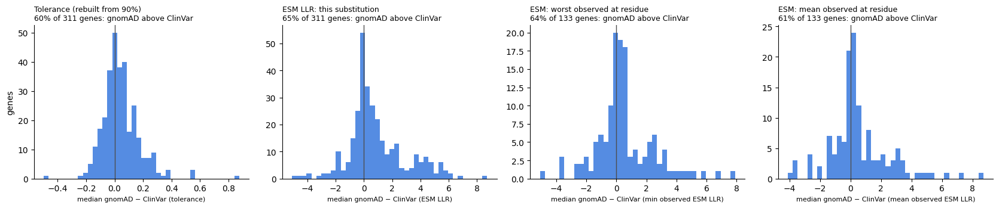

In [38]:
# per-gene check, one panel per score
MIN_PER_GROUP = 5
v = val_scored[~val_scored.in_both]

fig, axes = plt.subplots(1, len(VAL_SCORES), figsize=(4.2 * len(VAL_SCORES), 3.6))
gene_gaps = {}
for ax, (col, title, xlabel) in zip(axes, VAL_SCORES):
    vv = v[v[col].notna()]
    med = vv.groupby(["gene", "database"])[col].agg(["median", "size"]).unstack("database")
    med = med[(med["size"] >= MIN_PER_GROUP).all(axis=1)]                # enough of each kind
    gap = med["median"]["GnomAD"] - med["median"]["ClinVar"]
    gene_gaps[col] = gap
    ax.hist(gap, bins=40, color="#2a6fdb", alpha=0.8)
    ax.axvline(0, color="0.3", lw=1)
    ax.set_title(f"{title}\n{(gap > 0).mean():.0%} of {len(gap)} genes: gnomAD above ClinVar",
                 loc="left", fontsize=9)
    ax.set_xlabel(f"median gnomAD − ClinVar ({xlabel.split(' (')[0]})", fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("genes")
fig.tight_layout(); plt.show()
gene_gap = gene_gaps["tolerance_v4_train"]                              # kept for later cells

**By ClinVar classification.** Most ClinVar missense variants are VUS, so "ClinVar" in the test above mostly means "seen in a clinical test", not "pathogenic". Splitting the held-out ClinVar variants by label shows whether each score orders them sensibly: gnomAD > benign > VUS > pathogenic. Each variant is counted once. A variant in both databases is grouped by its ClinVar label, because dropping those would lose most benign variants: being common, they're usually in gnomAD too.

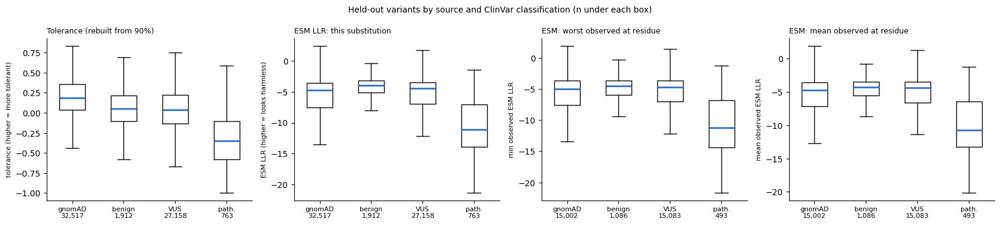

In [39]:
# held-out scores by group, one panel per score
# one row per held-out variant: its ClinVar row if it has one ('ClinVar' sorts before 'GnomAD'),
# so variants in both databases are grouped by their ClinVar label -- most benign variants are in gnomAD too
v = val_scored.sort_values("database").drop_duplicates("id").copy()
v["group"] = np.where(v.database == "GnomAD", "gnomAD only", "ClinVar " + v.clinsig_group.astype(str))
order = ["gnomAD only", "ClinVar benign", "ClinVar vus", "ClinVar pathogenic"]
short = {"gnomAD only": "gnomAD", "ClinVar benign": "benign", "ClinVar vus": "VUS", "ClinVar pathogenic": "path."}

fig, axes = plt.subplots(1, len(VAL_SCORES), figsize=(4.2 * len(VAL_SCORES), 3.8))
for ax, (col, title, xlabel) in zip(axes, VAL_SCORES):
    data = [v.loc[v.group == g, col].dropna() for g in order]           # obs scores: drop residues with none
    ax.boxplot(data, showfliers=False, widths=0.5, medianprops=dict(color="#2a6fdb", lw=2))
    ax.set_xticks(range(1, len(order) + 1), [f"{short[g]}\n{len(d):,}" for g, d in zip(order, data)], fontsize=8)
    ax.set_title(title, loc="left", fontsize=9)
    ax.set_ylabel(xlabel, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Held-out variants by source and ClinVar classification (n under each box)", fontsize=10)
fig.tight_layout(); plt.show()

**Pathogenic vs. benign (AUROC), against ESM and disorder.** Same held-out ClinVar variants, restricted to ≥ 1 review star. ESM never saw any labels, so it needs no hold-out and gives a fair comparison on the same variants. Here AUROC is oriented so that 1 = every benign variant scores above every pathogenic one.

The observed-ESM scores are missing for some variants, so the table gives each score's AUROC on every variant it covers, and all scores on the shared subset. The ROC curves use the shared subset.

645 pathogenic, 1832 benign, 492 genes
shared subset: 1,466 variants
                             AUROC (all it covers)       n  AUROC (shared subset)
esm_llr                                      0.881  2477.0                  0.875
tolerance_v4_train                           0.847  2477.0                  0.867
esm_obs_min_llr                              0.844  1466.0                  0.844
esm_obs_mean_llr                             0.843  1466.0                  0.843
tolerance_v4_train_centered                  0.791  2477.0                  0.823
disorder_scores                              0.766  2477.0                  0.782


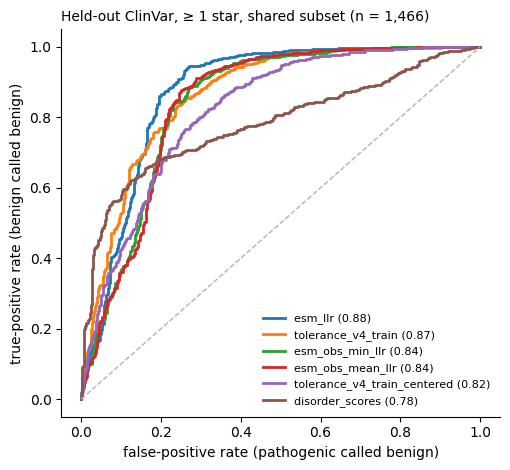

In [40]:
# AUROC + ROC curves
from sklearn.metrics import roc_auc_score, roc_curve

pb = val_scored[(val_scored.database == "ClinVar") & val_scored.clinsig_group.isin(["pathogenic", "benign"])
                & (val_scored.stars >= 1)]
print(f"{(pb.clinsig_group == 'pathogenic').sum()} pathogenic, {(pb.clinsig_group == 'benign').sum()} benign, "
      f"{pb.gene.nunique()} genes")

VARIANT_SCORES = {                         # column -> sign so that higher = more benign/tolerant
    "tolerance_v4_train": 1, "tolerance_v4_train_centered": 1, "esm_llr": 1,
    "esm_obs_min_llr": 1, "esm_obs_mean_llr": 1, "disorder_scores": 1,
}
shared = pb.dropna(subset=list(VARIANT_SCORES))                   # variants every score covers

def auroc(df, col):
    d = df[df[col].notna()]
    return roc_auc_score(d.clinsig_group == "benign", VARIANT_SCORES[col] * d[col]), len(d)   # positive = benign

auc_table = pd.DataFrame({c: {"AUROC (all it covers)": auroc(pb, c)[0], "n": auroc(pb, c)[1],
                              "AUROC (shared subset)": auroc(shared, c)[0]} for c in VARIANT_SCORES}).T
auc_table = auc_table.sort_values("AUROC (shared subset)", ascending=False)
auc_table.to_csv(os.path.join(OUT, "variant_auroc.csv"))
auc = auc_table["AUROC (all it covers)"]                           # kept for later cells
print(f"shared subset: {len(shared):,} variants")
print(auc_table.round(3).to_string())

y = (shared.clinsig_group == "benign").to_numpy()
fig, ax = plt.subplots(figsize=(5.2, 4.8))
for c in auc_table.index:                                          # legend in AUROC order
    fpr, tpr, _ = roc_curve(y, VARIANT_SCORES[c] * shared[c])
    ax.plot(fpr, tpr, lw=2, label=f"{c} ({auc_table.loc[c, 'AUROC (shared subset)']:.2f})")
ax.plot([0, 1], [0, 1], color="0.7", lw=1, ls="--")                # chance
ax.set_xlabel("false-positive rate (pathogenic called benign)")
ax.set_ylabel("true-positive rate (benign called benign)")
ax.set_title(f"Held-out ClinVar, ≥ 1 star, shared subset (n = {len(shared):,})", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 6h. What the first run showed (2026-10-20, `CLINVAR_GROUPS=None`, `GNOMAD_MIN_COUNT=2`, 10% hold-out)

- **Residue by residue, tolerance and ESM barely agree.** Pooled ρ ≈ 0.04, ordered 0.08, disordered 0.02, and within genes the median ρ is ≈ 0.02 against a null of ≈ 0.00. Smoothing ESM the same way changes almost nothing.
- **Held-out gnomAD vs. ClinVar** (variants in only one database): P(ClinVar > gnomAD) = 0.23, i.e. gnomAD is higher 77% of the time. In-sample it was 0.09, so about half of the apparent separation came from variants scoring their own contribution.
- **Within genes the separation is much weaker:** only 60% of 313 genes have held-out gnomAD above ClinVar (median gap 0.03). Much of the pooled separation is *between* genes, the ClinVar study-intensity effect from §3.
- **By classification** (held-out medians): gnomAD-only 0.19 > ClinVar benign 0.05 ≈ VUS 0.04 > pathogenic −0.37. Pathogenic variants are clearly separated, but benign and VUS look alike.
- **Pathogenic vs. benign AUROC** (held-out, ≥ 1 star, 653 vs 1,834): ESM LLR 0.87, tolerance 0.86, centred tolerance 0.81, **disorder alone 0.78**, the floor any trained model has to beat.
- **Observed-substitution ESM scores** (`esm_obs_min_llr` / `esm_obs_mean_llr`, at the ≈ 47% of residues with a variant): residue-level ρ with tolerance ≈ 0.02, no better than the all-19 ESM average. Held-out gnomAD vs. ClinVar: AUROC 0.50 / 0.52, no separation, like the variant's own ESM LLR. Pathogenic vs. benign: **0.84** for both. That's close to the variant's own ESM LLR (0.87 on all, 0.87 on the shared 1,477), even though they never see the variant itself: the residues where pathogenic variants sit also attract other damaging-looking substitutions.
- **For training:** the target carries information ESM doesn't, which is the reason to fine-tune. The weak within-gene separation is the part a model would most need to improve, and the gene-split test set (§10) is where to check it.


---
## 7. Structure: RSA and binding interfaces

**Goal:** for every residue, record how buried it is (RSA) and whether it contacts another molecule in an experimental structure. Both go into `residue_df` in **MANE numbering**.

**Why both:** RSA alone calls an interface residue "surface", because it's exposed when the chain is alone. But interface residues are often as intolerant as the core. Splitting surface into *interface* and *non-interface* is where the biology is.

**Outputs (new `residue_df` columns)**

| column | meaning |
|---|---|
| `rsa`, `rsa_class` | relative solvent accessibility of the chain alone; core < 0.20 ≤ boundary ≤ 0.40 < surface |
| `rsa_source` | `pdb:XXXX_A` or `alphafold` |
| `plddt` | AlphaFold confidence (NaN for PDB residues) |
| `iface_any`, `iface_homo`, `iface_hetero` | residue contacts another chain in any structure: any partner, a copy of itself, or a different protein |
| `iface_n_entries` | how many PDB entries show that contact (more = more confident) |
| `iface_partners` | partner UniProt accessions, e.g. `P58400;Q9NZ94` |
| `buried_sasa` | Å² buried by partners in the chosen structure (7d, Route B only) |

Steps 7a–7f each have a code cell below.

### 7a. Choose structures per gene

1. Ask PDBe for the ranked list of experimental structures per UniProt accession: `https://www.ebi.ac.uk/pdbe/graph-api/mappings/best_structures/{acc}`. It's sorted by coverage, then resolution, and gives the UniProt range each chain covers.
2. Keep human entries (`tax_id == 9606`). Optionally keep only resolution ≤ 3.5 Å.
3. Greedy cover: take the best structure, then add the next one that covers residues not yet covered, until nothing new is added.
4. Every residue no PDB chain covers falls back to AlphaFold (`structure.fetch_alphafold(acc)`).
5. Cache every response, like `interpro_cache/`.

**Check:** fraction of residues per gene covered by PDB vs. AlphaFold. Expect PDB coverage to be biased towards well-studied genes, the same bias as ClinVar.

In [41]:
# shared settings, cached downloads, and the PDB structures chosen per gene
import io, json, time, requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from Bio.PDB import PDBParser, MMCIFParser
from Bio.PDB.SASA import ShrakeRupley
from structure import MAX_ASA, _chain_residues           # Tien et al. 2013 max ASA; standard residues of a chain

PDBE = "https://www.ebi.ac.uk/pdbe/graph-api"
STRUCT_CACHE = os.path.join(OUT, "structure_cache")      # api/ pdb/ af/ genes/ -- delete a subfolder to refetch
for sub in ("api", "pdb", "af", "genes"):
    os.makedirs(os.path.join(STRUCT_CACHE, sub), exist_ok=True)

MAX_RESOLUTION   = None    # e.g. 3.5 (Å) to drop low-resolution entries; NLGN3's only structure (8GS3) is 3.9 Å
MAX_STRUCTURES   = 5       # PDB chains per gene
MIN_NEW_RESIDUES = 20      # a further chain must add at least this many uncovered residues
MIN_IDENTITY     = 0.90    # aligned structure residues identical to the MANE sequence, else reject
PLDDT_MIN        = 70      # AlphaFold residues below this get rsa = NaN (mostly disorder)
N_WORKERS        = 4       # genes processed in parallel (downloads overlap)
GENES_TO_RUN     = None    # e.g. ["NLGN3", "GRIN1"] to try a few genes first; None = all

def get_cached(url, path, as_json=True, tries=5):
    """GET `url` once and keep it at `path`; 404 is cached as empty and returns None.
    Retries on rate limiting / server errors with growing pauses."""
    if not os.path.exists(path):
        for attempt in range(tries):
            try:
                r = requests.get(url, timeout=120)
            except requests.RequestException:
                time.sleep(2 ** attempt); continue
            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(2 ** attempt * 2); continue
            break
        else:
            raise RuntimeError(f"gave up on {url}")
        if r.status_code not in (200, 404):
            raise RuntimeError(f"{r.status_code} for {url}")
        open(path, "w").write(r.text if r.status_code == 200 else "")
    text = open(path).read()
    if not text:
        return None
    return json.loads(text) if as_json else text

def choose_pdb_chains(acc):
    """PDBe's ranked chains for a UniProt accession (coverage, then resolution), greedily kept while
    each adds >= MIN_NEW_RESIDUES uncovered UniProt residues. Human entries only."""
    d = get_cached(f"{PDBE}/mappings/best_structures/{acc}", os.path.join(STRUCT_CACHE, "api", f"best_{acc}.json"))
    if not d:
        return []
    covered, chosen = set(), []
    for s in d[acc]:
        if s["tax_id"] != 9606:
            continue
        if MAX_RESOLUTION and (s["resolution"] is None or s["resolution"] > MAX_RESOLUTION):
            continue
        new = set(range(s["unp_start"], s["unp_end"] + 1)) - covered      # residues this chain would add
        if len(new) >= MIN_NEW_RESIDUES:
            chosen.append(s); covered |= new
        if len(chosen) == MAX_STRUCTURES:
            break
    return chosen

# which genes, and their accession / MANE sequence
genes = psd_seq_df if GENES_TO_RUN is None else psd_seq_df[psd_seq_df.gene.isin(GENES_TO_RUN)]
GENE_INFO = dict(zip(genes.gene, zip(genes.uniprot_id, genes.uniprot_isoform, genes.sequence)))

with ThreadPoolExecutor(N_WORKERS) as pool:                 # one API call per gene, cached
    chosen = dict(zip(GENE_INFO, pool.map(lambda g: choose_pdb_chains(GENE_INFO[g][0]), GENE_INFO)))
n_pdb = sum(bool(v) for v in chosen.values())
print(f"{n_pdb} of {len(chosen)} genes have a human PDB structure; "
      f"{sum(len(v) for v in chosen.values())} chains chosen")
pd.DataFrame([{"gene": g, "pdb": f"{s['pdb_id']}_{s['chain_id']}", "method": s["experimental_method"],
               "resolution": s["resolution"], "unp_range": f"{s['unp_start']}-{s['unp_end']}"}
              for g, v in chosen.items() for s in v]).head(10)

792 of 1082 genes have a human PDB structure; 1074 chains chosen


,gene,pdb,method,resolution,unp_range
0,SNAP23,3zus_A,X-ray diffraction,2.95,150-211
1,SNAP23,1nhl_A,X-ray diffraction,2.30,23-76
2,GRIP1,2jil_A,X-ray diffraction,1.50,148-239
3,FLNA,4m9p_A,X-ray diffraction,1.72,478-766
4,FLNA,2j3s_A,X-ray diffraction,2.50,2045-2329
5,FLNA,2wfn_A,X-ray diffraction,3.20,1-278
6,FLNA,2k7q_A,Solution NMR,NaN,1954-2141
7,FLNA,2k7p_A,Solution NMR,NaN,1772-1956
8,ADAM10,8esv_A,Electron Microscopy,3.30,214-748
9,CPEB3,2dnl_A,Solution NMR,NaN,440-540


### 7b. Map numbering: PDB → UniProt → MANE

- **PDB → UniProt:** `structure.sifts_chains` / `map_to_uniprot` (already used for the NLGNs). PDB residue numbers are author numbers, not UniProt.
- **UniProt → MANE:** at least 109 genes map to a UniProt isoform other than `-1` (§5), and AlphaFold models only the canonical isoform. Where the UniProt canonical sequence ≠ the MANE sequence, align them (`structure_pipeline.map_all_positions`) and transfer values. Residues in MANE but not in the canonical isoform get NaN.

**Check:** after mapping, the residue letter from the structure equals `residue_df.aa` at the same position (> 99% expected; mismatches flag engineered mutations or isoform errors).

In [42]:
# map any structure's sequence onto the MANE sequence by local alignment
from Bio.Align import PairwiseAligner, substitution_matrices

_aligner = PairwiseAligner()
_aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
_aligner.open_gap_score, _aligner.extend_gap_score = -10, -0.5
_aligner.mode = "local"                                    # structures often cover only part of the protein

def align_to_mane(seq, mane):
    """-> ({0-based index in seq: 1-based MANE position}, identity of the aligned residues).
    Works for PDB chains, AlphaFold models of any isoform, and UniProt canonical sequences alike."""
    if seq == mane:                                         # common case: no alignment needed
        return {i: i + 1 for i in range(len(seq))}, 1.0
    aln = _aligner.align(seq, mane)[0]
    mapping, same = {}, 0
    for (a0, a1), (b0, b1) in zip(*aln.aligned):           # aligned blocks, gaps skipped
        for k in range(a1 - a0):
            mapping[a0 + k] = b0 + k + 1
            same += seq[a0 + k] == mane[b0 + k]
    return mapping, same / max(len(mapping), 1)

# quick test: NLGN3 canonical vs its own MANE sequence
_g = "NLGN3" if "NLGN3" in GENE_INFO else next(iter(GENE_INFO))
_m, _id = align_to_mane(GENE_INFO[_g][2][10:200], GENE_INFO[_g][2])
print(f"{_g}: fragment 11-200 maps to MANE {min(_m.values())}-{max(_m.values())}, identity {_id:.2f}")

NLGN3: fragment 11-200 maps to MANE 11-200, identity 1.00


### 7c. RSA

- `structure.residue_accessibility(pdb_text=..., chain=...)`: Shrake–Rupley SASA ÷ maximum ASA (Tien et al. 2013), computed on **the chain alone**, so interfaces read as exposed here and are handled in 7d.
- AlphaFold residues with pLDDT < 70 → `rsa = NaN`. Low-confidence regions are mostly disordered and look fully exposed, which is meaningless.
- `rsa_class` from the same cut-offs as notebook 04 (core < 0.20, surface > 0.40).

**Check:** NLGN1 RSA should match `run_structure_pipeline()` from notebook 04.

In [43]:
# RSA per residue: PDB chains first, AlphaFold for the rest
def chain_rsa(text, fmt):
    """[(aa, rsa, bfactor), ...] for the first chain in `text`, computed on that chain alone
    (waters, ligands, glycans and hydrogens removed). bfactor = pLDDT for AlphaFold models."""
    parser = MMCIFParser(QUIET=True) if fmt == "cif" else PDBParser(QUIET=True)
    model = parser.get_structure("s", io.StringIO(text))[0]
    chain = next(iter(model))
    for ch in list(model)[1:]:
        model.detach_child(ch.id)                           # chain alone
    for res in list(chain):
        if res.id[0] != " ":
            chain.detach_child(res.id)                      # hetero groups occlude the surface
            continue
        for atom in list(res):
            if atom.element == "H":
                res.detach_child(atom.get_id())             # MAX_ASA assumes heavy atoms only
    ShrakeRupley().compute(model, level="R")
    out = []
    for _, aa, res in _chain_residues(chain):
        b = res["CA"].get_bfactor() if "CA" in res else np.nan
        out.append((aa, min(res.sasa / MAX_ASA[aa], 1.5), b))   # cap: terminal/odd residues can exceed 1
    return out

def pdb_rsa(acc, mane):
    """Per MANE position: rsa and source from the chosen PDB chains (best-ranked chain wins)."""
    rows = []
    for rank, s in enumerate(choose_pdb_chains(acc)):
        pdb, ch = s["pdb_id"], s["chain_id"]
        cif = get_cached(f"https://www.ebi.ac.uk/pdbe/model-server/v1/{pdb}/atoms?auth_asym_id={ch}&encoding=cif",
                         os.path.join(STRUCT_CACHE, "pdb", f"{pdb}_{ch}.cif"), as_json=False)   # this chain only
        if not cif:
            continue
        res = chain_rsa(cif, "cif")
        mapping, ident = align_to_mane("".join(r[0] for r in res), mane)
        if ident < MIN_IDENTITY or len(mapping) < MIN_NEW_RESIDUES:
            continue                                        # wrong isoform / paralog / too short
        rows += [{"pos": p, "rsa_pdb": res[i][1], "aa_pdb": res[i][0], "pdb_source": f"pdb:{pdb}_{ch}",
                  "rank": rank} for i, p in mapping.items()]
    if not rows:
        return pd.DataFrame(columns=["pos", "rsa_pdb", "aa_pdb", "pdb_source"])
    return (pd.DataFrame(rows).sort_values("rank").drop_duplicates("pos")   # best-ranked chain wins
            .drop(columns="rank"))

def af_rsa(acc, mane):
    """Per MANE position: rsa and pLDDT from the AlphaFold model (any isoform) that best matches MANE."""
    meta = get_cached(f"https://alphafold.ebi.ac.uk/api/prediction/{acc}",
                      os.path.join(STRUCT_CACHE, "api", f"af_{acc}.json"))
    if not meta:
        return pd.DataFrame(columns=["pos", "rsa_af", "plddt", "af_model"])
    exact = [e for e in meta if e["sequence"] == mane]
    def n_identical(e):                                     # residues the model covers identically
        m, ident = align_to_mane(e["sequence"], mane)
        return len(m) * ident
    best = exact[0] if exact else max(meta, key=n_identical)
    pdb_text = get_cached(best["pdbUrl"], os.path.join(STRUCT_CACHE, "af", f"{best['entryId']}.pdb"), as_json=False)
    res = chain_rsa(pdb_text, "pdb")
    mapping, _ = align_to_mane("".join(r[0] for r in res), mane)
    return pd.DataFrame([{"pos": p, "rsa_af": res[i][1], "plddt": res[i][2], "af_model": best["entryId"]}
                         for i, p in mapping.items()])

def structure_for_gene(gene):
    """One row per MANE residue: rsa, rsa_source, plddt (+ PDB / AlphaFold detail). Cached per gene."""
    path = os.path.join(STRUCT_CACHE, "genes", f"{gene}.parquet")
    if os.path.exists(path):
        return pd.read_parquet(path)
    acc, _, mane = GENE_INFO[gene]
    df = pd.DataFrame({"gene": gene, "pos": np.arange(1, len(mane) + 1)})
    df = df.merge(pdb_rsa(acc, mane), on="pos", how="left").merge(af_rsa(acc, mane), on="pos", how="left")
    df["rsa_af"] = df.rsa_af.where(df.plddt >= PLDDT_MIN)   # low-confidence AlphaFold -> no RSA
    df["rsa"] = df.rsa_pdb.fillna(df.rsa_af)                # PDB first, AlphaFold for the rest
    df["rsa_source"] = np.where(df.rsa_pdb.notna(), df.pdb_source,
                                np.where(df.rsa_af.notna(), "alphafold", None))
    df.to_parquet(path, index=False)
    return df

t0, errors, parts = time.time(), {}, []
with ThreadPoolExecutor(N_WORKERS) as pool:
    futures = {pool.submit(structure_for_gene, g): g for g in GENE_INFO}
    for n, f in enumerate(as_completed(futures), 1):
        try:
            parts.append(f.result())
        except Exception as e:                              # keep going; list failures at the end
            errors[futures[f]] = repr(e)[:150]
        if n % 50 == 0:
            print(f"{n}/{len(futures)} genes ({time.time() - t0:.0f} s)")
struct_df = pd.concat(parts, ignore_index=True)
print(f"done in {time.time() - t0:.0f} s; failed: {errors if errors else 'none'}")
print(struct_df.rsa_source.fillna("none").str.split(":").str[0].value_counts(normalize=True).round(3).to_dict())

50/1082 genes (0 s)
100/1082 genes (0 s)
150/1082 genes (0 s)
200/1082 genes (0 s)
250/1082 genes (0 s)
300/1082 genes (0 s)
350/1082 genes (0 s)
400/1082 genes (0 s)
450/1082 genes (0 s)
500/1082 genes (0 s)
550/1082 genes (0 s)
600/1082 genes (1 s)
650/1082 genes (1 s)
700/1082 genes (1 s)
750/1082 genes (1 s)
800/1082 genes (1 s)
850/1082 genes (1 s)
900/1082 genes (1 s)
950/1082 genes (1 s)
1000/1082 genes (1 s)
1050/1082 genes (5 s)


/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/1561578162.py:86: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  struct_df = pd.concat(parts, ignore_index=True)


done in 6 s; failed: {'RPL12': 'OSError("Could not open Parquet input source \'<Buffer>\': Couldn\'t deserialize thrift: invalid TType\\n")'}
{'none': 0.389, 'pdb': 0.317, 'alphafold': 0.294}


**Check: PDB vs. AlphaFold RSA where both exist.** Every gene keeps both values (`rsa_pdb`, and `rsa_af` masked at pLDDT < 70), so they can be compared residue by residue:
- **Overall agreement:** Spearman ρ, median |difference|, and how often both give the same core/boundary/surface class.
- **Fragment effect:** a PDB chain covering only one domain exposes surfaces that the rest of the protein normally buries. If that matters, short chains should read as *more exposed* than AlphaFold's full-length model (difference > 0).
- **AlphaFold confidence:** agreement should improve as pLDDT rises.
- **Worst structures:** the chains with the largest median disagreement, to inspect in the §9 viewer.

Difference = `rsa_pdb − rsa_af`, so > 0 means more exposed in the PDB chain.

224,936 residues with both values in 708 genes (91% of PDB residues)
Spearman ρ = 0.90 | median |diff| = 0.035 | same class: 80%
class_af   core  boundary  surface
class_pdb                         
core       0.92      0.07     0.01
boundary   0.20      0.63     0.17
surface    0.04      0.18     0.78
                  residues  median diff  median |diff|  same class
chain_type                                                        
fragment (<25%)    34559.0        0.006          0.040       0.782
partial (25-50%)   27402.0        0.003          0.032       0.806
large (>50%)      162975.0        0.001          0.034       0.809
            residues  median diff  median |diff|  same class
plddt_band                                                  
70-80        17138.0        0.007          0.076       0.687
80-90        60566.0        0.006          0.052       0.744
90+         147232.0        0.001          0.026       0.843


/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/2464048016.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(both.groupby("chain_type", observed=True).apply(summary).round(3))
/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/2464048016.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(both.groupby("plddt_band", observed=True).apply(summary).round(3))


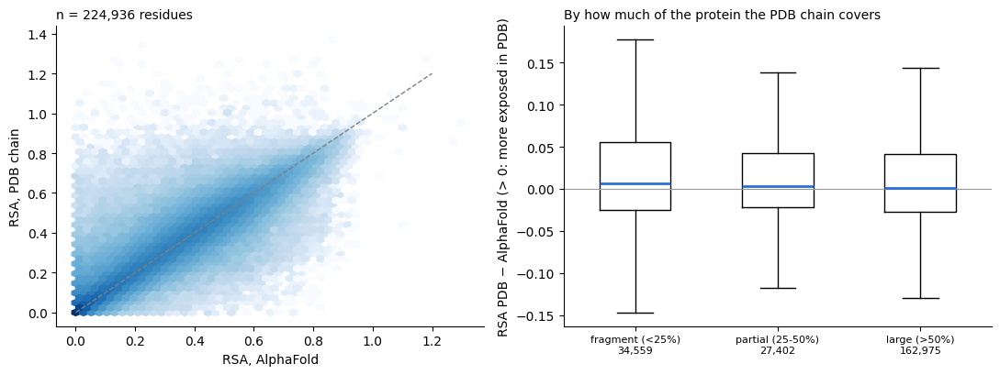

/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/2464048016.py:50: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  worst = both.groupby(["gene", "pdb_source"]).apply(lambda g: pd.Series({


,,residues,chain_coverage,median diff,same class
gene,pdb_source,,,,
RAB11FIP3,pdb:30dr_1,223.0,1.000,-0.173,0.274
KIF5A,pdb:4uxy_C,317.0,0.329,0.119,0.328
RPL10A,pdb:8yop_Lz,195.0,1.000,0.106,0.333
ARPC1A,pdb:6yw7_C,338.0,1.000,0.117,0.379
GNB5,pdb:8sh9_N,42.0,1.000,0.167,0.381
EIF1,pdb:9npx_k,52.0,1.000,0.055,0.404
PHLDB2,pdb:8whk_B,50.0,0.041,0.088,0.420
SNAP23,pdb:1nhl_A,52.0,0.256,0.140,0.462
EIF4G1,pdb:8oz0_2,209.0,0.877,0.020,0.464


In [44]:
# PDB vs AlphaFold RSA where both exist
from scipy.stats import spearmanr

def rsa_class(x):
    return pd.cut(x, [-np.inf, 0.20, 0.40, np.inf], right=False, labels=["core", "boundary", "surface"])

both = struct_df.dropna(subset=["rsa_pdb", "rsa_af"]).copy()    # rsa_af is already masked at pLDDT < 70
both["diff"] = both.rsa_pdb - both.rsa_af                        # > 0: more exposed in the PDB chain
both["class_pdb"], both["class_af"] = rsa_class(both.rsa_pdb), rsa_class(both.rsa_af)

# how much of the protein each chosen PDB chain covers (from PDBe's best_structures)
chain_cov = {f"pdb:{s['pdb_id']}_{s['chain_id']}": s["coverage"] for v in chosen.values() for s in v}
both["chain_coverage"] = both.pdb_source.map(chain_cov)
both["chain_type"] = pd.cut(both.chain_coverage, [0, 0.25, 0.5, 1.01],
                            labels=["fragment (<25%)", "partial (25-50%)", "large (>50%)"])
both["plddt_band"] = pd.cut(both.plddt, [70, 80, 90, 101], right=False, labels=["70-80", "80-90", "90+"])

print(f"{len(both):,} residues with both values in {both.gene.nunique()} genes "
      f"({len(both) / struct_df.rsa_pdb.notna().sum():.0%} of PDB residues)")
print(f"Spearman ρ = {spearmanr(both.rsa_pdb, both.rsa_af).statistic:.2f} | "
      f"median |diff| = {both['diff'].abs().median():.3f} | "
      f"same class: {(both.class_pdb == both.class_af).mean():.0%}")

# class agreement (rows = PDB, columns = AlphaFold), as a share of each PDB class
print(pd.crosstab(both.class_pdb, both.class_af, normalize="index").round(2))

# where the disagreement comes from
summary = lambda g: pd.Series({"residues": len(g), "median diff": g["diff"].median(),
                               "median |diff|": g["diff"].abs().median(),
                               "same class": (g.class_pdb == g.class_af).mean()})
print(both.groupby("chain_type", observed=True).apply(summary).round(3))
print(both.groupby("plddt_band", observed=True).apply(summary).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hexbin(both.rsa_af, both.rsa_pdb, gridsize=50, bins="log", cmap="Blues", mincnt=1)
axes[0].plot([0, 1.2], [0, 1.2], color="0.5", lw=1, ls="--")                 # perfect agreement
axes[0].set_xlabel("RSA, AlphaFold"); axes[0].set_ylabel("RSA, PDB chain")
axes[0].set_title(f"n = {len(both):,} residues", loc="left", fontsize=10)
data = [both.loc[both.chain_type == t, "diff"] for t in both.chain_type.cat.categories]
axes[1].boxplot(data, showfliers=False, widths=0.5, medianprops=dict(color="#2a6fdb", lw=2))
axes[1].set_xticks(range(1, len(data) + 1),
                   [f"{t}\n{len(d):,}" for t, d in zip(both.chain_type.cat.categories, data)], fontsize=8)
axes[1].axhline(0, color="0.6", lw=0.8)
axes[1].set_ylabel("RSA PDB − AlphaFold (> 0: more exposed in PDB)")
axes[1].set_title("By how much of the protein the PDB chain covers", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

# chains that disagree most with AlphaFold -> worth a look
worst = both.groupby(["gene", "pdb_source"]).apply(lambda g: pd.Series({
    "residues": len(g), "chain_coverage": g.chain_coverage.iloc[0],
    "median diff": g["diff"].median(), "same class": (g.class_pdb == g.class_af).mean()}))
worst[worst.residues >= 30].sort_values("same class").head(10).round(3)

**Fall back to AlphaFold where the PDB chain disagrees, and flag it.** Two levels:
- **Residue:** |`rsa_pdb` − `rsa_af`| > `RESIDUE_MAX_DIFF` → use the AlphaFold value for that residue. About 4% of overlapping residues at 0.25 in a 29-gene test.
- **Chain:** if more than `CHAIN_MAX_DISCREPANT` of a chain's overlapping residues are discrepant, distrust the whole chain → AlphaFold for every residue it supplied. In the test the typical chain had ~4% discrepant residues; one outlier (SNAP23 1NHL, a short fragment) had 35%.

The fallback only applies where AlphaFold has a value (pLDDT ≥ `PLDDT_MIN`). If AlphaFold is masked, the PDB value is kept but still flagged. Each residue gets `rsa_flag` (`residue_discrepant`, `chain_discrepant`, `chain_discrepant_no_af`, or empty). A **gene** is flagged if it has a distrusted chain, or if more than `GENE_MAX_SWITCHED` of its PDB residues were switched. Flagged chains and genes are saved to `structure_flags.csv`.

**A disagreement isn't automatically a PDB error.** It can be a real conformational difference (ligand-bound, in complex, a different functional state), and AlphaFold is a prediction. The flags are there so you can look. The thresholds are settings, and this cell recomputes from the cache, so changing them costs nothing.

In [45]:
# fall back to AlphaFold where PDB and AlphaFold RSA disagree; flag residues, chains and genes
RESIDUE_MAX_DIFF     = 0.25    # |rsa_pdb - rsa_af| above this -> residue uses AlphaFold
CHAIN_MAX_DISCREPANT = 0.20    # share of a chain's overlapping residues that are discrepant -> whole chain
MIN_OVERLAP          = 30      # judge a chain only with at least this many residues in common
GENE_MAX_SWITCHED    = 0.10    # flag a gene if more than this share of its PDB residues were switched

diff = (struct_df.rsa_pdb - struct_df.rsa_af).abs()             # NaN unless both exist
discrepant = diff > RESIDUE_MAX_DIFF

# chain level: overlap and share of discrepant residues per PDB chain
chain_stats = (struct_df.assign(diff=diff, discrepant=discrepant)[diff.notna()]
               .groupby(["gene", "pdb_source"])
               .agg(overlap=("diff", "size"), frac_discrepant=("discrepant", "mean"),
                    median_abs_diff=("diff", "median")))
bad = chain_stats[(chain_stats.overlap >= MIN_OVERLAP) & (chain_stats.frac_discrepant > CHAIN_MAX_DISCREPANT)]
in_bad_chain = pd.Series(list(zip(struct_df.gene, struct_df.pdb_source)), index=struct_df.index).isin(bad.index)

# residue flags, then replace rsa where AlphaFold has a value
has_af = struct_df.rsa_af.notna()
flag = pd.Series(pd.NA, index=struct_df.index, dtype="string")
flag[discrepant] = "residue_discrepant"
flag[in_bad_chain & has_af] = "chain_discrepant"              # chain-level wins over residue-level
flag[in_bad_chain & ~has_af] = "chain_discrepant_no_af"       # nothing to fall back to: PDB kept, flagged
use_af = has_af & (discrepant | in_bad_chain)

struct_df["rsa_flag"] = flag
struct_df.loc[use_af, "rsa"] = struct_df.loc[use_af, "rsa_af"]
struct_df.loc[use_af, "rsa_source"] = "alphafold"

# gene level: flag a gene with a distrusted chain, or with many individual residues switched
gene_flags = (struct_df.assign(switched=use_af, from_pdb=struct_df.rsa_pdb.notna())
              .groupby("gene").agg(pdb_residues=("from_pdb", "sum"), residues_switched=("switched", "sum")))
gene_flags["frac_switched"] = gene_flags.residues_switched / gene_flags.pdb_residues.where(gene_flags.pdb_residues > 0)
gene_flags["discrepant_chains"] = bad.reset_index().groupby("gene").pdb_source.agg(";".join)
gene_flags["flagged"] = gene_flags.discrepant_chains.notna() | (gene_flags.frac_switched > GENE_MAX_SWITCHED)
gene_flags = gene_flags[gene_flags.flagged].sort_values("frac_switched", ascending=False)
pd.concat({"chains": bad.reset_index(), "genes": gene_flags.reset_index()}).to_csv(
    os.path.join(OUT, "structure_flags.csv"))

print(f"residues switched to AlphaFold: {use_af.sum():,} "
      f"({use_af.sum() / struct_df.rsa_pdb.notna().sum():.1%} of PDB residues)")
print(f"chains flagged: {len(bad)} of {(chain_stats.overlap >= MIN_OVERLAP).sum()} judged | "
      f"genes flagged: {len(gene_flags)} of {struct_df.gene.nunique()}")
print("residue flags:", struct_df.rsa_flag.value_counts().to_dict())
gene_flags.round(3)

residues switched to AlphaFold: 10,917 (4.4% of PDB residues)
chains flagged: 18 of 871 judged | genes flagged: 54 of 1081
residue flags: {'residue_discrepant': 8549, 'chain_discrepant': 2368, 'chain_discrepant_no_af': 136}


,pdb_residues,residues_switched,frac_switched,discrepant_chains,flagged
gene,,,,,
SNAP23,52,52,1.000,pdb:1nhl_A,True
EIF1,52,52,1.000,pdb:9npx_k,True
EPN1,144,143,0.993,pdb:1inz_A,True
GNAL,133,130,0.977,pdb:8el8_A,True
GNB5,43,42,0.977,pdb:8sh9_N,True
ARPC1A,348,338,0.971,pdb:6yw7_C,True
KIF5A,332,317,0.955,pdb:4uxy_C,True
RPL10A,205,195,0.951,pdb:8yop_Lz,True
RAB11FIP3,236,223,0.945,pdb:30dr_1,True


### 7d. Interfaces with other chains

Two routes. **A** covers every gene quickly; **B** gives detail for structures you care about. Start with A, and use B to validate it and for showcase genes.

**Route A: PDBe-KB pre-computed interfaces (all genes, one request each)**

`https://www.ebi.ac.uk/pdbe/graph-api/uniprot/interface_residues/{acc}` returns, **already in UniProt numbering**, every residue that contacts another chain in *any* PDB entry, grouped by partner (with the partner's UniProt accession) and listing the supporting PDB entries. Tested on NLGN3: it returns the 8GS3 dimer interface.
- partner accession = own accession → `iface_homo`; a different accession → `iface_hetero`
- number of supporting entries → `iface_n_entries`
- the same API family has `/uniprot/ligand_sites/{acc}` for small-molecule contacts (→ §8)

**Route B: compute it yourself (selected structures)**

`structure.annotate_pdb(pdb_id, chain, partners={...})` and `find_contacts(pdb_id, chain)` (already in `figures/`) flag residues whose SASA drops ≥ 1 Å² when a partner chain is added. That gives a continuous `buried_sasa` per residue and per partner. It's the same ΔSASA logic as notebook 04.

**Pitfalls for both routes**
- **Crystal contacts:** neighbouring copies in a crystal lattice touch, but that's not biology. Use the *biological assembly* (`https://files.rcsb.org/download/{id}-assembly1.cif`) rather than the asymmetric unit, or require ≥ 2 supporting entries in Route A.
- **Non-native partners:** antibody Fabs, nanobodies and fusion tags used to solve cryo-EM structures. Drop partners whose accession isn't human, or whose name matches Fab / nanobody / antibody.
- **Homomeric copies:** decide whether a homodimer interface counts as "interface". Keep it as a separate column (`iface_homo`) so you can choose later.

**Encoding:** binary flags for the model; `iface_n_entries` and `buried_sasa` as confidence and strength for analysis.

In [46]:
# Route A: PDBe-KB interface residues for every gene (UniProt numbering -> MANE)
def interfaces_for_gene(gene):
    """Per MANE residue: iface_homo / iface_hetero / iface_n_entries / iface_partners.
    Antibody / nanobody partners (type 'AB') are dropped; only UniProt protein partners count."""
    acc, _, mane = GENE_INFO[gene]
    out = pd.DataFrame({"gene": gene, "pos": np.arange(1, len(mane) + 1),
                        "iface_homo": False, "iface_hetero": False, "iface_n_entries": 0, "iface_partners": ""})
    d = get_cached(f"{PDBE}/uniprot/interface_residues/{acc}", os.path.join(STRUCT_CACHE, "api", f"iface_{acc}.json"))
    if not d:
        return out                                          # no structure with a partner
    d = d[acc]
    mapping, _ = align_to_mane(d["sequence"], mane)         # UniProt canonical -> MANE
    entries = [set() for _ in mane]                         # PDB entries supporting each residue
    partners = [set() for _ in mane]
    for partner in d["data"]:
        if partner["additionalData"].get("type") != "UNP":
            continue                                        # antibodies, nanobodies, etc.
        col = "iface_homo" if partner["accession"] == acc else "iface_hetero"
        for r in partner["residues"]:
            pdbs = {e["pdbId"] for e in r["interactingPDBEntries"]}
            for u in range(r["startIndex"], r["endIndex"] + 1):   # UniProt numbering, 1-based
                p = mapping.get(u - 1)
                if p is None:
                    continue                                # residue not in the MANE isoform
                out.at[p - 1, col] = True
                entries[p - 1] |= pdbs
                partners[p - 1].add(partner["accession"])
    out["iface_n_entries"] = [len(e) for e in entries]
    out["iface_partners"] = [";".join(sorted(s)) for s in partners]
    return out

with ThreadPoolExecutor(N_WORKERS) as pool:
    iface_df = pd.concat(pool.map(interfaces_for_gene, GENE_INFO), ignore_index=True)
iface_df["iface_any"] = iface_df.iface_homo | iface_df.iface_hetero
print(f"interface residues: {iface_df.iface_any.mean():.1%} of residues "
      f"(homo {iface_df.iface_homo.mean():.1%}, hetero {iface_df.iface_hetero.mean():.1%}) in "
      f"{iface_df[iface_df.iface_any].gene.nunique()} genes")

interface residues: 7.8% of residues (homo 2.7%, hetero 5.8%) in 703 genes


In [47]:
# Route B: your ΔSASA method on the top structure of a few showcase genes, to validate Route A
from structure import find_contacts, annotate_pdb

SHOWCASE = ["NLGN3", "GRIN1", "DLG4"]                       # any genes with a PDB complex

route_b = []
for gene in [g for g in SHOWCASE if g in GENE_INFO and chosen.get(g)]:
    acc, _, mane = GENE_INFO[gene]
    s = chosen[gene][0]                                     # best-ranked chain
    try:
        try:
            contacts = find_contacts(s["pdb_id"], s["chain_id"])      # which chains bury this one
        except KeyError:                                     # find_contacts fails on an empty result
            contacts = pd.DataFrame()
        if contacts.empty:
            print(f"{gene} {s['pdb_id']}_{s['chain_id']}: no partner chains in this structure"); continue
        partners = {f"{r.entry}_{r.partner_chain}": [r.partner_chain] for r in contacts.itertuples()}
        ann = annotate_pdb(s["pdb_id"], s["chain_id"], partners=partners)
    except Exception as e:                                  # e.g. very large entries have no .pdb file
        print(f"{gene} {s['pdb_id']}: skipped ({repr(e)[:80]})"); continue
    res = ann["residues"]
    mapping, _ = align_to_mane(ann["sequence"], mane)       # UniProt -> MANE
    buried = res.filter(like="buried_").sum(axis=1)         # Å² buried by all partners together
    b = pd.DataFrame({"gene": gene, "pos": res.unp_resnum.map(lambda u: mapping.get(u - 1)),
                      "buried_sasa": buried.to_numpy()}).dropna()
    b["pos"] = b.pos.astype(int)
    route_b.append(b)
    a = iface_df[iface_df.gene == gene].set_index("pos").iface_any
    in_b = set(b.pos[b.buried_sasa >= 1.0])                 # same 1 Å² threshold as notebook 04
    in_a = set(a[a].index) & set(b.pos)                     # Route A, restricted to residues in this structure
    print(f"{gene} {s['pdb_id']}_{s['chain_id']} ({len(partners)} partner chains): Route B {len(in_b)} | "
          f"Route A {len(in_a)} | both {len(in_a & in_b)} | "
          f"B found by A {len(in_a & in_b) / max(len(in_b), 1):.0%}")
route_b_df = pd.concat(route_b, ignore_index=True) if route_b else pd.DataFrame(columns=["gene", "pos", "buried_sasa"])

NLGN3 8gs3_A (1 partner chains): Route B 22 | Route A 12 | both 12 | B found by A 55%
GRIN1 9pqh_B (1 partner chains): Route B 20 | Route A 18 | both 18 | B found by A 90%
DLG4 6spv_A: no partner chains in this structure


### 7e. Merge into `residue_df` + checks

- Fill `rsa`, `rsa_class`, `rsa_source`, `plddt`, `iface_*` by `(gene, pos)`.
- Interface residues should mostly be `surface`/`boundary` when the chain is alone; a large share of `core` interface residues suggests a numbering error.
- Coverage table: genes × (% PDB, % AlphaFold, % masked, % interface).
- Save `structure_scores.parquet` to `OUT`.

In [48]:
# merge into residue_df + checks + save
STRUCT_COLS = ["rsa", "rsa_source", "rsa_flag", "plddt", "rsa_pdb", "rsa_af", "rsa_class", "iface_homo", "iface_hetero", "iface_any",
               "iface_n_entries", "iface_partners", "buried_sasa"]
merged = (struct_df[["gene", "pos", "rsa", "rsa_source", "rsa_flag", "plddt", "rsa_pdb", "rsa_af", "aa_pdb"]]   # both kept: choose later
          .merge(iface_df, on=["gene", "pos"], how="left")
          .merge(route_b_df, on=["gene", "pos"], how="left"))
merged["rsa_class"] = pd.cut(merged.rsa, [-np.inf, 0.20, 0.40, np.inf], right=False,
                             labels=["core", "boundary", "surface"]).astype("string")   # notebook 04 cut-offs

residue_df = residue_df.drop(columns=[c for c in STRUCT_COLS if c in residue_df]).merge(
    merged.drop(columns="aa_pdb"), on=["gene", "pos"], how="left")
for c in ["iface_homo", "iface_hetero", "iface_any"]:       # nullable: <NA> for genes not run
    residue_df[c] = residue_df[c].astype("boolean")
residue_df["iface_n_entries"] = residue_df.iface_n_entries.astype("Int64")
ran = residue_df[residue_df.gene.isin(GENE_INFO)]          # genes processed in this run

# 1. numbering: the residue seen in the PDB structure should be the MANE residue
chk = merged.dropna(subset=["aa_pdb"]).merge(residue_df[["gene", "pos", "aa"]], on=["gene", "pos"])
print(f"PDB residue == MANE residue: {(chk.aa_pdb == chk.aa).mean():.1%} of {len(chk):,} "
      f"(mismatches = engineered mutations / variants in the crystal)")
# 2. interface residues should mostly be exposed when the chain is alone
print("interface residues by RSA class (chain alone):",
      ran[ran.iface_any.fillna(False)].rsa_class.value_counts(normalize=True).round(2).to_dict())
# 3. coverage per gene: share of residues with RSA from PDB / AlphaFold / none (masked or no model)
src = ran.rsa_source.fillna("none").str.split(":").str[0]
coverage = (pd.crosstab(ran.gene, src, normalize="index")
            .join(ran.groupby("gene").iface_any.mean().astype(float).rename("interface")).round(3))
print(f"mean per gene: {coverage.mean().round(3).to_dict()}")

merged.to_parquet(os.path.join(OUT, "structure_scores.parquet"), index=False)
residue_df.to_parquet(os.path.join(OUT, "residue_scores.parquet"), index=False)   # master table, now with §7
coverage.sort_values("interface", ascending=False).head(10)

PDB residue == MANE residue: 99.8% of 247,425 (mismatches = engineered mutations / variants in the crystal)
interface residues by RSA class (chain alone): {'surface': 0.47, 'boundary': 0.31, 'core': 0.22}
mean per gene: {'alphafold': 0.306, 'none': 0.309, 'pdb': 0.385, 'interface': 0.138}


,alphafold,none,pdb,interface
gene,,,,
CALM1,0.067,0.040,0.893,1.000
SEM1,0.157,0.414,0.429,1.000
RPS28,0.029,0.043,0.928,0.884
BRK1,0.120,0.080,0.800,0.867
RPS21,0.012,0.000,0.988,0.831
PHB2,0.836,0.164,0.000,0.826
RPS17,0.044,0.007,0.948,0.807
PSMC1,0.036,0.066,0.898,0.807
PSMC2,0.032,0.046,0.921,0.806


### 7f. First look: tolerance and ESM by structural class

Median tolerance (and ESM) for **core**, **boundary**, **non-interface surface** and **interface surface**, split into ordered and disordered residues. This is the same idea as `variants.variant_class_table` from the NLGN work, now on every gene.

- Expected: interface surface is less tolerant than other surface, closer to core.
- Variant-level: AUROC of `iface_any` and `rsa` for held-out pathogenic vs. benign (reuse `val_scored` from 6g).
- Structures don't use any variant data, so no hold-out is needed here. **But PDB coverage is biased towards well-studied genes**, so compare within genes too.

             tolerance_v4_centered         esm_mean_llr                n
region                  disordered ordered   disordered ordered residues
struct_class                                                            
core                        -0.046   0.000       -9.203 -10.941   199474
boundary                    -0.038   0.012       -7.216  -8.073   104761
interface                   -0.033  -0.002       -7.911 -10.081    43788
surface                     -0.039   0.019       -7.155  -6.972   126626


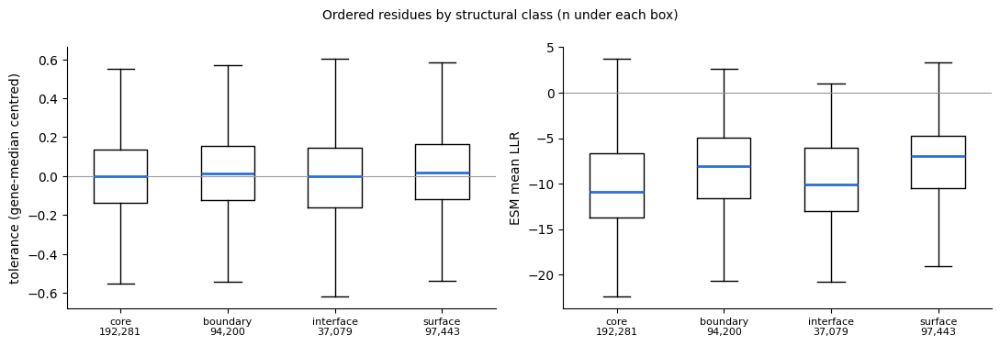

pathogenic vs benign AUROC, rsa: 0.692 (n = 1,300)
pathogenic vs benign AUROC, iface_any: 0.619 (n = 2,477)
clinsig_group  benign  pathogenic  frac_pathogenic
struct_class                                      
core              220         327             0.60
boundary          172          63             0.27
interface          56         118             0.68
surface           292          52             0.15


In [49]:
# tolerance and ESM by structural class
def struct_class(df):
    """core / boundary / surface, with exposed interface residues split out as 'interface'."""
    c = df.rsa_class.astype("object").copy()
    c[(df.iface_any == True) & df.rsa_class.isin(["surface", "boundary"])] = "interface"
    return c

CLASSES = ["core", "boundary", "interface", "surface"]
r = residue_df[residue_df.tolerance_ok].copy()
r["struct_class"] = struct_class(r)
r["region"] = np.where(r.disorder >= 0.5, "disordered", "ordered")

table = (r.groupby(["region", "struct_class"])[["tolerance_v4_centered", "esm_mean_llr"]]
         .median().unstack("region").reindex(CLASSES))
table[("n", "residues")] = r.struct_class.value_counts().reindex(CLASSES)
print(table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (col, label) in zip(axes, [("tolerance_v4_centered", "tolerance (gene-median centred)"),
                                   ("esm_mean_llr", "ESM mean LLR")]):
    data = [r.loc[(r.struct_class == c) & (r.region == "ordered"), col].dropna() for c in CLASSES]
    ax.boxplot(data, showfliers=False, widths=0.5, medianprops=dict(color="#2a6fdb", lw=2))
    ax.set_xticks(range(1, len(CLASSES) + 1), [f"{c}\n{len(d):,}" for c, d in zip(CLASSES, data)], fontsize=8)
    ax.set_ylabel(label); ax.axhline(0, color="0.6", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Ordered residues by structural class (n under each box)", fontsize=10)
fig.tight_layout(); plt.show()

# variant level: held-out ClinVar pathogenic vs benign (pb from §6g), and ClinVar share by class
pbs = pb.merge(residue_df[["gene", "pos", "rsa", "rsa_class", "iface_any"]],
               left_on=["gene", "position"], right_on=["gene", "pos"], how="left")
pbs["struct_class"] = struct_class(pbs)
y = pbs.clinsig_group == "benign"
for col, sign in [("rsa", 1), ("iface_any", -1)]:            # exposed -> benign; interface -> pathogenic
    ok = pbs[col].notna()
    print(f"pathogenic vs benign AUROC, {col}: {roc_auc_score(y[ok], sign * pbs.loc[ok, col].astype(float)):.3f} "
          f"(n = {ok.sum():,})")
print(pd.crosstab(pbs.struct_class, pbs.clinsig_group).reindex(CLASSES)
      .assign(frac_pathogenic=lambda t: (t.pathogenic / t.sum(axis=1)).round(2)))

---
## 8. Protein annotation features

**Goal:** per-residue annotation tracks (domains, families, motifs, PTMs, binding regions) for three uses:
1. **Explaining** where tolerance and ESM disagree (§6). For example, ESM is weakest in disordered regions, which is exactly where short binding motifs and PTM sites live.
2. **Stratifying** evaluations: does the model do worse in motifs? In unannotated regions?
3. **Optional model inputs** (§12), concatenated to the ESM embedding.

All sources are keyed by UniProt accession, so they need the same UniProt → MANE mapping as §7b.

### 8a. Sources

| Source | What it adds | Access | Status |
|---|---|---|---|
| **InterPro** (Pfam, **PANTHER**, SMART, CDD, PROSITE, Gene3D, …) | domains; **PANTHER family / subfamily** (one per protein) | REST API | **already cached:** `Model Training/interpro_cache/` (1,081 proteins) |
| **UniProt features** | domains, regions, motifs, PTMs, binding/active sites, transmembrane, signal peptide, disulfides | REST; `conservation.uniprot_features()`, `ptm.uniprot_ptms()` | helpers exist |
| **MobiDB** | consensus disorder, **linear interacting peptides (LIPs)** = binding regions inside disorder, PTMs, MSA conservation, pLDDT, Pfam, TM/signal: **one request per protein** | `https://mobidb.org/api/download?acc={acc}&format=json` | tested |
| **ELM** | curated short linear motif instances, plus motif-class regexes to scan for new ones, e.g. **PDZ-binding C-termini** (central at the PSD), SH3-binding, 14-3-3 | `http://elm.eu.org/instances.tsv?q={acc}`; class list `elm_classes.tsv` | tested |
| **PDBe-KB ligand sites** | residues contacting small molecules / ions in PDB | `.../graph-api/uniprot/ligand_sites/{acc}` (404 = none) | same API as §7 |
| **PROSITE** (ScanProsite) | pattern matches beyond InterPro's | REST | optional |
| **PhosphoSitePlus** | the most complete PTM set | download; free for academic use, needs an account | optional |
| **PANTHER-PSEP** | how long each position has been preserved in evolution, a variant-effect score | PANTHER coding-SNP tool; programmatic access to be checked | optional |

**Comparator scores, not features** (for §6 and §16 benchmarking): **AlphaMissense** (per-variant pathogenicity, downloadable), **gnomAD regional missense constraint**, **MTR** (missense tolerance ratio). These are independent tolerance/pathogenicity scores to benchmark against, not inputs.

In [50]:
# settings: which genes, where caches live (uses get_cached / align_to_mane / N_WORKERS from §7)
import re
ANNOT_CACHE = os.path.join(OUT, "annotation_cache")         # uniprot/ mobidb/ ligands/ + ELM files
for sub in ("uniprot", "mobidb", "ligands"):
    os.makedirs(os.path.join(ANNOT_CACHE, sub), exist_ok=True)
INTERPRO_CACHE = os.path.join(MODEL_DIR, "interpro_cache")   # already holds 1,077 proteins from the ESM notebook

ANNOT_GENES = GENES_TO_RUN                                 # same genes as §7 (None = all)
annot_genes = psd_seq_df if ANNOT_GENES is None else psd_seq_df[psd_seq_df.gene.isin(ANNOT_GENES)]
A_INFO = dict(zip(annot_genes.gene, zip(annot_genes.uniprot_id, annot_genes.sequence)))   # gene -> (acc, MANE)

ELM_SCAN_PREFIX = "LIG_PDZ"     # ELM motif classes to scan for in MANE sequences (PDZ-binding C-termini)
LIGAND_IGNORE = {               # solvents / crystallisation additives -- not biological ligand sites
    "HOH", "GOL", "EDO", "SO4", "PO4", "PEG", "PGE", "PG4", "1PE", "P6G", "ACT", "ACY", "DMS", "FMT", "MPD",
    "TRS", "EPE", "MES", "CL", "NA", "K", "IOD", "BR", "NO3", "IMD", "BME", "DTT", "TLA", "CIT", "MLI",
    "SCN", "NH4", "UNX", "UNL", "BU3", "PE4", "MRD", "IPA", "EOH", "MOH", "NI"}
print(f"{len(A_INFO)} genes")

1082 genes


### 8b. Fetch and cache

One function per source → one JSON per UniProt accession in its own cache folder, with the same pattern as `fetch_gnomad_counts` (skip if cached; back off on 429; collect failures instead of stopping). The InterPro cache only needs loading.

In [51]:
# fetch + cache every source (one file per protein; ELM is two whole-human downloads)
UNIPROT_FIELDS = ",".join([                                # the feature types we use -- variant features are
    "sequence", "ft_domain", "ft_repeat", "ft_zn_fing", "ft_motif", "ft_region", "ft_coiled",   # never requested
    "ft_mod_res", "ft_carbohyd", "ft_lipid", "ft_crosslnk", "ft_disulfid",
    "ft_transmem", "ft_intramem", "ft_signal", "ft_act_site", "ft_binding"])

def fetch_uniprot_entry(acc):
    return get_cached(f"https://rest.uniprot.org/uniprotkb/{acc}.json?fields={UNIPROT_FIELDS}",
                      os.path.join(ANNOT_CACHE, "uniprot", f"{acc}.json"))

def fetch_mobidb(acc):
    return get_cached(f"https://mobidb.org/api/download?acc={acc}&format=json",
                      os.path.join(ANNOT_CACHE, "mobidb", f"{acc}.json"))

def fetch_ligand_sites(acc):                                # 404 (no ligands) is cached as None
    return get_cached(f"{PDBE}/uniprot/ligand_sites/{acc}", os.path.join(ANNOT_CACHE, "ligands", f"{acc}.json"))

def fetch_interpro(acc):
    """Cached InterPro features in the ESM notebook's format: [{source, accession, name, type, start, end}]."""
    path = os.path.join(INTERPRO_CACHE, f"{acc}.json")
    if os.path.exists(path):
        return json.load(open(path))
    url, raw = f"https://www.ebi.ac.uk/interpro/api/entry/all/protein/uniprot/{acc}/", []
    while url:                                              # paginated
        r = requests.get(url, timeout=120)
        if r.status_code == 429:
            time.sleep(int(r.headers.get("Retry-After", 5))); continue
        if r.status_code == 204:                            # no annotations
            break
        r.raise_for_status()
        data = r.json(); raw += data["results"]; url = data.get("next")
    feats = [{"source": e["metadata"]["source_database"], "accession": e["metadata"]["accession"],
              "name": e["metadata"]["name"], "type": e["metadata"]["type"],
              "start": f["start"], "end": f["end"]}
             for e in raw for p in e.get("proteins", []) for loc in p.get("entry_protein_locations", [])
             for f in loc["fragments"]]
    json.dump(feats, open(path, "w"), indent=2)
    return feats

def read_elm_tsv(url, name):
    text = get_cached(url, os.path.join(ANNOT_CACHE, name), as_json=False)
    return pd.read_csv(io.StringIO("\n".join(l for l in text.splitlines() if not l.startswith("#"))), sep="\t")

elm_instances = read_elm_tsv("http://elm.eu.org/instances.tsv?q=*&taxon=Homo%20sapiens"
                             "&instance_logic=true%20positive", "elm_instances_human.tsv")
elm_classes = read_elm_tsv("http://elm.eu.org/elms/elms_index.tsv", "elm_classes.tsv")

def fetch_all(acc):
    return {"uniprot": fetch_uniprot_entry(acc), "mobidb": fetch_mobidb(acc),
            "ligands": fetch_ligand_sites(acc), "interpro": fetch_interpro(acc)}

t0, sources, fetch_errors = time.time(), {}, {}
with ThreadPoolExecutor(N_WORKERS) as pool:
    futures = {pool.submit(fetch_all, acc): g for g, (acc, _) in A_INFO.items()}
    for f in as_completed(futures):
        try:
            sources[futures[f]] = f.result()
        except Exception as e:                              # keep going; list failures at the end
            fetch_errors[futures[f]] = repr(e)[:150]
print(f"fetched in {time.time() - t0:.0f} s | ELM: {len(elm_instances):,} human instances, "
      f"{len(elm_classes)} classes | failed: {fetch_errors or 'none'}")
print("missing per source:", {s: sum(v[s] is None for v in sources.values()) for s in ["uniprot", "mobidb", "ligands"]})

fetched in 15 s | ELM: 2,270 human instances, 353 classes | failed: none
missing per source: {'uniprot': 0, 'mobidb': 0, 'ligands': 480}


### 8c. Normalise to one long annotation table

`annotation_df`: one row per feature: `gene, uniprot_id, source, category, name, start, end, numbering`, with `category` from a fixed vocabulary:

| category | from |
|---|---|
| `domain`, `repeat` | UniProt Domain / Zinc finger / Repeat; InterPro member-database domains and repeats (Pfam, SMART, CDD, PROSITE profiles, …) |
| `motif` | UniProt Motif; curated ELM instances |
| `motif_predicted` | ELM class regexes scanned on the MANE sequence (`ELM_SCAN_PREFIX`, default PDZ-binding classes) |
| `binding_region` | UniProt Regions described as "Interaction with …" / "…-binding" |
| `lip` / `lip_predicted` | MobiDB linear interacting peptides: curated + derived from structures / predicted |
| `ptm`, `disulfide` | UniProt modified residues, glycosylation, lipidation, cross-links; disulfide bonds (both cysteines) |
| `ligand_site`, `active_site`, `conserved_site` | UniProt binding / active sites, PDBe-KB ligand contacts (solvents and additives removed); InterPro site signatures |
| `coiled_coil`, `transmembrane`, `signal`, `disorder_curated` | UniProt; MobiDB curated disorder (DisProt) |

PANTHER **families** (gene-level, not per residue) are kept separately. InterPro families and superfamilies span the whole protein, so they aren't per-residue features.

**Exclude** UniProt `Natural variant` and `Mutagenesis` features. They're derived from disease variants and functional assays, so they'd leak ClinVar-like information into features.

In [52]:
# normalise every source into one long table: gene, uniprot_id, source, category, name, start, end
# (UniProt canonical numbering, except ELM scan hits, which are found directly in MANE: numbering = "mane")
UNIPROT_CATEGORY = {"Domain": "domain", "Zinc finger": "domain", "Repeat": "repeat", "Motif": "motif",
                    "Coiled coil": "coiled_coil", "Modified residue": "ptm", "Glycosylation": "ptm",
                    "Lipidation": "ptm", "Cross-link": "ptm", "Disulfide bond": "disulfide",
                    "Transmembrane": "transmembrane", "Intramembrane": "transmembrane", "Signal": "signal",
                    "Active site": "active_site", "Binding site": "ligand_site"}
INTERPRO_CATEGORY = {"domain": "domain", "repeat": "repeat", "active_site": "active_site",
                     "conserved_site": "conserved_site", "binding_site": "conserved_site", "ptm": "conserved_site"}
MOBIDB_TRACKS = {"curated-lip-merge": "lip", "derived-lip-merge": "lip",            # experimental binding in disorder
                 "prediction-lip-priority": "lip_predicted", "curated-disorder-priority": "disorder_curated"}

def normalise(gene, acc, src, mane):
    rows = []
    add = lambda source, cat, name, s, e: rows.append(
        {"gene": gene, "uniprot_id": acc, "source": source, "category": cat, "name": name,
         "start": int(s), "end": int(e), "numbering": "uniprot"})
    for f in (src["uniprot"] or {}).get("features", []):
        cat = UNIPROT_CATEGORY.get(f["type"])
        desc = f.get("description", "")
        s, e = f["location"]["start"].get("value"), f["location"]["end"].get("value")
        if f["type"] == "Region" and any(w in desc.lower() for w in ("interact", "bind")):
            cat = "binding_region"                          # e.g. "Interaction with SHANK3"; skips "Disordered"
        if cat is None or s is None or e is None:
            continue
        if cat == "disulfide":                              # a bond joins two residues, not a range
            add("uniprot", cat, desc, s, s); add("uniprot", cat, desc, e, e)
        else:
            add("uniprot", cat, desc or f["type"], s, e)
    for f in src["interpro"] or []:
        if f["type"] in INTERPRO_CATEGORY:                  # families / superfamilies span the whole protein
            add(f["source"], INTERPRO_CATEGORY[f["type"]], f"{f['accession']} {f['name'] or ''}".strip(),
                f["start"], f["end"])
    m = src["mobidb"] or {}
    for key, cat in MOBIDB_TRACKS.items():
        for s, e in (m.get(key) or {}).get("regions", []):
            add("mobidb", cat, key, s, e)
    for lig in ((src["ligands"] or {}).get(acc) or {}).get("data", []):
        if lig["accession"] in LIGAND_IGNORE or (lig.get("additionalData") or {}).get("isSolvent"):
            continue
        for r in lig["residues"]:
            add("pdbe_ligands", "ligand_site", f"{lig['accession']} {lig['name']}", r["startIndex"], r["endIndex"])
    for r in elm_instances[elm_instances.Primary_Acc == acc].itertuples():
        add("elm", "motif", r.ELMIdentifier, r.Start, r.End)
    for cls in elm_classes[elm_classes.ELMIdentifier.str.startswith(ELM_SCAN_PREFIX)].itertuples():
        for hit in re.finditer(cls.Regex, mane):            # scanned on MANE directly
            rows.append({"gene": gene, "uniprot_id": acc, "source": "elm_scan", "category": "motif_predicted",
                         "name": cls.ELMIdentifier, "start": hit.start() + 1, "end": hit.end(), "numbering": "mane"})
    return rows

annotation_df = pd.DataFrame([r for g, (acc, mane) in A_INFO.items() if g in sources
                              for r in normalise(g, acc, sources[g], mane)])
print(f"{len(annotation_df):,} annotations in {annotation_df.gene.nunique()} genes")
annotation_df.groupby(["category", "source"]).size().unstack(fill_value=0)

117,955 annotations in 1081 genes


source,cdd,elm,elm_scan,interpro,mobidb,ncbifam,pdbe_ligands,pfam,prints,profile,prosite,smart,uniprot
category,,,,,,,,,,,,,
active_site,0,0,0,79,0,0,0,0,0,0,0,0,164
binding_region,0,0,0,0,0,0,0,0,0,0,0,0,532
coiled_coil,0,0,0,0,0,0,0,0,0,0,0,0,233
conserved_site,0,0,0,661,0,0,0,69,0,0,984,0,0
disorder_curated,0,0,0,0,439,0,0,0,0,0,0,0,0
disulfide,0,0,0,0,0,0,0,0,0,0,0,0,2900
domain,1779,0,0,3810,0,15,0,2215,341,2331,0,2981,1873
ligand_site,0,0,0,0,0,0,67038,0,0,0,0,0,2505
lip,0,0,0,0,1442,0,0,0,0,0,0,0,0


### 8d. Map to MANE and expand to per-residue tracks

- UniProt → MANE positions (the §7b mapping).
- One boolean column per category in `residue_df`, named `ann_<category>` (e.g. `ann_domain`, `ann_motif`, `ann_lip`), plus `msa_conservation` (MobiDB PSI-BLAST conservation, continuous) and `n_annotations` (how many non-predicted categories mark the residue).
- Gene-level: `panther_family` / `panther_subfamily`. **These are also the natural grouping for the §10 split**: paralogs share a PANTHER family, so whole families go to one split.

In [53]:
# map UniProt canonical -> MANE and expand to one boolean column per category (+ continuous conservation)
CATEGORIES = ["domain", "repeat", "motif", "motif_predicted", "binding_region", "lip", "lip_predicted",
              "ptm", "disulfide", "ligand_site", "active_site", "conserved_site", "coiled_coil",
              "transmembrane", "signal", "disorder_curated"]

ANN_BY_GENE = dict(tuple(annotation_df.groupby("gene")))
CANON_MAP = {}                                                          # gene -> {canonical index: MANE position}

def tracks_for_gene(gene):
    acc, mane = A_INFO[gene]
    src = sources.get(gene, {})
    canon = ((src.get("uniprot") or {}).get("sequence") or {}).get("value", "")
    mapping, _ = align_to_mane(canon, mane) if canon else ({}, 0)       # canonical index -> MANE position
    CANON_MAP[gene] = mapping
    to_mane = lambda u: mapping.get(u - 1)                              # 1-based UniProt -> 1-based MANE
    out = {f"ann_{c}": np.zeros(len(mane), bool) for c in CATEGORIES}
    for r in ANN_BY_GENE.get(gene, annotation_df.iloc[:0]).itertuples():
        for u in range(r.start, r.end + 1):
            p = u if r.numbering == "mane" else to_mane(u)
            if p is not None and 1 <= p <= len(mane):
                out[f"ann_{r.category}"][p - 1] = True
    cons = np.full(len(mane), np.nan)                                   # MobiDB PSI-BLAST conservation
    scores = ((src.get("mobidb") or {}).get("homology-msa_conservation-psiblast") or {}).get("scores", [])
    for i, s in enumerate(scores):
        if mapping.get(i) is not None:
            cons[mapping[i] - 1] = s
    df = pd.DataFrame({"gene": gene, "pos": np.arange(1, len(mane) + 1), **out, "msa_conservation": cons})
    df["n_annotations"] = df[[f"ann_{c}" for c in CATEGORIES if not c.endswith("_predicted")]].sum(axis=1)
    return df

annot_res = pd.concat([tracks_for_gene(g) for g in A_INFO if g in sources], ignore_index=True)

# gene level: PANTHER family (the natural paralog grouping for the §10 split)
panther = {g: next(((f["accession"], f["name"]) for f in (s["interpro"] or []) if f["source"] == "panther"),
                   (None, None)) for g, s in sources.items()}
psd_seq_df["panther_family"] = psd_seq_df.gene.map(lambda g: panther.get(g, (None, None))[0])
psd_seq_df["panther_name"] = psd_seq_df.gene.map(lambda g: panther.get(g, (None, None))[1])

ANNOT_COLS = [f"ann_{c}" for c in CATEGORIES] + ["msa_conservation", "n_annotations", "panther_family"]
residue_df = residue_df.drop(columns=[c for c in ANNOT_COLS if c in residue_df]).merge(
    annot_res, on=["gene", "pos"], how="left")
residue_df["panther_family"] = residue_df.gene.map(dict(zip(psd_seq_df.gene, psd_seq_df.panther_family)))
for c in [f"ann_{c}" for c in CATEGORIES]:
    residue_df[c] = residue_df[c].astype("boolean")                  # <NA> for genes not run

annotation_df.to_parquet(os.path.join(OUT, "annotations_long.parquet"), index=False)
annot_res.to_parquet(os.path.join(OUT, "annotation_tracks.parquet"), index=False)
residue_df.to_parquet(os.path.join(OUT, "residue_scores.parquet"), index=False)   # master table, now with §8
print(f"residue_df: {residue_df.shape[1]} columns; PANTHER family for "
      f"{psd_seq_df.panther_family.notna().sum()} genes in {psd_seq_df.panther_family.nunique()} families")

residue_df: 50 columns; PANTHER family for 1078 genes in 642 families


### 8e. Checks

- Coverage: % of residues in each category, per gene and overall.
- Mapping: annotated motif residues match the motif pattern in the MANE sequence (e.g. ELM regex re-matches at the mapped position).
- Known cases: NLGN C-terminal PDZ-binding motif (`TTRV`) and the gephyrin-binding motif show up for the NLGNs.

In [54]:
# checks: coverage, mapping, known cases
ran = residue_df[residue_df.gene.isin(A_INFO)]
cov = pd.DataFrame({"% residues": ran[[f"ann_{c}" for c in CATEGORIES]].mean().mul(100).round(1).values,
                    "genes with any": [ran.groupby("gene")[f"ann_{c}"].any().sum() for c in CATEGORIES]},
                   index=CATEGORIES)
print(f"msa_conservation available for {ran.msa_conservation.notna().mean():.0%} of residues")

# mapping: each curated ELM instance's class regex should match again at its mapped MANE location
regex = dict(zip(elm_classes.ELMIdentifier, elm_classes.Regex))
hits = []
for r in annotation_df[annotation_df.source == "elm"].itertuples():
    m = CANON_MAP.get(r.gene, {})
    s, e = m.get(r.start - 1), m.get(r.end - 1)
    if s and e and r.name in regex:
        window = A_INFO[r.gene][1][max(0, s - 3):e + 2]                # small slack for regex anchors
        try:
            hits.append(re.search(regex[r.name].strip("^$"), window) is not None)
        except re.error:                                                # a few ELM regexes aren't Python-compatible
            pass
print(f"curated ELM instances re-matching their class regex in MANE: "
      f"{np.mean(hits):.0%} of {len(hits)}" if hits else "no curated ELM instances in these genes")

# known cases: NLGN C-terminal PDZ-binding motif; DLG4's three PDZ domains
for g in [g for g in ("NLGN1", "NLGN2", "NLGN3", "DLG4") if g in A_INFO]:
    a = annotation_df[annotation_df.gene == g]
    print(f"{g}: C-terminal PDZ motif predicted: {(a.category == 'motif_predicted').any()} "
          f"({A_INFO[g][1][-4:]}) | PDZ domains (UniProt): "
          f"{(a.name.str.contains('PDZ') & (a.source == 'uniprot') & (a.category == 'domain')).sum()}")
cov

msa_conservation available for 53% of residues
curated ELM instances re-matching their class regex in MANE: 99% of 285
NLGN1: C-terminal PDZ motif predicted: True (TTRV) | PDZ domains (UniProt): 0
NLGN2: C-terminal PDZ motif predicted: True (TTRV) | PDZ domains (UniProt): 0
NLGN3: C-terminal PDZ motif predicted: True (TTRV) | PDZ domains (UniProt): 0
DLG4: C-terminal PDZ motif predicted: True (RERL) | PDZ domains (UniProt): 3


,% residues,genes with any
domain,58.0,969
repeat,12.7,240
motif,0.5,285
motif_predicted,0.3,327
binding_region,6.3,296
lip,4.3,614
lip_predicted,19.8,1014
ptm,1.0,989
disulfide,0.4,229
ligand_site,2.5,589


### 8f. First look: where do annotations explain the tolerance–ESM gap?

- Median tolerance and ESM inside vs. outside each category, split by ordered/disordered.
- Of residues where tolerance is low but ESM says "harmless" (the disagreement from §6), what fraction fall in motifs, LIPs, PTM sites or interfaces compared with all residues? An enrichment here means annotations carry information ESM misses, and they're worth adding as model inputs.

median inside category minus median of all residues (negative = less tolerant / more constrained):
                          n            tolerance         esm_mean_llr        
region           disordered   ordered disordered ordered   disordered ordered
category                                                                     
active_site             NaN    1089.0        NaN  -0.088          NaN  -7.293
binding_region      21073.0   27876.0      0.004  -0.009       -0.193  -1.132
coiled_coil         18926.0    6143.0     -0.009   0.022       -1.402   0.740
conserved_site       2578.0   16950.0     -0.034  -0.019       -4.619  -3.205
disorder_curated    17210.0    7261.0      0.025   0.019       -0.079   1.580
disulfide             138.0    2724.0     -0.037  -0.003       -6.825  -4.692
domain              55392.0  395643.0     -0.008  -0.004       -0.652  -0.819
ligand_site           754.0   18384.0     -0.009  -0.038       -5.592  -3.859
lip                 19248.0   14162.0     -

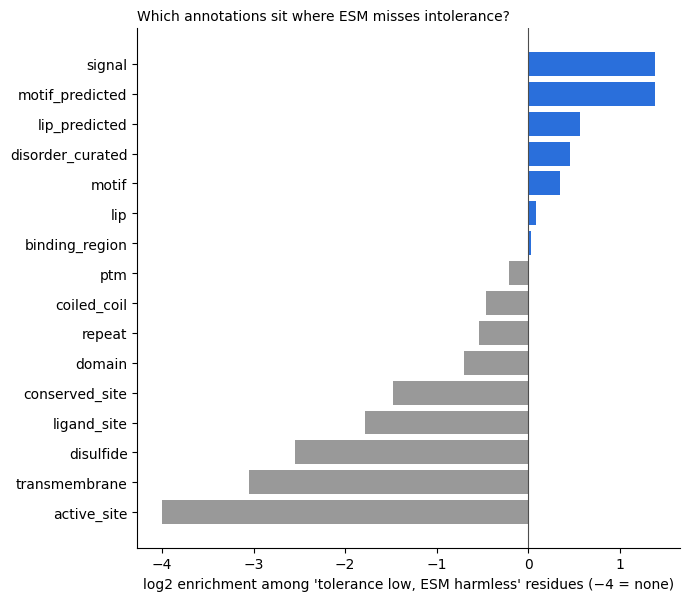

held-out ClinVar in annotated genes: 2477 (26% pathogenic)


,n inside,genes,% pathogenic inside,"% pathogenic outside, same genes",MH odds ratio
domain,1429.0,337.0,0.39,0.08,6.85
repeat,366.0,70.0,0.21,0.17,1.97
motif,13.0,7.0,0.69,0.54,2.57
binding_region,199.0,64.0,0.35,0.22,1.48
lip,103.0,51.0,0.54,0.29,2.16
lip_predicted,503.0,182.0,0.09,0.28,0.34
ptm,23.0,21.0,0.26,0.40,0.53
ligand_site,99.0,50.0,0.86,0.43,19.22
conserved_site,78.0,37.0,0.60,0.45,3.61
coiled_coil,41.0,20.0,0.00,0.06,0.00


In [55]:
# where do annotations sit relative to tolerance and ESM?
r = residue_df[residue_df.tolerance_ok & residue_df.gene.isin(A_INFO)].copy()
r["region"] = np.where(r.disorder >= 0.5, "disordered", "ordered")

# 1. median tolerance / ESM inside each category (vs all residues), split by order/disorder
rows = []
for c in CATEGORIES:
    for region, sub in r.groupby("region"):
        inside = sub[sub[f"ann_{c}"].fillna(False)]
        if len(inside) >= 20:
            rows.append({"category": c, "region": region, "n": len(inside),
                         "tolerance": inside.tolerance_v4_centered.median() - sub.tolerance_v4_centered.median(),
                         "esm_mean_llr": inside.esm_mean_llr.median() - sub.esm_mean_llr.median()})
inside_vs_all = pd.DataFrame(rows).set_index(["category", "region"]).unstack("region")
print("median inside category minus median of all residues (negative = less tolerant / more constrained):")
print(inside_vs_all.round(3).to_string())

# 2. enrichment among residues where tolerance is low but ESM says harmless (the §6 disagreement)
pct = lambda col: r.groupby("gene")[col].rank(pct=True)                # within-gene percentiles
disagree = (pct("tolerance_v4_centered") < 0.2) & (pct("esm_mean_llr") > 0.8)
enrich = pd.Series({c: r.loc[disagree, f"ann_{c}"].fillna(False).mean()
                    / max(r[f"ann_{c}"].fillna(False).mean(), 1e-9) for c in CATEGORIES})
enrich = enrich[r[[f"ann_{c}" for c in CATEGORIES]].sum().values >= 50]   # categories with enough residues
print(f"\n{disagree.sum():,} 'tolerance low, ESM harmless' residues ({disagree.mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 0.32 * len(enrich) + 1))
e = np.log2(enrich.clip(lower=1 / 16).sort_values())                 # 0 (none at all) shown as -4
ax.barh(e.index, e.values, color=np.where(e.values > 0, "#2a6fdb", "0.6"))
ax.axvline(0, color="0.3", lw=0.8)
ax.set_xlabel("log2 enrichment among 'tolerance low, ESM harmless' residues (−4 = none)")
ax.set_title("Which annotations sit where ESM misses intolerance?", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

# 3. held-out ClinVar (pb from §6g): pathogenic share inside vs outside each category, WITHIN THE SAME GENES.
# Pathogenic share varies hugely between genes (DMD ~5%, GRIN2B ~50%, PTEN 100%), so comparing a category
# against all other variants mostly measures which genes the category sits in. Two gene-matched views:
#   - outside, same genes: variants outside the category but in genes that have >= 1 variant inside it
#   - Mantel-Haenszel odds ratio: pathogenic-vs-benign odds inside / outside, pooled over per-gene 2x2 tables
#     (> 1 = category enriched for pathogenic within genes; inf = no benign variant inside in any gene)
pba = pb[pb.gene.isin(A_INFO)].merge(residue_df[["gene", "pos"] + [f"ann_{c}" for c in CATEGORIES]],
                                     left_on=["gene", "position"], right_on=["gene", "pos"], how="inner")
pba["path"] = pba.clinsig_group == "pathogenic"

def mh_odds_ratio(df, inside):
    num = den = 0.0
    for _, t in df.assign(inside=inside).groupby("gene"):
        n = len(t)
        num += (t.inside & t.path).sum() * (~t.inside & ~t.path).sum() / n
        den += (t.inside & ~t.path).sum() * (~t.inside & t.path).sum() / n
    return num / den if den else np.inf

rows = {}
for c in CATEGORIES:
    inside = pba[f"ann_{c}"].fillna(False)
    same = pba.gene.isin(pba.loc[inside, "gene"])                          # genes with a variant inside
    rows[c] = {"n inside": int(inside.sum()), "genes": pba.loc[inside, "gene"].nunique(),
               "% pathogenic inside": pba.path[inside].mean(),
               "% pathogenic outside, same genes": pba.path[~inside & same].mean(),
               "MH odds ratio": mh_odds_ratio(pba[same], inside[same])}
path = pd.DataFrame(rows).T
print(f"held-out ClinVar in annotated genes: {len(pba)} ({pba.path.mean():.0%} pathogenic)")
path[path["n inside"] >= 10].round(2)

---
## 9. Structure viewer: colour by any score or annotation

**Goal:** `show_structure(gene, metric)` draws a protein in 3D, coloured by any column of `residue_df`:
- tolerance and ESM scores
- RSA and pLDDT
- interface flags (§7)
- annotation tracks (§8)

It uses the structures §7 already cached, either the AlphaFold model or a PDB chain (optionally with its partner chains), and checks the residue numbering every time.

**Numbering:** scores are stored by MANE position, but 3Dmol colours by the structure file's own residue numbers (the author numbering, `auth_seq_id`, for both PDB and mmCIF files). Each view therefore aligns the structure's sequence to MANE (`align_to_mane` from §7), translates positions, and reports how many residues match.

py3Dmol outputs are large: clear them before committing (`jupyter nbconvert --clear-output --inplace 05_tolerance_score_modelling.ipynb`).

### 9a. Load a cached structure and map MANE → structure numbering

`load_structure(gene, source)`:
- `source="alphafold"`: the AlphaFold model §7 chose for this gene (full length, consistent across genes; the default)
- `source="pdb"`: the best-ranked PDB chain from §7a
- `source="pdb:8gs3_A"`: a specific chain
- `partners=True` (PDB only): load the whole entry, so the other chains can be drawn as context

It returns the structure text plus `mane_to_resi`, a `{MANE position: residue number in the file}` dictionary, and checks that the residue letters agree.

In [56]:
# load a cached structure and map MANE positions to the structure's own residue numbers
import py3Dmol

SEQ = dict(zip(psd_seq_df.gene, psd_seq_df.sequence))
ACC = dict(zip(psd_seq_df.gene, psd_seq_df.uniprot_id))

def alphafold_entry(gene):
    '''AlphaFold model §7 used for this gene (from its cached table), else the best match to MANE.'''
    path = os.path.join(STRUCT_CACHE, "genes", f"{gene}.parquet")
    if os.path.exists(path):
        used = pd.read_parquet(path, columns=["af_model"]).af_model.dropna()
        if len(used):
            entry = used.iloc[0]
            meta = get_cached(f"https://alphafold.ebi.ac.uk/api/prediction/{ACC[gene]}",
                              os.path.join(STRUCT_CACHE, "api", f"af_{ACC[gene]}.json"))
            return next(e for e in meta if e["entryId"] == entry)
    meta = get_cached(f"https://alphafold.ebi.ac.uk/api/prediction/{ACC[gene]}",
                      os.path.join(STRUCT_CACHE, "api", f"af_{ACC[gene]}.json"))
    if not meta:
        raise ValueError(f"no AlphaFold model for {gene} ({ACC[gene]})")
    exact = [e for e in meta if e["sequence"] == SEQ[gene]]        # same choice as §7c
    return exact[0] if exact else max(meta, key=lambda e: len(align_to_mane(e["sequence"], SEQ[gene])[0]))

def load_structure(gene, source="alphafold", partners=False):
    '''-> dict(text, fmt, chain, mane_to_resi, label, identity). Files come from the §7 cache.'''
    if source == "alphafold":
        e = alphafold_entry(gene)
        text = get_cached(e["pdbUrl"], os.path.join(STRUCT_CACHE, "af", f"{e['entryId']}.pdb"), as_json=False)
        fmt, chain, label = "pdb", "A", e["entryId"]
    else:
        if source == "pdb":                                          # best-ranked chain from §7a
            chains = choose_pdb_chains(ACC[gene])
            if not chains:
                raise ValueError(f"{gene}: no human PDB chain")
            pdb, chain = chains[0]["pdb_id"], chains[0]["chain_id"]
        else:                                                        # "pdb:8gs3_A"
            pdb, chain = source.split(":")[1].rsplit("_", 1)
        if partners:                                                 # whole entry, all chains
            text = get_cached(f"https://files.rcsb.org/download/{pdb.upper()}.cif",
                              os.path.join(STRUCT_CACHE, "pdb", f"{pdb}_full.cif"), as_json=False)
        else:                                                        # this chain only (as in §7c)
            text = get_cached(f"https://www.ebi.ac.uk/pdbe/model-server/v1/{pdb}/atoms?auth_asym_id={chain}&encoding=cif",
                              os.path.join(STRUCT_CACHE, "pdb", f"{pdb}_{chain}.cif"), as_json=False)
        fmt, label = "cif", f"{pdb}_{chain}"
    parser = MMCIFParser(QUIET=True) if fmt == "cif" else PDBParser(QUIET=True)
    model = parser.get_structure("s", io.StringIO(text))[0]           # auth numbering, like 3Dmol
    residues = _chain_residues(model[chain])                         # [(resnum, aa, residue), ...]
    seq = "".join(aa for _, aa, _ in residues)
    idx_to_mane, _ = align_to_mane(seq, SEQ[gene])
    mane_to_resi = {p: residues[i][0] for i, p in idx_to_mane.items()}
    same = sum(residues[i][1] == SEQ[gene][p - 1] for i, p in idx_to_mane.items())
    return {"text": text, "fmt": fmt, "chain": chain, "label": label, "mane_to_resi": mane_to_resi,
            "identity": same / max(len(idx_to_mane), 1)}

_g = "NLGN3" if "NLGN3" in SEQ else next(iter(SEQ))                  # quick test gene
_s = load_structure(_g)
print(f"{_s['label']}: {len(_s['mane_to_resi'])} MANE positions mapped, residue identity {_s['identity']:.1%}")

AF-Q9NZ94-F1: 848 MANE positions mapped, residue identity 100.0%


### 9b. Colour scheme per metric

One rule throughout: **red = intolerant / constrained / flagged**. Continuous scores use limits from the gene's own 2nd–98th percentiles, so a few outliers don't wash out the colours. Residues with no value (masked RSA, no observed variant, outside the structure) are light grey. Edit `METRIC_STYLE` to change any of it.

| metric | colormap | centre |
|---|---|---|
| `tolerance_v4`, `tolerance_v4_centered` | `seismic_r`: red < 0 < blue | 0 |
| ESM LLRs (`esm_mean_llr`, `esm_obs_*`, `esm_llr`-style) | `Reds_r`: darkest red = most deleterious | — |
| `esm_entropy` | `Reds_r`: low entropy = constrained = red | — |
| `rsa`, `rsa_pdb`, `rsa_af` | `viridis`: dark = buried, yellow = exposed, fixed 0–1 | — |
| `plddt` | `RdYlBu`: red = low confidence, fixed 50–100 | — |
| `msa_conservation` | `Reds`: conserved = red | — |
| `disorder` | `Greens`, fixed 0–1 | — |
| any `True/False` column (`iface_*`, `ann_*`) | red = True, pale grey = False | — |

In [57]:
# colour scheme per metric (red = intolerant / constrained / flagged)
import matplotlib.colors as mcolors
from af_viewer import score_colors

NAN_COLOR, FLAG_ON, FLAG_OFF = "#d9d9d9", "#d62728", "#eeeeee"
METRIC_STYLE = {   # column -> cmap, centre (None = plain stretch), fixed limits (None = gene's 2nd-98th pct), label
    "tolerance_v4":          dict(cmap="seismic_r", center=0.0, limits=None, label="tolerance (red = intolerant)"),
    "tolerance_v4_centered": dict(cmap="seismic_r", center=0.0, limits=None, label="tolerance, gene-centred"),
    "esm_mean_llr":          dict(cmap="Reds_r", center=None, limits=None, label="ESM mean LLR (red = deleterious)"),
    "esm_obs_min_llr":       dict(cmap="Reds_r", center=None, limits=None, label="ESM worst observed LLR"),
    "esm_obs_mean_llr":      dict(cmap="Reds_r", center=None, limits=None, label="ESM mean observed LLR"),
    "esm_entropy":           dict(cmap="Reds_r", center=None, limits=None, label="ESM entropy (red = constrained)"),
    "rsa":                   dict(cmap="viridis", center=None, limits=(0, 1), label="RSA (dark = buried)"),
    "rsa_pdb":               dict(cmap="viridis", center=None, limits=(0, 1), label="RSA, PDB"),
    "rsa_af":                dict(cmap="viridis", center=None, limits=(0, 1), label="RSA, AlphaFold"),
    "plddt":                 dict(cmap="RdYlBu", center=None, limits=(50, 100), label="AlphaFold pLDDT"),
    "msa_conservation":      dict(cmap="Reds", center=None, limits=None, label="MSA conservation"),
    "disorder":              dict(cmap="Greens", center=None, limits=(0, 1), label="AIUPred disorder"),
}

def metric_values(gene, metric):
    '''{MANE position: value} for one gene from residue_df.'''
    g = residue_df.loc[residue_df.gene == gene, ["pos", metric]]
    return dict(zip(g.pos, g[metric]))

def metric_colors(gene, metric):
    '''-> ({MANE position: '#rrggbb'}, style used). Boolean columns become red / pale grey.'''
    vals = metric_values(gene, metric)
    pos = sorted(vals)
    v = pd.Series([vals[p] for p in pos], index=pos)
    if pd.api.types.is_bool_dtype(residue_df[metric]):               # flag column (iface_*, ann_*)
        cols = {p: NAN_COLOR if pd.isna(x) else FLAG_ON if x else FLAG_OFF for p, x in v.items()}
        return cols, {"kind": "flag", "label": f"{metric} (red = yes)"}
    style = METRIC_STYLE.get(metric, dict(cmap="viridis", center=None, limits=None, label=metric))
    x = v.astype(float).to_numpy()
    if np.isnan(x).all():                                             # e.g. rsa_pdb for a gene without PDB
        return {p: NAN_COLOR for p in pos}, {"kind": "continuous", **style, "vmin": 0.0, "vmax": 1.0}
    lo, hi = style["limits"] or (np.nanpercentile(x, 2), np.nanpercentile(x, 98))
    cols = score_colors(x, start=1, cmap=style["cmap"], center=style["center"], vmin=lo, vmax=hi,
                        nan_color=NAN_COLOR)                          # keyed 1..L in position order
    return dict(zip(pos, cols.values())), {"kind": "continuous", **style, "vmin": lo, "vmax": hi}

def metric_colorbar(style, ax):
    '''Colour bar (continuous) or a two-swatch legend (flags) on an existing axis.'''
    if style["kind"] == "flag":
        ax.barh([0, 1], [1, 1], color=[FLAG_OFF, FLAG_ON]); ax.set_yticks([0, 1], ["no", "yes"])
        ax.set_xticks([]); ax.set_title(style["label"], fontsize=9, loc="left")
        for s in ax.spines.values(): s.set_visible(False)
        return
    lo, hi, c = style["vmin"], style["vmax"], style["center"]
    norm = (mcolors.TwoSlopeNorm(vcenter=c, vmin=lo, vmax=hi) if c is not None and lo < c < hi
            else mcolors.Normalize(vmin=lo, vmax=hi))
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=style["cmap"]), cax=ax, orientation="horizontal")
    ax.set_title(style["label"], fontsize=9, loc="left")

_c, _st = metric_colors(_g, "tolerance_v4")
print(f"{len(_c)} residues coloured, {sum(v == NAN_COLOR for v in _c.values())} without a value")

848 residues coloured, 0 without a value


### 9c. `show_structure`

`show_structure(gene, metric, source="alphafold", partners=False, highlight=None, show_colorbar=True)`:
- colours the gene's chain by `metric`; residues outside the structure simply aren't drawn
- `partners=True` (with a PDB source): other chains as translucent grey cartoon, ligands and waters hidden
- `highlight`: MANE positions to show as sticks with labels, e.g. held-out pathogenic variants: `highlight=pb[pb.gene == "GRIN1"].position.tolist()`
- prints what was drawn: source, residues mapped, residue identity, residues without a value

NLGN3 | tolerance_v4 | AF-Q9NZ94-F1 | 848 of 848 residues in structure | identity 100.0% | 0 without a value


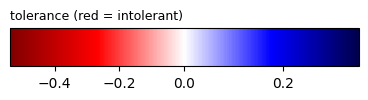

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [58]:
# show_structure: one protein, one metric
def show_structure(gene, metric="tolerance_v4", source="alphafold", partners=False, highlight=None,
                   show_colorbar=True, width=800, height=550, style="cartoon"):
    s = load_structure(gene, source, partners=partners and source != "alphafold")
    colors_by_pos, st = metric_colors(gene, metric)
    resi_colors = {s["mane_to_resi"][p]: c for p, c in colors_by_pos.items() if p in s["mane_to_resi"]}

    v = py3Dmol.view(width=width, height=height)
    v.addModel(s["text"], s["fmt"])
    v.setStyle({}, {})                                                # hide everything, then add back
    if partners and source != "alphafold":                            # context: other protein chains
        v.setStyle({"not": {"chain": s["chain"]}, "hetflag": False},
                   {"cartoon": {"color": "#bbbbbb", "opacity": 0.45}})
    v.setStyle({"chain": s["chain"], "hetflag": False},
               {style: {"colorscheme": {"prop": "resi", "map": resi_colors}}})
    for p in ([] if highlight is None else list(highlight)):          # e.g. variant positions
        r = s["mane_to_resi"].get(int(p))
        if r is None:
            continue
        v.addStyle({"chain": s["chain"], "resi": r}, {"stick": {"colorscheme": "default", "radius": 0.25}})
        v.addLabel(f"{SEQ[gene][int(p) - 1]}{int(p)}", {"fontSize": 10, "backgroundOpacity": 0.6},
                   {"chain": s["chain"], "resi": r, "atom": "CA"})
    v.zoomTo({"chain": s["chain"]})

    n_nan = sum(c == NAN_COLOR for c in resi_colors.values())
    print(f"{gene} | {metric} | {s['label']}{' + partners' if partners else ''} | "
          f"{len(resi_colors)} of {len(SEQ[gene])} residues in structure | identity {s['identity']:.1%} | "
          f"{n_nan} without a value")
    if show_colorbar:
        fig, ax = plt.subplots(figsize=(4.5, 0.5 if st["kind"] == "continuous" else 0.7))
        metric_colorbar(st, ax); plt.show()
    return v

show_structure("NLGN3", "tolerance_v4").show()

### 9d. Side by side: several metrics on the same protein

`compare_structures(gene, metrics)` puts one linked panel per metric in a grid: rotating one rotates all. A row of colour bars below gives the key, left to right. This is the quickest way to see whether tolerance, ESM and structure agree on a region.

NLGN3 | AF-Q9NZ94-F1 | panels, left to right: tolerance_v4, esm_mean_llr, rsa


/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/956760638.py:20: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(); plt.show()


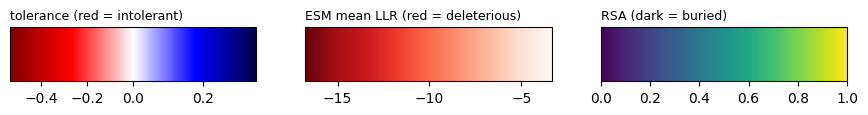

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [59]:
# several metrics, linked panels
def compare_structures(gene, metrics=("tolerance_v4", "esm_mean_llr", "rsa"), source="alphafold",
                       panel_width=380, height=420):
    s = load_structure(gene, source)
    n = len(metrics)
    v = py3Dmol.view(viewergrid=(1, n), width=panel_width * n, height=height, linked=True)
    styles = []
    for k, metric in enumerate(metrics):
        colors_by_pos, st = metric_colors(gene, metric)
        resi_colors = {s["mane_to_resi"][p]: c for p, c in colors_by_pos.items() if p in s["mane_to_resi"]}
        v.addModel(s["text"], s["fmt"], viewer=(0, k))
        v.setStyle({"hetflag": False}, {"cartoon": {"colorscheme": {"prop": "resi", "map": resi_colors}}},
                   viewer=(0, k))
        styles.append(st)
    v.zoomTo()
    print(f"{gene} | {s['label']} | panels, left to right: {', '.join(metrics)}")
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 0.7))
    for ax, st in zip(np.atleast_1d(axes), styles):
        metric_colorbar(st, ax)
    fig.tight_layout(); plt.show()
    return v

compare_structures("NLGN3", ["tolerance_v4", "esm_mean_llr", "rsa"]).show()

### 9e. Examples

Uncomment one line at a time; each draws a separate viewer.
- **interfaces in context:** a PDB complex with partner chains, coloured by `iface_any`
- **pathogenic variants on the tolerance map:** held-out ClinVar pathogenic positions (from §6g) as sticks
- **a flagged chain** (§7, `structure_flags.csv`): PDB vs. AlphaFold RSA side by side
- **annotations:** where §8's curated motifs or LIPs sit relative to tolerance

In [60]:
# examples -- run one at a time (each draws a viewer)
# show_structure("NLGN3", "iface_any", source="pdb", partners=True).show()
# show_structure("GRIN1", "tolerance_v4",
#                highlight=pb.loc[(pb.gene == "GRIN1") & (pb.clinsig_group == "pathogenic"), "position"]).show()
# compare_structures("SNAP23", ["rsa_pdb", "rsa_af", "plddt"], source="pdb:1nhl_A").show()   # flagged chain
# compare_structures("CTNNB1", ["tolerance_v4", "esm_mean_llr", "ann_lip"]).show()
# compare_structures("GRIN2B", ["tolerance_v4_centered", "esm_obs_min_llr", "iface_any"]).show()

---
## 10. Gene-level train / validation / test split

**Goal:** an honest held-out test. The model must never have seen the test proteins, *or their close relatives*.

**Why not split by residue or variant?** Neighbouring residues share smoothed targets (window ±31), and paralogs share sequence *and* tolerance profile. A random residue split would test memorisation, not generalisation. (§6g's variant hold-out answered a different question: does the tolerance score generalise to unseen variants?)

**Plan:**
1. **10a:** find related gene pairs by sequence identity.
2. **10b:** join them, plus PANTHER families, into clusters.
3. **10c:** assign *whole clusters* to train / val / test (80/10/10 by residues, balanced for disorder).
4. **10d:** check for leakage and balance.
5. **10e:** save `split_manifest.json` and the `split` column.

**One leak this can't remove:** the ESM backbone was pre-trained on UniRef, which includes every one of these proteins. The test set is new to the *tolerance head*, not to ESM. That's normal for fine-tuning, and it's why the baselines in §16 matter.

### 10a. Related gene pairs by sequence identity

There's no MMseqs2 here, so this uses a two-step search in Python:
1. **Shortlist:** represent each protein by its counts of 3-residue fragments, and keep each gene's 10 most similar proteins (cosine similarity, < 1 s for all genes). In testing, every known paralog pair (NLGN1/3, GRIN2A/B, CAMK2A/B, DLG1/4, SHANK1/3, GRIA1/2) ranked in its partner's top 3.
2. **Align** each shortlisted pair (local, BLOSUM62) and record identity, aligned length, and coverage of **both** proteins.

About 10,000 alignments, **~7 min once**, then cached in `homology_pairs.parquet` (recomputed only if the gene set changes).

Coverage of both proteins matters: measuring it against only the shorter protein let tiny proteins (a 25-residue ribosomal protein) and low-complexity stretches inside giant proteins "match", which chained 98 unrelated genes into one cluster.

In [61]:
# related gene pairs: 3-mer shortlist, then local alignment of each shortlisted pair (cached)
from scipy import sparse

SHORTLIST_K = 10                                         # neighbours per gene to align
PAIRS_FILE = os.path.join(OUT, "homology_pairs.parquet")
PAIRS_GENES = os.path.join(OUT, "homology_pairs_genes.json")   # which genes the cached pairs cover

split_genes = psd_seq_df.gene.tolist()
split_seqs = dict(zip(psd_seq_df.gene, psd_seq_df.sequence))

def kmer_matrix(seqs, k=3):
    '''Rows = proteins, columns = 20^k fragment counts, L2-normalised (so X @ X.T = cosine).'''
    idx = {a: i for i, a in enumerate("ACDEFGHIKLMNPQRSTVWY")}
    rows, cols, vals = [], [], []
    for r, s in enumerate(seqs):
        counts = {}
        for i in range(len(s) - k + 1):
            code = 0
            for a in s[i:i + k]:
                if a not in idx:
                    break
                code = code * 20 + idx[a]
            else:
                counts[code] = counts.get(code, 0) + 1
        rows += [r] * len(counts); cols += list(counts); vals += list(counts.values())
    X = sparse.csr_matrix((vals, (rows, cols)), shape=(len(seqs), 20 ** k), dtype=float)
    return sparse.diags(1 / np.sqrt(X.multiply(X).sum(axis=1).A1)) @ X

def pair_identity(a, b):
    '''Local alignment -> (identity of aligned residues, aligned residues).'''
    aln = _aligner.align(a, b)[0]                         # same aligner as §7 (BLOSUM62, local)
    same = n = 0
    for (a0, a1), (b0, b1) in zip(*aln.aligned):
        n += a1 - a0
        same += sum(x == y for x, y in zip(a[a0:a1], b[b0:b1]))
    return same / max(n, 1), n

if os.path.exists(PAIRS_FILE) and os.path.exists(PAIRS_GENES) and set(json.load(open(PAIRS_GENES))) == set(split_genes):
    pairs = pd.read_parquet(PAIRS_FILE)                  # same genes as last time -> reuse
else:
    X = kmer_matrix([split_seqs[g] for g in split_genes])
    S = (X @ X.T).toarray(); np.fill_diagonal(S, 0)
    cand = sorted({tuple(sorted((i, int(j)))) for i in range(len(split_genes)) for j in np.argsort(-S[i])[:SHORTLIST_K]})
    t0, rows = time.time(), []
    for n, (i, j) in enumerate(cand, 1):
        a, b = split_genes[i], split_genes[j]
        ident, aligned = pair_identity(split_seqs[a], split_seqs[b])
        rows.append({"a": a, "b": b, "kmer_cos": S[i, j], "identity": ident, "aligned": aligned,
                     "cov_a": aligned / len(split_seqs[a]), "cov_b": aligned / len(split_seqs[b])})
        if n % 2000 == 0:
            print(f"{n}/{len(cand)} pairs aligned ({time.time() - t0:.0f} s)")
    pairs = pd.DataFrame(rows)
    pairs.to_parquet(PAIRS_FILE, index=False)
    json.dump(split_genes, open(PAIRS_GENES, "w"))
print(f"{len(pairs):,} gene pairs aligned")

10,081 gene pairs aligned


### 10b. Clusters: sequence links + PANTHER families

Two genes are **linked** if their alignment has ≥ `MIN_IDENTITY` identity over ≥ `MIN_ALIGNED` residues, covering ≥ `MIN_COVERAGE` of **both** proteins. PANTHER families (from the InterPro cache, §8) add links between distant relatives that fall below the identity cut-off. Clusters are the connected groups ("union–find"): if A–B and B–C are linked, A, B and C share a cluster.

The settings were chosen on all 1,082 genes:

| setting | clusters | largest |
|---|---|---|
| 30% identity, coverage of the shorter protein only | 41 | 1,039 genes (everything chained together) |
| 40% identity, coverage of both ≥ 50%, sequence only | 762 | 17 genes (GABA-A receptors) |
| **40%, both ≥ 50%, + PANTHER** (default) | **636** | **30 genes (Cys-loop receptors: CHRN + GABR), 2.3% of residues** |

In [62]:
# clusters = connected groups of linked genes (sequence identity + PANTHER family)
MIN_IDENTITY, MIN_COVERAGE, MIN_ALIGNED = 0.40, 0.50, 50
USE_PANTHER = True

links = pairs[(pairs.identity >= MIN_IDENTITY) & (pairs.aligned >= MIN_ALIGNED)
              & (pairs.cov_a >= MIN_COVERAGE) & (pairs.cov_b >= MIN_COVERAGE)]

parent = {g: g for g in split_genes}                    # union-find
def root(g):
    while parent[g] != g:
        parent[g] = parent[parent[g]]; g = parent[g]
    return g
def join(a, b):
    parent[root(a)] = root(b)

for a, b in zip(links.a, links.b):
    join(a, b)
panther_of = {}
if USE_PANTHER:                                          # PANTHER family from the (cached) InterPro features
    for g, acc in zip(psd_seq_df.gene, psd_seq_df.uniprot_id):
        panther_of[g] = next((f["accession"] for f in fetch_interpro(acc) if f["source"] == "panther"), None)
    fam = pd.Series(panther_of).dropna()
    for _, members in fam.groupby(fam):
        for g in members.index[1:]:
            join(g, members.index[0])

cluster_of = {g: root(g) for g in split_genes}
gene_len = {g: len(s) for g, s in split_seqs.items()}
clusters = (pd.DataFrame({"gene": split_genes, "cluster": [cluster_of[g] for g in split_genes]})
            .assign(residues=lambda d: d.gene.map(gene_len)))
sizes = clusters.groupby("cluster").agg(genes=("gene", "size"), residues=("residues", "sum"),
                                        members=("gene", lambda g: ", ".join(sorted(g)[:8])))
print(f"{len(links)} sequence links | {len(sizes)} clusters | {(sizes.genes == 1).sum()} singletons | "
      f"largest {sizes.genes.max()} genes ({sizes.residues.max() / sizes.residues.sum():.1%} of residues)")
sizes.sort_values("genes", ascending=False).head(10)

506 sequence links | 636 clusters | 436 singletons | largest 30 genes (2.3% of residues)


,genes,residues,members
cluster,,,
CHRNE,30,14592,"CHRNA1, CHRNA10, CHRNA3, CHRNA4, CHRNA6, CHRNA..."
GRIK4,17,17977,"GRIA1, GRIA2, GRIA3, GRIA4, GRID1, GRID2, GRIK..."
LRFN5,16,10714,"ELFN1, ELFN2, FLRT2, FLRT3, LRFN1, LRFN2, LRFN..."
ADRB2,12,5215,"ADRA1A, ADRA2A, ADRA2C, ADRB2, DRD1, DRD2, DRD..."
KCND3,10,6333,"KCNA1, KCNA2, KCNA3, KCNA4, KCNB1, KCNC1, KCNC..."
PSMB1,10,2458,"PSMB1, PSMB10, PSMB2, PSMB3, PSMB4, PSMB5, PSM..."
PSMA1,8,1998,"PSMA1, PSMA2, PSMA3, PSMA4, PSMA5, PSMA6, PSMA..."
CAMK1,8,4360,"CAMK1, CAMK2A, CAMK2B, CAMK2D, CAMK2G, CAMK4, ..."
PSD,8,7395,"ARFGEF2, CYTH2, IQSEC1, IQSEC2, IQSEC3, PSD, P..."


### 10c. Assign whole clusters to train / val / test

- **Targets by residues**, not genes (`SPLIT_FRACTIONS`, default 80/10/10), because a few giant proteins would otherwise dominate.
- **Balanced for disorder:** clusters are put into three strata by disorder fraction, and each stratum is split 80/10/10 separately, so the test set isn't all short ordered proteins.
- **Within a stratum:** clusters go in random order (`SEED`) to whichever split is furthest below its target.
- **`FORCE_TEST`:** genes you want as untouched showcases; their whole cluster goes to test. Decide this *now*, before any tuning.
- **Large clusters go to train:** a cluster bigger than `MAX_EVAL_CLUSTER` (15%) of the val/test target always goes to train, so one family can't dominate an evaluation set. At 25%, the 17-gene ionotropic glutamate receptor cluster landed in val as ~20% of its residues.
- **`tolerance_ok == False` genes** (no ClinVar or no variants, §3) are marked `excluded`: their target is incomplete.

In [63]:
# assign whole clusters to train / val / test
SPLIT_FRACTIONS  = {"train": 0.80, "val": 0.10, "test": 0.10}
FORCE_TEST       = []          # e.g. ["NLGN3"] -> the whole NLGN cluster becomes a test showcase
MAX_EVAL_CLUSTER = 0.15        # clusters larger than this share of the val/test target go to train
N_STRATA         = 3           # disorder-fraction strata

ok = dict(zip(psd_seq_df.gene, psd_seq_df.tolerance_ok))
disorder_frac = {g: float(np.mean(np.asarray(d) >= 0.5)) for g, d in zip(psd_seq_df.gene, psd_seq_df.disorder_scores)}
use = clusters[clusters.gene.map(ok)]                  # genes with a complete target
cl = use.groupby("cluster").agg(residues=("residues", "sum"), genes=("gene", list))
cl["disorder"] = [np.average([disorder_frac[g] for g in gs], weights=[gene_len[g] for g in gs]) for gs in cl.genes]
cl["stratum"] = pd.qcut(cl.disorder.rank(method="first"), N_STRATA, labels=False)

forced = {cluster_of[g] for g in FORCE_TEST if g in cluster_of}
total = cl.residues.sum()
assignment = {c: "test" for c in forced if c in cl.index}
for c in cl.index[cl.residues > MAX_EVAL_CLUSTER * total * min(SPLIT_FRACTIONS["val"], SPLIT_FRACTIONS["test"])]:
    assignment.setdefault(c, "train")                  # too big for an evaluation set

rng_split = np.random.default_rng(SEED)
for s, stratum in cl.groupby("stratum"):
    target = {k: f * stratum.residues.sum() for k, f in SPLIT_FRACTIONS.items()}
    filled = {k: stratum.residues[[c for c in stratum.index if assignment.get(c) == k]].sum() for k in target}
    for c in rng_split.permutation(stratum.index):      # random order within the stratum
        if c in assignment:
            continue
        k = max(target, key=lambda name: (target[name] - filled[name]) / target[name])   # most under-filled
        assignment[c] = k
        filled[k] += stratum.residues[c]

split_of = {g: assignment[cluster_of[g]] if ok[g] else "excluded" for g in split_genes}
psd_seq_df["cluster"] = psd_seq_df.gene.map(cluster_of)
psd_seq_df["split"] = psd_seq_df.gene.map(split_of)
residue_df["split"] = residue_df.gene.map(split_of).astype("string")
print(psd_seq_df.split.value_counts().to_dict())

{'train': 856, 'test': 107, 'val': 107, 'excluded': 12}


### 10d. Checks: leakage and balance

1. **No cluster in two splits** (asserted).
2. **Closest cross-split relatives:** among alignments of ≥ `MIN_ALIGNED` residues, the highest-identity pairs that ended up in different splits. They should all fail the identity or coverage rule.
3. **Balance per split:** genes, residues, length, disorder fraction, tolerance, and how many labelled ClinVar variants each split has for evaluation.
4. **Showcase genes:** which split each lands in.

1. every cluster sits in exactly one split
2. closest cross-split pairs:
      a    sa        b    sb  identity  aligned  cov_a  cov_b
HNRNPA3  test      ALK train      0.53       83   0.22   0.05
 ADRA2C  test   GRIN2D train      0.53       55   0.12   0.04
   PURA train  HNRNPA3  test      0.52       50   0.16   0.13
   TRIO train  HNRNPH2  test      0.52       54   0.02   0.12
  GIPC1   val ARHGAP33 train      0.52       60   0.18   0.05
3. balance per split:
          genes  clusters  residues  median_length  disorder  mean_tolerance  % residues  benign  pathogenic
split                                                                                                       
excluded     12        12      4237          130.0     0.582           0.250         0.5     NaN         NaN
test        107        64     78366          467.0     0.409           0.165        10.1   815.0       675.0
train       856       501    618838          572.0     0.346           0.154        79.7  9492.0 

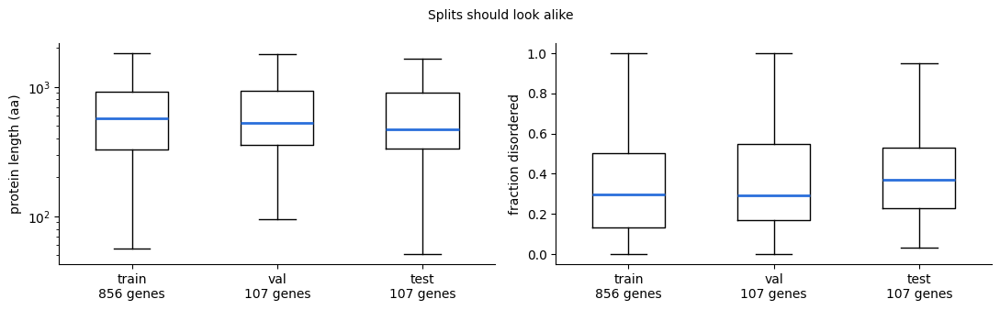

4. NLGN1: train | cluster of 5: NLGN1, NLGN2, NLGN3, NLGN4X, NLGN4Y
4. NLGN3: train | cluster of 5: NLGN1, NLGN2, NLGN3, NLGN4X, NLGN4Y
4. SHANK3: train | cluster of 3: SHANK1, SHANK2, SHANK3
4. GRIN2B: train | cluster of 17: GRIA1, GRIA2, GRIA3, GRIA4, GRID1, GRID2, GRIK2, GRIK3 …
4. DLG4: train | cluster of 7: DLG1, DLG2, DLG3, DLG4, ERBIN, LRRC7, SCRIB


In [64]:
# checks: leakage and balance
# 1. no cluster spans two splits
spans = psd_seq_df[psd_seq_df.split != "excluded"].groupby("cluster").split.nunique()
assert (spans == 1).all(), f"clusters in two splits: {spans[spans > 1].index.tolist()}"
print("1. every cluster sits in exactly one split")

# 2. closest relatives across splits (should be below the link rules)
cross = pairs.assign(sa=pairs.a.map(split_of), sb=pairs.b.map(split_of))
cross = cross[(cross.sa != cross.sb) & ~cross.sa.eq("excluded") & ~cross.sb.eq("excluded")
              & (cross.aligned >= MIN_ALIGNED)]                    # ignore tiny local matches
print("2. closest cross-split pairs:")
print(cross.sort_values("identity", ascending=False)
      .head(5)[["a", "sa", "b", "sb", "identity", "aligned", "cov_a", "cov_b"]].round(2).to_string(index=False))

# 3. balance per split
labelled = variant_df[(variant_df.database == "ClinVar") & variant_df.clinsig_group.isin(["pathogenic", "benign"])]
per = psd_seq_df.assign(length=psd_seq_df.sequence.str.len(), disorder=psd_seq_df.gene.map(disorder_frac),
                        tol=[np.mean(t) for t in psd_seq_df.tolerance_v4])
balance = per.groupby("split").agg(genes=("gene", "size"), clusters=("cluster", "nunique"),
                                   residues=("length", "sum"), median_length=("length", "median"),
                                   disorder=("disorder", "mean"), mean_tolerance=("tol", "mean"))
balance["% residues"] = (100 * balance.residues / balance.residues[balance.index != "excluded"].sum()).round(1)
lab = labelled.assign(split=labelled.gene.map(split_of)).groupby(["split", "clinsig_group"]).size().unstack(fill_value=0)
balance = balance.join(lab)
print("3. balance per split:"); print(balance.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
order = [s for s in ["train", "val", "test"] if s in balance.index]
for ax, (col, label, log) in zip(axes, [("length", "protein length (aa)", True), ("disorder", "fraction disordered", False)]):
    ax.boxplot([per.loc[per.split == s, col] for s in order], showfliers=False, widths=0.5,
               medianprops=dict(color="#2a6fdb", lw=2))
    ax.set_xticks(range(1, len(order) + 1), [f"{s}\n{(per.split == s).sum()} genes" for s in order])
    ax.set_ylabel(label); ax.set_yscale("log" if log else "linear")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Splits should look alike", fontsize=10); fig.tight_layout(); plt.show()

# 4. showcase genes
for g in dict.fromkeys(["NLGN1", "NLGN3", "SHANK3", "GRIN2B", "DLG4", *FORCE_TEST]):
    if g in split_of:
        c = sizes.loc[cluster_of[g]]
        print(f"4. {g}: {split_of[g]} | cluster of {c.genes}: {c.members}{' …' if c.genes > 8 else ''}")

### 10e. Save the split

- `split_manifest.json`: `{gene: split}`, each gene's cluster, and every setting (seed, thresholds, fractions, forced genes), so the split can be reproduced exactly. It goes to Biowulf with the data (§15).
- `split` (and `cluster`) columns in `residue_df` and `psd_seq_df`; `residue_scores.parquet` is updated.

**Once you start tuning a model, don't regenerate this split.** If you change it, every comparison has to restart.

In [65]:
# save the manifest and the split columns
manifest = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "settings": {"seed": SEED, "fractions": SPLIT_FRACTIONS, "force_test": FORCE_TEST,
                 "min_identity": MIN_IDENTITY, "min_coverage_both": MIN_COVERAGE, "min_aligned": MIN_ALIGNED,
                 "use_panther": USE_PANTHER, "shortlist_k": SHORTLIST_K, "max_eval_cluster": MAX_EVAL_CLUSTER,
                 "n_strata": N_STRATA},
    "split": split_of,
    "cluster": cluster_of,
    "counts": psd_seq_df.split.value_counts().to_dict(),
}
with open(os.path.join(OUT, "split_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=1)
residue_df.to_parquet(os.path.join(OUT, "residue_scores.parquet"), index=False)
print(f"saved split_manifest.json ({len(split_of)} genes) and residue_scores.parquet")

saved split_manifest.json (1082 genes) and residue_scores.parquet


---
## 11. Tokenization + dataset: turning proteins into model inputs

**Goal:** convert each protein's **sequence** (letters) and its **tolerance track** (one number per residue) into the exact numeric arrays the model will train on, and save them as files that can be copied to Biowulf.

### The big picture
A neural network can only do arithmetic on numbers. It can't read the letter `M`. So before training, every protein goes through the same conversion:

```
 sequence   "M  W  L  R  L  G ..."            (letters, from the MANE protein)
     │  1. tokenize: look up each letter's ID number in ESM's alphabet
     ▼
 tokens     [0, 20, 22, 4, 10, 4, 6, ..., 2]   (integers; 0 = start marker, 2 = end marker)

 tolerance  [-0.12, 0.05, 0.31, ...]          (one number per residue, from §3)
     │  2. align: shift by one so value i sits under residue i
     ▼
 target     [NaN, -0.12, 0.05, ..., NaN]       (NaN under the start / end markers)
 mask       [ F,   T,    T,  ...,  F ]         (T = "learn from this position")
     │  3. crop: proteins longer than 1,022 residues are cut into windows
     │  4. batch: several proteins are stacked into one rectangle, padding the short ones
     ▼
 batch      tokens (B × N), target (B × N), mask (B × N)   →  the model (§12)
```

### Words used below
| word | meaning |
|---|---|
| **token** | one unit of input. Here one token = one amino acid, plus a few special markers |
| **token ID** | the integer that stands for a token (`L` = 4, `A` = 5, …) |
| **alphabet / vocabulary** | the fixed list of all tokens the model knows: 33 for ESM |
| **target** | the number the model should predict at each position: the tolerance score |
| **mask** | True/False per position: should this position count when measuring the model's error? |
| **crop / window** | a continuous stretch of a protein, at most 1,022 residues |
| **batch** | several examples processed together; they must be stacked into one rectangle |
| **padding** | filler tokens added to short sequences so every row in a batch has the same length |
| **tensor** | PyTorch's name for an array of numbers (like a NumPy array, but it can live on a GPU) |
| **Dataset / DataLoader** | PyTorch's standard pieces: the Dataset hands out one example at a time; the DataLoader groups examples into batches |

### What comes out
```
results/tolerance_model/tolerance_job/       ← the folder that goes to Biowulf in §15
├── data/
│   ├── train.pt  val.pt  test.pt          one record per protein: tokens + target
│   ├── dataset_info.json                  alphabet, special-token IDs, crop length, target column…
│   └── split_manifest.json                copy of §10's split
└── src/
    └── dataset.py                         the Dataset + batching code the training script imports
```

### 11a. The alphabet: how letters become numbers

ESM was trained with a fixed **alphabet** of 33 tokens, and every token has a fixed **ID number**. Tokenizing a protein just means looking up each letter's ID. The model then turns each ID into a long vector of numbers (an "embedding") that it learned during pre-training. That's how it "knows" that, say, leucine and isoleucine are similar.

The 33 tokens fall into four groups:
- **special markers:**
  - `<cls>` (0) goes at the **start** of every sequence. "cls" comes from "classification"; ESM just uses it as a start marker.
  - `<pad>` (1) is **filler** for padding.
  - `<eos>` (2) means **end of sequence**.
  - `<unk>` (3) means **unknown**.
- **the 20 standard amino acids**, IDs 4–23. The order (`L A G V S E R …`) is roughly most to least common in nature; it has no chemical meaning.
- **non-standard letters:** `X` any, `B` D-or-N, `U` selenocysteine, `Z` E-or-Q, `O` pyrrolysine, `.`, `-` gap characters. None appear in our MANE sequences (checked in §2).
- **`<mask>` (32):** used in ESM's pre-training, where letters were hidden and the model had to guess them. We don't use it.

**ESM-1v and ESM-2 share exactly this alphabet** (the `esm` package builds both with `Alphabet.from_architecture("ESM-1b")`), so data tokenized here works with either backbone in §12.

33 tokens | start <cls> = 0 | padding <pad> = 1 | end <eos> = 2 | <mask> = 32


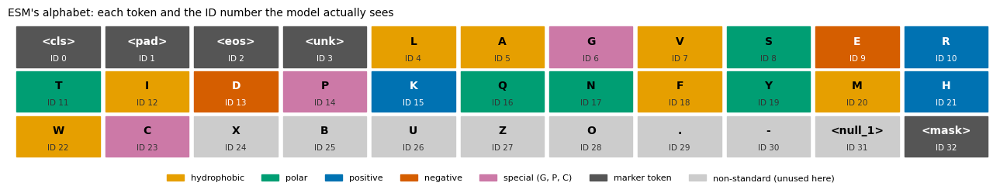

In [66]:
# the alphabet: every token and its ID number, drawn as a grid
from matplotlib.patches import Rectangle

ALPHABET = esm.data.Alphabet.from_architecture("ESM-1b")   # ESM-1v's and ESM-2's tokenizer (no model weights needed)
TOKENS = ALPHABET.all_toks                                   # list of the 33 tokens; position in the list = ID number
print(f"{len(TOKENS)} tokens | start <cls> = {ALPHABET.cls_idx} | padding <pad> = {ALPHABET.padding_idx} | "
      f"end <eos> = {ALPHABET.eos_idx} | <mask> = {ALPHABET.mask_idx}")

# colour each token by what kind of thing it is (same amino-acid groups as the ESM notebook)
AA_GROUPS = {"hydrophobic": ("AVLIMFW", "#E69F00"), "polar": ("STNQY", "#009E73"), "positive": ("KRH", "#0072B2"),
             "negative": ("DE", "#D55E00"), "special (G, P, C)": ("GPC", "#CC79A7")}
def token_color(tok):
    '''Fill colour for one token: amino acids by chemical group; markers dark grey; the rest light grey.'''
    for name, (letters, color) in AA_GROUPS.items():
        if tok in letters:
            return color
    return "#555555" if tok in ("<cls>", "<pad>", "<eos>", "<unk>", "<mask>") else "#cccccc"

fig, ax = plt.subplots(figsize=(13, 2.6))
per_row = 11                                                 # 33 tokens -> 3 rows of 11
for i, tok in enumerate(TOKENS):
    row, col = divmod(i, per_row)
    ax.add_patch(Rectangle((col, -row), 0.94, 0.9, color=token_color(tok)))      # one box per token
    dark = token_color(tok) in ("#555555", "#0072B2", "#D55E00")
    ax.text(col + 0.47, -row + 0.58, tok, ha="center", va="center", fontsize=10, fontweight="bold",
            color="white" if dark else "black")
    ax.text(col + 0.47, -row + 0.2, f"ID {i}", ha="center", va="center", fontsize=7.5,
            color="white" if dark else "0.2")
handles = [Rectangle((0, 0), 1, 1, color=c) for _, c in AA_GROUPS.values()] + \
          [Rectangle((0, 0), 1, 1, color="#555555"), Rectangle((0, 0), 1, 1, color="#cccccc")]
ax.legend(handles, list(AA_GROUPS) + ["marker token", "non-standard (unused here)"], ncol=7, fontsize=8,
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.02))
ax.set_xlim(-0.1, per_row); ax.set_ylim(-2.15, 1.0); ax.axis("off")
ax.set_title("ESM's alphabet: each token and the ID number the model actually sees", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

### 11b. The target: what the model should learn to predict

For every residue the model outputs one number, and training pushes that number towards the **target**. Predicting a continuous number like this is called **regression**, as opposed to classification.

**Which tolerance column?** §3 found that each gene's *average* tolerance mostly reflects how heavily it's studied (more ClinVar entries → lower average), not biology. Using `tolerance_v4_centered` (each gene minus its own median) removes that gene-level offset. The model then learns **which parts of a protein are more or less tolerant than the rest of that protein**, which sequence can actually explain. Change `TARGET_COL` to `"tolerance_v4"` to train on the raw score instead.

The left plot below shows one protein's raw and centred tracks: same shape, just shifted. The right plot checks that train / val / test have similar target distributions. If they didn't, val/test performance would be misleading.

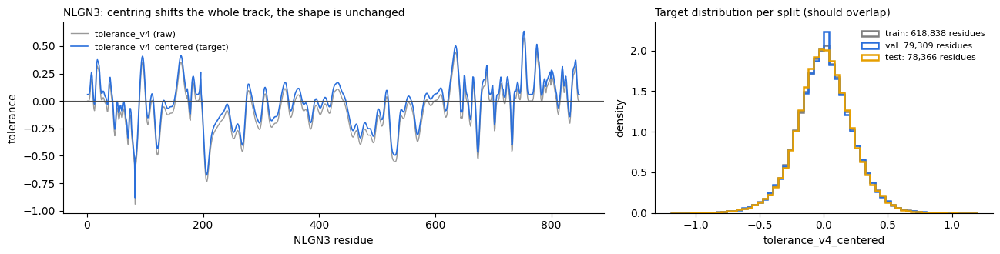

In [67]:
# choose the target column and look at it
TARGET_COL = "tolerance_v4_centered"      # recommended in §3; "tolerance_v4" = raw score

if TARGET_COL not in psd_seq_df:          # the centred column is made in §5; recreate it if §5 wasn't run
    psd_seq_df["tolerance_v4_centered"] = [np.asarray(t) - np.median(t) for t in psd_seq_df.tolerance_v4]

EXAMPLE = "NLGN3" if "NLGN3" in set(psd_seq_df.gene) else psd_seq_df.gene.iloc[0]   # gene used in the figures
ex = psd_seq_df.set_index("gene").loc[EXAMPLE]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(1, len(ex.sequence) + 1)                    # residue numbers 1..L
axes[0].plot(x, ex.tolerance_v4, color="0.6", lw=1, label="tolerance_v4 (raw)")
axes[0].plot(x, ex.tolerance_v4_centered, color="#2a6fdb", lw=1.2, label="tolerance_v4_centered (target)")
axes[0].axhline(0, color="0.3", lw=0.8)
axes[0].set_xlabel(f"{EXAMPLE} residue"); axes[0].set_ylabel("tolerance")
axes[0].set_title(f"{EXAMPLE}: centring shifts the whole track, the shape is unchanged", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8)

used = psd_seq_df[psd_seq_df.split.isin(["train", "val", "test"])]      # §10 split; 'excluded' genes left out
bins = np.linspace(-1.2, 1.2, 61)
for split, color in [("train", "0.5"), ("val", "#2a6fdb"), ("test", "#E69F00")]:
    values = np.concatenate([np.asarray(t) for t in used.loc[used.split == split, TARGET_COL]])
    axes[1].hist(values, bins=bins, density=True, histtype="step", lw=1.8, color=color,
                 label=f"{split}: {len(values):,} residues")
axes[1].set_xlabel(TARGET_COL); axes[1].set_ylabel("density")
axes[1].set_title("Target distribution per split (should overlap)", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 11c. One protein, step by step: letters → token IDs → aligned targets → mask

Three rules turn a sequence plus its tolerance track into model input:

1. **Tokenize.** Replace every letter with its ID, then add `<cls>` at the front and `<eos>` at the end, because ESM always saw sequences framed this way during pre-training. A protein of length *L* becomes *L + 2* tokens.
2. **Align the target.** Because `<cls>` takes slot 0, residue 1 sits in slot 1, residue 2 in slot 2, and so on. The tolerance values must be shifted by exactly one slot so each value sits under its own residue. The marker slots get **NaN** ("not a number"): there's nothing to predict there.
3. **Mask.** True wherever the target is a real number, False on markers (and later on padding). The loss, the measure of how wrong the model is, is computed **only where the mask is True**.

The figure shows this for the first and last residues of the example protein. The next cell checks the rules against ESM's own converter.

NLGN3: 848 residues -> 850 tokens (identical to ESM's batch converter); 848 positions in the loss


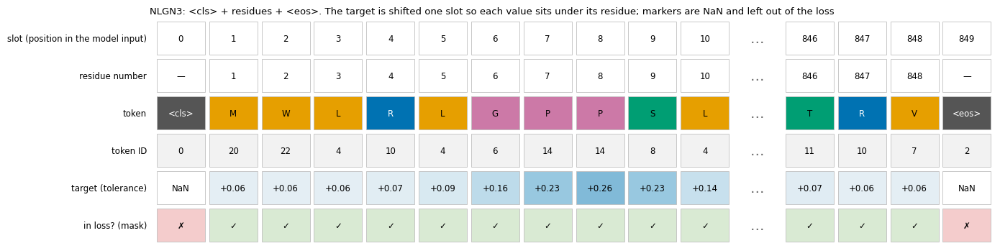

In [68]:
# tokenize one protein by hand and draw every step
def tokenize(sequence):
    '''Letters -> list of token IDs, framed by <cls> ... <eos> (exactly what ESM expects).'''
    return [ALPHABET.cls_idx] + [ALPHABET.get_idx(aa) for aa in sequence] + [ALPHABET.eos_idx]

def align_target(values):
    '''Per-residue values -> one value per token: NaN under <cls> and <eos>, values shifted by one slot.'''
    return np.concatenate([[np.nan], np.asarray(values, dtype=float), [np.nan]])

seq = ex.sequence
tokens = tokenize(seq)
target = align_target(ex[TARGET_COL])
mask = ~np.isnan(target)                                   # True = real residue with a real target

# check 1: our tokenizer gives exactly what ESM's own batch converter gives
_, _, esm_tokens = ALPHABET.get_batch_converter()([(EXAMPLE, seq)])
assert esm_tokens[0].tolist() == tokens, "our tokens differ from ESM's batch converter"
# check 2: lengths line up -- one token, one target value and one mask entry per slot
assert len(tokens) == len(target) == len(mask) == len(seq) + 2
print(f"{EXAMPLE}: {len(seq)} residues -> {len(tokens)} tokens (identical to ESM's batch converter); "
      f"{mask.sum()} positions in the loss")

# figure: show the first 10 and last 4 slots (plus a gap column) so both markers are visible
shown = list(range(0, 11)) + [None] + list(range(len(tokens) - 4, len(tokens)))   # None = "..." column
norm = mcolors.TwoSlopeNorm(vmin=-0.6, vcenter=0, vmax=0.6)                       # red < 0 < blue
rows = ["slot (position in the model input)", "residue number", "token", "token ID", "target (tolerance)", "in loss? (mask)"]
fig, ax = plt.subplots(figsize=(14, 3.6))
for col, slot in enumerate(shown):
    for r in range(len(rows)):
        y = len(rows) - 1 - r
        if slot is None:                                   # the "..." gap column
            ax.text(col + 0.5, y + 0.5, "…", ha="center", va="center", fontsize=14, color="0.4")
            continue
        tok = TOKENS[tokens[slot]]
        if r == 0:   text, face = str(slot), "white"
        elif r == 1: text, face = ("—" if slot in (0, len(tokens) - 1) else str(slot)), "white"
        elif r == 2: text, face = tok, token_color(tok)
        elif r == 3: text, face = str(tokens[slot]), "#f2f2f2"
        elif r == 4:
            text = "NaN" if np.isnan(target[slot]) else f"{target[slot]:+.2f}"
            face = "white" if np.isnan(target[slot]) else plt.cm.RdBu(norm(target[slot]))
        else:        text, face = ("✓" if mask[slot] else "✗"), ("#d9ead3" if mask[slot] else "#f4cccc")
        ax.add_patch(Rectangle((col + 0.04, y + 0.06), 0.92, 0.88, facecolor=face, edgecolor="0.75", lw=0.6))
        dark = r == 2 and token_color(tok) in ("#555555", "#0072B2", "#D55E00")
        ax.text(col + 0.5, y + 0.5, text, ha="center", va="center", fontsize=8.5, color="white" if dark else "black")
for r, label in enumerate(rows):
    ax.text(-0.15, len(rows) - 1 - r + 0.5, label, ha="right", va="center", fontsize=8.5)
ax.set_xlim(-0.1, len(shown)); ax.set_ylim(0, len(rows)); ax.axis("off")
ax.set_title(f"{EXAMPLE}: <cls> + residues + <eos>. The target is shifted one slot so each value sits under its residue; "
             "markers are NaN and left out of the loss", loc="left", fontsize=9.5)
fig.tight_layout(); plt.show()

### 11d. Long proteins: cropping into windows

ESM handles at most **1,024 tokens** at a time: 1,022 residues + `<cls>` + `<eos>`. That limit comes from how it was trained. Longer proteins (SHANK3, DMD, the large scaffolds) must be cut into **windows**, and training and evaluation cut them differently:

- **Training: one random window per protein, every time.** Each time a long protein is drawn, a new random 1,022-residue window is chosen. Over many passes through the data (**epochs**), the model sees every part of the protein, always with fresh surroundings. This is free **data augmentation**: more variety from the same data.
- **Evaluation (val / test): fixed, overlapping tiles.** Windows of 1,022 residues that overlap by 200, the same tiling ESM scoring used in §4. Each residue's prediction is taken from the tile where it sits **most centrally**, because residues near a window's edge see less of their surrounding protein. Those predictions are then stitched back into one full-length track.

The files store **whole proteins**; the cropping happens as data is loaded (11f), so nothing is lost.

Left: how many proteins are too long. Right: the two schemes for one long protein.

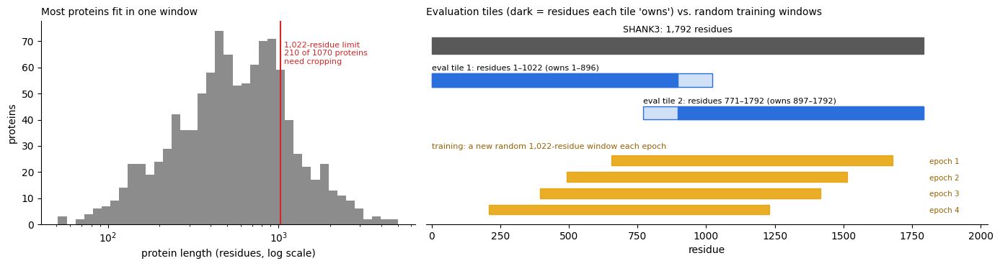

In [69]:
# how many proteins need cropping, and what the windows look like for one long protein
MAX_RESIDUES = WINDOW            # 1,022 (from §4): + <cls> + <eos> = 1,024 tokens, ESM's limit
EVAL_OVERLAP = OVERLAP           # 200 residues of overlap between evaluation tiles (same as §4)

lengths = used.sequence.str.len()
n_long = int((lengths > MAX_RESIDUES).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].hist(lengths, bins=np.logspace(np.log10(lengths.min()), np.log10(lengths.max()), 40), color="0.55")
axes[0].set_xscale("log")
axes[0].axvline(MAX_RESIDUES, color="#d62728", lw=1.5)
axes[0].text(MAX_RESIDUES * 1.05, axes[0].get_ylim()[1] * 0.9,
             f"1,022-residue limit\n{n_long} of {len(lengths)} proteins\nneed cropping", color="#d62728", fontsize=8, va="top")
axes[0].set_xlabel("protein length (residues, log scale)"); axes[0].set_ylabel("proteins")
axes[0].set_title("Most proteins fit in one window", loc="left", fontsize=10)

LONG = "SHANK3" if "SHANK3" in set(used.gene) else used.loc[lengths.idxmax(), "gene"]
L = len(psd_seq_df.set_index("gene").loc[LONG, "sequence"])
ax = axes[1]
starts = tile_starts(L, MAX_RESIDUES, EVAL_OVERLAP)                          # evaluation tiles (from §4)
cuts = [0] + [(b + a + MAX_RESIDUES) // 2 for a, b in zip(starts[:-1], starts[1:])] + [L]   # hand-over points
y = 0.0                                                                      # draw top to bottom
ax.add_patch(Rectangle((1, y), L, 0.5, color="0.35"))                        # the whole protein
ax.text(L / 2, y + 0.65, f"{LONG}: {L:,} residues", ha="center", fontsize=9)
for k, s in enumerate(starts):
    y -= 1.0
    ax.add_patch(Rectangle((s + 1, y), MAX_RESIDUES, 0.4, facecolor="#cfe0f7", edgecolor="#2a6fdb"))
    ax.add_patch(Rectangle((cuts[k] + 1, y), cuts[k + 1] - cuts[k], 0.4, color="#2a6fdb"))   # residues this tile "owns"
    ax.text(s + 1, y + 0.5, f"eval tile {k + 1}: residues {s + 1}–{s + MAX_RESIDUES} "
            f"(owns {cuts[k] + 1}–{cuts[k + 1]})", fontsize=8)
y -= 0.9
ax.text(1, y, "training: a new random 1,022-residue window each epoch", fontsize=8, color="#9a6100")
rng_demo = np.random.default_rng(SEED)
for k in range(4):                                                           # a few random training windows
    s = int(rng_demo.integers(0, L - MAX_RESIDUES + 1))
    y -= 0.5
    ax.add_patch(Rectangle((s + 1, y), MAX_RESIDUES, 0.3, color="#E69F00", alpha=0.85))
    ax.text(L + 20, y + 0.05, f"epoch {k + 1}", fontsize=7.5, color="#9a6100")
ax.set_xlim(-20, L * 1.13); ax.set_ylim(y - 0.3, 1.0)
ax.set_yticks([]); ax.set_xlabel("residue")
ax.set_title("Evaluation tiles (dark = residues each tile 'owns') vs. random training windows", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
axes[1].spines["left"].set_visible(False)
fig.tight_layout(); plt.show()

### 11e. Build one record per protein and save the files

Each protein becomes a small **record** (a Python dictionary) holding:
- `gene`, `cluster`, `length`
- `tokens`: the residue IDs **without** `<cls>`/`<eos>`. Those are added when a window is cut (11f), because every window needs its own pair.
- `target`: the tolerance values, one per residue

Details:
- **Proteins with identical sequences** (CALM1/2/3, from §2) would show the model the same input with three different answers. With `MERGE_IDENTICAL = True` they become **one** record whose target is the average of the three. They're always in the same split, because §10 clusters identical sequences together.
- **`excluded` genes** (incomplete targets, §10) are left out.
- **Saved as PyTorch files** (`torch.save`): `train.pt`, `val.pt`, `test.pt`. Each is a list of records and reloads in one line on Biowulf. Token IDs are stored as small integers (`uint8`, 1 byte each) and targets as 32-bit floats (`float32`, PyTorch's usual precision).
- **`dataset_info.json`:** a plain-text description of everything the training script needs to interpret the files: alphabet, marker IDs, window length, target column, counts. Anyone opening the folder later can see how it was made.

In [ ]:
# build records (one per protein) and save train.pt / val.pt / test.pt + dataset_info.json
import shutil

MERGE_IDENTICAL = True                                     # average proteins with identical sequences (CALM1/2/3)
JOB_DIR  = os.path.join(OUT, "tolerance_job")              # the folder that goes to Biowulf (§15)
DATA_DIR = os.path.join(JOB_DIR, "data")
SRC_DIR  = os.path.join(JOB_DIR, "src")
for d in (DATA_DIR, SRC_DIR):
    os.makedirs(d, exist_ok=True)

def make_record(genes, sequence, targets, cluster):
    '''One protein -> dict of plain Python values and tensors (all torch.save can store safely).'''
    target = np.mean(np.vstack(targets), axis=0)           # one gene: unchanged; identical sequences: averaged
    return {"gene": "|".join(genes),                       # e.g. "NLGN3" or "CALM1|CALM2|CALM3"
            "genes": list(genes),
            "cluster": cluster,
            "length": len(sequence),
            "tokens": torch.tensor([ALPHABET.get_idx(a) for a in sequence], dtype=torch.uint8),   # IDs 4..23
            "target": torch.tensor(target, dtype=torch.float32)}

records = {"train": [], "val": [], "test": []}
groups = used.groupby("sequence", sort=False) if MERGE_IDENTICAL else used.groupby("gene", sort=False)
for _, grp in groups:
    split = grp.split.iloc[0]
    assert grp.split.nunique() == 1, f"identical sequences in different splits: {grp.gene.tolist()}"
    records[split].append(make_record(grp.gene.tolist(), grp.sequence.iloc[0],
                                      [np.asarray(t, dtype=float) for t in grp[TARGET_COL]], grp.cluster.iloc[0]))

for split, recs in records.items():
    torch.save(recs, os.path.join(DATA_DIR, f"{split}.pt"))
shutil.copy(os.path.join(OUT, "split_manifest.json"), DATA_DIR)    # keep the split next to the data

dataset_info = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "esm_name": ESM_NAME,                                  # §12 must load a model with this alphabet
    "alphabet": TOKENS,                                    # position in the list = token ID
    "cls_idx": ALPHABET.cls_idx, "eos_idx": ALPHABET.eos_idx,
    "padding_idx": ALPHABET.padding_idx, "mask_idx": ALPHABET.mask_idx,
    "max_residues": MAX_RESIDUES, "eval_overlap": EVAL_OVERLAP,
    "target_col": TARGET_COL, "merge_identical": MERGE_IDENTICAL,
    "seed": SEED,
    "counts": {s: {"proteins": len(r), "residues": int(sum(x["length"] for x in r))} for s, r in records.items()},
}
with open(os.path.join(DATA_DIR, "dataset_info.json"), "w") as f:
    json.dump(dataset_info, f, indent=1)

merged = [r["gene"] for recs in records.values() for r in recs if len(r["genes"]) > 1]
print("records per split:", {s: v["proteins"] for s, v in dataset_info["counts"].items()},
      "| merged identical sequences:", merged or "none")
for name in sorted(os.listdir(DATA_DIR)):
    print(f"  {name:22s} {os.path.getsize(os.path.join(DATA_DIR, name)) / 1e6:6.2f} MB")

### 11f. `dataset.py`: the code that feeds batches to the model

The training script on Biowulf can't see this notebook, so the loading logic lives in its own file, `tolerance_job/src/dataset.py`, written by the cell below (`%%writefile` saves a cell's text to a file instead of running it). It has three parts:

1. **`ToleranceDataset`**: PyTorch asks it for example number *k* and it returns one window, ready for the model:
   - `tokens`: `<cls>` + residue IDs + `<eos>`
   - `target`: aligned values, 0 under the markers
   - `mask`: True on real residues
   - `gene`, `start`: so predictions can be traced back to a protein position

   With `train=True` it picks a **random window** each time. With `train=False` it lists the **fixed tiles** in advance, so every residue is predicted.
2. **`collate`**: the DataLoader hands it a list of windows, and it stacks them into one rectangle. Shorter windows are filled with `<pad>` (ID 1); their target is 0 and their mask False, so padding never affects the loss.
3. **`tile_ownership`**: for evaluation, which residues each tile is responsible for (the most-central rule from 11d), so tile predictions can be stitched back into one track per protein.

The file uses only `torch` and the standard library, no `esm` and no `pandas`, so it runs anywhere the training environment does.

In [71]:
%%writefile ../results/tolerance_model/tolerance_job/src/dataset.py
"""dataset.py -- turns saved protein records into model-ready batches.

Records (from train.pt / val.pt / test.pt) are dicts with:
    gene    : str                      e.g. "NLGN3"
    tokens  : uint8 tensor, length L   residue token IDs (no <cls>/<eos>)
    target  : float32 tensor, length L tolerance per residue

Usage (in train.py):
    info    = json.load(open("data/dataset_info.json"))
    records = torch.load("data/train.pt")
    ds      = ToleranceDataset(records, info, train=True)
    loader  = DataLoader(ds, batch_size=8, shuffle=True, collate_fn=make_collate(info["padding_idx"]))
"""
import functools
import torch
from torch.utils.data import Dataset


def tile_starts(length, window, overlap):
    """Start positions (0-based) of fixed, overlapping windows that cover a protein end to end.
    A protein that fits in one window gets a single tile starting at 0."""
    if length <= window:
        return [0]
    step = window - overlap                                   # how far each new tile moves along
    return list(range(0, length - window, step)) + [length - window]   # last tile ends exactly at the end


def tile_ownership(length, window, overlap):
    """For evaluation: [(start, own_from, own_to), ...] -- each tile 'owns' the residues where it is the
    most central tile, so stitching tile predictions back together counts every residue exactly once."""
    starts = tile_starts(length, window, overlap)
    # hand-over point between two neighbouring tiles = middle of the stretch they share
    cuts = [0] + [(b + a + window) // 2 for a, b in zip(starts[:-1], starts[1:])] + [length]
    return [(s, cuts[k], cuts[k + 1]) for k, s in enumerate(starts)]


class ToleranceDataset(Dataset):
    """One item = one window of one protein: tokens with <cls>/<eos>, aligned target, and mask."""

    def __init__(self, records, info, train, window=None, overlap=None):
        self.records = records
        self.cls, self.eos = info["cls_idx"], info["eos_idx"]          # marker token IDs (0 and 2 for ESM)
        self.window = window or info["max_residues"]                   # residues per window (1,022)
        self.overlap = info["eval_overlap"] if overlap is None else overlap
        self.train = train
        if train:
            # training: one item per protein; WHICH window is decided fresh every time it's requested
            self.items = [(i, None) for i in range(len(records))]
        else:
            # evaluation: one item per fixed tile, listed up front so every residue gets predicted
            self.items = [(i, start) for i, r in enumerate(records)
                          for start in tile_starts(len(r["tokens"]), self.window, self.overlap)]

    def __len__(self):
        """How many items PyTorch can ask for (proteins when training, tiles when evaluating)."""
        return len(self.items)

    def __getitem__(self, k):
        """Build item k: cut the window, add the markers, align the target, make the mask."""
        i, start = self.items[k]
        rec = self.records[i]
        length = len(rec["tokens"])
        if start is None:                                    # training: random window start
            start = int(torch.randint(0, max(length - self.window, 0) + 1, (1,)))
        end = min(start + self.window, length)

        residues = rec["tokens"][start:end].long()            # token IDs as 64-bit integers (what embeddings need)
        tokens = torch.cat([torch.tensor([self.cls]), residues, torch.tensor([self.eos])])   # <cls> ... <eos>

        values = rec["target"][start:end]
        nan = torch.tensor([float("nan")])
        target = torch.cat([nan, values, nan])                # NaN under the two markers -> target lines up with tokens
        mask = ~torch.isnan(target)                           # True only where there's a real value to learn
        target = torch.nan_to_num(target, nan=0.0)            # NaN breaks arithmetic; masked slots are ignored anyway

        return {"tokens": tokens, "target": target, "mask": mask, "gene": rec["gene"], "start": start}


def collate(batch, padding_idx):
    """Stack a list of items into one batch. Shorter items are padded on the right with <pad>;
    padded slots get target 0 and mask False, so they never count in the loss."""
    n = max(len(item["tokens"]) for item in batch)            # longest item sets the batch width
    tokens = torch.full((len(batch), n), padding_idx, dtype=torch.long)
    target = torch.zeros((len(batch), n), dtype=torch.float32)
    mask = torch.zeros((len(batch), n), dtype=torch.bool)
    for row, item in enumerate(batch):
        m = len(item["tokens"])
        tokens[row, :m] = item["tokens"]
        target[row, :m] = item["target"]
        mask[row, :m] = item["mask"]
    return {"tokens": tokens, "target": target, "mask": mask,
            "genes": [item["gene"] for item in batch], "starts": [item["start"] for item in batch]}


def make_collate(padding_idx):
    """DataLoader's collate_fn only receives the batch, so bake the padding ID in."""
    return functools.partial(collate, padding_idx=padding_idx)

Writing ../results/tolerance_model/tolerance_job/src/dataset.py


### 11g. Test the pipeline: load, batch, look, check

This is what the training script will do on Biowulf, done here on a small scale:
1. **Import `dataset.py` from its file**, exactly as `train.py` will, so we test the real file rather than notebook code.
2. **Load `train.pt`**, wrap it in a `ToleranceDataset` and a PyTorch `DataLoader`, and pull **one batch**.
3. **Draw the batch.** Each row is one window; columns are slots. Three panels show the same rectangle three ways:
   - **tokens**, coloured by amino-acid group; dark ends are `<cls>`/`<eos>`, light grey is padding
   - **target**: red = intolerant, blue = tolerant, white = no value
   - **mask**: dark = counts in the loss
4. **Checks:**
   - decoding tokens gives back the original sequence;
   - the masked targets equal §3's tolerance values;
   - evaluation tiles cover every residue of every protein exactly once;
   - stitching per-tile values back reproduces the full-length track.

The batch below is drawn with `shuffle=False` and four proteins of different lengths, so the padding is easy to see. Training uses `shuffle=True`, which draws a different mix every epoch.

/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/149750137.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  train_records = torch.load(os.path.join(DATA_D

{'tokens': (4, 1024), 'target': (4, 1024), 'mask': (4, 1024)} | windows: ['CDC42 from residue 1', 'PICK1 from residue 1', 'VPS35 from residue 1', 'DMD from residue 1415']
padding: 41% of the batch | slots in the loss: 2,424


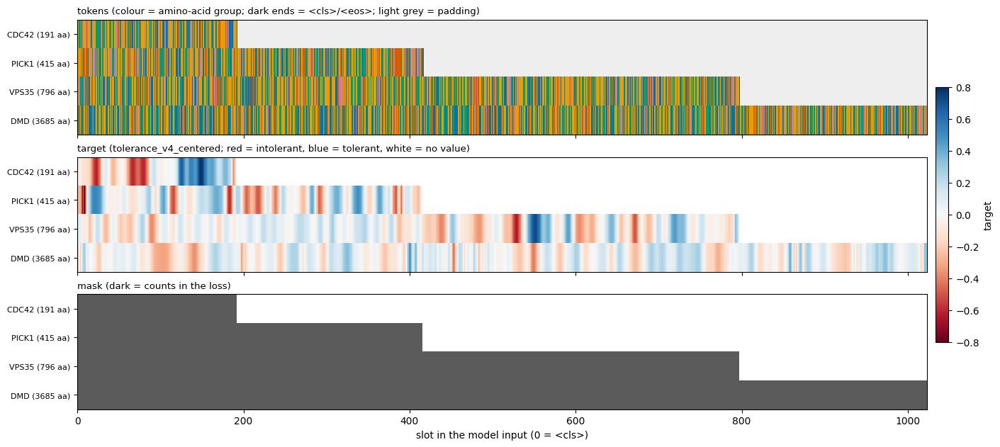

1. tokens decode back to the original sequence for every protein
2. target[mask] matches the original track (DMD, random window from residue 2634)
3. validation: 107 proteins -> 142 tiles (23 proteins needed more than one)
4. stitching the tiles back together reproduces every full-length target exactly


/var/folders/gk/xp8kfcvd0bsbwbbhv54r6mg00000gp/T/ipykernel_38190/149750137.py:48: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  recs = torch.load(os.path.join(DATA_DIR, f"{s

In [72]:
# load the saved files through dataset.py, build a batch, draw it, and run the checks
import importlib.util
from torch.utils.data import DataLoader

spec = importlib.util.spec_from_file_location("dataset", os.path.join(SRC_DIR, "dataset.py"))   # import the FILE
dataset = importlib.util.module_from_spec(spec); spec.loader.exec_module(dataset)

info = json.load(open(os.path.join(DATA_DIR, "dataset_info.json")))
train_records = torch.load(os.path.join(DATA_DIR, "train.pt"))
train_ds = dataset.ToleranceDataset(train_records, info, train=True)

# a demo batch: four training proteins of increasing length (one longer than the window)
by_len = sorted(range(len(train_records)), key=lambda i: train_records[i]["length"])
demo_idx = [by_len[len(by_len) // 10], by_len[len(by_len) // 3], by_len[2 * len(by_len) // 3], by_len[-5]]
loader = DataLoader(torch.utils.data.Subset(train_ds, demo_idx), batch_size=4, shuffle=False,
                    collate_fn=dataset.make_collate(info["padding_idx"]))
batch = next(iter(loader))                                 # one batch = a dict of rectangles
print({k: tuple(v.shape) for k, v in batch.items() if torch.is_tensor(v)},
      "| windows:", [f"{g} from residue {s + 1}" for g, s in zip(batch["genes"], batch["starts"])])
print(f"padding: {(batch['tokens'] == info['padding_idx']).float().mean():.0%} of the batch | "
      f"slots in the loss: {int(batch['mask'].sum()):,}")

# --- draw the batch three ways
tok = batch["tokens"].numpy()
color_of_id = [mcolors.to_rgb(token_color(t)) for t in TOKENS]
color_of_id[info["padding_idx"]] = mcolors.to_rgb("#eeeeee")               # padding: very light grey
rgb = np.array(color_of_id)[tok]                                            # (batch, slots, 3) image
tgt = np.where(batch["mask"].numpy(), batch["target"].numpy(), np.nan)      # NaN = no value -> drawn white
fig, axes = plt.subplots(3, 1, figsize=(14, 6.2), sharex=True, layout="constrained")
axes[0].imshow(rgb, aspect="auto", interpolation="nearest")
axes[0].set_title("tokens (colour = amino-acid group; dark ends = <cls>/<eos>; light grey = padding)", loc="left", fontsize=9.5)
cmap = plt.get_cmap("RdBu").copy(); cmap.set_bad("white")
im = axes[1].imshow(tgt, aspect="auto", interpolation="nearest", cmap=cmap, norm=mcolors.TwoSlopeNorm(0, -0.8, 0.8))
axes[1].set_title(f"target ({TARGET_COL}; red = intolerant, blue = tolerant, white = no value)", loc="left", fontsize=9.5)
fig.colorbar(im, ax=list(axes), fraction=0.015, pad=0.01, label="target")   # same width taken from all panels
axes[2].imshow(batch["mask"].numpy(), aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1.4)
axes[2].set_title("mask (dark = counts in the loss)", loc="left", fontsize=9.5)
for a in axes:
    a.set_yticks(range(len(batch["genes"])), [f"{g} ({train_records[i]['length']} aa)"
                                              for g, i in zip(batch["genes"], demo_idx)], fontsize=8)
axes[2].set_xlabel("slot in the model input (0 = <cls>)")
plt.show()

# --- checks
# 1. decoding: token IDs back to letters must give the original sequence (for every protein in every split)
seq_of = {g: s for g, s in zip(psd_seq_df.gene, psd_seq_df.sequence)}
for split in ["train", "val", "test"]:
    recs = torch.load(os.path.join(DATA_DIR, f"{split}.pt"))
    for r in recs:
        assert "".join(TOKENS[t] for t in r["tokens"].tolist()) == seq_of[r["genes"][0]], r["gene"]
print("1. tokens decode back to the original sequence for every protein")

# 2. alignment: the masked targets of a (non-merged) item equal §3's values for that window
item = train_ds[demo_idx[-1]]                            # the long protein -> a random window
rec = train_records[demo_idx[-1]]
original = np.asarray(psd_seq_df.set_index("gene").loc[rec["genes"][0], TARGET_COL], dtype=np.float32)
window_values = item["target"][item["mask"]].numpy()
assert np.allclose(window_values, original[item["start"]:item["start"] + len(window_values)])
assert item["tokens"][0] == info["cls_idx"] and item["tokens"][-1] == info["eos_idx"]
print(f"2. target[mask] matches the original track ({rec['gene']}, random window from residue {item['start'] + 1})")

# 3 + 4. evaluation tiles cover every residue once, and stitching the tiles reproduces each full track
val_records = torch.load(os.path.join(DATA_DIR, "val.pt"))
val_ds = dataset.ToleranceDataset(val_records, info, train=False)
pieces = {}
for k in range(len(val_ds)):
    it = val_ds[k]
    pieces.setdefault(it["gene"], []).append(it)
for r in val_records:
    stitched = np.full(r["length"], np.nan)
    own = {s: (a, b) for s, a, b in dataset.tile_ownership(r["length"], info["max_residues"], info["eval_overlap"])}
    for it in pieces[r["gene"]]:
        a, b = own[it["start"]]                                   # residues this tile is responsible for
        values = it["target"][it["mask"]].numpy()                  # per residue of this tile
        stitched[a:b] = values[a - it["start"]:b - it["start"]]
    assert not np.isnan(stitched).any() and np.allclose(stitched, r["target"].numpy())
n_tiles = len(val_ds); n_long_val = sum(r["length"] > info["max_residues"] for r in val_records)
print(f"3. validation: {len(val_records)} proteins -> {n_tiles} tiles ({n_long_val} proteins needed more than one)")
print("4. stitching the tiles back together reproduces every full-length target exactly")

---
## 12. The model and how it is trained

**Goal:** build the tolerance model and the training script that teaches it. Both are written as files (`model.py`, `train.py`) in `tolerance_job/src/`, so the exact same code runs on your Mac (§13) and on Biowulf (§15).

### The idea in one paragraph
ESM has already read ~65 million protein sequences and learned, on its own, a rich internal description of every residue. That description covers what kind of residue it is, what its neighbourhood looks like, how conserved such positions tend to be, and whether it's likely buried or exposed. We don't start from scratch. We take ESM as a **backbone** and put a small new **head** on top that turns ESM's description of each residue into one number, the predicted tolerance. Training then shows the model thousands of residues with known tolerance (the targets from §11) and repeatedly nudges the adjustable weights so its predictions get closer. This is **fine-tuning**: adapting a model that already knows a lot to a specific new task.

### The training loop
```
  a batch from §11:   tokens (B × N)   target (B × N)   mask (B × N)
          │
          │ 1. FORWARD PASS: ESM turns every token into a description (1,280 numbers);
          │                  the head turns each description into one number
          ▼
  predictions (B × N)
          │ 2. LOSS: compare predictions with targets where mask = True → one number: "how wrong"
          ▼
  loss
          │ 3. BACKWARD PASS: for every adjustable weight, work out which direction would lower the loss
          │                   (its "gradient") -- PyTorch does this automatically
          ▼
          │ 4. OPTIMIZER STEP: move every adjustable weight a small step in that direction
          ▼                    (step size = the "learning rate")
  repeat for every batch  →  one EPOCH  →  predict the validation proteins, keep the best version  →  repeat
```

### Words used below
| word | meaning |
|---|---|
| **weight / parameter** | one adjustable number inside the model. ESM-2 650M has 650 million of them |
| **frozen / trainable** | frozen weights are never changed; trainable ones are updated during training |
| **backbone** | the pre-trained ESM network |
| **head** | the small new network on top that outputs tolerance |
| **embedding** | the vector of numbers a token ID is turned into at the very start |
| **representation** | the vector of numbers describing a residue *after* all of ESM's layers (1,280 numbers for 650M models) |
| **transformer layer** | one processing block of ESM. Its **attention** step lets every residue gather information from every other residue in the window; its **feed-forward** step processes each residue on its own |
| **loss** | a single number measuring how wrong the predictions are; training tries to make it small |
| **gradient** | for each weight, how much and in which direction changing it would change the loss |
| **learning rate** | how big a step the optimizer takes along the gradient |
| **optimizer** | the rule that turns gradients into weight updates (here **AdamW**, the standard choice) |
| **epoch** | one full pass over all training proteins |
| **overfitting** | the model memorises the training proteins instead of learning general rules, so it gets worse on new proteins |
| **validation** | measuring performance on proteins the model never trains on (the `val` split), to detect overfitting and pick the best version |
| **checkpoint** | a saved copy of the weights |
| **LoRA** | "low-rank adaptation": adapting a big frozen network through small add-on matrices (12d) |

### 12a. The architecture: what happens to one batch

The figure follows one batch through the model. The shapes underneath each box show how big the data is at that point, for a batch of **B = 4** windows of **N = 1,024** slots with ESM-2 650M, whose description of each residue has **D = 1,280** numbers.

1. **Embedding.** Each token ID is swapped for its learned vector of 1,280 numbers, plus position information. Now every slot is a list of numbers, not an ID.
2. **33 transformer layers.** In each layer, **attention** lets every residue look at every other residue in the window and pull in what's relevant. For example, a residue can notice it sits in a hydrophobic stretch, or that a distant residue packs against it. The vectors are then refined residue by residue. After 33 layers each residue's vector, its **representation**, summarises the residue *in the context of the whole protein*.
3. **The head**, applied to every residue separately with the same weights: 1,280 numbers → 256 → 1 number, the predicted tolerance.

Residues never mix inside the head. All context comes from ESM's attention, which is why the backbone matters so much. ESM's attention also skips `<pad>` slots, so padding (§11) can't leak into real residues.

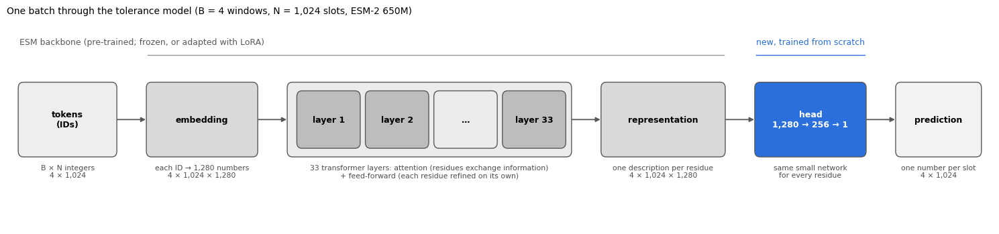

In [73]:
# the architecture as a diagram, with the size of the data at each step
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, text, face, sub=None, text_color="black"):
    '''Rounded box with a title and an optional grey caption underneath.'''
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=face, edgecolor="0.35", lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9, color=text_color, fontweight="bold")
    if sub:
        ax.text(x + w / 2, y - 0.12, sub, ha="center", va="top", fontsize=7.8, color="0.3")

def arrow(ax, x0, x1, y):
    ax.annotate("", xy=(x1, y), xytext=(x0, y), arrowprops=dict(arrowstyle="-|>", color="0.35", lw=1.3))

fig, ax = plt.subplots(figsize=(15, 3.6))
y, h = 1.0, 1.0
stages = [  # x, width, title, colour, caption
    (0.0, 1.5, "tokens\n(IDs)", "#eeeeee", "B × N integers\n4 × 1,024"),
    (2.0, 1.7, "embedding", "#d9d9d9", "each ID → 1,280 numbers\n4 × 1,024 × 1,280"),
    (4.2, 4.4, "", "#ececec", None),                                            # frame around the layers
    (9.1, 1.9, "representation", "#d9d9d9", "one description per residue\n4 × 1,024 × 1,280"),
    (11.5, 1.7, "head\n1,280 → 256 → 1", "#2a6fdb", "same small network\nfor every residue"),
    (13.7, 1.3, "prediction", "#f2f2f2", "one number per slot\n4 × 1,024"),
]
for x, w, title, face, sub in stages:
    box(ax, x, y, w, h, title, face, sub, text_color="white" if face == "#2a6fdb" else "black")
for k, label in enumerate(["layer 1", "layer 2", "…", "layer 33"]):             # the transformer stack
    box(ax, 4.35 + k * 1.07, y + 0.12, 0.95, 0.76, label, "#bdbdbd" if label != "…" else "#ececec")
ax.text(6.4, y - 0.12, "33 transformer layers: attention (residues exchange information)\n"
                       "+ feed-forward (each residue refined on its own)", ha="center", va="top", fontsize=7.8, color="0.3")
for x0, x1 in [(1.5, 2.0), (3.7, 4.2), (8.6, 9.1), (11.0, 11.5), (13.2, 13.7)]:
    arrow(ax, x0, x1, y + h / 2)
ax.text(0, 2.55, "ESM backbone (pre-trained; frozen, or adapted with LoRA)", fontsize=9, color="0.35")
ax.plot([2.0, 11.0], [2.4, 2.4], color="0.6", lw=1)
ax.text(11.5, 2.55, "new, trained from scratch", fontsize=9, color="#2a6fdb")
ax.plot([11.5, 13.2], [2.4, 2.4], color="#2a6fdb", lw=1)
ax.set_xlim(-0.2, 15.2); ax.set_ylim(0.0, 2.9); ax.axis("off")
ax.set_title("One batch through the tolerance model (B = 4 windows, N = 1,024 slots, ESM-2 650M)", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

### 12b. What ESM's representations look like, for one real protein

The cell runs ESM-1v (already downloaded in §4) on the example protein and pulls out the representation of every residue: 1,280 numbers each.

- **Left:** the representations as an image: one column per residue, one row per number (only the first 128 of 1,280 rows shown). To a person it's noise; to the head it's the input.
- **Middle and right:** the 1,280 numbers per residue squashed into two with **PCA** (principal component analysis, which finds the two directions along which residues differ most). Each dot is one residue, coloured by disorder (middle) or by our tolerance target (right).

If the dots sort by colour, the information the head needs is already present in ESM's representations, and the head mostly has to learn how to *read* it. The correlations of the first direction (PC1) with disorder and with the target are printed below the figure. For NLGN3, disorder lines up very strongly and the target clearly but less tightly: the head has a good starting point, and fine-tuning should help with the rest.

NLGN3: 848 residues × 1280 numbers per residue


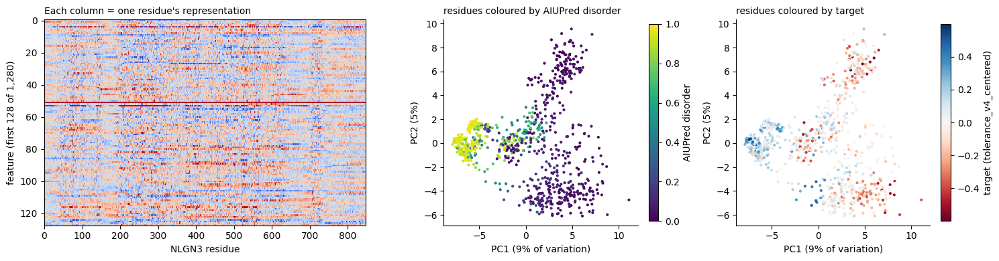

Spearman ρ of PC1 with disorder: -0.81 | with the target: -0.56


In [74]:
# real ESM representations for the example protein, and a 2-D map of them
from scipy.stats import spearmanr
model_v1, alphabet_v1, converter_v1 = load_esm()           # ESM-1v from §4 (cached on disk, loaded once)
_, _, toks = converter_v1([(EXAMPLE, seq)])
with torch.no_grad():                                      # we only look, no training -> no gradients needed
    out = model_v1(toks.to(device), repr_layers=[model_v1.num_layers])
reps = out["representations"][model_v1.num_layers][0, 1:-1].float().cpu().numpy()   # drop <cls>/<eos>: (L, 1280)
print(f"{EXAMPLE}: {reps.shape[0]} residues × {reps.shape[1]} numbers per residue")

centred = reps - reps.mean(axis=0)                          # PCA via SVD: centre each feature, find main directions
u, sv, vt = np.linalg.svd(centred, full_matrices=False)
pcs = centred @ vt[:2].T                                    # each residue's position along the top 2 directions
explained = (sv[:2] ** 2) / (sv ** 2).sum()
disorder = np.asarray(ex.disorder_scores)
target_ex = np.asarray(ex[TARGET_COL])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.5, 1, 1]})
lim = np.percentile(np.abs(reps[:, :128]), 98)
axes[0].imshow(reps[:, :128].T, aspect="auto", cmap="coolwarm", vmin=-lim, vmax=lim, interpolation="nearest")
axes[0].set_xlabel(f"{EXAMPLE} residue"); axes[0].set_ylabel("feature (first 128 of 1,280)")
axes[0].set_title("Each column = one residue's representation", loc="left", fontsize=10)
for ax, values, cmap, norm, label in [
        (axes[1], disorder, "viridis", mcolors.Normalize(0, 1), "AIUPred disorder"),
        (axes[2], target_ex, "RdBu", mcolors.TwoSlopeNorm(0, -0.6, 0.6), f"target ({TARGET_COL})")]:
    sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=values, cmap=cmap, norm=norm, s=9, linewidths=0)
    fig.colorbar(sc, ax=ax, fraction=0.046, label=label)
    ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variation)"); ax.set_ylabel(f"PC2 ({explained[1]:.0%})")
    ax.set_title(f"residues coloured by {label.split(' (')[0]}", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()
print(f"Spearman ρ of PC1 with disorder: {spearmanr(pcs[:, 0], disorder).statistic:+.2f} | "
      f"with the target: {spearmanr(pcs[:, 0], target_ex).statistic:+.2f}")

### 12c. The head and the loss

**The head** is a miniature neural network: `Linear(1,280 → 256)` → `GELU` → `Dropout(10%)` → `Linear(256 → 1)`.
- A **Linear** layer computes weighted sums: each output number is a different weighted combination of the inputs.
- **GELU** bends the result smoothly, so the head can learn rules like "only when both features are high". Two linear layers without a bend would collapse into one.
- **Dropout** randomly blanks 10% of the 256 middle numbers on each training step, so the head can't rely on any single feature. It's a standard guard against overfitting, and it's switched off when predicting.

The head has about 330,000 weights and starts out random, so its first predictions are meaningless. Training fixes that.

**The loss** turns all the per-residue errors in a batch into one number:
1. compute the error at every slot (prediction − target);
2. turn it into a cost (left plot);
3. **average over the slots where the mask is True** (right plot). Markers and padding contribute nothing.

Two cost rules (`"loss"` in the config):
- **MSE** (mean squared error): cost = error². Large errors count disproportionately.
- **Huber** (the default): squared for small errors, a straight line beyond `delta` = 0.5. The few extreme targets (sharp ClinVar dips) still count, but can't dominate training.

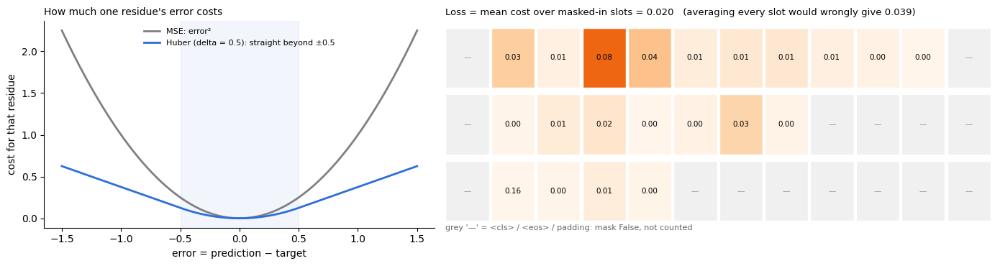

In [75]:
# the loss: squared vs Huber cost, and averaging only over masked-in slots
err = np.linspace(-1.5, 1.5, 301)
delta = 0.5
huber = np.where(np.abs(err) <= delta, 0.5 * err ** 2, delta * (np.abs(err) - 0.5 * delta))   # same as PyTorch's

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(err, err ** 2, color="0.5", lw=2, label="MSE: error²")
axes[0].plot(err, huber, color="#2a6fdb", lw=2, label=f"Huber (delta = {delta}): straight beyond ±{delta}")
axes[0].axvspan(-delta, delta, color="#2a6fdb", alpha=0.06)
axes[0].set_xlabel("error = prediction − target"); axes[0].set_ylabel("cost for that residue")
axes[0].set_title("How much one residue's error costs", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8); axes[0].spines[["top", "right"]].set_visible(False)

# toy batch: 3 windows × 12 slots; first/last slots are <cls>/<eos>, rows 2-3 are padded
toy_err = np.round(np.random.default_rng(1).normal(0, 0.3, (3, 12)), 2)
toy_mask = np.zeros((3, 12), bool)
for r, n_real in enumerate([10, 7, 4]):                    # residues per window (the rest: markers + padding)
    toy_mask[r, 1:1 + n_real] = True
cost = 0.5 * toy_err ** 2
ax = axes[1]
for r in range(3):
    for c in range(12):
        face = plt.cm.Oranges(min(cost[r, c] / 0.12, 1)) if toy_mask[r, c] else "#f0f0f0"
        ax.add_patch(Rectangle((c, 2 - r), 0.95, 0.9, facecolor=face, edgecolor="white"))
        ax.text(c + 0.47, 2 - r + 0.45, f"{cost[r, c]:.2f}" if toy_mask[r, c] else "—", ha="center", va="center",
                fontsize=7.5, color="black" if toy_mask[r, c] else "0.6")
ax.set_xlim(0, 12); ax.set_ylim(-0.1, 3); ax.axis("off")
ax.set_title(f"Loss = mean cost over masked-in slots = {cost[toy_mask].mean():.3f}   "
             f"(averaging every slot would wrongly give {cost.mean():.3f})", loc="left", fontsize=9.5)
ax.text(0, -0.05, "grey '—' = <cls> / <eos> / padding: mask False, not counted", fontsize=8, color="0.4", va="top")
fig.tight_layout(); plt.show()

### 12d. How much of ESM should change? Four fine-tuning strategies

ESM's weights encode everything it learned from 65 million proteins. With only ~850 training proteins, letting all of those weights change risks **overwriting general knowledge with memorised details** (overfitting), and it needs much more GPU memory. The options, from most cautious to most flexible (`"strategy"` in the config):

| strategy | what learns | trainable weights (650M model) | when it makes sense |
|---|---|---|---|
| `frozen` | only the head | ~0.3 M (0.05%) | fastest baseline: "is the information already in ESM?" |
| `top_layers` | head + last `n_unfrozen` layers | ~40 M | moderate adaptation |
| **`lora`** (default) | head + small add-ons in every attention block | ~1.7 M (0.26%) | the usual choice for large models with limited data |
| `full` | everything | ~650 M | lots of data and GPU memory |

**How LoRA works.** Every attention block contains square weight matrices, e.g. the "query" projection *W*, 1,280 × 1,280 = 1.6 million numbers. LoRA leaves *W* frozen and learns a correction made of two thin matrices: *B* (1,280 × 8) and *A* (8 × 1,280), about 20,000 numbers together. The layer then computes **W·x + B·A·x**. *B* starts at zero, so the model begins exactly as ESM and only drifts as far as the data justifies. The "8" is the **rank** (`lora_rank`): how much freedom the correction has.

The right-hand figure draws these matrices to scale. The table's numbers are computed for real in 12f.

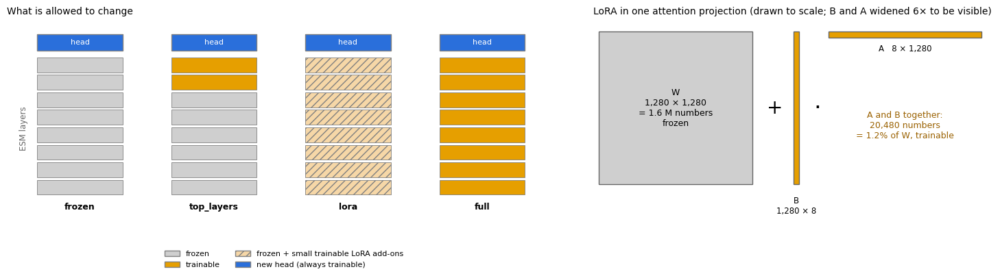

In [76]:
# the four strategies, and the LoRA matrices drawn to scale
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
FROZEN, TRAIN, LORA, HEAD = "#cfcfcf", "#E69F00", "#f6d7a7", "#2a6fdb"
strategies = {"frozen": lambda k: FROZEN, "top_layers": lambda k: TRAIN if k >= 6 else FROZEN,
              "lora": lambda k: LORA, "full": lambda k: TRAIN}
for col, (name, colour_of) in enumerate(strategies.items()):
    x = col * 2.2
    for k in range(8):                                     # 8 boxes standing in for 33 layers
        face = colour_of(k)
        ax.add_patch(Rectangle((x, k * 0.42), 1.4, 0.36, facecolor=face, edgecolor="0.5", lw=0.6,
                               hatch="///" if face == LORA else None))
    ax.add_patch(Rectangle((x, 8 * 0.42 + 0.1), 1.4, 0.4, facecolor=HEAD, edgecolor="0.5"))
    ax.text(x + 0.7, 8 * 0.42 + 0.3, "head", ha="center", va="center", color="white", fontsize=8)
    ax.text(x + 0.7, -0.35, name, ha="center", fontsize=9, fontweight="bold")
ax.text(-0.3, 1.6, "ESM layers", rotation=90, va="center", fontsize=8.5, color="0.4")
handles = [Rectangle((0, 0), 1, 1, facecolor=c, edgecolor="0.5", hatch=h) for c, h in
           [(FROZEN, None), (TRAIN, None), (LORA, "///"), (HEAD, None)]]
ax.legend(handles, ["frozen", "trainable", "frozen + small trainable LoRA add-ons", "new head (always trainable)"],
          fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_xlim(-0.5, 8.6); ax.set_ylim(-0.6, 4.2); ax.axis("off")
ax.set_title("What is allowed to change", loc="left", fontsize=10)

ax = axes[1]                                               # LoRA: W (frozen) + B·A (trainable), to scale
D, r, s = 1280, 8, 2.6 / 1280                              # s = drawing scale (units per number)
ax.add_patch(Rectangle((0, 0), D * s, D * s, facecolor=FROZEN, edgecolor="0.4"))
ax.text(D * s / 2, D * s / 2, f"W\n{D:,} × {D:,}\n= {D * D / 1e6:.1f} M numbers\nfrozen", ha="center", va="center", fontsize=9)
ax.text(D * s + 0.25, D * s / 2, "+", fontsize=20, va="center")
ax.add_patch(Rectangle((D * s + 0.7, 0), r * s * 6, D * s, facecolor=TRAIN, edgecolor="0.4"))   # B, widened ×6 to be visible
ax.text(D * s + 0.7 + r * s * 3, -0.2, f"B\n{D:,} × {r}", ha="center", va="top", fontsize=8.5)
ax.text(D * s + 1.05, D * s / 2, "·", fontsize=24, va="center")
ax.add_patch(Rectangle((D * s + 1.3, D * s - r * s * 6), D * s, r * s * 6, facecolor=TRAIN, edgecolor="0.4"))   # A
ax.text(D * s + 1.3 + D * s / 2, D * s - r * s * 6 - 0.12, f"A   {r} × {D:,}", ha="center", va="top", fontsize=8.5)
ax.text(D * s + 1.3 + D * s / 2, D * s / 2 - 0.3, f"A and B together:\n{2 * D * r:,} numbers\n"
        f"= {2 * D * r / (D * D):.1%} of W, trainable", ha="center", va="center", fontsize=9, color="#9a6100")
ax.set_xlim(-0.1, 2 * D * s + 1.5); ax.set_ylim(-0.6, D * s + 0.2); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("LoRA in one attention projection (drawn to scale; B and A widened 6× to be visible)", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

### 12e. `model.py`

The cell below writes the model to `tolerance_job/src/model.py`:
- **`LoRALinear`:** wraps one of ESM's linear layers with the trainable *B·A* correction (12d).
- **`set_trainable`:** freezes everything, then re-enables what the chosen strategy allows. For LoRA it also switches off a "fast path" in ESM-1v's attention that would otherwise read the original weights directly and silently skip LoRA. ESM-2 doesn't use that path. Switching it off changes speed slightly, never results (checked in 12f).
- **`ToleranceModel`:** backbone + head; `forward(tokens)` returns one prediction per slot. `trainable_state()` returns only the weights that can change, which keeps checkpoints small for frozen and LoRA training (a few MB instead of 2.6 GB).
- **`masked_loss`:** the loss from 12c.

The first use of a backbone downloads its weights into PyTorch's cache: ~30 MB for the 8M model, ~2.5 GB for 650M. On Biowulf this happens once into `/data` (§15).

In [77]:
%%writefile ../results/tolerance_model/tolerance_job/src/model.py
"""model.py -- the tolerance model: a pre-trained ESM backbone + a small per-residue regression head.

    model = ToleranceModel("esm2_t33_650M_UR50D", strategy="lora")
    pred  = model(tokens)                       # tokens: (batch, slots) -> pred: (batch, slots)
    loss  = masked_loss(pred, target, mask)     # one number: how wrong, on real residues only

Fine-tuning strategies (what is allowed to change during training):
    "frozen"      only the head learns; ESM stays exactly as downloaded
    "top_layers"  the head + the last `n_unfrozen` ESM layers learn
    "lora"        the head + small low-rank add-ons inside every attention block learn (ESM itself stays frozen)
    "full"        everything learns
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import esm


class LoRALinear(nn.Module):
    """LoRA ("low-rank adaptation") around an existing linear layer.

    The original layer computes  y = W x.  W is big (e.g. 1280 x 1280 = 1.6 million numbers) and stays FROZEN.
    LoRA adds a small learnable correction built from two thin matrices:
            y = W x  +  (alpha / r) * B (A x)          A: r x in,   B: out x r,   r = "rank" (e.g. 8)
    Only A and B are trained (2 * 1280 * 8 = 20 thousand numbers, ~1% of W). B starts at zero, so at the
    start the layer behaves exactly like the original and training begins from ESM's own behaviour.
    """

    def __init__(self, base: nn.Linear, rank=8, alpha=16):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False                                   # the original weights never change
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))              # small random start (standard for LoRA)
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))  # zero start -> no change at first
        self.scale = alpha / rank                                     # how strongly the correction counts

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale


def set_trainable(backbone, strategy, n_unfrozen=2, lora_rank=8, lora_alpha=16, lora_targets=("q_proj", "v_proj")):
    """Decide which ESM weights may change. Every weight is frozen first, then some are re-enabled."""
    for p in backbone.parameters():
        p.requires_grad = False                                       # start: nothing in ESM learns
    if strategy == "frozen":
        return
    if strategy == "top_layers":
        for layer in backbone.layers[-n_unfrozen:]:                   # the last n transformer layers
            for p in layer.parameters():
                p.requires_grad = True
        for p in backbone.emb_layer_norm_after.parameters():         # the final normalisation after them
            p.requires_grad = True
    elif strategy == "lora":
        for layer in backbone.layers:
            attn = layer.self_attn
            # ESM-1v's attention has a "fast path" that reads q/k/v weights directly and would skip LoRA;
            # switching it off makes every projection go through the (wrapped) layer. Results are identical.
            attn.enable_torch_version = False
            for name in lora_targets:                                 # e.g. the query and value projections
                setattr(attn, name, LoRALinear(getattr(attn, name), lora_rank, lora_alpha))
    elif strategy == "full":
        for p in backbone.parameters():
            p.requires_grad = True
    else:
        raise ValueError(f"unknown strategy {strategy!r} (frozen / top_layers / lora / full)")


class ToleranceModel(nn.Module):
    """tokens -> ESM backbone -> one representation vector per slot -> head -> one number per slot."""

    def __init__(self, esm_name, strategy="lora", n_unfrozen=2, lora_rank=8, lora_alpha=16,
                 lora_targets=("q_proj", "v_proj"), head_hidden=256, dropout=0.1):
        super().__init__()
        self.backbone, self.alphabet = getattr(esm.pretrained, esm_name)()   # downloads once, then cached
        self.n_layers = len(self.backbone.layers)                             # 6 (8M) ... 33 (650M)
        self.embed_dim = self.backbone.embed_tokens.embedding_dim             # 320 (8M) ... 1280 (650M)
        self.strategy = strategy
        set_trainable(self.backbone, strategy, n_unfrozen, lora_rank, lora_alpha, tuple(lora_targets))
        # the head: a tiny neural network applied to every residue separately, with the same weights everywhere
        self.head = nn.Sequential(
            nn.Linear(self.embed_dim, head_hidden),   # 1280 numbers -> 256 numbers
            nn.GELU(),                                # a smooth "bend", so the head can learn non-linear rules
            nn.Dropout(dropout),                      # randomly blanks 10% of the 256 during training (anti-overfitting)
            nn.Linear(head_hidden, 1),                # 256 numbers -> 1 number: the predicted tolerance
        )

    def forward(self, tokens):
        out = self.backbone(tokens, repr_layers=[self.n_layers])   # ESM ignores <pad> slots in its attention
        reps = out["representations"][self.n_layers]                # (batch, slots, embed_dim)
        return self.head(reps).squeeze(-1)                          # (batch, slots)

    def trainable_state(self):
        """Only the weights that can change -- what checkpoints need to store (small for frozen / LoRA)."""
        names = {n for n, p in self.named_parameters() if p.requires_grad}
        return {k: v.detach().cpu() for k, v in self.state_dict().items() if k in names}


def count_parameters(model):
    """(total, trainable) number of weights."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def masked_loss(pred, target, mask, kind="huber", delta=0.5):
    """Average error over the slots where mask is True (real residues); markers and padding are ignored.

    kind="mse":   squared error -- big mistakes count a lot (an error of 0.6 costs 0.36, of 0.1 costs 0.01)
    kind="huber": squared for small errors, straight-line for big ones (|error| > delta) -- a few extreme
                  targets (sharp ClinVar dips) can't dominate the training signal
    """
    pred, target = pred.float(), target.float()                      # loss always in full precision
    if kind == "mse":
        per_slot = (pred - target) ** 2
    elif kind == "huber":
        per_slot = F.huber_loss(pred, target, reduction="none", delta=delta)
    else:
        raise ValueError(kind)
    per_slot = per_slot * mask                                       # ignored slots -> 0
    return per_slot.sum() / mask.sum().clamp(min=1)                  # mean over the real residues only

Writing ../results/tolerance_model/tolerance_job/src/model.py


### 12f. Test `model.py`

1. **Count trainable weights** for every strategy, for the small ESM-2 8M (used in the §13 smoke test) and for 650M (ESM-1v, already downloaded; ESM-2 650M has the same shape). This loads the 650M model four times, about a minute.
2. **LoRA starts exactly where ESM is.** Because *B* starts at zero, a LoRA model must give the same representations as the untouched backbone. This also confirms that switching off ESM-1v's fast path changes nothing.
3. **One training step by hand** on the 8M model, using a real batch from §11 (`batch`, from 11g): forward → loss → backward. Then check that gradients exist **only** for trainable weights: the head and the LoRA matrices, not frozen ESM.

/Users/awlehr/miniconda3/envs/LehrPDI/lib/python3.10/site-packages/esm/pretrained.py:215: UserWarning: Regression weights not found, predicting contacts will not produce correct results.
  warnings.warn(


              backbone   strategy     total  trainable  % trainable
      esm2_t6_8M_UR50D     frozen   7594907      82433        1.085
      esm2_t6_8M_UR50D top_layers   7594907    2548993       33.562
      esm2_t6_8M_UR50D       lora   7656347     143873        1.879
      esm2_t6_8M_UR50D       full   7594907    7594907      100.000
esm1v_t33_650M_UR90S_1     frozen 652684727     328193        0.050
esm1v_t33_650M_UR90S_1 top_layers 652684727   39685633        6.080
esm1v_t33_650M_UR90S_1       lora 654036407    1679873        0.257
esm1v_t33_650M_UR90S_1       full 652684727  652684727      100.000


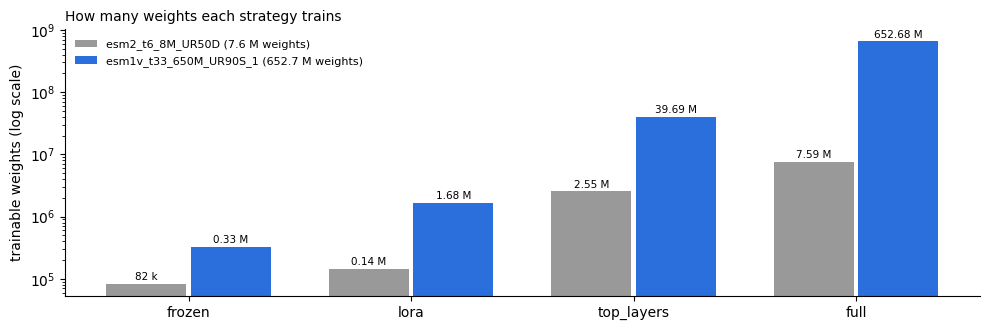

2. esm2_t6_8M_UR50D: LoRA at start vs plain backbone, largest difference = 0.0e+00


/Users/awlehr/miniconda3/envs/LehrPDI/lib/python3.10/site-packages/esm/pretrained.py:215: UserWarning: Regression weights not found, predicting contacts will not produce correct results.
  warnings.warn(


2. esm1v_t33_650M_UR90S_1: LoRA at start vs plain backbone, largest difference = 0.0e+00
3. prediction shape (4, 1024) (= tokens) | loss 0.0287 | 28 weight tensors got gradients, e.g. backbone.layers.0.self_attn.v_proj.A, head.3.bias | frozen tensors with gradients: 0


In [78]:
# test model.py: weight counts per strategy, LoRA starting point, and one manual training step
spec = importlib.util.spec_from_file_location("model", os.path.join(SRC_DIR, "model.py"))   # the FILE, as train.py uses it
tm = importlib.util.module_from_spec(spec); spec.loader.exec_module(tm)

# 1. trainable weights per strategy
counts = {}
for esm_name in ["esm2_t6_8M_UR50D", "esm1v_t33_650M_UR90S_1"]:
    for strategy in ["frozen", "top_layers", "lora", "full"]:
        m = tm.ToleranceModel(esm_name, strategy=strategy)
        counts[(esm_name, strategy)] = tm.count_parameters(m)
        del m                                               # free memory before the next one
count_df = pd.DataFrame([{"backbone": k[0], "strategy": k[1], "total": v[0], "trainable": v[1],
                          "% trainable": round(100 * v[1] / v[0], 3)} for k, v in counts.items()])
print(count_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.4))
strategies_order = ["frozen", "lora", "top_layers", "full"]
for k, (esm_name, color) in enumerate([("esm2_t6_8M_UR50D", "0.6"), ("esm1v_t33_650M_UR90S_1", "#2a6fdb")]):
    vals = [counts[(esm_name, s)][1] for s in strategies_order]
    bars = ax.bar(np.arange(4) + (k - 0.5) * 0.38, vals, width=0.36, color=color,
                  label=f"{esm_name} ({counts[(esm_name, 'full')][0] / 1e6:,.1f} M weights)")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.15, f"{v / 1e6:.2f} M" if v >= 1e5 else f"{v / 1e3:.0f} k",
                ha="center", fontsize=7.5)
ax.set_yscale("log"); ax.set_xticks(range(4), strategies_order)
ax.set_ylabel("trainable weights (log scale)")
ax.set_title("How many weights each strategy trains", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

# 2. LoRA's starting point equals the untouched backbone (B = 0), for ESM-2 and for ESM-1v (fast path off)
for esm_name in ["esm2_t6_8M_UR50D", "esm1v_t33_650M_UR90S_1"]:
    plain = tm.ToleranceModel(esm_name, strategy="frozen").eval()
    lora = tm.ToleranceModel(esm_name, strategy="lora").eval()
    _, _, t = plain.alphabet.get_batch_converter()([("x", seq[:120])])
    with torch.no_grad():
        a = plain.backbone(t, repr_layers=[plain.n_layers])["representations"][plain.n_layers]
        b = lora.backbone(t, repr_layers=[lora.n_layers])["representations"][lora.n_layers]
    print(f"2. {esm_name}: LoRA at start vs plain backbone, largest difference = {(a - b).abs().max():.1e}")
    del plain, lora

# 3. one manual training step on a real batch from §11
small = tm.ToleranceModel("esm2_t6_8M_UR50D", strategy="lora").to(device)
small.train()
pred = small(batch["tokens"].to(device))                  # forward pass
loss = tm.masked_loss(pred, batch["target"].to(device), batch["mask"].to(device))
loss.backward()                                            # backward pass: fills .grad for trainable weights
with_grad = [n for n, p in small.named_parameters() if p.grad is not None]
frozen_with_grad = [n for n, p in small.named_parameters() if not p.requires_grad and p.grad is not None]
print(f"3. prediction shape {tuple(pred.shape)} (= tokens) | loss {loss.item():.4f} | "
      f"{len(with_grad)} weight tensors got gradients, e.g. {with_grad[0]}, {with_grad[-1]} | "
      f"frozen tensors with gradients: {len(frozen_with_grad)}")
assert not frozen_with_grad
assert all(n.startswith("head.") or n.endswith((".A", ".B")) for n in with_grad), "a frozen ESM weight received a gradient"
del small

### 12g. How training proceeds

**Mini-batches and steps.**
- The training proteins are shuffled and dealt out in batches of `batch_size` windows.
- After each batch: forward → loss → backward. The gradients can be added up over `grad_accum` batches before the weights actually move, one **optimizer step**. That gives the stability of a bigger batch without needing GPU memory for it all at once.
- One pass over all training proteins is an **epoch**. Training runs for `epochs` of them, typically 10–30.

**The optimizer: AdamW.**
- It moves each weight a little against its gradient, adapting the step size per weight.
- **Weight decay** gently pulls weights towards zero, another guard against overfitting.
- The **head** gets a larger learning rate (`lr_head`) than the **backbone** add-ons (`lr_backbone`): the head starts from random and must move far, while ESM's knowledge should only be adjusted gently.

**Learning-rate schedule.** The learning rate isn't constant (figure in 12i):
- **Warm-up:** it rises from 0 over the first 5% of steps, so the random head can't make wild early updates.
- **Cosine decay:** it then falls smoothly, so the model settles with ever smaller steps.

**Gradient clipping.** If one unusual batch produces a huge gradient, it's scaled down, so a single bad batch can't wreck the weights.

**Mixed precision.** On Biowulf's GPUs the heavy maths runs in 16-bit "bfloat16" numbers: about half the memory and twice the speed, at no practical cost. On a Mac everything stays 32-bit.

**After every epoch: validation.**
- The model predicts every **validation** protein (fixed tiles, stitched back together, §11), *without* learning from them.
- It records the loss, the Pearson and Spearman correlations between predicted and true tolerance, and the median per-protein Spearman. The per-protein measure is the one that matters most, since the model is meant to rank regions within a protein.
- `last.pt` is always saved, so an interrupted run can resume. `best.pt` is saved whenever the monitored measure (`monitor`, default validation Spearman) improves.

**Early stopping.** Training loss keeps falling as the model memorises its training proteins; validation performance eventually stops improving and gets worse. That's overfitting. If validation hasn't improved for `patience` epochs, training stops. Either way **`best.pt` is the model you keep**, not the last one. The figure illustrates the typical pattern. Real curves come from `metrics.csv` in §13 (smoke test) and §15–16 (Biowulf).

**What's deliberately *not* used here:** the **test** split. It's touched once, at the very end (§16), so its numbers are an honest estimate of performance on unseen proteins.

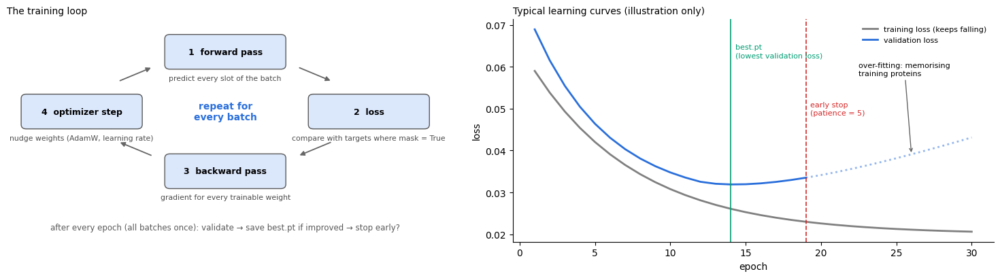

In [79]:
# the training loop as a cycle, and what over-fitting looks like (illustration, not real data)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
steps = [("1  forward pass", "predict every slot of the batch"),
         ("2  loss", "compare with targets where mask = True"),
         ("3  backward pass", "gradient for every trainable weight"),
         ("4  optimizer step", "nudge weights (AdamW, learning rate)")]
angles = np.deg2rad([90, 0, -90, 180])
for (title, sub), a in zip(steps, angles):
    x, y = 2.3 * np.cos(a), 1.1 * np.sin(a)
    box(ax, x - 0.95, y - 0.3, 1.9, 0.6, title, "#dbe7fb")
    ax.text(x, y - 0.42, sub, ha="center", va="top", fontsize=7.8, color="0.3")
for a0, a1 in zip(angles, np.roll(angles, -1)):            # arrows between consecutive steps
    p0 = np.array([2.3 * np.cos(a0), 1.1 * np.sin(a0)]); p1 = np.array([2.3 * np.cos(a1), 1.1 * np.sin(a1)])
    mid = (p0 + p1) / 2 * 1.25
    ax.annotate("", xy=mid + (p1 - p0) * 0.12, xytext=mid - (p1 - p0) * 0.12,
                arrowprops=dict(arrowstyle="-|>", color="0.4", lw=1.3))
ax.text(0, 0, "repeat for\nevery batch", ha="center", va="center", fontsize=10, fontweight="bold", color="#2a6fdb")
ax.text(0, -2.05, "after every epoch (all batches once): validate → save best.pt if improved → stop early?",
        ha="center", va="top", fontsize=8.5, color="0.35")
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-2.4, 1.7); ax.axis("off")
ax.set_title("The training loop", loc="left", fontsize=10)

ax = axes[1]                                               # illustrative learning curves
ep = np.arange(1, 31)
train_curve = 0.045 * np.exp(-ep / 7) + 0.020
val_curve = 0.050 * np.exp(-ep / 5) + 0.028 + 0.00035 * np.clip(ep - 12, 0, None) ** 1.3
best_ep = int(ep[np.argmin(val_curve)]); stop_ep = best_ep + 5
ax.plot(ep, train_curve, color="0.5", lw=2, label="training loss (keeps falling)")
ax.plot(ep[:stop_ep], val_curve[:stop_ep], color="#2a6fdb", lw=2, label="validation loss")
ax.plot(ep[stop_ep - 1:], val_curve[stop_ep - 1:], color="#2a6fdb", lw=2, ls=":", alpha=0.5)
ax.axvline(best_ep, color="#009E73", lw=1.2); ax.axvline(stop_ep, color="#d62728", lw=1.2, ls="--")
ax.text(best_ep + 0.3, val_curve.max() * 0.95, "best.pt\n(lowest validation loss)", color="#009E73", fontsize=8, va="top")
ax.text(stop_ep + 0.3, val_curve.max() * 0.75, f"early stop\n(patience = 5)", color="#d62728", fontsize=8, va="top")
ax.annotate("over-fitting: memorising\ntraining proteins", xy=(26, val_curve[25]), xytext=(22.5, 0.058),
            fontsize=8, arrowprops=dict(arrowstyle="->", color="0.4"))
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Typical learning curves (illustration only)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 12h. `train.py`

The cell below writes the training script to `tolerance_job/src/train.py`. It's what Biowulf runs. It imports `dataset.py` (§11) and `model.py` (12e), reads every setting from a config file (12i), and implements exactly the procedure in 12g:
- **Setup:** choose the device (GPU → Apple GPU → CPU) and the random seed; load `dataset_info.json` and `train.pt`/`val.pt`; build the Datasets and DataLoaders.
- **Model and optimizer:** build the model; check that its alphabet matches the one used in §11; set up AdamW with separate learning rates for head and backbone, plus the warm-up + cosine schedule.
- **Each epoch:** the batch loop (forward → loss → backward → step, with gradient accumulation and clipping), then `evaluate()`: predict all validation tiles, stitch them, compute the metrics.
- **Bookkeeping:**
  - `metrics.csv`: one row per epoch;
  - `last.pt`: to resume;
  - `best.pt` and `val_predictions.pt`: the best epoch so far;
  - `config.json` and `run_info.json`: settings, software versions, GPU, numbers of proteins and weights.

It's a normal Python script, run from the `tolerance_job/` folder:
```
python src/train.py --config configs/smoke.json --out runs/smoke
```
`python src/train.py --help` lists the options. Tested on this Mac: trains, validates, saves checkpoints, and resumes with `--resume`.

In [ ]:
%%writefile ../results/tolerance_model/tolerance_job/src/train.py
"""train.py -- fine-tune the tolerance model. Run from inside the tolerance_job/ folder:

    python src/train.py --config configs/smoke.json --out runs/smoke             # tiny local test (§13)
    python src/train.py --config configs/full.json  --out runs/$SLURM_JOB_ID     # the real run on Biowulf (§15)
    python src/train.py --config configs/full.json  --out runs/<id> --resume     # continue an interrupted run

Every epoch: train on all training proteins once, then predict every validation protein (fixed tiles,
stitched back together), log the metrics, save `last.pt` (to resume) and, if validation improved, `best.pt`.
Outputs in --out: config.json, run_info.json, metrics.csv, last.pt, best.pt, val_predictions.pt
"""
import argparse, contextlib, csv, json, math, os, platform, random, subprocess, sys, time

import numpy as np
import torch
from torch.utils.data import DataLoader

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))   # so dataset.py / model.py import from src/
from dataset import ToleranceDataset, make_collate, tile_ownership
from model import ToleranceModel, count_parameters, masked_loss


# ---------------------------------------------------------------- small helpers
def pick_device(requested=None):
    """GPU on Biowulf ('cuda'), Apple GPU on a Mac ('mps'), otherwise the CPU."""
    if requested:
        return torch.device(requested)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed):
    """Same seed -> same random choices (initial head weights, shuffling, crops) -> reproducible runs."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def lr_factor(step, total_steps, warmup_frac=0.05, min_factor=0.05):
    """Learning-rate multiplier for a given optimizer step:
    linear warm-up from 0 to 1 over the first `warmup_frac` of training, then a smooth cosine decay to
    `min_factor`. Warm-up stops the freshly initialised head from making wild early updates; the decay lets
    the model settle into a good solution with ever smaller steps at the end."""
    warmup = max(1, int(warmup_frac * total_steps))
    if step < warmup:
        return (step + 1) / warmup
    progress = min(1.0, (step - warmup) / max(1, total_steps - warmup))
    return min_factor + (1 - min_factor) * 0.5 * (1 + math.cos(math.pi * progress))


def spearman(a, b):
    """Rank correlation without scipy: Pearson correlation of the ranks."""
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])


def autocast(device, enabled):
    """Mixed precision: on a recent NVIDIA GPU, do the heavy maths in bfloat16 (half the memory, ~2x faster).
    Elsewhere (Mac, CPU, older GPUs) everything stays in normal 32-bit precision."""
    if enabled and device.type == "cuda" and torch.cuda.is_bf16_supported():
        return torch.autocast(device_type="cuda", dtype=torch.bfloat16)
    return contextlib.nullcontext()                               # no-op: normal precision


def environment():
    """What produced this run -- saved next to the results so they can be reproduced."""
    info = {"python": platform.python_version(), "torch": torch.__version__, "host": platform.node(),
            "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
    try:
        import esm
        info["esm"] = getattr(esm, "__version__", "?")
        info["git_commit"] = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                            cwd=os.path.dirname(__file__)).stdout.strip() or None
    except Exception:
        pass
    return info


# ---------------------------------------------------------------- evaluation
@torch.no_grad()                                                  # no gradients needed: we only predict
def evaluate(model, loader, records, info, cfg, device):
    """Predict every validation tile, stitch tiles back into one track per protein, and score them."""
    model.eval()                                                  # evaluation mode: dropout switched off
    window = cfg.get("window") or info["max_residues"]
    own = {r["gene"]: {s: (a, b) for s, a, b in tile_ownership(r["length"], window, info["eval_overlap"])}
           for r in records}
    pred_of = {r["gene"]: np.full(r["length"], np.nan, dtype=np.float32) for r in records}
    for batch in loader:
        with autocast(device, cfg.get("amp", True)):
            pred = model(batch["tokens"].to(device)).float().cpu()
        for row, (gene, start) in enumerate(zip(batch["genes"], batch["starts"])):
            values = pred[row][batch["mask"][row]].numpy()       # this tile's per-residue predictions
            a, b = own[gene][start]                               # the residues this tile is responsible for
            pred_of[gene][a:b] = values[a - start:b - start]
    p = np.concatenate([pred_of[r["gene"]] for r in records])
    t = np.concatenate([r["target"].numpy() for r in records])
    per_gene = [spearman(pred_of[r["gene"]], r["target"].numpy()) for r in records if r["length"] >= 50]
    metrics = {
        "val_loss": float(masked_loss(torch.tensor(p), torch.tensor(t), torch.ones(len(t)),
                                      cfg.get("loss", "huber"), cfg.get("huber_delta", 0.5))),
        "val_pearson": float(np.corrcoef(p, t)[0, 1]),
        "val_spearman": spearman(p, t),
        "val_gene_spearman_median": float(np.nanmedian(per_gene)),
    }
    return metrics, pred_of


# ---------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--config", required=True, help="JSON file with the settings (see configs/)")
    ap.add_argument("--out", required=True, help="folder for checkpoints and logs")
    ap.add_argument("--resume", action="store_true", help="continue from <out>/last.pt")
    ap.add_argument("--device", default=None, help="force cuda / mps / cpu")
    args = ap.parse_args()

    cfg = json.load(open(args.config))
    os.makedirs(args.out, exist_ok=True)
    set_seed(cfg.get("seed", 0))
    device = pick_device(args.device)
    json.dump(cfg, open(os.path.join(args.out, "config.json"), "w"), indent=1)

    # --- data (paths in the config are relative to the folder you run from: tolerance_job/)
    info = json.load(open(os.path.join(cfg["data_dir"], "dataset_info.json")))
    train_records = torch.load(os.path.join(cfg["data_dir"], "train.pt"), weights_only=True)
    val_records = torch.load(os.path.join(cfg["data_dir"], "val.pt"), weights_only=True)
    if cfg.get("max_proteins"):                                  # smoke tests: a small subset
        train_records = train_records[:cfg["max_proteins"]]
        val_records = val_records[:max(2, cfg["max_proteins"] // 4)]
    window = cfg.get("window") or info["max_residues"]
    collate = make_collate(info["padding_idx"])
    train_loader = DataLoader(ToleranceDataset(train_records, info, train=True, window=window),
                              batch_size=cfg["batch_size"], shuffle=True, collate_fn=collate,
                              num_workers=cfg.get("num_workers", 0), drop_last=False)
    val_loader = DataLoader(ToleranceDataset(val_records, info, train=False, window=window),
                            batch_size=cfg["batch_size"], shuffle=False, collate_fn=collate,
                            num_workers=cfg.get("num_workers", 0))

    # --- model
    model = ToleranceModel(cfg["esm_name"], strategy=cfg["strategy"], n_unfrozen=cfg.get("n_unfrozen", 2),
                           lora_rank=cfg.get("lora_rank", 8), lora_alpha=cfg.get("lora_alpha", 16),
                           lora_targets=cfg.get("lora_targets", ["q_proj", "v_proj"]),
                           head_hidden=cfg.get("head_hidden", 256), dropout=cfg.get("dropout", 0.1)).to(device)
    assert model.alphabet.all_toks == info["alphabet"], "the backbone's alphabet differs from the one used in §11"
    total, trainable = count_parameters(model)

    # --- optimizer: AdamW, with a larger learning rate for the new head than for anything inside ESM
    head_params = [p for p in model.head.parameters()]
    backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
    groups = [{"params": head_params, "lr": cfg["lr_head"]}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": cfg["lr_backbone"]})
    optimizer = torch.optim.AdamW(groups, weight_decay=cfg.get("weight_decay", 0.01))
    accum = cfg.get("grad_accum", 1)                              # batches per optimizer step
    steps_per_epoch = math.ceil(len(train_loader) / accum)
    total_steps = steps_per_epoch * cfg["epochs"]
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: lr_factor(s, total_steps, cfg.get("warmup_frac", 0.05), cfg.get("min_lr_factor", 0.05)))

    # --- resume, or start fresh
    start_epoch, best, bad_epochs, step = 0, -np.inf, 0, 0
    monitor = cfg.get("monitor", "val_spearman")                  # higher = better
    last_path, best_path = os.path.join(args.out, "last.pt"), os.path.join(args.out, "best.pt")
    if args.resume and os.path.exists(last_path):
        ck = torch.load(last_path, map_location="cpu", weights_only=True)
        model.load_state_dict(ck["model"], strict=False)          # only the trainable weights were saved
        optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
        start_epoch, best, bad_epochs, step = ck["epoch"] + 1, ck["best"], ck["bad_epochs"], ck["step"]
        print(f"resumed from epoch {ck['epoch'] + 1}")
    json.dump({"environment": environment(), "device": str(device), "parameters_total": total,
               "parameters_trainable": trainable, "train_proteins": len(train_records),
               "val_proteins": len(val_records), "steps_per_epoch": steps_per_epoch, "total_steps": total_steps},
              open(os.path.join(args.out, "run_info.json"), "w"), indent=1)
    print(f"device {device} | {cfg['esm_name']} ({cfg['strategy']}) | trainable {trainable:,} of {total:,} weights | "
          f"{len(train_records)} train / {len(val_records)} val proteins | {total_steps} optimizer steps")

    log_path = os.path.join(args.out, "metrics.csv")
    fields = ["epoch", "step", "train_loss", "val_loss", "val_pearson", "val_spearman",
              "val_gene_spearman_median", "lr_head", "seconds"]
    if not (args.resume and os.path.exists(log_path)):
        with open(log_path, "w", newline="") as f:
            csv.DictWriter(f, fieldnames=fields).writeheader()

    # --- the training loop
    for epoch in range(start_epoch, cfg["epochs"]):
        model.train()                                             # training mode: dropout on
        t0, running, n_batches = time.time(), 0.0, 0
        optimizer.zero_grad()
        for i, batch in enumerate(train_loader):
            tokens, target, mask = batch["tokens"].to(device), batch["target"].to(device), batch["mask"].to(device)
            with autocast(device, cfg.get("amp", True)):
                pred = model(tokens)                              # 1. forward pass
            loss = masked_loss(pred, target, mask, cfg.get("loss", "huber"), cfg.get("huber_delta", 0.5))   # 2. loss
            (loss / accum).backward()                             # 3. backward pass: gradients for every trainable weight
            running += loss.item(); n_batches += 1
            if (i + 1) % accum == 0 or i + 1 == len(train_loader):
                torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], cfg.get("grad_clip", 1.0))
                optimizer.step()                                  # 4. nudge the weights
                scheduler.step()                                  #    and move along the learning-rate schedule
                optimizer.zero_grad()
                step += 1
            if cfg.get("log_every") and (i + 1) % cfg["log_every"] == 0:
                print(f"  epoch {epoch + 1} batch {i + 1}/{len(train_loader)} loss {running / n_batches:.4f}", flush=True)

        metrics, val_pred = evaluate(model, val_loader, val_records, info, cfg, device)
        row = {"epoch": epoch + 1, "step": step, "train_loss": running / max(n_batches, 1), **metrics,
               "lr_head": optimizer.param_groups[0]["lr"], "seconds": round(time.time() - t0, 1)}
        with open(log_path, "a", newline="") as f:
            csv.DictWriter(f, fieldnames=fields).writerow(row)
        print(" | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()), flush=True)

        improved = metrics[monitor] > best
        if improved:                                              # keep the best version seen so far
            best, bad_epochs = metrics[monitor], 0
            torch.save({"model": model.trainable_state(), "epoch": epoch, "metrics": metrics, "config": cfg}, best_path)
            torch.save(val_pred, os.path.join(args.out, "val_predictions.pt"))
        else:
            bad_epochs += 1
        torch.save({"model": model.trainable_state(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "epoch": epoch, "best": best,
                    "bad_epochs": bad_epochs, "step": step}, last_path)
        if bad_epochs >= cfg.get("patience", 5):                  # early stopping: validation stopped improving
            print(f"stopping early: no improvement in {monitor} for {bad_epochs} epochs")
            break
    print(f"done. best {monitor} = {best:.4f} -> {best_path}")


if __name__ == "__main__":
    main()

### 12i. Configs: every setting in one file

A **config** is a small text file listing every training setting. Keeping settings out of the code means that changing a learning rate never touches `train.py`, and every run saves the exact config it used. Two are written here:
- **`configs/smoke.json`:** tiny and fast, for checking that everything runs (§13). ESM-2 8M, 24 proteins, 256-residue windows, 2 epochs; under a minute on a Mac.
- **`configs/full.json`:** the real run on Biowulf (§15). ESM-2 650M with LoRA, all training proteins, 20 epochs (early stopping usually ends sooner).

| setting | meaning |
|---|---|
| `esm_name`, `strategy` | backbone, and what may change (12d); `n_unfrozen` for `top_layers`; `lora_rank`, `lora_alpha`, `lora_targets` for `lora` |
| `head_hidden`, `dropout` | head size, and the dropout rate |
| `loss`, `huber_delta` | the cost rule (12c) |
| `epochs`, `batch_size`, `grad_accum` | windows per batch, and batches per optimizer step (effective batch = product) |
| `lr_head`, `lr_backbone`, `weight_decay` | learning rates and weight decay for AdamW |
| `warmup_frac`, `min_lr_factor` | learning-rate schedule (figure below) |
| `grad_clip`, `amp` | gradient clipping, and mixed precision on GPUs |
| `monitor`, `patience` | which validation measure picks `best.pt`, and early stopping |
| `window`, `max_proteins` | smoke-test shortcuts: smaller windows and fewer proteins (`null` = everything) |
| `num_workers`, `log_every`, `seed`, `data_dir` | data-loading processes, progress messages, randomness, where the data is |

**Why ESM-2 650M and not ESM-1v?** §4 scored with ESM-1v, which was trained specifically for zero-shot variant scoring. ESM-2 is the newer general model and the usual base for fine-tuning. Both share the alphabet, so the data from §11 works with either: set `esm_name` to compare.

wrote ['full.json', 'smoke.json']


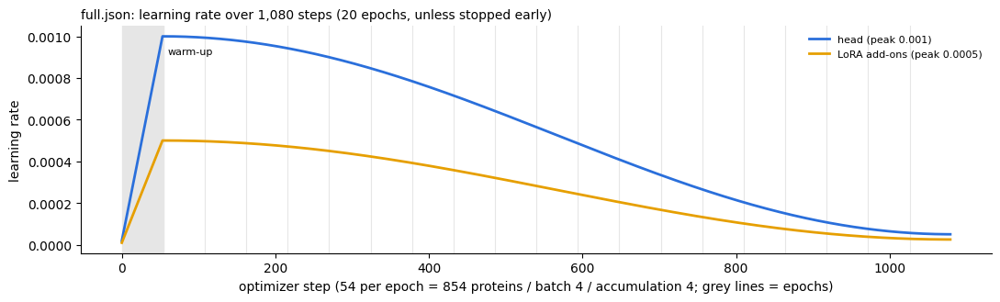

files in tolerance_job/: {'data': ['dataset_info.json', 'split_manifest.json', 'test.pt', 'train.pt', 'val.pt'], 'src': ['__pycache__', 'dataset.py', 'model.py', 'train.py'], 'configs': ['full.json', 'smoke.json']}


In [81]:
# write the two configs, then show the learning-rate schedule they produce
CONFIG_DIR = os.path.join(JOB_DIR, "configs")
os.makedirs(CONFIG_DIR, exist_ok=True)
common = {"data_dir": "data", "lora_targets": ["q_proj", "v_proj"], "lora_alpha": 16, "dropout": 0.1,
          "loss": "huber", "huber_delta": 0.5, "weight_decay": 0.01, "warmup_frac": 0.05, "min_lr_factor": 0.05,
          "grad_clip": 1.0, "amp": True, "monitor": "val_spearman", "seed": SEED}
configs = {
    "smoke": {**common, "esm_name": "esm2_t6_8M_UR50D", "strategy": "lora", "lora_rank": 8, "head_hidden": 64,
              "epochs": 2, "batch_size": 4, "grad_accum": 1, "lr_head": 1e-3, "lr_backbone": 5e-4,
              "patience": 5, "num_workers": 0, "max_proteins": 24, "window": 256, "log_every": 0, "warmup_frac": 0.1},
    "full":  {**common, "esm_name": "esm2_t33_650M_UR50D", "strategy": "lora", "lora_rank": 8, "head_hidden": 256,
              "epochs": 20, "batch_size": 4, "grad_accum": 4, "lr_head": 1e-3, "lr_backbone": 5e-4,
              "patience": 5, "num_workers": 4, "max_proteins": None, "window": None, "log_every": 50},
}
for name, cfg in configs.items():
    with open(os.path.join(CONFIG_DIR, f"{name}.json"), "w") as f:
        json.dump(cfg, f, indent=1)
print("wrote", sorted(os.listdir(CONFIG_DIR)))

# the learning-rate schedule, computed with train.py's own function
spec = importlib.util.spec_from_file_location("train", os.path.join(SRC_DIR, "train.py"))
train_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(train_mod)
full = configs["full"]
n_train = dataset_info["counts"]["train"]["proteins"]
steps_per_epoch = int(np.ceil(np.ceil(n_train / full["batch_size"]) / full["grad_accum"]))
total_steps = steps_per_epoch * full["epochs"]
s = np.arange(total_steps)
factor = np.array([train_mod.lr_factor(k, total_steps, full["warmup_frac"], full["min_lr_factor"]) for k in s])

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(s, factor * full["lr_head"], color="#2a6fdb", lw=2, label=f"head (peak {full['lr_head']:g})")
ax.plot(s, factor * full["lr_backbone"], color="#E69F00", lw=2, label=f"LoRA add-ons (peak {full['lr_backbone']:g})")
for e in range(1, full["epochs"]):
    ax.axvline(e * steps_per_epoch, color="0.9", lw=0.8, zorder=0)
ax.axvspan(0, full["warmup_frac"] * total_steps, color="0.9")
ax.text(full["warmup_frac"] * total_steps * 1.1, full["lr_head"] * 0.95, "warm-up", fontsize=8, va="top")
ax.set_xlabel(f"optimizer step ({steps_per_epoch} per epoch = {n_train} proteins / batch {full['batch_size']} / "
              f"accumulation {full['grad_accum']}; grey lines = epochs)")
ax.set_ylabel("learning rate")
ax.set_title(f"full.json: learning rate over {total_steps:,} steps ({full['epochs']} epochs, unless stopped early)",
             loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()
print("files in tolerance_job/:", {d: sorted(os.listdir(os.path.join(JOB_DIR, d))) for d in ["data", "src", "configs"]})

---
## 13. Local smoke test: a dress rehearsal before using Biowulf

**Goal:** prove the whole training pipeline works, start to finish, on your Mac, using a tiny model and a handful of proteins, *before* spending queue time and GPU hours on Biowulf.

**Why bother?** A Biowulf job can wait hours in the queue and then crash in its first minute because of a typo, a missing file, or a path that only exists on your Mac. Every one of those problems shows up here in under a minute. A "smoke test" is named after switching on new electronics to see whether smoke comes out: it doesn't test whether the result is *good*, only whether everything *runs*.

**What this section does:**

| step | question | how |
|---|---|---|
| 13a | Is the job folder self-contained? | list its files, compile the scripts, search for paths that only exist on this Mac |
| 13b | Does training run the way Biowulf will run it? | launch `train.py` as a separate program from the job folder, with `smoke.json` |
| 13c | Did it produce everything it should? | read `metrics.csv`, `run_info.json`, the checkpoints and the validation predictions |
| 13d | Can the model learn at all? | the **overfit test**: memorise two proteins |
| 13e | Does it run on the CPU too? | rerun with `--device cpu` and compare |
| 13f | Can an interrupted run continue? | `--resume` for one more epoch |
| 13g | All good? | a checklist of every result |

**Where results go:** `results/tolerance_model/local_runs/`, *outside* `tolerance_job/`, so the folder that gets copied to Biowulf in §15 stays clean.

**The numbers from these runs mean nothing scientifically.** The smoke test uses the 8-million-weight ESM-2 (80× smaller than the real one), 24 proteins and 2 epochs. Near-zero correlations are expected; they only need to be *numbers*, not errors.

### 13a. Pre-flight: is the job folder self-contained?

On Biowulf, the job folder is all there is: no notebook, no `figures/` modules, nothing under `/Users/awlehr`. Four checks:
1. **Contents:** list every file with its size. This is exactly what will be copied.
2. **Syntax:** compile every `.py` file. A typo would fail here instead of on the cluster.
3. **No Mac-only paths:** search scripts and configs for `/Users/`, `/private/` or this project's folder names, which would break on Biowulf.
4. **No notebook leftovers:** search for variables that only exist in this notebook (`psd_seq_df`, `residue_df`, …). A script that uses one would crash on the cluster.

Every result is also recorded in `CHECKS`, which 13g summarises.

In [ ]:
# pre-flight: list the job folder, compile the scripts, look for Mac-only paths and notebook leftovers
import py_compile, subprocess, sys, shutil

CHECKS = []                                                  # (check, passed?, detail) -- summarised in 13g
def record(name, passed, detail=""):
    CHECKS.append((name, bool(passed), detail))
    print(f"{'PASS' if passed else 'FAIL'}  {name}" + (f"  ({detail})" if detail else ""))

LOCAL_RUNS = os.path.join(OUT, "local_runs")                 # local test results live OUTSIDE the job folder
os.makedirs(LOCAL_RUNS, exist_ok=True)

# 1. what's in the job folder (this is what §15 copies)
print("tolerance_job/")
shipped = []
for root, dirs, files in os.walk(JOB_DIR):                   # walks folder by folder, top down
    dirs[:] = sorted(d for d in dirs if d not in ("__pycache__", "runs"))      # caches / old runs aren't shipped
    depth = 0 if root == JOB_DIR else os.path.relpath(root, JOB_DIR).count(os.sep) + 1
    if root != JOB_DIR:
        print("    " * (depth - 1) + f"├── {os.path.basename(root)}/")
    for f in sorted(files):
        path = os.path.join(root, f); shipped.append(path)
        print("    " * depth + f"├── {f:22s} {os.path.getsize(path) / 1e6:7.2f} MB")
total_mb = sum(os.path.getsize(p) for p in shipped) / 1e6
record("job folder has data/, src/, configs/", all(os.path.isdir(os.path.join(JOB_DIR, d)) for d in ("data", "src", "configs")),
       f"{len(shipped)} files, {total_mb:.1f} MB")

# 2. every script compiles (catches syntax errors before Biowulf does)
scripts = [p for p in shipped if p.endswith(".py")]
errors = []
for p in scripts:
    try:
        py_compile.compile(p, doraise=True)
    except py_compile.PyCompileError as e:
        errors.append(f"{os.path.basename(p)}: {e.msg}")
record("all scripts compile", not errors, "; ".join(errors) or ", ".join(os.path.basename(p) for p in scripts))

# 3 + 4. scan scripts and configs for paths / names that only exist on this Mac or in this notebook
MAC_ONLY = ["/Users/", "/private/", "LehrPDI", "figures/notebooks", "Model Training"]
NOTEBOOK_ONLY = ["psd_seq_df", "residue_df", "missense_df", "variant_df", "MODEL_DIR", "FIGURES"]
hits = {"Mac-only path": [], "notebook variable": []}
for p in shipped:
    if not p.endswith((".py", ".json")) or p.endswith("split_manifest.json"):
        continue
    text = open(p).read()
    hits["Mac-only path"] += [f"{os.path.basename(p)}: {w}" for w in MAC_ONLY if w in text]
    hits["notebook variable"] += [f"{os.path.basename(p)}: {w}" for w in NOTEBOOK_ONLY if w in text]
record("no Mac-only paths in scripts / configs", not hits["Mac-only path"], "; ".join(hits["Mac-only path"]))
record("no notebook-only variables in scripts", not hits["notebook variable"], "; ".join(hits["notebook variable"]))

### 13b. Run the smoke test, the way Biowulf will

On Biowulf, nobody clicks "run cell". A job script runs a command in a terminal, from inside the job folder:
```
cd tolerance_job
python src/train.py --config configs/smoke.json --out <somewhere>
```
This cell does exactly that with Python's `subprocess` module, which launches a **separate program**, as if typed in a terminal:
- `cwd=JOB_DIR` runs it from inside the job folder, so relative paths in the config (`"data_dir": "data"`) resolve the same way they will on Biowulf.
- `sys.executable` is the Python of this notebook's environment, which has `torch` and `esm` installed. On Biowulf the job script activates the cluster's environment instead (§15).
- The program shares **nothing** with the notebook: no variables, no imports. If it works here, it doesn't secretly depend on the notebook.

(In a notebook you could also type `!python src/train.py …`. `subprocess` is used so the output and the exit status can be checked automatically.)

The output prints as the program reports it:
- **first line:** device, model, how many weights are trainable, how many proteins, how many optimizer steps;
- **then one line per epoch:** training loss, the four validation measures, current learning rate, seconds.

An **exit code** of 0 means the program finished without an error.

In [83]:
# launch train.py as a separate program from inside the job folder -- exactly what the Biowulf job will do
def run_training(config_path, out_dir, extra=(), label="", quiet=False):
    '''Run src/train.py in its own process; print its output (quiet: first and last lines only);
    return (exit code, seconds, output text).'''
    cmd = [sys.executable, "src/train.py", "--config", config_path, "--out", out_dir, *extra]
    print("$ " + " ".join(os.path.relpath(c, JOB_DIR) if os.path.isabs(c) and c.startswith(OUT) else c
                          for c in [os.path.basename(cmd[0])] + cmd[1:]))
    t0 = time.time()
    result = subprocess.run(cmd, cwd=JOB_DIR, capture_output=True, text=True)    # waits until it finishes
    seconds = time.time() - t0
    output = result.stdout + result.stderr
    lines = [l for l in output.splitlines()                # the program's own messages (skip library warnings)
             if l.strip() and "Warning" not in l and not l.startswith(" ")]
    if quiet and len(lines) > 5:
        lines = lines[:1] + [f"... {len(lines) - 4} lines ..."] + lines[-3:]
    for line in lines:
        print("   " + line)
    print(f"   -> exit code {result.returncode} after {seconds:.0f} s {label}")
    return result.returncode, seconds, output

SMOKE_OUT = os.path.join(LOCAL_RUNS, "smoke")
shutil.rmtree(SMOKE_OUT, ignore_errors=True)               # start clean, so every file below comes from this run
code, smoke_seconds, smoke_log = run_training("configs/smoke.json", SMOKE_OUT)
record("smoke run finished (exit code 0)", code == 0, f"{smoke_seconds:.0f} s")
if code != 0:
    print(smoke_log[-3000:])                               # the end of the output usually shows the error

$ python src/train.py --config configs/smoke.json --out ../local_runs/smoke
   device mps | esm2_t6_8M_UR50D (lora) | trainable 82,049 of 7,594,523 weights | 24 train / 6 val proteins | 12 optimizer steps
   epoch 1 | step 6 | train_loss 0.0288 | val_loss 0.0388 | val_pearson 0.0802 | val_spearman 0.0759 | val_gene_spearman_median -0.0297 | lr_head 0.0006 | seconds 1.9000
   epoch 2 | step 12 | train_loss 0.0256 | val_loss 0.0385 | val_pearson 0.0695 | val_spearman 0.0678 | val_gene_spearman_median -0.0255 | lr_head 0.0001 | seconds 0.7000
   done. best val_spearman = 0.0759 -> /Users/awlehr/LehrPDI/figures/results/tolerance_model/local_runs/smoke/best.pt
   -> exit code 0 after 5 s 
PASS  smoke run finished (exit code 0)  (5 s)


### 13c. Read what the run produced

`train.py` writes everything into its `--out` folder. The table below says what each file is. Then:
- **`metrics.csv`**, one row per epoch, plotted as learning curves (left). With 2 epochs on the tiny model the curves are short and flat, which is fine.
- **`val_predictions.pt`**, the best model's predicted tolerance for every residue of every validation protein. The right-hand plot overlays prediction and truth for one protein. At smoke-test scale the prediction just hovers around zero (the model has barely learned anything). What matters is that it **exists, has the right length, and contains no NaN**: the stitching of tiles back into whole proteins worked.

The same files and plots will come back from Biowulf in §16, where the numbers do mean something.

              file    size                                                            what it is
       config.json 0.00 MB                            exact settings used (a copy of smoke.json)
     run_info.json 0.00 MB      software versions, device, numbers of proteins / weights / steps
       metrics.csv 0.00 MB                one row per epoch: training loss + validation measures
           best.pt 0.34 MB   trainable weights at the best validation score (the model you keep)
           last.pt 1.01 MB         weights + optimizer state after the last epoch (for --resume)
val_predictions.pt 0.01 MB best model's prediction for every residue of every validation protein
PASS  all expected output files written

run_info: {'device': 'mps', 'parameters_trainable': 82049, 'parameters_total': 7594523, 'train_proteins': 24, 'val_proteins': 6, 'total_steps': 12}
 epoch  step  train_loss  val_loss  val_pearson  val_spearman  val_gene_spearman_median  lr_head  seconds
     1     6      0.0288  

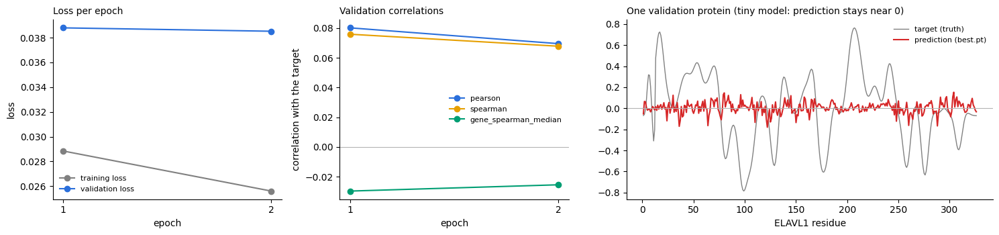

In [84]:
# what the run produced: files, run info, learning curves, and the validation predictions
FILE_NOTES = {"config.json": "exact settings used (a copy of smoke.json)",
              "run_info.json": "software versions, device, numbers of proteins / weights / steps",
              "metrics.csv": "one row per epoch: training loss + validation measures",
              "best.pt": "trainable weights at the best validation score (the model you keep)",
              "last.pt": "weights + optimizer state after the last epoch (for --resume)",
              "val_predictions.pt": "best model's prediction for every residue of every validation protein"}
present = {f: os.path.getsize(os.path.join(SMOKE_OUT, f)) for f in os.listdir(SMOKE_OUT)}
print(pd.DataFrame([{"file": f, "size": f"{present.get(f, 0) / 1e6:.2f} MB" if f in present else "MISSING",
                     "what it is": note} for f, note in FILE_NOTES.items()]).to_string(index=False))
record("all expected output files written", set(FILE_NOTES) <= set(present),
       ", ".join(sorted(set(FILE_NOTES) - set(present))) or "")

run_info = json.load(open(os.path.join(SMOKE_OUT, "run_info.json")))
print("\nrun_info:", {k: run_info[k] for k in ["device", "parameters_trainable", "parameters_total",
                                               "train_proteins", "val_proteins", "total_steps"]})
metrics = pd.read_csv(os.path.join(SMOKE_OUT, "metrics.csv"))
print(metrics.round(4).to_string(index=False))
record("metrics are finite numbers", np.isfinite(metrics.drop(columns=["epoch", "step"]).to_numpy()).all())

val_pred = torch.load(os.path.join(SMOKE_OUT, "val_predictions.pt"), weights_only=False)   # {gene: array per residue}
val_recs = {r["gene"]: r for r in torch.load(os.path.join(DATA_DIR, "val.pt"), weights_only=True)}
lengths_ok = all(len(v) == val_recs[g]["length"] and np.isfinite(v).all() for g, v in val_pred.items())
record("a finite prediction for every residue of every validation protein", lengths_ok,
       f"{len(val_pred)} proteins, {sum(len(v) for v in val_pred.values()):,} residues")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.6]})
axes[0].plot(metrics.epoch, metrics.train_loss, "o-", color="0.5", label="training loss")
axes[0].plot(metrics.epoch, metrics.val_loss, "o-", color="#2a6fdb", label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Loss per epoch", loc="left", fontsize=10)
for col, color in [("val_pearson", "#2a6fdb"), ("val_spearman", "#E69F00"), ("val_gene_spearman_median", "#009E73")]:
    axes[1].plot(metrics.epoch, metrics[col], "o-", color=color, label=col.replace("val_", ""))
axes[1].axhline(0, color="0.7", lw=0.8)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("correlation with the target")
axes[1].legend(frameon=False, fontsize=8); axes[1].set_title("Validation correlations", loc="left", fontsize=10)
gene = max(val_pred, key=len)                              # the longest validation protein of the smoke run
x = np.arange(1, len(val_pred[gene]) + 1)
axes[2].plot(x, val_recs[gene]["target"].numpy(), color="0.5", lw=1, label="target (truth)")
axes[2].plot(x, val_pred[gene], color="#d62728", lw=1.5, label="prediction (best.pt)")
axes[2].axhline(0, color="0.7", lw=0.8)
axes[2].set_xlabel(f"{gene} residue"); axes[2].legend(frameon=False, fontsize=8)
axes[2].set_title("One validation protein (tiny model: prediction stays near 0)", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
for a in axes[:2]: a.set_xticks(metrics.epoch)                     # whole epochs only
fig.tight_layout(); plt.show()

### 13d. The overfit test: can the model learn *anything*?

A model that can't learn the training data perfectly when given far more than enough chances is broken: gradients not flowing, everything accidentally frozen, the loss not connected to the predictions, a learning rate of zero, a mask that's all False. **Overfitting on purpose** is the standard way to rule these out:
- **Train on just two short proteins** (under 256 residues, so each fits in one window) **for 150 epochs** with LoRA, the same strategy as the real run. Dropout is off, the loss is plain MSE and the LoRA learning rate is higher than usual, so nothing stops it from memorising (about 20 seconds).
- **Validate on the same two proteins.** Normally a mistake; here it's the point. We *want* to see the training data reproduced.

**Pass** = the training loss falls at least 100-fold and the prediction lies on top of the target (Pearson > 0.95). The data and config for this test are built in `local_runs/` and never shipped.

**What it can't catch:** misaligned targets. A model could memorise values shifted by one residue just as easily. That's why §11 checked the alignment directly. It also says nothing about **generalisation** (new proteins); that's the job of validation in the real run.

memorising ANAPC10 (185 aa), KCNIP1 (216 aa) for 150 epochs
$ python src/train.py --config ../local_runs/overfit_config.json --out ../local_runs/overfit
   device mps | esm2_t6_8M_UR50D (lora) | trainable 82,049 of 7,594,523 weights | 2 train / 2 val proteins | 150 optimizer steps
   ... 148 lines ...
   epoch 149 | step 149 | train_loss 0.0000 | val_loss 0.0000 | val_pearson 0.9996 | val_spearman 0.9993 | val_gene_spearman_median 0.9992 | lr_head 0.0001 | seconds 0.1000
   epoch 150 | step 150 | train_loss 0.0000 | val_loss 0.0000 | val_pearson 0.9996 | val_spearman 0.9993 | val_gene_spearman_median 0.9992 | lr_head 0.0001 | seconds 0.1000
   done. best val_spearman = 0.9993 -> /Users/awlehr/LehrPDI/figures/results/tolerance_model/local_runs/overfit/best.pt
   -> exit code 0 after 19 s (overfit test)
PASS  overfit test: training loss falls at least 100-fold  (0.0733 -> 4.7e-05 (1,548x))
PASS  overfit test: predictions reproduce the targets (Pearson > 0.95)  (best Pearson 1.000)


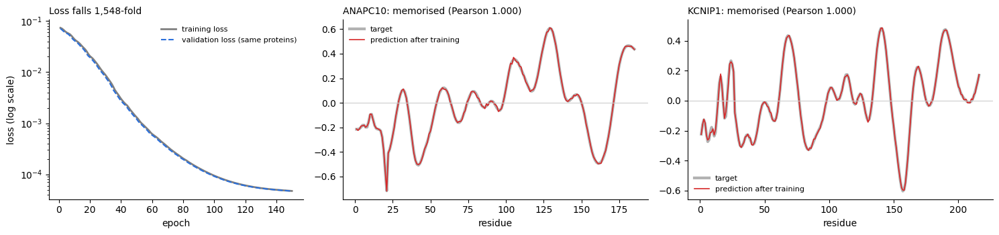

In [85]:
# overfit test: two short proteins as both training and validation data, 150 epochs, LoRA
OVERFIT_DIR = os.path.join(LOCAL_RUNS, "overfit_data")
os.makedirs(OVERFIT_DIR, exist_ok=True)
train_all = torch.load(os.path.join(DATA_DIR, "train.pt"), weights_only=True)
short = sorted([r for r in train_all if 150 <= r["length"] <= 250], key=lambda r: r["length"])
pair = [short[len(short) // 3], short[2 * len(short) // 3]]          # two short training proteins
for name in ("train.pt", "val.pt"):                                  # the SAME two proteins in both
    torch.save(pair, os.path.join(OVERFIT_DIR, name))
shutil.copy(os.path.join(DATA_DIR, "dataset_info.json"), OVERFIT_DIR)

overfit_cfg = {**configs["smoke"], "data_dir": OVERFIT_DIR, "epochs": 150, "batch_size": 2, "max_proteins": None,
               "window": 256, "dropout": 0.0, "loss": "mse", "patience": 10_000, "warmup_frac": 0.05,
               "lr_backbone": 1e-3}                                   # bolder LoRA learning rate: memorise fast
overfit_cfg_path = os.path.join(LOCAL_RUNS, "overfit_config.json")
json.dump(overfit_cfg, open(overfit_cfg_path, "w"), indent=1)
OVERFIT_OUT = os.path.join(LOCAL_RUNS, "overfit")
shutil.rmtree(OVERFIT_OUT, ignore_errors=True)
names = ", ".join(f"{r['gene']} ({r['length']} aa)" for r in pair)
print(f"memorising {names} for {overfit_cfg['epochs']} epochs")
code, overfit_seconds, overfit_log = run_training(overfit_cfg_path, OVERFIT_OUT, label="(overfit test)", quiet=True)

om = pd.read_csv(os.path.join(OVERFIT_OUT, "metrics.csv"))
drop = om.train_loss.iloc[0] / max(om.train_loss.iloc[-1], 1e-12)   # how many times smaller the loss became
record("overfit test: training loss falls at least 100-fold", code == 0 and drop >= 100,
       f"{om.train_loss.iloc[0]:.4f} -> {om.train_loss.iloc[-1]:.1e} ({drop:,.0f}x)")
record("overfit test: predictions reproduce the targets (Pearson > 0.95)", om.val_pearson.max() > 0.95,
       f"best Pearson {om.val_pearson.max():.3f}")

memorised = torch.load(os.path.join(OVERFIT_OUT, "val_predictions.pt"), weights_only=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1.2]})
axes[0].semilogy(om.epoch, om.train_loss, color="0.5", lw=2, label="training loss")
axes[0].semilogy(om.epoch, om.val_loss, color="#2a6fdb", lw=1.5, ls="--", label="validation loss (same proteins)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (log scale)"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title(f"Loss falls {drop:,.0f}-fold", loc="left", fontsize=10)
for ax, rec in zip(axes[1:], pair):
    x = np.arange(1, rec["length"] + 1)
    ax.plot(x, rec["target"].numpy(), color="0.5", lw=3, alpha=0.6, label="target")
    ax.plot(x, memorised[rec["gene"]], color="#d62728", lw=1.2, label="prediction after training")
    ax.axhline(0, color="0.8", lw=0.8)
    r = np.corrcoef(memorised[rec["gene"]], rec["target"].numpy())[0, 1]
    ax.set_title(f"{rec['gene']}: memorised (Pearson {r:.3f})", loc="left", fontsize=10)
    ax.set_xlabel("residue"); ax.legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 13e. Does it run on the CPU too?

Biowulf's GPUs are NVIDIA (`cuda`), your Mac's is Apple (`mps`), and some cluster nodes have no GPU at all (`cpu`). `train.py` picks whichever is available, but `--device cpu` forces the CPU. Running the smoke test again on the CPU proves nothing in the code is tied to the Mac's GPU.

**Expect results that are close but not identical.** Different hardware does floating-point arithmetic in slightly different orders, so tiny rounding differences appear and grow a little over training steps. Differences in the third decimal place are normal; an error or wildly different numbers are not.

The bars compare seconds per epoch. Epoch 1 includes one-off start-up costs, so the last epoch is the fair comparison. The GPU is faster even for this tiny model, and its advantage grows enormously with the 650M model.

$ python src/train.py --config configs/smoke.json --out ../local_runs/smoke_cpu --device cpu
   device cpu | esm2_t6_8M_UR50D (lora) | trainable 82,049 of 7,594,523 weights | 24 train / 6 val proteins | 12 optimizer steps
   epoch 1 | step 6 | train_loss 0.0293 | val_loss 0.0385 | val_pearson 0.0727 | val_spearman 0.0748 | val_gene_spearman_median -0.0203 | lr_head 0.0006 | seconds 2.3000
   epoch 2 | step 12 | train_loss 0.0280 | val_loss 0.0390 | val_pearson 0.0647 | val_spearman 0.0657 | val_gene_spearman_median -0.0254 | lr_head 0.0001 | seconds 2.0000
   done. best val_spearman = 0.0748 -> /Users/awlehr/LehrPDI/figures/results/tolerance_model/local_runs/smoke_cpu/best.pt
   -> exit code 0 after 6 s (CPU)
PASS  smoke run on CPU finished (--device cpu)  (6 s)
       val_loss (mps)  val_spearman (mps)  val_loss (cpu)  val_spearman (cpu)
epoch                                                                        
1              0.0388              0.0759          0.0385              

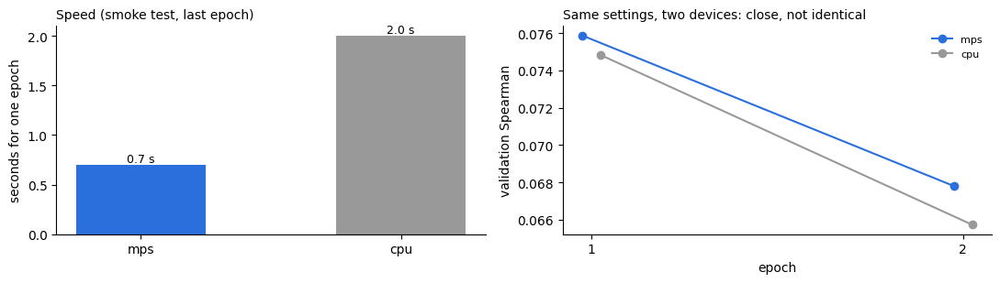

In [86]:
# rerun the smoke test on the CPU and compare with the Apple-GPU run from 13b
CPU_OUT = os.path.join(LOCAL_RUNS, "smoke_cpu")
shutil.rmtree(CPU_OUT, ignore_errors=True)
code, cpu_seconds, cpu_log = run_training("configs/smoke.json", CPU_OUT, extra=["--device", "cpu"], label="(CPU)")
record("smoke run on CPU finished (--device cpu)", code == 0, f"{cpu_seconds:.0f} s")

cpu_metrics = pd.read_csv(os.path.join(CPU_OUT, "metrics.csv"))
compare = metrics.set_index("epoch")[["val_loss", "val_spearman"]].join(
    cpu_metrics.set_index("epoch")[["val_loss", "val_spearman"]], lsuffix=f" ({run_info['device']})", rsuffix=" (cpu)")
print(compare.round(4).to_string())
largest = (metrics.val_spearman - cpu_metrics.val_spearman).abs().max()
record("CPU and GPU runs agree closely", largest < 0.05, f"largest Spearman difference {largest:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
devices = [run_info["device"], "cpu"]
sec = [metrics.seconds.iloc[-1], cpu_metrics.seconds.iloc[-1]]          # last epoch: no start-up cost
axes[0].bar(devices, sec, color=["#2a6fdb", "0.6"], width=0.5)
for i, v in enumerate(sec):
    axes[0].text(i, v, f"{v:.1f} s", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("seconds for one epoch"); axes[0].set_title("Speed (smoke test, last epoch)", loc="left", fontsize=10)
for k, (m, color) in enumerate([(metrics, "#2a6fdb"), (cpu_metrics, "0.6")]):
    axes[1].plot(m.epoch + (k - 0.5) * 0.05, m.val_spearman, "o-", color=color, label=devices[k])
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation Spearman"); axes[1].set_xticks(metrics.epoch)
axes[1].set_title("Same settings, two devices: close, not identical", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 13f. Can an interrupted run continue? (`--resume`)

Biowulf jobs have a **time limit**. A run that hits it is stopped mid-training. Without resuming, the hours spent so far would be lost. After every epoch, `train.py` saves `last.pt`: the weights, the optimizer's internal state, the learning-rate schedule position, the epoch number and the best score so far. Started again with `--resume`, it picks up from the next epoch as if nothing had happened.

The test: copy the smoke config with one extra epoch and resume the 13b run. Pass = `metrics.csv` gains exactly **one** new row, numbered epoch 3, with the step counter continuing where it stopped, and nothing earlier is redone.

In [87]:
# resume the 13b run for one extra epoch
resume_cfg = {**configs["smoke"], "epochs": configs["smoke"]["epochs"] + 1}
resume_cfg_path = os.path.join(LOCAL_RUNS, "smoke_resume_config.json")      # outside the job folder: not shipped
json.dump(resume_cfg, open(resume_cfg_path, "w"), indent=1)
before = pd.read_csv(os.path.join(SMOKE_OUT, "metrics.csv"))
code, _, resume_log = run_training(resume_cfg_path, SMOKE_OUT, extra=["--resume"], label="(resume)")
after = pd.read_csv(os.path.join(SMOKE_OUT, "metrics.csv"))
print(after[["epoch", "step", "train_loss", "val_spearman"]].round(4).to_string(index=False))
new_rows = after.iloc[len(before):]
ok = (code == 0 and len(new_rows) == 1 and new_rows.epoch.iloc[0] == before.epoch.max() + 1
      and new_rows.step.iloc[0] > before.step.max() and "resumed from epoch" in resume_log)
record("--resume continues with the next epoch", ok,
       f"epochs {before.epoch.tolist()} -> {after.epoch.tolist()}, steps {before.step.max()} -> {after.step.max()}")

$ python src/train.py --config ../local_runs/smoke_resume_config.json --out ../local_runs/smoke --resume
   resumed from epoch 2
   device mps | esm2_t6_8M_UR50D (lora) | trainable 82,049 of 7,594,523 weights | 24 train / 6 val proteins | 18 optimizer steps
   epoch 3 | step 18 | train_loss 0.0263 | val_loss 0.0386 | val_pearson 0.0701 | val_spearman 0.0681 | val_gene_spearman_median -0.0175 | lr_head 0.0001 | seconds 1.8000
   done. best val_spearman = 0.0759 -> /Users/awlehr/LehrPDI/figures/results/tolerance_model/local_runs/smoke/best.pt
   -> exit code 0 after 4 s (resume)
 epoch  step  train_loss  val_spearman
     1     6      0.0288        0.0759
     2    12      0.0256        0.0678
     3    18      0.0263        0.0681
PASS  --resume continues with the next epoch  (epochs [1, 2] -> [1, 2, 3], steps 12 -> 18)


### 13g. Checklist

Every check from 13a–13f in one place. **All green = ready for Biowulf (§15).** Anything red: read the detail column and the program output above it. The usual suspects are a path, a missing file, or a package missing from the environment.

In [ ]:
# the checklist as a figure (green = pass, red = fail)
fig, ax = plt.subplots(figsize=(12, 0.42 * len(CHECKS) + 0.8))
for i, (name, passed, detail) in enumerate(CHECKS):
    y = len(CHECKS) - 1 - i
    ax.add_patch(Rectangle((0, y + 0.1), 0.35, 0.8, color="#2e9d55" if passed else "#d62728"))
    ax.text(0.175, y + 0.5, "✓" if passed else "✗", ha="center", va="center", color="white", fontsize=12, fontweight="bold")
    ax.text(0.5, y + 0.5, name, va="center", fontsize=9.5)
    ax.text(6.2, y + 0.5, detail, va="center", fontsize=8, color="0.4")
ax.set_xlim(0, 12); ax.set_ylim(0, len(CHECKS)); ax.axis("off")
n_pass = sum(p for _, p, _ in CHECKS)
ax.set_title(f"Smoke test: {n_pass} of {len(CHECKS)} checks passed"
             + ("  -> ready for Biowulf (§15)" if n_pass == len(CHECKS) else "  -> fix the red ones first"),
             loc="left", fontsize=10.5)
fig.tight_layout(); plt.show()

---
## 14. Feasibility check: can this target be predicted?

**Why this section exists:** the smoke test (§13) proved the code *runs*; it can't say whether the model will *learn anything useful*, because it used a tiny model on 24 proteins. Before spending GPU hours, cheap analyses on data already in hand answer the real questions. Everything here runs on a laptop:

| step | question | analysis |
|---|---|---|
| 14a | How reproducible is the target itself? | build the tolerance track twice from two random halves of the variants and compare |
| 14b | Does human variant data add information evolution (ESM) misses? | held-out pathogenic vs benign variants: tolerance, ESM, and both combined |
| 14c | Can the target be predicted from sequence for *unseen* proteins? | a **linear probe** on frozen ESM-1v representations, tested on the validation genes |
| 14d | Would more training proteins help? | a **learning curve**: the probe trained on growing fractions of the training genes |
| 14e | So what? | interim conclusions and options for the model |
| 14f | Is the probe's limit the data or the model? | six networks (MLP, CNN, BiLSTM; from scratch and on frozen ESM) on the same target |
| 14g | Which inputs, which target? | ablations: structure / annotation / disorder features; alternative target recipes |
| 14h | Does predicting variant severity directly work better? | pathogenic vs benign ClinVar variants: simple models, trees and neural networks, each variant's own residue hidden |
| 14i | What now? | updated conclusions and a recommendation for §15 |

### Words used below
| word | meaning |
|---|---|
| **split-half reliability** | build a measurement twice from two random halves of the raw data; how well the two agree shows how much is signal vs. chance |
| **noise ceiling** | the best correlation *any* predictor could reach with a noisy target. Even the perfect answer only partly matches a noisy measurement of it |
| **AUROC** | how well a score separates two groups: 0.5 = chance, 1.0 = perfect. Here, pathogenic vs benign ClinVar variants |
| **logistic regression** | the simplest model that combines several scores into one probability (a weighted sum passed through an S-shaped curve) |
| **cross-validation grouped by gene** | fit on some genes, test on others, rotate; a protein never helps score itself |
| **linear probe** | keep ESM completely frozen and fit only a *straight-line* readout (ridge regression) from its 1,280 numbers per residue to the target. If even this finds signal in unseen proteins, the information is in ESM's representations; fine-tuning (§12) can only do better or equal |
| **ridge regression** | linear regression with a penalty on large weights (strength λ) that stops it from overfitting 1,280 features |

### Starting §14 after a kernel restart (optional)

§14 needs only a small part of what §2–§13 build, and running the whole notebook in one session uses a lot of memory: by §12 a kernel holds several ESM models and the 1.3-million-row variant tables. If the kernel has been running for a while, or the computer is slowing down:
1. **Restart the kernel** (VS Code: *Restart* in the notebook toolbar). Keep only one notebook kernel running at a time.
2. Run **§1 (Setup)**.
3. Run the cell below. It reruns the few cheap cells §14 depends on (§2's loading, §3's variant settings and build, §4's ESM summaries from the cache, §6g's held-out variants) by reading them from the saved notebook file, so any setting you changed there is used. Everything else (§5 tables with §7 / §8 columns, §10 split, §11 records) is loaded from the files those sections saved. It takes ~2 min and ~4 GB.
4. Continue with 14a.

This is the recommended way to run **14f–14h**, which add several GB of their own: the full notebook plus 14f–14h in one session can exhaust a 16 GB Mac.

**Save the notebook first** (the cell reads the saved file). Skip this cell if you just ran §2–§13 in this session.

In [2]:
# OPTIONAL, after a kernel restart: rebuild what §14 needs without re-running §2-§13 (~2 min, ~4 GB)
import json, time, esm, importlib.util
from sklearn.metrics import roc_auc_score, roc_curve
from tolerance import build_tolerance_columns, score_variants

NOTEBOOK = "05_tolerance_score_modelling.ipynb"


def rerun(first_line):
    '''Run the code cell of this notebook (as saved on disk) whose text starts with first_line.'''
    cells = json.load(open(NOTEBOOK))["cells"]
    source = next("".join(c["source"]) for c in cells
                  if c["cell_type"] == "code" and "".join(c["source"]).startswith(first_line))
    exec(source, globals())


for first_line in ["psd_seq_df = pd.read_parquet",                 # §2: sequences + disorder
                   "# missense_df + ClinVar labels",                # §2: variants (loads the saved parquet)
                   "# corrected zygosity counts",                   # §2: X-linked fix
                   "# Which variants feed each track",              # §3: settings -> tolerance_variants
                   "# Build tolerance_v4 for every gene",           # §3: ~20 s
                   "# ESM model + log-prob function",               # §4: defines load_esm(); loads no model
                   "# load the cache, compute only what's missing", # §4: cached log-probs
                   "# per-residue summaries",                       # §4: esm_mean_llr, ALPHABET
                   "# per-residue ESM over the substitutions actually observed"]:
    rerun(first_line)

# saved tables: §5 (+ §7 structure, §8 annotations, §10 split columns) and the §10 split
variant_df = pd.read_parquet(os.path.join(OUT, "variant_scores.parquet"))
residue_df = pd.read_parquet(os.path.join(OUT, "residue_scores.parquet"))
psd_seq_df["split"] = psd_seq_df.gene.map(json.load(open(os.path.join(OUT, "split_manifest.json")))["split"])

for first_line in ["# choose the held-out variants",                # §6g: the 10% held out
                   "# rebuild the tracks from the 90%",             # §6g: ~20 s
                   "# score training and held-out variants"]:
    rerun(first_line)
pb = val_scored[(val_scored.database == "ClinVar") & val_scored.clinsig_group.isin(["pathogenic", "benign"])
                & (val_scored.stars >= 1)]                          # §6g's labelled held-out variants

# §11: where the records live, and dataset.py
JOB_DIR = os.path.join(OUT, "tolerance_job")
DATA_DIR, SRC_DIR = os.path.join(JOB_DIR, "data"), os.path.join(JOB_DIR, "src")
spec = importlib.util.spec_from_file_location("dataset", os.path.join(SRC_DIR, "dataset.py"))
dataset = importlib.util.module_from_spec(spec); spec.loader.exec_module(dataset)
info = json.load(open(os.path.join(DATA_DIR, "dataset_info.json")))
print(f"ready for §14: {len(psd_seq_df)} genes, {len(variant_df):,} variants, {len(residue_df):,} residues, "
      f"{len(pb):,} held-out labelled variants")

psd_seq_df: 1082 genes
columns: ['gene', 'transcript_id', 'sequence', 'binding_scores', 'disorder_scores', 'y_diff', 'tolerance_y_BLOSUM62', 'clinvar_y_BLOSUM62', 'gnomad_y_BLOSUM62']
missense_df: 1,288,072 variants in 1078 genes
hemizygous count found in 'heterozygote count' (mislabelled -- original builder)
male share of X alleles: 0.31 (expected 0.33; other column 0.76)
negative derived heterozygotes: 0 | autosomal rows where the original heterozygote column was off: 4,762
gnomAD:    432,831 of 1,081,180 kept
  X / Y-linked: 9,397 of 12,155 with allele count >= 2 (X_MODE = 'hemizygous')
ClinVar:   206,892 of 206,892 kept
convolve_v4 settings: {'window_size': [31, 5], 'matrix': ['blosum62', 'grantham'], 'adjustment_threshold': 0.5, 'aggregate': 'max'}
100/1082 genes
200/1082 genes
300/1082 genes
400/1082 genes
500/1082 genes
600/1082 genes
700/1082 genes
800/1082 genes
900/1082 genes
1000/1082 genes
1070 genes usable, flagged: ['C9ORF72', 'NEDD8', 'MRTFA', 'C22ORF39', 'EIF1', 'STIM2'

### 14a. How reproducible is the target?

Every tolerance track was built from the variants that *happened* to be observed. To see how much of a track is real signal and how much is chance, split the variants randomly into two halves (by variant `id`), build the track separately from each half, and correlate the two tracks **within each gene**. The variant filters are the same as §3 (`tolerance_variants`).

- If the target were pure signal, the two halves would agree closely; if pure chance, not at all.
- Each half has only half the data, so the agreement of the *full* target is estimated with the **Spearman–Brown formula**: reliability = 2r / (1 + r).
- The square root of that reliability is the **noise ceiling**: the highest within-gene correlation a perfect model could reach against this target.

Left: the split-half agreement across genes. Right: one typical gene, both half-tracks overlaid.

split-half agreement (median within-gene Spearman): 0.083 (IQR -0.01 to 0.18, 1070 genes)
estimated reliability of the full target: 0.15 -> noise ceiling for any predictor: 0.39


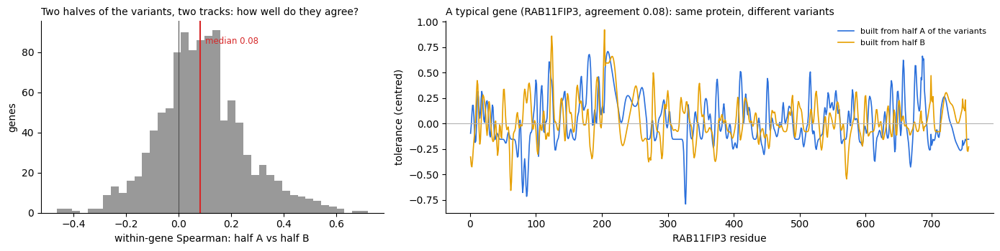

In [3]:
# split-half reliability of the target: build tolerance twice from random halves of the variants
from scipy.stats import spearmanr

usable = psd_seq_df[psd_seq_df.split.isin(["train", "val", "test"])][["gene", "sequence", "disorder_scores"]]
var_ids = tolerance_variants.id.unique()
in_half_a = dict(zip(var_ids, np.random.default_rng(SEED).random(len(var_ids)) < 0.5))   # each variant -> half A or B
half = tolerance_variants.id.map(in_half_a)

def centred_tracks(variants, name):
    '''Build tolerance from these variants only; return {gene: track minus its median} (like the training target).'''
    built = build_tolerance_columns(usable, variants, name=name, gnomad_min_count=0, verbose=False)
    return {g: np.asarray(t) - np.median(t) for g, t in zip(built.gene, built[f"tolerance_{name}"])}

half_a = centred_tracks(tolerance_variants[half], "half_a")                   # ~20 s each
half_b = centred_tracks(tolerance_variants[~half], "half_b")
gene_len = dict(zip(usable.gene, usable.sequence.str.len()))
split_half = pd.Series({g: spearmanr(half_a[g], half_b[g]).statistic for g in half_a
                        if gene_len[g] >= 50 and np.ptp(half_a[g]) > 0 and np.ptp(half_b[g]) > 0})
r_half = split_half.median()
reliability = 2 * r_half / (1 + r_half)                                       # Spearman-Brown: full-data target
NOISE_CEILING = float(np.sqrt(max(reliability, 0)))
print(f"split-half agreement (median within-gene Spearman): {r_half:.3f} "
      f"(IQR {split_half.quantile(.25):.2f} to {split_half.quantile(.75):.2f}, {len(split_half)} genes)")
print(f"estimated reliability of the full target: {reliability:.2f} -> noise ceiling for any predictor: {NOISE_CEILING:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].hist(split_half, bins=40, color="0.6")
axes[0].axvline(0, color="0.3", lw=0.8)
axes[0].axvline(r_half, color="#d62728", lw=1.5)
axes[0].text(r_half + 0.02, axes[0].get_ylim()[1] * 0.92, f"median {r_half:.2f}", color="#d62728", fontsize=8.5, va="top")
axes[0].set_xlabel("within-gene Spearman: half A vs half B"); axes[0].set_ylabel("genes")
axes[0].set_title("Two halves of the variants, two tracks: how well do they agree?", loc="left", fontsize=10)
typical = (split_half[[g for g in split_half.index if 400 <= gene_len[g] <= 900]] - r_half).abs().idxmin()
x = np.arange(1, gene_len[typical] + 1)
axes[1].plot(x, half_a[typical], color="#2a6fdb", lw=1.2, label="built from half A of the variants")
axes[1].plot(x, half_b[typical], color="#E69F00", lw=1.2, label="built from half B")
axes[1].axhline(0, color="0.7", lw=0.8)
axes[1].set_xlabel(f"{typical} residue"); axes[1].set_ylabel("tolerance (centred)")
axes[1].set_title(f"A typical gene ({typical}, agreement {split_half[typical]:.2f}): same protein, different variants",
                  loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 14b. Does human variant data add what evolution (ESM) misses?

This is the core of the hypothesis: human population data (gnomAD) and clinical data (ClinVar) mark constraint that cross-species evolution doesn't fully capture. The test reuses §6g's **held-out** ClinVar variants (pathogenic vs benign, ≥ 1 star). Their tolerance comes from tracks rebuilt *without* them, so no variant scores itself. Three scores are compared:
- **tolerance** at the variant's residue (human variant density);
- **ESM-1v LLR** of the exact substitution (evolution);
- **both combined** with logistic regression, fitted and tested by **cross-validation grouped by gene**, so a gene's own variants never train the combination that scores them.

If the combination beats both, the two carry *different* information. The right-hand plot shows where that comes from. It focuses on the variants ESM considers mild (to the right of the dashed line: LLR above the median of benign variants): are the pathogenic ones among them flagged by low tolerance?

645 pathogenic / 1832 benign held-out variants in 492 genes
{'tolerance (human variants)': 0.847, 'ESM-1v LLR (evolution)': 0.881, 'combined (gene-held-out)': 0.927}
pathogenic variants ESM calls mild: 64 -> 80% have tolerance < 0 (vs 42% of ESM-mild benign variants)


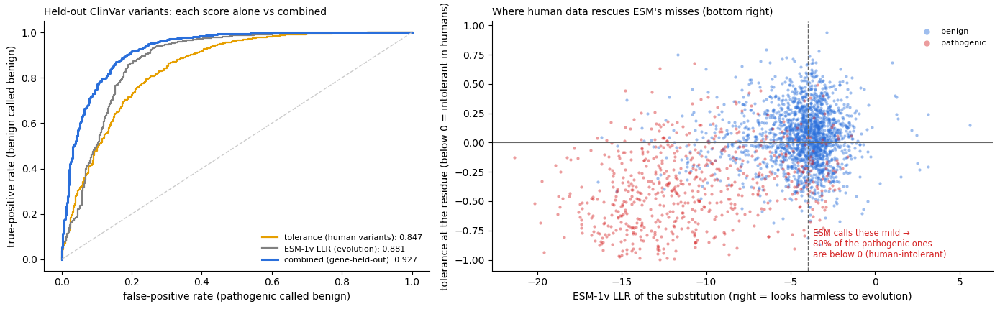

In [4]:
# held-out pathogenic vs benign: tolerance, ESM, and both combined
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

hv = pb.dropna(subset=["tolerance_v4_train", "esm_llr"]).copy()               # §6g held-out labelled variants
benign = (hv.clinsig_group == "benign").to_numpy()
X2 = hv[["tolerance_v4_train", "esm_llr"]].to_numpy()
combined = np.zeros(len(hv))
for fit_idx, test_idx in GroupKFold(5).split(X2, benign, hv.gene):             # whole genes held out each round
    clf = make_pipeline(StandardScaler(), LogisticRegression()).fit(X2[fit_idx], benign[fit_idx])
    combined[test_idx] = clf.predict_proba(X2[test_idx])[:, 1]               # probability of "benign"
hv["combined"] = combined
auc_14b = {"tolerance (human variants)": roc_auc_score(benign, hv.tolerance_v4_train),
           "ESM-1v LLR (evolution)": roc_auc_score(benign, hv.esm_llr),
           "combined (gene-held-out)": roc_auc_score(benign, combined)}
esm_mild = hv.esm_llr > hv.loc[benign, "esm_llr"].median()                    # ESM: "looks like a benign variant"
rescued = (hv.tolerance_v4_train[~benign & esm_mild] < 0).mean()              # pathogenic + ESM-mild + low tolerance
false_alarm = (hv.tolerance_v4_train[benign & esm_mild] < 0).mean()
print(f"{(~benign).sum()} pathogenic / {benign.sum()} benign held-out variants in {hv.gene.nunique()} genes")
print({k: round(v, 3) for k, v in auc_14b.items()})
print(f"pathogenic variants ESM calls mild: {(~benign & esm_mild).sum()} -> {rescued:.0%} have tolerance < 0 "
      f"(vs {false_alarm:.0%} of ESM-mild benign variants)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
for (name, score), color in zip([("tolerance (human variants)", hv.tolerance_v4_train), ("ESM-1v LLR (evolution)", hv.esm_llr),
                                  ("combined (gene-held-out)", combined)], ["#E69F00", "0.5", "#2a6fdb"]):
    fpr, tpr, _ = roc_curve(benign, score)
    axes[0].plot(fpr, tpr, color=color, lw=2.2 if "combined" in name else 1.6, label=f"{name}: {auc_14b[name]:.3f}")
axes[0].plot([0, 1], [0, 1], color="0.8", ls="--", lw=1)
axes[0].set_xlabel("false-positive rate (pathogenic called benign)"); axes[0].set_ylabel("true-positive rate (benign called benign)")
axes[0].set_title("Held-out ClinVar variants: each score alone vs combined", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
ax = axes[1]
for is_benign, color, label in [(True, "#2a6fdb", "benign"), (False, "#d62728", "pathogenic")]:
    sel = benign == is_benign
    ax.scatter(hv.esm_llr[sel], hv.tolerance_v4_train[sel], s=9, alpha=0.45, color=color, linewidths=0, label=label)
thr = hv.loc[benign, "esm_llr"].median()
ax.axvline(thr, color="0.4", ls="--", lw=1); ax.axhline(0, color="0.4", lw=0.8)
ax.text(thr + 0.3, hv.tolerance_v4_train.min(), f"ESM calls these mild →\n{rescued:.0%} of the pathogenic ones\nare below 0 (human-intolerant)",
        fontsize=8.5, va="bottom", color="#d62728")
ax.set_xlabel("ESM-1v LLR of the substitution (right = looks harmless to evolution)")
ax.set_ylabel("tolerance at the residue (below 0 = intolerant in humans)")
ax.set_title("Where human data rescues ESM's misses (bottom right)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, markerscale=2)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 14c. Can the target be predicted from sequence for unseen proteins? (linear probe)

The planned model (§12) predicts the target from **sequence alone**. Before fine-tuning a 650M model on a GPU, a much cheaper version answers whether that's possible at all:
1. Run **frozen ESM-1v** over every training and validation protein and keep each residue's 1,280-number representation. This takes ~9 min once (the model is loaded only if something is missing); the results are cached in `results/tolerance_model/probe_reps/`, ~1.8 GB (delete the folder to free the space).
2. Fit **ridge regression** from representations to target on the **training** genes. The penalty λ is chosen by cross-validation over groups of training genes (by §10 cluster), never looking at validation.
3. Predict the **validation** genes, unseen proteins, and correlate with their targets within each gene.

Two comparisons:
- **zero-shot ESM** (`esm_mean_llr`, §4) and **disorder alone**, simple signals that need no training;
- the **noise ceiling** from 14a, the most any predictor could reach.

Finally, on the held-out labelled variants that fall in validation genes: does the probe's predicted tolerance, made *without any variant data for those genes*, separate pathogenic from benign?

  200/854 training proteins (6 s)
  400/854 training proteins (11 s)
  600/854 training proteins (17 s)
  800/854 training proteins (22 s)
CV (median within-gene Spearman) by lambda: {'1e+03': 0.104, '1e+04': 0.109, '1e+05': 0.112, '1e+06': 0.083} -> lambda 1e+05
validation genes (107), median within-gene Spearman with the target:
probe (frozen ESM-1v + ridge)    0.105
zero-shot ESM (esm_mean_llr)     0.020
disorder alone                   0.052 
noise ceiling (14a): 0.39

held-out variants in validation genes (79 pathogenic / 128 benign), AUROC: {'probe (sequence only)': 0.796, 'ESM-1v LLR': 0.929, "tolerance from the gene's own variants": 0.884}


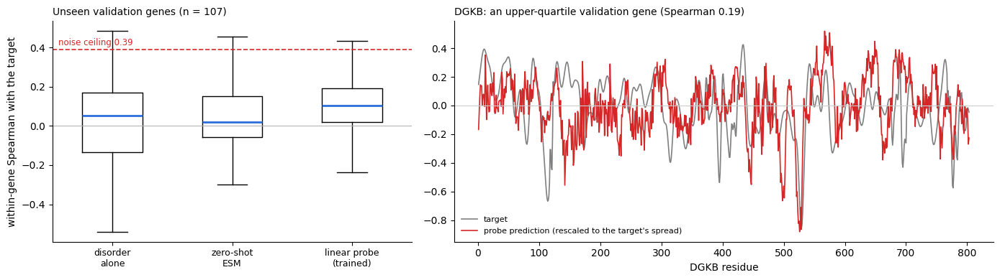

In [5]:
# linear probe: frozen ESM-1v representations -> target, trained on train genes, tested on unseen val genes
PROBE_DIR = os.path.join(OUT, "probe_reps")                   # cache: one float16 array per protein (~1.8 GB total)
os.makedirs(PROBE_DIR, exist_ok=True)

def probe_reps(rec):
    '''Final-layer ESM-1v representation of every residue (tiled like evaluation), cached on disk.'''
    path = os.path.join(PROBE_DIR, rec["gene"].replace("|", "_") + ".npy")
    if os.path.exists(path):
        return np.load(path).astype(np.float64)
    model_v1 = load_esm()[0]                                  # ESM-1v from §4, loaded only if a protein is missing
    out = np.zeros((rec["length"], model_v1.args.embed_dim), np.float16)
    for s, a, b in dataset.tile_ownership(rec["length"], info["max_residues"], info["eval_overlap"]):
        toks = torch.cat([torch.tensor([ALPHABET.cls_idx]), rec["tokens"][s:s + info["max_residues"]].long(),
                          torch.tensor([ALPHABET.eos_idx])])[None].to(device)
        with torch.no_grad():
            r = model_v1(toks, repr_layers=[model_v1.num_layers])["representations"][model_v1.num_layers]
        out[a:b] = r[0, 1:-1].float().cpu().numpy()[a - s:b - s]
    np.save(path, out)
    return out.astype(np.float64)

def design(rec):
    '''Features for ridge: the 1,280 representation numbers + a constant column (the intercept).'''
    R = probe_reps(rec)
    return np.hstack([R, np.ones((len(R), 1))])

probe_train = torch.load(os.path.join(DATA_DIR, "train.pt"), weights_only=True)
probe_val = torch.load(os.path.join(DATA_DIR, "val.pt"), weights_only=True)
t0 = time.time()
# ridge needs only two running sums per group of genes: X'X (1281 x 1281) and X'y. 20 groups of whole clusters
group_of = {c: k % 20 for k, c in enumerate(np.random.default_rng(SEED).permutation(sorted({r["cluster"] for r in probe_train})))}
NF = 1281
XtX = np.zeros((20, NF, NF)); Xty = np.zeros((20, NF)); group_residues = np.zeros(20)
for n, rec in enumerate(probe_train, 1):
    Xg = design(rec); yg = rec["target"].numpy().astype(np.float64); k = group_of[rec["cluster"]]
    XtX[k] += Xg.T @ Xg; Xty[k] += Xg.T @ yg; group_residues[k] += len(yg)
    if n % 200 == 0:
        print(f"  {n}/{len(probe_train)} training proteins ({time.time() - t0:.0f} s)")
val_xy = [(rec["gene"], design(rec).astype(np.float32), rec["target"].numpy())       # float32: half the memory
          for rec in probe_val if rec["length"] >= 50]

def fit_ridge(groups, lam):
    return np.linalg.solve(XtX[groups].sum(0) + lam * np.eye(NF), Xty[groups].sum(0))

# choose lambda by 5-fold CV over the 20 training groups (validation genes untouched)
LAMBDAS = [1e3, 1e4, 1e5, 1e6]
rhos = {lam: [] for lam in LAMBDAS}
for fold in range(5):
    held = [k for k in range(20) if k % 5 == fold]
    ws = {lam: fit_ridge([k for k in range(20) if k % 5 != fold], lam) for lam in LAMBDAS}   # fit on 4/5 ...
    for r in probe_train:                                       # ... score the held-out 1/5 (each protein loaded once)
        if group_of[r["cluster"]] in held and r["length"] >= 50:
            Xr, yr = design(r), r["target"].numpy()
            for lam in LAMBDAS:
                rhos[lam].append(spearmanr(Xr @ ws[lam], yr).statistic)
cv = {lam: np.nanmedian(v) for lam, v in rhos.items()}
LAMBDA = max(cv, key=cv.get)
w_probe = fit_ridge(list(range(20)), LAMBDA)
print("CV (median within-gene Spearman) by lambda:", {f"{k:.0e}": round(v, 3) for k, v in cv.items()}, "-> lambda", f"{LAMBDA:.0e}")

# validation genes: probe vs simple signals
esm_mean_of = dict(zip(psd_seq_df.gene, psd_seq_df.esm_mean_llr))
dis_of = dict(zip(psd_seq_df.gene, psd_seq_df.disorder_scores))
probe_pred, rows = {}, []
for gene, Xg, yg in val_xy:
    p = Xg @ w_probe; probe_pred[gene] = p; g0 = gene.split("|")[0]
    rows.append({"gene": gene, "probe (frozen ESM-1v + ridge)": spearmanr(p, yg).statistic,
                 "zero-shot ESM (esm_mean_llr)": spearmanr(esm_mean_of[g0], yg).statistic,
                 "disorder alone": spearmanr(-np.asarray(dis_of[g0]), yg).statistic})
probe_genes = pd.DataFrame(rows).set_index("gene")
print(f"validation genes ({len(probe_genes)}), median within-gene Spearman with the target:")
print(probe_genes.median().round(3).to_string(), f"\nnoise ceiling (14a): {NOISE_CEILING:.2f}")

# variant level: held-out labelled variants in validation genes, scored with NO variant data for those genes
in_val = hv[hv.gene.isin(probe_pred)].copy()
in_val["probe"] = [probe_pred[g][p - 1] for g, p in zip(in_val.gene, in_val.position)]
yb = in_val.clinsig_group == "benign"
auc_14c = {"probe (sequence only)": roc_auc_score(yb, in_val.probe), "ESM-1v LLR": roc_auc_score(yb, in_val.esm_llr),
           "tolerance from the gene's own variants": roc_auc_score(yb, in_val.tolerance_v4_train)}
print(f"\nheld-out variants in validation genes ({(~yb).sum()} pathogenic / {yb.sum()} benign), AUROC:",
      {k: round(v, 3) for k, v in auc_14c.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.5]})
cols = ["disorder alone", "zero-shot ESM (esm_mean_llr)", "probe (frozen ESM-1v + ridge)"]
axes[0].boxplot([probe_genes[c].dropna() for c in cols], showfliers=False, widths=0.5,
                medianprops=dict(color="#2a6fdb", lw=2))
axes[0].set_xticks(range(1, 4), ["disorder\nalone", "zero-shot\nESM", "linear probe\n(trained)"], fontsize=9)
axes[0].axhline(0, color="0.7", lw=0.8)
axes[0].axhline(NOISE_CEILING, color="#d62728", ls="--", lw=1.2)
axes[0].text(0.55, NOISE_CEILING + 0.02, f"noise ceiling {NOISE_CEILING:.2f}", color="#d62728", fontsize=8.5)
axes[0].set_ylabel("within-gene Spearman with the target")
axes[0].set_title(f"Unseen validation genes (n = {len(probe_genes)})", loc="left", fontsize=10)
show = probe_genes["probe (frozen ESM-1v + ridge)"]
example = (show[[g for g in show.index if 300 <= len(probe_pred[g]) <= 900]] - show.quantile(0.75)).abs().idxmin()
yx = next(y for g, _, y in val_xy if g == example)
x = np.arange(1, len(yx) + 1)
axes[1].plot(x, yx, color="0.5", lw=1.2, label="target")
pe = probe_pred[example]
pe_scaled = (pe - np.median(pe)) / pe.std() * yx.std()       # ridge shrinks predictions; correlation only sees shape
axes[1].plot(x, pe_scaled, color="#d62728", lw=1.2, label="probe prediction (rescaled to the target's spread)")
axes[1].axhline(0, color="0.8", lw=0.8)
axes[1].set_xlabel(f"{example} residue")
axes[1].set_title(f"{example}: an upper-quartile validation gene (Spearman {show[example]:.2f})", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 14d. Would more training proteins help? (learning curve)

The probe is refitted on 5%, 10%, 25%, 50% and 100% of the training genes, always whole clusters (§10), with five random draws per fraction, and scored on the same validation genes. The penalty λ is scaled with the amount of data, so each fit is regularised equally per residue.
- **A curve still rising at 100%** means more proteins would help. The obvious source is expanding beyond postsynaptic SynGO genes to all human genes.
- **A flat curve** means the bottleneck is the target (14a) or the model, not the amount of data.

Each fit reuses the sums from 14c, so this takes seconds.

 fraction  residues  median   low  high
     0.05   27562.0   0.067 0.058 0.087
     0.10   59842.0   0.066 0.056 0.076
     0.25  150013.6   0.092 0.071 0.101
     0.50  313735.4   0.090 0.080 0.104
     1.00  618540.0   0.105 0.105 0.105


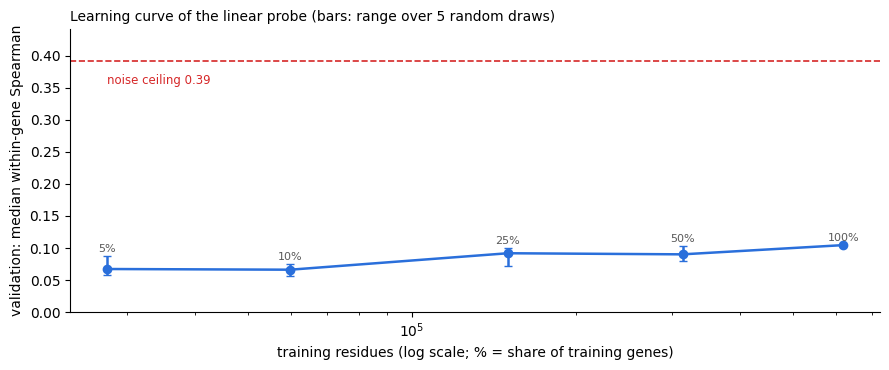

In [6]:
# learning curve: refit the probe on growing fractions of the training genes
curve = []
for n_groups in [1, 2, 5, 10, 20]:
    draws = range(5) if n_groups < 20 else range(1)
    scores, residues = [], []
    for d in draws:
        groups = list(np.random.default_rng(d).choice(20, n_groups, replace=False))
        w = fit_ridge(groups, LAMBDA * n_groups / 20)             # same regularisation per residue
        scores.append(np.nanmedian([spearmanr(Xg @ w, yg).statistic for _, Xg, yg in val_xy]))
        residues.append(group_residues[groups].sum())
    curve.append({"fraction": n_groups / 20, "residues": np.mean(residues), "median": np.mean(scores),
                  "low": min(scores), "high": max(scores)})
curve = pd.DataFrame(curve)
print(curve.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar(curve.residues, curve["median"], yerr=[curve["median"] - curve.low, curve.high - curve["median"]],
            fmt="o-", color="#2a6fdb", capsize=3, lw=1.8)
for _, r in curve.iterrows():
    ax.text(r.residues, r.high + 0.006, f"{r.fraction:.0%}", ha="center", fontsize=8, color="0.35")
ax.axhline(NOISE_CEILING, color="#d62728", ls="--", lw=1.2)
ax.text(curve.residues.min(), NOISE_CEILING - 0.02, f"noise ceiling {NOISE_CEILING:.2f}", color="#d62728", fontsize=8.5, va="top")
ax.set_xscale("log"); ax.set_ylim(0, NOISE_CEILING + 0.05)
ax.set_xlabel("training residues (log scale; % = share of training genes)")
ax.set_ylabel("validation: median within-gene Spearman")
ax.set_title("Learning curve of the linear probe (bars: range over 5 random draws)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 14e. Interim conclusions (14a–14d)

**First run (2026-10-21; the cells above reproduce these numbers):**

| question | result |
|---|---|
| target reproducibility (14a) | split-half agreement 0.08; full-target reliability ≈ 0.15; **noise ceiling ≈ 0.39** |
| human data vs evolution (14b) | held-out pathogenic vs benign AUROC: tolerance **0.847**, ESM **0.881**, **combined 0.927**; of the pathogenic variants ESM calls mild, **80%** have tolerance < 0 (vs 42% of ESM-mild benign) |
| learnable from sequence (14c) | linear probe on unseen genes: within-gene Spearman **0.105** (zero-shot ESM 0.02, disorder 0.05) |
| variant classification in unseen genes (14c) | probe 0.80 vs ESM 0.93 vs the gene's own tolerance 0.88 (small: 207 variants, 79 pathogenic / 128 benign) |
| more data (14d) | 0.07 with 5–10% of the training genes, 0.09 with 25–50%, 0.105 with all of them: still rising, not flattened |

**What this says:**
1. **The hypothesis holds where it matters most.** Human variant density carries information that evolutionary scoring misses: combined with ESM it separates held-out pathogenic from benign variants better than either alone, and it flags most of the pathogenic variants ESM considers mild. That needs no deep learning, only the gene's own variant data.
2. **The current training target is the weak point.** Tolerance at single-residue resolution is mostly noise (14a), so even a perfect model would correlate only ≈ 0.39 with it. The linear probe already reaches about a quarter of that ceiling, with five times the signal of zero-shot ESM. Fine-tuning (§12) could add more, but not beyond the ceiling.
3. **A sequence-only model doesn't replace ESM for scoring variants in a new gene.** The probe's predicted tolerance classifies variants worse than ESM's substitution-specific score. It predicts one value per residue, not per substitution.
4. **More proteins help, slowly.** The learning curve hasn't flattened.

**Options before §15 (Biowulf):**
1. **Make the learning task match the hypothesis: predict *variant* severity directly.** One training example per variant:
   - **inputs:** ESM's representation of the residue in context, the specific substitution, and the tolerance computed from the *other* variants in that gene;
   - **label:** ClinVar pathogenic / benign, optionally plus gnomAD-observed as weakly benign.

   The model then learns how to combine evolutionary and human-population evidence, and its output is substitution-specific.
2. **Make the target more reliable:** include gnomAD variants seen only once (`GNOMAD_MIN_COUNT = 1`), use coarser smoothing, or expand to all human genes. Rerun 14a after each change; it takes about a minute.
3. **Run §15 as planned** to measure how much LoRA fine-tuning adds over the linear probe. Informative, but expect modest gains.

14f–14h below test options 1 and 2 on this laptop before deciding on option 3; 14i sums up.

### 14f. Which architecture learns the per-residue target best?

14c showed that a straight-line readout of frozen ESM-1v reaches a within-gene Spearman of about 0.1 on unseen genes. Is that a limit of the **data** or of the **model**? This step trains six small networks on the same target, the same training genes and the same validation genes, and compares them on one scale with the references from 14c.

| family | model | what it sees around a residue | what it starts from |
|---|---|---|---|
| no training | disorder alone, zero-shot ESM (`esm_mean_llr`) | — | — |
| from scratch | **window MLP** | ±15 residues | nothing: it learns amino-acid patterns from our ~850 training proteins alone |
| from scratch | **dilated CNN** | ±60 residues | nothing |
| from scratch | **BiLSTM** (a kind of RNN) | the whole window (512 residues in training, up to 1,022 when scoring) | nothing |
| frozen ESM | **linear probe** (14c) | the whole protein, through ESM | ESM-1v, pre-trained on ~98 million sequences, kept frozen |
| frozen ESM | **MLP head** | the residue's own 1,280 ESM numbers | ESM-1v, frozen |
| frozen ESM | **CNN head / BiLSTM head** | the ESM numbers of the neighbours too | ESM-1v, frozen |
| fine-tuned ESM | LoRA (§12) | the whole window | ESM-2 650M, partly re-trained on Biowulf; filled in by §16 |

Three comparisons, three questions:
- **From scratch vs frozen ESM:** does ESM's pre-training matter, or can ~850 proteins teach a network enough on their own?
- **Window MLP vs CNN vs BiLSTM:** when learning from scratch, does seeing more of the sequence help?
- **MLP head vs CNN / BiLSTM heads:** ESM's numbers for a residue already summarise the whole protein. Does looking at the neighbours' numbers add anything?

**How every model is trained (the same recipe for all six):**
1. The training genes are split once more, by cluster: 90% are learned from (**fit**), 10% only decide **when to stop** (**stop**). The validation genes stay untouched until the very end, exactly as in 14c.
2. In each **epoch**, every fit protein contributes one random window of up to 512 residues (as in §11), 16 windows per step, with the Huber loss on the centred target (as in §12).
3. After each epoch the model predicts the stop proteins. When that score hasn't improved for 4 epochs, training ends and the best epoch is kept (**early stopping**).
4. Each model is trained **3 times from different random starting weights (seeds)**, because small networks vary from run to run.
5. The kept models predict the validation proteins, tiled like the evaluation in §11.

**Two scores:**
- **Within-gene Spearman** with the target on the 107 validation genes (as in 14c), compared with the noise ceiling from 14a.
- **AUROC for pathogenic vs benign ClinVar variants (≥ 1 star) in the validation genes**, using each model's predicted tolerance at the variant's residue. No model saw *any* variant data for these genes. ESM-1v's substitution-specific LLR is drawn as a reference line: it knows which amino acid replaces which, while these models give one score per residue. Treat this panel as a rough check: the models learned a target centred *within* each gene, so their overall level differs arbitrarily from gene to gene, and only 7 validation genes have enough variants of both classes for a within-gene AUROC. 14h does the variant task properly.

Error bars are 95% ranges from a **bootstrap** over validation genes. The **runtime** is about 20 min on an M1 Pro, mostly the BiLSTMs. Every run is cached in `results/tolerance_model/baselines/`, so re-running the notebook later takes seconds; set `RERUN = True` to retrain.

**Memory:** 14f–14h add several GB to the kernel (ESM representations, residue and variant tables). Before running them, restart the kernel and use the reload cell at the top of §14, rather than running them after §2–§13 in the same session.

| word | meaning |
|---|---|
| **epoch** | one pass over the training proteins |
| **seed** | the random number that sets a network's starting weights and the order it sees the data |
| **receptive field** | how many neighbouring residues can influence one residue's prediction |
| **MLP** (multi-layer perceptron) | the basic neural network: weighted sums, a bend (GELU), weighted sums again |
| **CNN** (convolutional network) | slides the same small filter along the sequence. Stacking filters with growing gaps (**dilation** 1, 2, 4, 8) widens the receptive field cheaply |
| **RNN / LSTM / BiLSTM** | an RNN reads a sequence one residue at a time and carries a memory along. An LSTM is the RNN design with gates that decide what to keep, which makes it trainable on long sequences. *Bi* = one copy reads left to right, another right to left |
| **head** | the small network on top of a frozen language model that turns its numbers into the prediction |
| **bootstrap** | resample the validation genes with replacement many times and recompute the score; the middle 95% of the results is the uncertainty range |

In [7]:
# 14f setup: the data, six small models, and one training loop shared by all of them
import copy
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence

BASE_DIR = os.path.join(OUT, "baselines")             # every run's validation predictions are cached here
os.makedirs(BASE_DIR, exist_ok=True)
RERUN = False                                          # True: retrain even when a cached run exists
N_SEEDS = 3                                            # independent runs per model (different starting weights)
WIN, BATCH, MAX_EPOCHS, PATIENCE = 512, 16, 30, 4      # window, windows per step, epoch limit, early-stopping patience
PAD = ALPHABET.padding_idx

# fit / stop / validation proteins. "stop" = 10% of the training clusters, used only to decide when to stop
train_clusters = sorted({r["cluster"] for r in probe_train})
stop_clusters = set(np.random.default_rng(SEED).permutation(train_clusters)[: len(train_clusters) // 10])
fit_recs = [r for r in probe_train if r["cluster"] not in stop_clusters]
stop_recs = [r for r in probe_train if r["cluster"] in stop_clusters and r["length"] >= 50]
val_recs = [r for r in probe_val if r["length"] >= 50]
print(f"fit: {len(fit_recs)} proteins | stop: {len(stop_recs)} | validation: {len(val_recs)}")

# free the ESM-1v model if §4 or 14c loaded it (~2.6 GB): every representation used below is already cached
if "_esm" in globals():
    _esm.clear()
import gc; gc.collect()
if device.type == "mps":
    torch.mps.empty_cache()

# frozen ESM-1v representations cached by 14c, kept as float16 in memory (~1.8 GB)
REPS = {r["gene"]: np.load(os.path.join(PROBE_DIR, r["gene"].replace("|", "_") + ".npy"))
        for r in probe_train + probe_val}


class Stem(nn.Module):
    '''Turns the input into d numbers per residue: a learned lookup table for amino-acid tokens
    (from scratch), or a learned projection of ESM's 1,280 numbers (frozen ESM).'''
    def __init__(self, source, d):
        super().__init__()
        self.layer = (nn.Embedding(len(ALPHABET), d, padding_idx=PAD) if source == "tokens"
                      else nn.Sequential(nn.Dropout(0.1), nn.Linear(1280, d)))

    def forward(self, x):
        return self.layer(x)                                            # (batch, length, d)


class WindowMLP(nn.Module):
    '''Predicts each residue from itself and k neighbours on each side. A 1-D convolution of width 2k+1
    is exactly a small MLP applied to every window of 2k+1 residues. k = 0: the residue alone.'''
    def __init__(self, source, k, d=128, hidden=256):
        super().__init__()
        self.stem = Stem(source, d)
        self.net = nn.Sequential(nn.Conv1d(d, hidden, 2 * k + 1, padding=k), nn.GELU(), nn.Dropout(0.1),
                                 nn.Conv1d(hidden, 1, 1))

    def forward(self, x, lengths):
        return self.net(self.stem(x).transpose(1, 2)).squeeze(1)       # (batch, length)


class DilatedCNN(nn.Module):
    '''Eight convolutions of width 5 with growing gaps (dilation 1, 2, 4, 8, twice): each residue sees +-60
    neighbours. The residual connection (h + block(h)) lets every layer add detail without losing the rest.'''
    def __init__(self, source, d=128, dilations=(1, 2, 4, 8, 1, 2, 4, 8)):
        super().__init__()
        self.stem = Stem(source, d)
        self.blocks = nn.ModuleList(nn.Sequential(nn.Conv1d(d, d, 5, padding=2 * k, dilation=k), nn.GELU(),
                                                  nn.Dropout(0.1)) for k in dilations)
        self.out = nn.Conv1d(d, 1, 1)

    def forward(self, x, lengths):
        h = self.stem(x).transpose(1, 2)                                # (batch, d, length)
        for block in self.blocks:
            h = h + block(h)
        return self.out(h).squeeze(1)


class BiLSTM(nn.Module):
    '''Reads the window one residue at a time, left to right and right to left, carrying a memory;
    every residue's prediction can draw on the whole window. Each layer is two LSTMs, one per direction.
    The right-to-left one reads each window reversed *within its own length*, so padding (which sits at the
    end of short windows) is never read before the real residues.'''
    def __init__(self, source, d=64, hidden=128, layers=2):
        super().__init__()
        self.stem = Stem(source, d)
        sizes = [d] + [2 * hidden] * (layers - 1)                       # layer 2 reads both directions of layer 1
        self.fwd = nn.ModuleList(nn.LSTM(n, hidden, batch_first=True) for n in sizes)
        self.bwd = nn.ModuleList(nn.LSTM(n, hidden, batch_first=True) for n in sizes)
        self.drop = nn.Dropout(0.2)
        self.out = nn.Linear(2 * hidden, 1)

    def forward(self, x, lengths):
        h = self.stem(x)                                                # (batch, length, d)
        t = torch.arange(h.shape[1], device=h.device)[None]
        n = lengths.to(h.device)[:, None]
        flip = torch.where(t < n, n - 1 - t, t)[..., None]              # reverse each window within its length
        for i, (fwd, bwd) in enumerate(zip(self.fwd, self.bwd)):
            if i:
                h = self.drop(h)
            back = bwd(h.gather(1, flip.expand_as(h)))[0]               # read right to left ...
            back = back.gather(1, flip.expand_as(back))                 # ... and put the outputs back in order
            h = torch.cat([fwd(h)[0], back], dim=-1)
        return self.out(h).squeeze(-1)


ARCHS = {   # name -> (family, input, how to build it)
    "window MLP":           ("from scratch", "tokens", lambda: WindowMLP("tokens", k=15)),
    "dilated CNN":          ("from scratch", "tokens", lambda: DilatedCNN("tokens")),
    "BiLSTM":               ("from scratch", "tokens", lambda: BiLSTM("tokens")),
    "ESM-1v + MLP head":    ("frozen ESM",   "esm",    lambda: WindowMLP("esm", k=0)),
    "ESM-1v + CNN head":    ("frozen ESM",   "esm",    lambda: DilatedCNN("esm")),
    "ESM-1v + BiLSTM head": ("frozen ESM",   "esm",    lambda: BiLSTM("esm")),
}
N_PARAMS = {name: sum(p.numel() for p in build().parameters()) for name, (_, _, build) in ARCHS.items()}
for name, (family, source, _) in ARCHS.items():
    print(f"  {name:22s} {family:13s} input: {source:6s} {N_PARAMS[name]:>9,} trainable weights")


def model_input(rec, source, start, stop):
    '''Residues start..stop of one protein: token ids (from scratch) or ESM-1v numbers (frozen ESM).'''
    if source == "tokens":
        return rec["tokens"][start:stop].long()
    return torch.from_numpy(REPS[rec["gene"]][start:stop].astype(np.float32))


def training_batches(source, rng):
    '''One random window (<= WIN residues) from every fit protein, shuffled, BATCH windows at a time.'''
    order = rng.permutation(len(fit_recs))
    for i in range(0, len(order), BATCH):
        xs, ys = [], []
        for j in order[i:i + BATCH]:
            r = fit_recs[j]
            n = min(WIN, r["length"]); s = int(rng.integers(0, r["length"] - n + 1))
            xs.append(model_input(r, source, s, s + n)); ys.append(r["target"][s:s + n].float())
        lengths = torch.tensor([len(y) for y in ys])
        x = pad_sequence(xs, batch_first=True, padding_value=PAD if source == "tokens" else 0.0)
        y = pad_sequence(ys, batch_first=True)
        mask = torch.arange(y.shape[1])[None] < lengths[:, None]       # True = a real residue, False = padding
        yield x, y, mask, lengths


@torch.no_grad()
def predict(model, rec, source):
    '''Whole-protein prediction, tiled exactly like the evaluation in §11 (1,022-residue tiles).'''
    model.eval()
    out = np.zeros(rec["length"], np.float32)
    for s, a, b in dataset.tile_ownership(rec["length"], info["max_residues"], info["eval_overlap"]):
        x = model_input(rec, source, s, s + info["max_residues"])[None].to(device)
        p = model(x, torch.tensor([x.shape[1]])).float().cpu().numpy()[0]
        out[a:b] = p[a - s:b - s]
    return out


def median_spearman(model, recs, source):
    return float(np.nanmedian([spearmanr(predict(model, r, source), r["target"].numpy()).statistic for r in recs]))


def train_one(name, seed):
    '''Train one model from random starting weights; keep the epoch that scores best on the stop proteins.'''
    _, source, build = ARCHS[name]
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = build().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    best, best_state, history, bad = -np.inf, None, [], 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); t0 = time.time(); losses = []
        for x, y, mask, lengths in training_batches(source, rng):
            x, y, mask = x.to(device), y.to(device), mask.to(device)
            loss = F.huber_loss(model(x, lengths)[mask], y[mask], delta=0.5)   # padding never counts
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            losses.append(loss.item())
        score = median_spearman(model, stop_recs, source)                    # check on the stop proteins
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "stop_spearman": score,
                        "seconds": time.time() - t0})
        if score > best:
            best, best_state, bad = score, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:                                              # no progress for PATIENCE epochs
                break
    model.load_state_dict(best_state)
    return model, history

fit: 739 proteins | stop: 115 | validation: 107
  window MLP             from scratch  input: tokens 1,020,545 trainable weights
  dilated CNN            from scratch  input: tokens   660,737 trainable weights
  BiLSTM                 from scratch  input: tokens   596,289 trainable weights
  ESM-1v + MLP head      frozen ESM    input: esm      197,249 trainable weights
  ESM-1v + CNN head      frozen ESM    input: esm      820,481 trainable weights
  ESM-1v + BiLSTM head   frozen ESM    input: esm      676,161 trainable weights


The picture below shows, for one residue (red), how far each model can look, and how many weights it learns from our data. Dark bars are what the model reads directly. Light bars are context that reaches the model only *through ESM*: ESM's numbers for a residue were computed from the whole protein (up to 1,022 residues), and its knowledge comes from ~98 million other proteins.

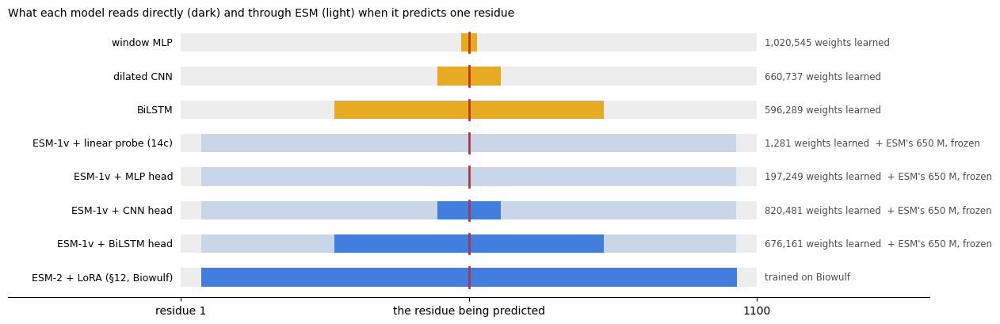

In [8]:
# what each model can see when it predicts one residue, and how many weights it learns from our data
L_demo, centre = 1100, 550
view = [   # name, half-width read directly, reaches the whole protein through ESM?, weights learned here
    ("window MLP", 15, False, N_PARAMS["window MLP"]),
    ("dilated CNN", 60, False, N_PARAMS["dilated CNN"]),
    ("BiLSTM", 256, False, N_PARAMS["BiLSTM"]),
    ("ESM-1v + linear probe (14c)", 0, True, 1281),
    ("ESM-1v + MLP head", 0, True, N_PARAMS["ESM-1v + MLP head"]),
    ("ESM-1v + CNN head", 60, True, N_PARAMS["ESM-1v + CNN head"]),
    ("ESM-1v + BiLSTM head", 256, True, N_PARAMS["ESM-1v + BiLSTM head"]),
    ("ESM-2 + LoRA (§12, Biowulf)", 511, True, None),
]
colour = {False: "#E69F00", True: "#2a6fdb"}
fig, ax = plt.subplots(figsize=(13, 4.2))
for i, (name, half, via_esm, n) in enumerate(view):
    yy = len(view) - 1 - i
    ax.barh(yy, L_demo, left=0, height=0.55, color="0.93")                      # the protein
    if via_esm:
        ax.barh(yy, 1022, left=centre - 511, height=0.55, color=colour[True], alpha=0.18)
    ax.barh(yy, 2 * half + 1, left=centre - half, height=0.55, color=colour[via_esm], alpha=0.85)
    ax.plot([centre, centre], [yy - 0.3, yy + 0.3], color="#d62728", lw=2)
    ax.text(-15, yy, name, ha="right", va="center", fontsize=9)
    ax.text(L_demo + 15, yy, "trained on Biowulf" if n is None else f"{n:,} weights learned"
            + ("  + ESM's 650 M, frozen" if via_esm else ""), va="center", fontsize=8.5, color="0.3")
ax.set_xlim(-330, L_demo + 330); ax.set_ylim(-0.6, len(view) - 0.4)
ax.set_yticks([]); ax.set_xticks([0, centre, L_demo], ["residue 1", "the residue being predicted", f"{L_demo}"])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title("What each model reads directly (dark) and through ESM (light) when it predicts one residue",
             loc="left", fontsize=10)
fig.tight_layout(); plt.show()

**Train every model** (3 seeds each), or load the cached runs. The curves show what early stopping does. Each line is a model's score on the *stop* proteins after every epoch, and the dot marks the epoch that was kept. A curve that peaks and then falls is the model starting to **overfit**: memorising the fit proteins instead of learning rules that carry over to new ones.

18 runs ready


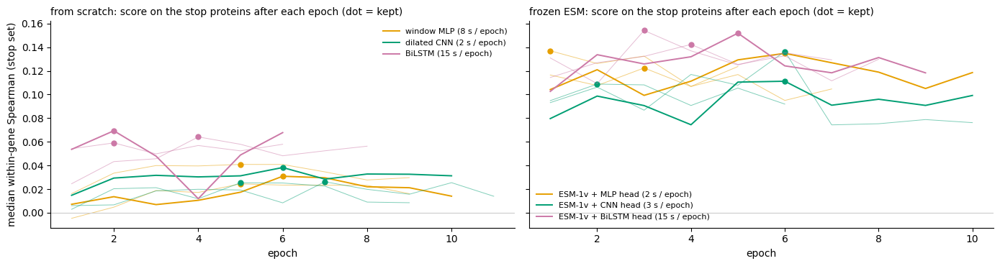

In [9]:
# train every model N_SEEDS times (or load the cached runs), then plot how training went
runs = {}
for name, (family, source, _) in ARCHS.items():
    for seed in range(N_SEEDS):
        path = os.path.join(BASE_DIR, f"residue__{name.replace(' ', '_')}__seed{seed}.pt")
        if os.path.exists(path) and not RERUN:
            runs[name, seed] = torch.load(path, weights_only=True)
            continue
        t0 = time.time()
        model, history = train_one(name, seed)
        runs[name, seed] = {"history": history,
                            "val_pred": {r["gene"]: torch.from_numpy(predict(model, r, source)) for r in val_recs}}
        torch.save(runs[name, seed], path)
        best = max(history, key=lambda h: h["stop_spearman"])
        print(f"{name:22s} seed {seed}: {len(history):2d} epochs, kept epoch {best['epoch']:2d} "
              f"(stop-set Spearman {best['stop_spearman']:.3f}), {time.time() - t0:4.0f} s")
        del model; gc.collect()
        if device.type == "mps":
            torch.mps.empty_cache()                      # hand the GPU memory back between runs
print(f"{len(runs)} runs ready")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, family in zip(axes, ["from scratch", "frozen ESM"]):
    for (name, (fam, _, _)), c in zip(ARCHS.items(), ["#E69F00", "#009E73", "#CC79A7"] * 2):
        if fam != family:
            continue
        for seed in range(N_SEEDS):
            h = pd.DataFrame(runs[name, seed]["history"])
            ax.plot(h.epoch, h.stop_spearman, color=c, lw=1.4 if seed == 0 else 0.7, alpha=1 if seed == 0 else 0.5,
                    label=f"{name} ({h.seconds.mean():.0f} s / epoch)" if seed == 0 else None)
            b = h.loc[h.stop_spearman.idxmax()]
            ax.plot(b.epoch, b.stop_spearman, "o", color=c, ms=5)
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set_xlabel("epoch"); ax.set_title(f"{family}: score on the stop proteins after each epoch (dot = kept)",
                                         loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("median within-gene Spearman (stop set)")
fig.tight_layout(); plt.show()

**The comparison.** Left: how well each model's predicted track follows the target within each unseen validation gene, against the noise ceiling (red dashes). Right: how well the predicted tolerance separates benign from pathogenic ClinVar variants in those genes. The dashed grey line is ESM-1v's substitution-specific LLR. Small dots are the individual seeds, big dots their mean, and bars the 95% bootstrap range.

validation genes: 107 | labelled variants in them: 641 pathogenic, 742 benign
      family                       model  spearman  share_of_ceiling  auroc
 no training              disorder alone     0.052             0.133    NaN
 no training               zero-shot ESM     0.020             0.052  0.952
  frozen ESM ESM-1v + linear probe (14c)     0.105             0.267  0.792
from scratch                  window MLP     0.041             0.104  0.500
from scratch                 dilated CNN     0.032             0.083  0.497
from scratch                      BiLSTM     0.054             0.139  0.553
  frozen ESM           ESM-1v + MLP head     0.090             0.230  0.637
  frozen ESM           ESM-1v + CNN head     0.099             0.254  0.608
  frozen ESM        ESM-1v + BiLSTM head     0.125             0.318  0.651
reference, ESM-1v LLR of the substitution: AUROC 0.941 (0.890-0.977)


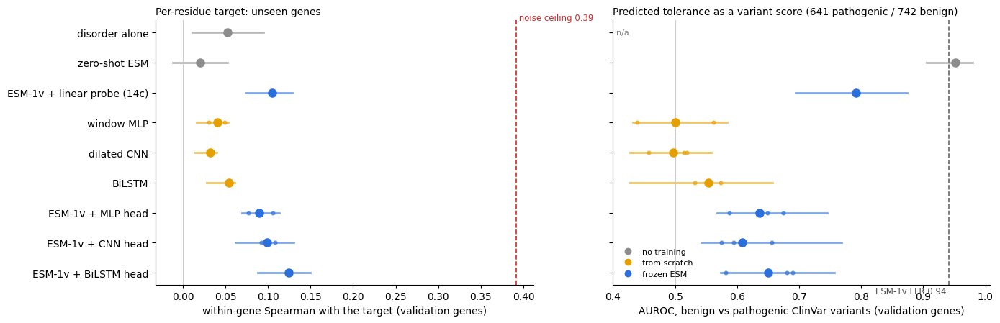

In [10]:
# score every model on the validation genes: within-gene Spearman with the target, and ClinVar AUROC
val_target = {r["gene"]: r["target"].numpy() for r in val_recs}
member = {g: r["gene"] for r in val_recs for g in r["genes"]}                # 'CALM1' -> 'CALM1|CALM2|CALM3'
val_lab = variant_df[(variant_df.database == "ClinVar") & variant_df.clinsig_group.isin(["pathogenic", "benign"])
                     & (variant_df.stars >= 1) & variant_df.gene.isin(member)].drop_duplicates("id").copy()
y_val = val_lab.clinsig_group.eq("benign").to_numpy()
print(f"validation genes: {len(val_target)} | labelled variants in them: {(~y_val).sum()} pathogenic, {y_val.sum()} benign")


def rho_by_gene(pred):
    '''{record: predicted track} -> within-gene Spearman with the target, one value per validation gene.'''
    return pd.Series({g: spearmanr(pred[g], t).statistic for g, t in val_target.items()})


def at_variants(pred):
    '''{record: predicted track} -> the prediction at each labelled variant's residue.'''
    return np.array([np.asarray(pred[member[g]])[p - 1] for g, p in zip(val_lab.gene, val_lab.position)])


def gene_bootstrap(stat, genes, n=1000):
    '''95% range of stat(rows) when whole genes are resampled with replacement.'''
    rows_of = pd.Series(np.arange(len(genes))).groupby(np.asarray(genes)).indices
    keys = np.array(list(rows_of)); rng = np.random.default_rng(SEED); out = []
    for _ in range(n):
        v = stat(np.concatenate([rows_of[k] for k in rng.choice(keys, len(keys))]))
        if np.isfinite(v):
            out.append(v)
    return np.percentile(out, [2.5, 97.5])


def auroc_ci(y, score, genes):
    '''AUROC (benign = positive class) with a gene-bootstrap 95% range.'''
    y, score = np.asarray(y), np.asarray(score, float)
    stat = lambda rows: roc_auc_score(y[rows], score[rows]) if len(set(y[rows])) == 2 else np.nan
    return (roc_auc_score(y, score), *gene_bootstrap(stat, genes))


def summarise(name, family, rho_runs, var_runs):
    '''rho_runs / var_runs: one entry per seed. Point = mean over seeds; range = bootstrap of the seed average.'''
    rho_mean = pd.concat(rho_runs, axis=1).mean(axis=1)
    lo, hi = gene_bootstrap(lambda rows: np.nanmedian(rho_mean.to_numpy()[rows]), rho_mean.index)
    row = {"family": family, "model": name, "spearman": np.mean([r.median() for r in rho_runs]),
           "spearman_lo": lo, "spearman_hi": hi, "spearman_seeds": [r.median() for r in rho_runs]}
    if var_runs is not None:
        a, alo, ahi = auroc_ci(y_val, np.mean(var_runs, axis=0), val_lab.gene)
        row.update(auroc=np.mean([roc_auc_score(y_val, v) for v in var_runs]), auroc_lo=alo, auroc_hi=ahi,
                   auroc_seeds=[roc_auc_score(y_val, v) for v in var_runs])
    return row


zero_shot = {r["gene"]: np.asarray(esm_mean_of[r["genes"][0]]) for r in val_recs}
rows = [summarise("disorder alone", "no training", [probe_genes["disorder alone"]], None),
        summarise("zero-shot ESM", "no training", [rho_by_gene(zero_shot)], [at_variants(zero_shot)]),
        summarise("ESM-1v + linear probe (14c)", "frozen ESM", [rho_by_gene(probe_pred)], [at_variants(probe_pred)])]
for name, (family, _, _) in ARCHS.items():
    preds = [{g: p.numpy() for g, p in runs[name, s]["val_pred"].items()} for s in range(N_SEEDS)]
    rows.append(summarise(name, family, [rho_by_gene(p) for p in preds], [at_variants(p) for p in preds]))
arch_table = pd.DataFrame(rows)
arch_table["share_of_ceiling"] = arch_table.spearman / NOISE_CEILING
esm_llr_auc = auroc_ci(y_val, val_lab.esm_llr, val_lab.gene)
arch_table.to_csv(os.path.join(BASE_DIR, "architectures_residue.csv"), index=False)
print(arch_table[["family", "model", "spearman", "share_of_ceiling", "auroc"]].round(3).to_string(index=False))
print(f"reference, ESM-1v LLR of the substitution: AUROC {esm_llr_auc[0]:.3f} ({esm_llr_auc[1]:.3f}-{esm_llr_auc[2]:.3f})")

FAMILY_COLOUR = {"no training": "0.55", "from scratch": "#E69F00", "frozen ESM": "#2a6fdb"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
order = arch_table.index[::-1]
for ax, metric in zip(axes, ["spearman", "auroc"]):
    for yy, i in enumerate(order):
        r = arch_table.loc[i]
        if not np.isfinite(r.get(metric, np.nan)):
            ax.text(0.01, yy, "n/a", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color="0.5")
            continue
        c = FAMILY_COLOUR[r.family]
        ax.plot([r[f"{metric}_lo"], r[f"{metric}_hi"]], [yy, yy], color=c, lw=2, alpha=0.6)
        ax.scatter(r[f"{metric}_seeds"], [yy] * len(r[f"{metric}_seeds"]), s=12, color=c, alpha=0.6, zorder=3)
        ax.plot(r[metric], yy, "o", color=c, ms=8, zorder=4)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(order)), arch_table.model[order])
axes[0].axvline(0, color="0.8", lw=0.8)
axes[0].axvline(NOISE_CEILING, color="#d62728", ls="--", lw=1.2)
axes[0].text(NOISE_CEILING, len(order) - 0.6, f" noise ceiling {NOISE_CEILING:.2f}", color="#d62728", fontsize=8.5)
axes[0].set_xlabel("within-gene Spearman with the target (validation genes)")
axes[0].set_title("Per-residue target: unseen genes", loc="left", fontsize=10)
axes[1].axvline(0.5, color="0.8", lw=0.8)
axes[1].axvline(esm_llr_auc[0], color="0.4", ls="--", lw=1.2)
axes[1].text(esm_llr_auc[0], -0.7, f"ESM-1v LLR {esm_llr_auc[0]:.2f} ", color="0.3", fontsize=8.5, ha="right")
axes[1].set_xlabel("AUROC, benign vs pathogenic ClinVar variants (validation genes)")
axes[1].set_title(f"Predicted tolerance as a variant score ({(~y_val).sum()} pathogenic / {y_val.sum()} benign)",
                  loc="left", fontsize=10)
for fam, c in FAMILY_COLOUR.items():
    axes[1].plot([], [], "o", color=c, label=fam)
axes[1].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); plt.show()

**One validation gene, several models.** The gene is chosen near the median score of the best model, so it's typical rather than a showcase. Predictions are rescaled to the target's spread, as in 14c: Spearman only sees the *shape* of a track, and these models shrink their predictions towards zero.

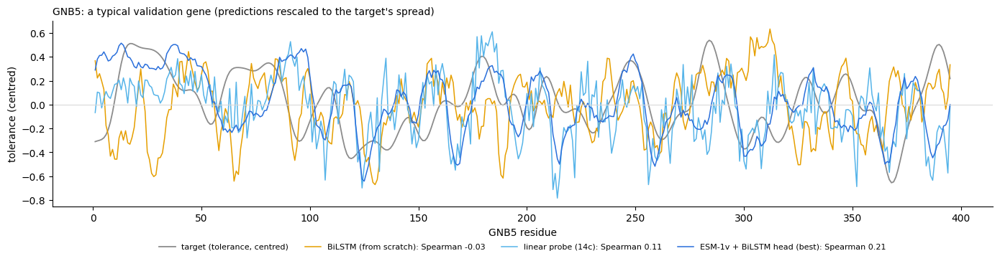

In [11]:
# one typical validation gene: the target and three models' predictions
best_name = arch_table.loc[arch_table.family != "no training"].sort_values("spearman").model.iloc[-1]
best_runs = [{g: p.numpy() for g, p in runs[best_name, s]["val_pred"].items()} for s in range(N_SEEDS)] \
    if best_name in ARCHS else [probe_pred]
best_rho = pd.concat([rho_by_gene(p) for p in best_runs], axis=1).mean(axis=1)
mid = [g for g in best_rho.index if 300 <= len(val_target[g]) <= 900]
example = (best_rho[mid] - best_rho.median()).abs().idxmin()
target = val_target[example]
show = {"BiLSTM (from scratch)": runs["BiLSTM", 0]["val_pred"][example].numpy(),
        "linear probe (14c)": probe_pred[example],
        f"{best_name} (best)": best_runs[0][example]}
fig, ax = plt.subplots(figsize=(14, 3.8))
x = np.arange(1, len(target) + 1)
ax.plot(x, target, color="0.55", lw=1.3, label="target (tolerance, centred)")
for (label, p), c in zip(show.items(), ["#E69F00", "#56B4E9", "#2a6fdb"]):
    rho = spearmanr(p, target).statistic
    ax.plot(x, (p - np.median(p)) / (p.std() + 1e-9) * target.std(), color=c, lw=1.1, label=f"{label}: Spearman {rho:.2f}")
ax.axhline(0, color="0.85", lw=0.8)
ax.set_xlabel(f"{example} residue"); ax.set_ylabel("tolerance (centred)")
ax.set_title(f"{example}: a typical validation gene (predictions rescaled to the target's spread)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.16))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 14g. Which inputs, and which target? (ablations)

An **ablation** removes or swaps one ingredient and measures what changes. Two kinds here:

**Part 1, inputs.** The models in 14f see only sequence (directly or through ESM). §7 and §8 added much more about each residue: structure, binding interfaces, annotated domains and motifs, disorder, conservation. Do any of these carry information about the target that sequence doesn't?

The model is a **gradient-boosted tree ensemble**: hundreds of small decision trees, each correcting the errors of the ones before. It handles mixed features and missing values (no structure → empty RSA) without any preparation, and it trains in seconds. ESM's 1,280 numbers are compressed to their **64 principal components** (the 64 directions along which residues differ most), so they don't drown out the handful of other features.

| group | columns (from `residue_df`) |
|---|---|
| ESM representation | 64 principal components of the frozen ESM-1v representation (14c) |
| zero-shot ESM scores | `esm_wt_lp`, `esm_entropy`, `esm_mean_llr` (§4) |
| amino acid | which of the 20 amino acids the residue is |
| disorder | AIUPred `disorder` and `binding`, curated disorder (§8) |
| conservation | MobiDB PSI-BLAST conservation, `msa_conservation` (§8) |
| structure | RSA, pLDDT, buried surface, interface flags (§7) |
| annotations | domain, repeat, motif, binding region, LIP, PTM, disulfide, ligand / active / conserved site, coiled coil, transmembrane, signal (§8) |
| position | relative position in the protein, protein length |

Each group is tested two ways: **alone** (how much does it know by itself?) and **removed from all the others** (does anything else already cover it?). A group that scores well alone but costs nothing when removed is *redundant*: its information is already in another group.

**Part 2, the target.** 14a showed the target is mostly noise at single-residue resolution. Several choices made in §3 change that. Each alternative recipe is scored three ways:
1. its **noise ceiling** (14a's split-half test, repeated);
2. the **linear probe** (14c) retrained on it: within-gene Spearman on the validation genes;
3. the **common yardstick**: AUROC on the held-out ClinVar variants from §6g, using the track built *without* them. This matters because the first two scores can't be compared across recipes: wider smoothing raises reliability simply by blurring, whether or not the result is more *useful*.

| recipe | what changes |
|---|---|
| current (§3) | gnomAD allele count ≥ 2, every ClinVar missense, BLOSUM w = 31 / Grantham w = 5, centred per gene |
| not centred | the same track without subtracting each gene's median |
| + gnomAD singletons | gnomAD variants seen only once are kept (`GNOMAD_MIN_COUNT = 1`): more data, more noise |
| ClinVar track: no benign | ClinVar variants classified benign no longer count as *intolerant* evidence |
| ClinVar track: pathogenic only | only pathogenic / likely pathogenic ClinVar variants; VUS and benign dropped |
| wider / narrower smoothing | the convolution windows doubled (61 / 11) or halved (15 / 3) |

Part 1 takes ~3 min; part 2 ~7 min, because it rebuilds the tolerance track 4× per recipe. Both are cached (part 2's rebuilt tracks take ~230 MB in `baselines/`).

64 principal components keep 41% of the variation in ESM's numbers
training rows: 250,000 | validation rows: 79,309 | 97 features
all groups: median within-gene Spearman 0.126 (0.091-0.174); linear probe (14c) 0.105


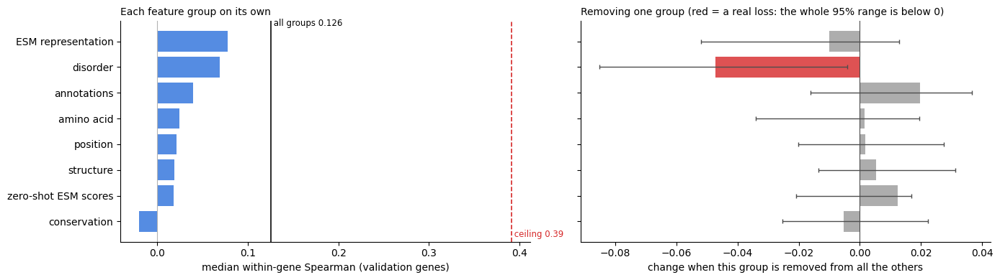

21685

In [12]:
# 14g part 1: which inputs carry information about the target? one tree ensemble per combination of feature groups
from sklearn.ensemble import HistGradientBoostingRegressor

# ESM's 1,280 numbers -> their 64 principal components. The 14c sums already hold what PCA needs:
# X'X over every training residue, whose last row (the column of ones) gives the means
S = XtX.sum(0); n_res = S[-1, -1]
mean_rep = S[:-1, -1] / n_res
eigval, eigvec = np.linalg.eigh(S[:-1, :-1] / n_res - np.outer(mean_rep, mean_rep))    # ascending order
PCS = eigvec[:, ::-1][:, :64]
print(f"64 principal components keep {eigval[::-1][:64].sum() / eigval.sum():.0%} of the variation in ESM's numbers")

AA20 = "ACDEFGHIKLMNPQRSTVWY"
PC_COLS = [f"esm_pc{i}" for i in range(64)]
ANN_COLS = [c for c in residue_df.columns if c.startswith("ann_") and c != "ann_disorder_curated"] + ["n_annotations"]
FEATURE_GROUPS = {
    "ESM representation": PC_COLS,
    "zero-shot ESM scores": ["esm_wt_lp", "esm_entropy", "esm_mean_llr"],
    "amino acid": ["aa_index"],
    "disorder": ["disorder", "binding", "ann_disorder_curated"],
    "conservation": ["msa_conservation"],
    "structure": ["rsa", "plddt", "buried_sasa", "iface_any", "iface_homo", "iface_hetero", "iface_n_entries"],
    "annotations": ANN_COLS,
    "position": ["rel_pos", "log_length"],
}
ALL_RES_FEATURES = sum(FEATURE_GROUPS.values(), [])
res_by_gene = {g: d.sort_values("pos").reset_index(drop=True) for g, d in residue_df.groupby("gene")}


def residue_table(recs):
    '''One row per residue of these proteins: every feature group + the training target.'''
    parts = []
    for r in recs:
        d = res_by_gene[r["genes"][0]]
        pcs = pd.DataFrame((REPS[r["gene"]].astype(np.float32) - mean_rep) @ PCS, columns=PC_COLS)
        d = pd.concat([d, pcs], axis=1).assign(record=r["gene"], target=r["target"].numpy(),
                                                rel_pos=np.arange(r["length"]) / max(r["length"] - 1, 1),
                                                log_length=np.log10(r["length"]))
        parts.append(d)
    t = pd.concat(parts, ignore_index=True)
    t["aa_index"] = t.aa.map({a: i for i, a in enumerate(AA20)})
    t[ALL_RES_FEATURES] = t[ALL_RES_FEATURES].astype("float64")         # True/False/missing -> 1/0/NaN
    return t


fit_tab = residue_table(probe_train).sample(250_000, random_state=SEED)  # a random quarter-million residues
val_tab = residue_table(val_recs)
val_groups = val_tab.groupby("record").indices
print(f"training rows: {len(fit_tab):,} | validation rows: {len(val_tab):,} | {len(ALL_RES_FEATURES)} features")


def tree_rho(cols):
    '''Fit the tree ensemble on these columns; return within-gene Spearman on each validation gene.'''
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200,
                                          l2_regularization=1.0, early_stopping=False, random_state=SEED,
                                          categorical_features=[c == "aa_index" for c in cols])
    pred = model.fit(fit_tab[cols], fit_tab.target).predict(val_tab[cols])
    tgt = val_tab.target.to_numpy()
    return pd.Series({g: spearmanr(pred[i], tgt[i]).statistic for g, i in val_groups.items()})


plans = {"all groups": ALL_RES_FEATURES}
plans.update({f"only {g}": cols for g, cols in FEATURE_GROUPS.items()})
plans.update({f"without {g}": [c for c in ALL_RES_FEATURES if c not in cols] for g, cols in FEATURE_GROUPS.items()})
cache = os.path.join(BASE_DIR, "ablation_residue_features.parquet")
feature_rho = pd.read_parquet(cache) if os.path.exists(cache) and not RERUN else pd.DataFrame()
for plan, cols in plans.items():
    if plan not in feature_rho:
        t0 = time.time(); feature_rho[plan] = tree_rho(cols)
        print(f"  {plan:30s} median {feature_rho[plan].median():.3f}  ({time.time() - t0:.0f} s)")
feature_rho.to_parquet(cache)

med = feature_rho.median()
all_lo, all_hi = gene_bootstrap(lambda rows: np.nanmedian(feature_rho["all groups"].to_numpy()[rows]), feature_rho.index)
alone = pd.Series({g: med[f"only {g}"] for g in FEATURE_GROUPS}).sort_values()
removed = pd.Series({g: med[f"without {g}"] - med["all groups"] for g in FEATURE_GROUPS}).reindex(alone.index)
# 95% range of each change, resampling the same validation genes for both fits (a paired bootstrap)
removed_ci = pd.DataFrame({g: gene_bootstrap(lambda rows: np.nanmedian(feature_rho[f"without {g}"].to_numpy()[rows])
                                             - np.nanmedian(feature_rho["all groups"].to_numpy()[rows]), feature_rho.index)
                           for g in FEATURE_GROUPS}, index=["lo", "hi"]).T.reindex(alone.index)
print(f"all groups: median within-gene Spearman {med['all groups']:.3f} ({all_lo:.3f}-{all_hi:.3f}); "
      f"linear probe (14c) {arch_table.set_index('model').spearman['ESM-1v + linear probe (14c)']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].barh(range(len(alone)), alone, color="#2a6fdb", alpha=0.8)
axes[0].axvline(med["all groups"], color="0.2", lw=1.5)
axes[0].text(med["all groups"], len(alone) - 0.4, f" all groups {med['all groups']:.3f}", fontsize=8.5)
axes[0].axvline(NOISE_CEILING, color="#d62728", ls="--", lw=1.2)
axes[0].text(NOISE_CEILING, -0.6, f" ceiling {NOISE_CEILING:.2f}", color="#d62728", fontsize=8.5)
axes[0].axvline(0, color="0.7", lw=0.8)
axes[0].set_yticks(range(len(alone)), alone.index)
axes[0].set_xlabel("median within-gene Spearman (validation genes)")
axes[0].set_title("Each feature group on its own", loc="left", fontsize=10)
axes[1].barh(range(len(removed)), removed, color=np.where(removed_ci.hi < 0, "#d62728", "0.6"), alpha=0.8,
             xerr=[removed - removed_ci.lo, removed_ci.hi - removed], error_kw=dict(ecolor="0.3", lw=1, capsize=2))
axes[1].axvline(0, color="0.3", lw=0.8)
axes[1].set_xlabel("change when this group is removed from all the others")
axes[1].set_title("Removing one group (red = a real loss: the whole 95% range is below 0)", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()
del fit_tab, val_tab, res_by_gene; gc.collect()                       # ~1 GB not needed further down

**Part 2: the target recipe.** Each recipe's track is rebuilt 4 times: from two random halves of the variants (noise ceiling), from all variants (the probe's training target), and from all but the §6g held-out variants (the common yardstick). The probe reuses the 14c sums and λ; only the target side changes.

                                variants used  noise ceiling  probe Spearman  AUROC: track itself, held-out variants  AUROC: probe, validation genes
recipe                                                                                                                                              
current (§3)                           639723          0.374           0.104                                   0.793                           0.792
not centred                            639723          0.374           0.080                                   0.851                           0.685
+ gnomAD singletons                   1057290          0.458           0.168                                   0.761                           0.497
ClinVar track: no benign               628628          0.372           0.109                                   0.801                           0.821
ClinVar track: pathogenic only         439820          0.605           0.320                              

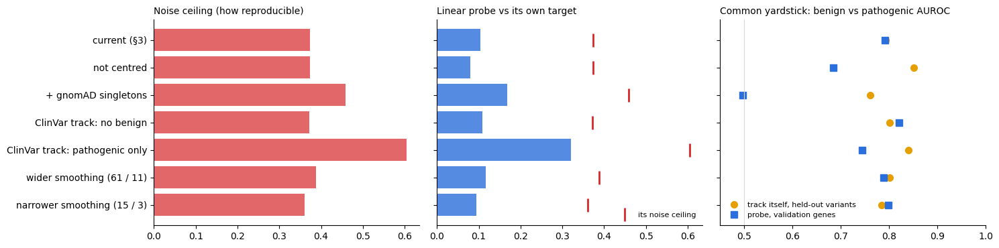

8455

In [13]:
# 14g part 2: does a different target recipe give a more learnable, more useful target?
def gnomad_keep_min(n):
    '''gnomad_keep() (§3) with another allele-count threshold; same X / Y rule.'''
    global GNOMAD_MIN_COUNT
    old, GNOMAD_MIN_COUNT = GNOMAD_MIN_COUNT, n
    try:
        return gnomad_keep(missense_df)
    finally:
        GNOMAD_MIN_COUNT = old


label = missense_df.clinsig_group
RECIPES = {   # name -> (variants feeding the tracks, convolve_v4 overrides, centre each gene?)
    "current (§3)":                    (tolerance_variants, {}, True),
    "not centred":                     (tolerance_variants, {}, False),
    "+ gnomAD singletons":             (missense_df[gnomad_keep_min(1) | keep_clinvar], {}, True),
    "ClinVar track: no benign":        (missense_df[keep_gnomad | (is_clinvar & label.ne("benign"))], {}, True),
    "ClinVar track: pathogenic only":  (missense_df[keep_gnomad | (is_clinvar & label.eq("pathogenic"))], {}, True),
    "wider smoothing (61 / 11)":       (tolerance_variants, {"window_size": [61, 11]}, True),
    "narrower smoothing (15 / 3)":     (tolerance_variants, {"window_size": [15, 3]}, True),
}
half_of = dict(zip(missense_df.id.unique(), np.random.default_rng(SEED).random(missense_df.id.nunique()) < 0.5))
held_out_ids = set(hv.id)                                     # the §6g held-out labelled variants


def tracks(variants, params):
    built = build_tolerance_columns(usable, variants, name="r", gnomad_min_count=0, verbose=False, **params)
    return dict(zip(built.gene, built.tolerance_r))


def recipe_tracks(variants, params):
    '''The four builds one recipe needs (the 'not centred' recipe shares them with 'current').'''
    h = variants.id.map(half_of)
    return {"half_a": tracks(variants[h], params), "half_b": tracks(variants[~h], params),
            "full": tracks(variants, params), "train": tracks(variants[~variants.id.isin(held_out_ids)], params)}


cache = os.path.join(BASE_DIR, "ablation_target_recipes.pt")
built_recipes = torch.load(cache, weights_only=False) if os.path.exists(cache) and not RERUN else {}
for name, (variants, params, _) in RECIPES.items():
    key = "current (§3)" if name == "not centred" else name
    if key not in built_recipes:
        t0 = time.time(); built_recipes[key] = recipe_tracks(variants, params)
        print(f"  built {key:32s} ({time.time() - t0:.0f} s)")
torch.save(built_recipes, cache)

centre_track = lambda t, on: np.asarray(t) - (np.median(t) if on else 0)
recipe_target = {name: {r["gene"]: centre_track(built_recipes["current (§3)" if name == "not centred" else name]["full"][r["genes"][0]], c)
                        for r in probe_train + probe_val} for name, (_, _, c) in RECIPES.items()}

# the probe for every recipe at once: one pass over the training proteins collects X'y per recipe
Xty_recipe = {name: np.zeros(NF) for name in RECIPES}
for rec in probe_train:
    Xg = design(rec)
    for name in RECIPES:
        Xty_recipe[name] += Xg.T @ recipe_target[name][rec["gene"]]
A_reg = XtX.sum(0) + LAMBDA * np.eye(NF)

recipe_rows = []
for name, (variants, params, centred) in RECIPES.items():
    b = built_recipes["current (§3)" if name == "not centred" else name]
    r_half = np.nanmedian([spearmanr(b["half_a"][g], b["half_b"][g]).statistic for g in b["half_a"]
                           if gene_len[g] >= 50 and np.ptp(b["half_a"][g]) > 0 and np.ptp(b["half_b"][g]) > 0])
    w = np.linalg.solve(A_reg, Xty_recipe[name])
    pred = {gene: Xg @ w for gene, Xg, _ in val_xy}
    probe_rho = np.nanmedian([spearmanr(pred[g], recipe_target[name][g]).statistic for g in pred])
    held = np.array([centre_track(b["train"][g], centred)[p - 1] for g, p in zip(hv.gene, hv.position)])
    recipe_rows.append({"recipe": name, "variants used": len(variants),
                        "noise ceiling": np.sqrt(max(2 * r_half / (1 + r_half), 0)),
                        "probe Spearman": probe_rho,
                        "AUROC: track itself, held-out variants": roc_auc_score(hv.clinsig_group == "benign", held),
                        "AUROC: probe, validation genes": roc_auc_score(y_val, at_variants(pred))})
recipe_table = pd.DataFrame(recipe_rows).set_index("recipe")
recipe_table.to_csv(os.path.join(BASE_DIR, "ablation_target_recipes.csv"))
print(recipe_table.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
yy = np.arange(len(recipe_table))[::-1]
axes[0].barh(yy, recipe_table["noise ceiling"], color="#d62728", alpha=0.7)
axes[0].set_title("Noise ceiling (how reproducible)", loc="left", fontsize=10)
axes[1].barh(yy, recipe_table["probe Spearman"], color="#2a6fdb", alpha=0.8)
axes[1].plot(recipe_table["noise ceiling"], yy, "|", color="#d62728", ms=14, mew=2, label="its noise ceiling")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
axes[1].set_title("Linear probe vs its own target", loc="left", fontsize=10)
for col, marker, c in [("AUROC: track itself, held-out variants", "o", "#E69F00"), ("AUROC: probe, validation genes", "s", "#2a6fdb")]:
    axes[2].plot(recipe_table[col], yy, marker, color=c, ms=7, label=col.replace("AUROC: ", ""))
axes[2].set_xlim(0.45, 1); axes[2].axvline(0.5, color="0.85", lw=0.8)
axes[2].legend(frameon=False, fontsize=8, loc="lower left")
axes[2].set_title("Common yardstick: benign vs pathogenic AUROC", loc="left", fontsize=10)
axes[0].set_yticks(yy, recipe_table.index)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()
del built_recipes, recipe_target, Xty_recipe; gc.collect()           # the tracks stay cached on disk

### 14h. The variant-severity task: predict pathogenic vs benign directly

14b found the strongest evidence for the hypothesis at the **variant** level: human variant density and ESM together separate pathogenic from benign better than either alone. 14e's option 1 makes that the learning task. Instead of a tolerance track, **predict each ClinVar variant's label from everything known about it**, *except* its own label and its own residue's variants.

**The data:** every ClinVar missense variant classified pathogenic / likely pathogenic or benign / likely benign with ≥ 1 review star, in the training and validation genes. The test genes stay untouched for §16.

**Hiding each variant's own evidence:** the human-variant features of a variant (tolerance, nearby gnomAD / ClinVar counts) must not include that variant, or the model would read the answer. Stricter still, they must not include *other* substitutions at the same residue: a second pathogenic substitution at the same position would give the answer away. So the residues are dealt into 5 groups, and a variant's human-variant features come from tracks rebuilt **without any variant at the residues of its group**. The figure below shows what that leaves for one variant.

**The features** (one row per variant):

| group | features |
|---|---|
| ESM scores | LLR of this exact substitution (ESM-1v), and the residue's `esm_wt_lp`, `esm_entropy`, `esm_mean_llr` |
| human variants nearby | tolerance, the gnomAD and ClinVar density tracks, and raw counts of gnomAD / ClinVar variants within ±5 and ±15 residues |
| gene-wide variant rates | gnomAD and ClinVar variants per residue across the whole gene (a gene-level prior) |
| substitution type | BLOSUM62 and Grantham dissimilarity, change in hydrophobicity |
| structure (§7) | RSA, pLDDT, buried surface, interface flags |
| annotations (§8) | domains, motifs, PTMs, sites, … |
| disorder + conservation | AIUPred disorder and binding, curated disorder, MobiDB conservation |

**The models**, from simplest to most flexible, all scored by **5-fold cross-validation grouped by §10 cluster**, so a gene (and its homologs) is never scored by a model that trained on it:

| model | input |
|---|---|
| ESM-1v LLR, tolerance | single scores, no training |
| logistic regression | ESM LLR + tolerance (14b's combination at full scale), then all features |
| gradient-boosted trees | all features |
| MLP (neural net) | all features + the 64 ESM principal components of the residue |
| **CNN / BiLSTM over a window** | the raw material instead of hand-made summaries: ±50 residues of sequence, the raw gnomAD and ClinVar counts at every position (own residue hidden), disorder; plus the new amino acid and the ESM LLR at the centre |

The last two test the hypothesis most directly. `convolve_v4` is one fixed recipe for turning nearby variants into a score. Can a network **learn a better recipe** from the raw positions of nearby human variants?

**Three scores:**
- **AUROC, all variants:** the standard number. Part of it comes from *between*-gene differences: some genes have almost only pathogenic variants.
- **AUROC within genes:** the mean AUROC inside each gene with ≥ 3 variants of each class. This is the clinical question: in a gene we know, is *this* variant worse than *that* one?
- **AUROC where ESM is unsure:** only the variants ESM calls mild (LLR above the median of benign variants), where 14b found human data rescues ESM's misses.

The runtime is about 12 min, mostly the window networks; every model's predictions are cached as soon as it finishes.

5,449 pathogenic + 9,890 benign variants in 716 genes (424 clusters); features built 5x with each variant's residue hidden (66 s)


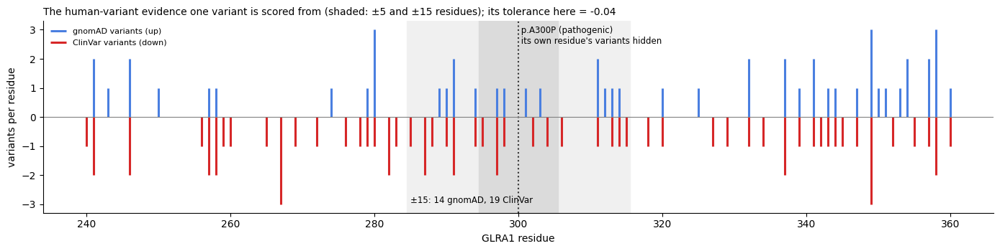

In [14]:
# 14h setup: one row per labelled ClinVar variant in the training + validation genes (test genes untouched)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from convolve import substitution_weight

N_POS_FOLDS = 5                                                     # residue groups for hiding each variant's own residue
RES_COLS = ["esm_wt_lp", "esm_entropy", "esm_mean_llr", "rsa", "plddt", "buried_sasa", "iface_any", "iface_homo",
            "iface_hetero", "disorder", "binding", "ann_disorder_curated", "msa_conservation"] + ANN_COLS
KD = dict(zip(AA20, [1.8, 2.5, -3.5, -3.5, 2.8, -0.4, -3.2, 4.5, -3.9, 3.8, 1.9, -3.5, -1.6, -3.5, -4.5, -0.8, -0.7, 4.2, -0.9, -1.3]))
VARIANT_GROUPS = {
    "ESM scores": ["esm_llr", "esm_wt_lp", "esm_entropy", "esm_mean_llr"],
    "human variants nearby": ["tolerance", "gnomad_density", "clinvar_density", "gnomad_within_5", "gnomad_within_15",
                              "clinvar_within_5", "clinvar_within_15"],
    "gene-wide variant rates": ["gnomad_per_residue", "clinvar_per_residue"],
    "substitution type": ["blosum62", "grantham", "hydrophobicity_change"],
    "structure (§7)": ["rsa", "plddt", "buried_sasa", "iface_any", "iface_homo", "iface_hetero"],
    "annotations (§8)": ANN_COLS,
    "disorder + conservation": ["disorder", "binding", "ann_disorder_curated", "msa_conservation"],
}
ALL_VAR_FEATURES = sum(VARIANT_GROUPS.values(), [])
seq_len = dict(zip(psd_seq_df.gene, psd_seq_df.sequence.str.len()))


def labelled_variants(rec_of):
    '''ClinVar pathogenic / benign (>= 1 review star) missense variants in the genes of rec_of ({gene: §11 record}),
    one row per variant, with the §10 cluster of its gene.'''
    t = variant_df[(variant_df.database == "ClinVar") & variant_df.clinsig_group.isin(["pathogenic", "benign"])
                   & (variant_df.stars >= 1) & variant_df.gene.isin(rec_of)].drop_duplicates("id")
    t = t[["id", "gene", "position", "reference", "alternate", "protein_consequence", "clinsig_group", "stars",
           "esm_llr"]].reset_index(drop=True)
    t["benign"] = t.clinsig_group.eq("benign")
    t["cluster"] = t.gene.map(lambda g: rec_of[g]["cluster"])
    return t


def position_counts(variants, database):
    '''{gene: number of variants from this database at each residue}'''
    d = variants[variants.database == database]
    return {g: np.bincount(p.to_numpy() - 1, minlength=seq_len[g]) for g, p in d.groupby("gene").position}


def add_variant_features(t, seed=SEED):
    '''Add every feature group to a table of labelled variants (from labelled_variants). The residues are dealt into
    N_POS_FOLDS groups, and a variant's human-variant features come from tracks rebuilt WITHOUT any variant at the
    residues of its own group: no variant ever sees its own residue's variants.
    Returns (table, counts): counts[group][database][gene] = variants per residue, used by the window networks.'''
    key = t.gene + ":" + t.position.astype(str)
    keys = key.unique()
    fold_of = dict(zip(keys, np.random.default_rng(seed).integers(0, N_POS_FOLDS, len(keys))))
    t = t.assign(pos_fold=key.map(fold_of))
    tv = tolerance_variants[tolerance_variants.gene.isin(set(t.gene))]
    tv_fold = (tv.gene + ":" + tv.position.astype(str)).map(fold_of)     # NaN = no labelled variant there: always kept
    seqs = psd_seq_df[psd_seq_df.gene.isin(set(t.gene))][["gene", "sequence", "disorder_scores"]]
    counts, parts = {}, []
    for k in range(N_POS_FOLDS):
        kept = tv[tv_fold.ne(k)]
        built = build_tolerance_columns(seqs, kept, name="oof", gnomad_min_count=0, verbose=False)
        track = {c: dict(zip(built.gene, built[f"{c}_oof"])) for c in ["tolerance", "gnomad_y", "clinvar_y"]}
        counts[k] = {db: position_counts(kept, db) for db in ["GnomAD", "ClinVar"]}
        d = t[t.pos_fold == k].copy()
        i = d.position.to_numpy() - 1
        for c, col in [("tolerance", "tolerance"), ("gnomad_y", "gnomad_density"), ("clinvar_y", "clinvar_density")]:
            d[col] = [track[c][g][p] for g, p in zip(d.gene, i)]
        for db, short in [("GnomAD", "gnomad"), ("ClinVar", "clinvar")]:
            cnt = {g: counts[k][db].get(g, np.zeros(seq_len[g], int)) for g in d.gene.unique()}
            for w in (5, 15):
                d[f"{short}_within_{w}"] = [cnt[g][max(p - w, 0):p + w + 1].sum() for g, p in zip(d.gene, i)]
            d[f"{short}_per_residue"] = [cnt[g].sum() / seq_len[g] for g in d.gene]
        parts.append(d)
    t = pd.concat(parts).sort_index()
    # residue-level features (§4, §7, §8) and the type of substitution
    t = t.merge(residue_df[["gene", "pos"] + RES_COLS].rename(columns={"pos": "position"}), on=["gene", "position"], how="left")
    t["blosum62"] = [substitution_weight(a, b, "blosum62") for a, b in zip(t.reference, t.alternate)]
    t["grantham"] = [substitution_weight(a, b, "grantham") for a, b in zip(t.reference, t.alternate)]
    t["hydrophobicity_change"] = [KD.get(b, np.nan) - KD.get(a, np.nan) for a, b in zip(t.reference, t.alternate)]
    t[ALL_VAR_FEATURES] = t[ALL_VAR_FEATURES].astype("float64")
    return t, counts


rec_of = {g: r for r in probe_train + probe_val for g in r["genes"]}              # gene -> its §11 record
t0 = time.time()
lab, fold_counts = add_variant_features(labelled_variants(rec_of))
print(f"{(~lab.benign).sum():,} pathogenic + {lab.benign.sum():,} benign variants in {lab.gene.nunique()} genes "
      f"({lab.cluster.nunique()} clusters); features built {N_POS_FOLDS}x with each variant's residue hidden "
      f"({time.time() - t0:.0f} s)")
y_lab = lab.benign.to_numpy()
CV = list(GroupKFold(5).split(lab, y_lab, lab.cluster))                    # whole clusters held out each round
esm_unsure = (lab.esm_llr > lab.loc[lab.benign, "esm_llr"].median()).to_numpy()

# picture: what the model knows about one pathogenic variant
busy = lab[~lab.benign & (lab.gnomad_within_15 >= 4) & (lab.clinvar_within_15 >= 3)]
ex = busy.loc[(busy.position - 300).abs().idxmin()] if len(busy) else lab[~lab.benign].iloc[0]
cnt_g = fold_counts[ex.pos_fold]["GnomAD"].get(ex.gene, np.zeros(seq_len[ex.gene], int))
cnt_c = fold_counts[ex.pos_fold]["ClinVar"].get(ex.gene, np.zeros(seq_len[ex.gene], int))
lo, hi = max(ex.position - 60, 1), min(ex.position + 60, seq_len[ex.gene])
xs = np.arange(lo, hi + 1)
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.axvspan(ex.position - 15.5, ex.position + 15.5, color="0.94", zorder=0)
ax.axvspan(ex.position - 5.5, ex.position + 5.5, color="0.86", zorder=0)
ax.vlines(xs, 0, cnt_g[xs - 1], color="#4a7fe0", lw=2.2, label="gnomAD variants (up)")
ax.vlines(xs, 0, -cnt_c[xs - 1], color="#d62728", lw=2.2, label="ClinVar variants (down)")
ax.axvline(ex.position, color="0.2", ls=":", lw=1.5)
ax.text(ex.position, ax.get_ylim()[1] * 0.95, f" {ex.protein_consequence} ({ex.clinsig_group})\n its own residue's variants hidden",
        fontsize=8.5, va="top")
ax.text(ex.position - 15, ax.get_ylim()[0] * 0.92, f"±15: {int(ex.gnomad_within_15)} gnomAD, {int(ex.clinvar_within_15)} ClinVar",
        fontsize=8.5, va="bottom")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel(f"{ex.gene} residue"); ax.set_ylabel("variants per residue")
ax.set_title(f"The human-variant evidence one variant is scored from (shaded: ±5 and ±15 residues); "
             f"its tolerance here = {ex.tolerance:.2f}", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

**Train and score every model.** The cell below runs the cross-validation for each model and collects one out-of-fold prediction per variant. Every variant is scored by a model that never trained on its gene's cluster. The window networks are defined here: a small dilated CNN and a BiLSTM that read the ±50-residue window.

In [15]:
# cross-validated predictions for every variant-level model
WIN_V = 50                                                 # residues on each side for the window networks
cache = os.path.join(BASE_DIR, "variant_predictions.parquet")
var_pred = pd.read_parquet(cache) if os.path.exists(cache) and not RERUN else pd.DataFrame(index=lab.index)


def cross_validated(make, X):
    '''Out-of-fold P(benign) for every variant: fit on 4/5 of the clusters, predict the other 1/5, rotate.'''
    p = np.zeros(len(X))
    for tr, te in CV:
        p[te] = make().fit(X[tr], y_lab[tr]).predict_proba(X[te])[:, 1]
    return p


logistic = lambda: make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                                 LogisticRegression(max_iter=5000))
trees = lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40,
                                               l2_regularization=1.0, random_state=SEED)
mlp = lambda seed: make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                                 MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-2, early_stopping=True,
                                               max_iter=300, random_state=seed))
X_all = lab[ALL_VAR_FEATURES].to_numpy()
X_pcs = np.stack([(REPS[rec_of[g]["gene"]][p - 1].astype(np.float32) - mean_rep) @ PCS
                  for g, p in zip(lab.gene, lab.position)])

simple = {
    "logistic: ESM LLR + tolerance": lambda: cross_validated(logistic, lab[["esm_llr", "tolerance"]].to_numpy()),
    "logistic: all features": lambda: cross_validated(logistic, X_all),
    "gradient-boosted trees: all features": lambda: cross_validated(trees, X_all),
    "MLP: all features + ESM representation": lambda: np.mean(
        [cross_validated(lambda: mlp(s), np.hstack([X_all, X_pcs])) for s in range(N_SEEDS)], axis=0),
}
for name, run in simple.items():
    if name not in var_pred:
        t0 = time.time(); var_pred[name] = run(); print(f"  {name:42s} ({time.time() - t0:.0f} s)")
        var_pred.to_parquet(cache)                                   # saved after every model

# ---- window networks: ±50 residues of sequence + raw variant counts (own residue hidden) + disorder
n_win = 2 * WIN_V + 1
win_tok = np.full((len(lab), n_win), PAD, np.int64)
win_trk = np.zeros((len(lab), 4, n_win), np.float32)      # channels: log(1+gnomAD), log(1+ClinVar), disorder, inside
dis_of_gene = dict(zip(psd_seq_df.gene, psd_seq_df.disorder_scores))
for i, (g, p, k) in enumerate(zip(lab.gene, lab.position, lab.pos_fold)):
    L = seq_len[g]; lo = p - 1 - WIN_V; a, b = max(lo, 0), min(lo + n_win, L); s = slice(a - lo, b - lo)
    win_tok[i, s] = rec_of[g]["tokens"][a:b].numpy()
    for ch, db in enumerate(["GnomAD", "ClinVar"]):
        c = fold_counts[k][db].get(g)
        if c is not None:
            win_trk[i, ch, s] = np.log1p(c[a:b])
    win_trk[i, 2, s] = np.asarray(dis_of_gene[g])[a:b]
    win_trk[i, 3, s] = 1.0
alt_tok = np.array([ALPHABET.get_idx(a) for a in lab.alternate])
llr_std = ((lab.esm_llr - lab.esm_llr.mean()) / lab.esm_llr.std()).fillna(0).to_numpy(np.float32)


class VariantWindowNet(nn.Module):
    '''Reads ±50 residues around the variant (amino acids + raw gnomAD / ClinVar counts + disorder) with a dilated CNN
    or a BiLSTM, then combines what it read at the centre with the new amino acid and ESM's LLR.'''
    def __init__(self, kind, d=64):
        super().__init__()
        self.kind = kind
        self.aa = nn.Embedding(len(ALPHABET), 16, padding_idx=PAD)
        self.alt = nn.Embedding(len(ALPHABET), 8)
        if kind == "CNN":                                  # dilations 1..16 -> sees ±62 residues
            self.inp = nn.Conv1d(20, d, 1)
            self.blocks = nn.ModuleList(nn.Sequential(nn.Conv1d(d, d, 5, padding=2 * k, dilation=k), nn.GELU(),
                                                      nn.Dropout(0.1)) for k in (1, 2, 4, 8, 16))
            width = d
        else:
            self.lstm = nn.LSTM(20, d, batch_first=True, bidirectional=True)
            width = 2 * d
        self.head = nn.Sequential(nn.Linear(width + 9, 64), nn.GELU(), nn.Dropout(0.2), nn.Linear(64, 1))

    def forward(self, tok, trk, alt, llr):
        h = torch.cat([self.aa(tok), trk.transpose(1, 2)], dim=-1)          # (batch, 101, 20)
        if self.kind == "CNN":
            h = self.inp(h.transpose(1, 2))
            for block in self.blocks:
                h = h + block(h)
            centre = h[:, :, WIN_V]
        else:
            centre = self.lstm(h)[0][:, WIN_V]
        return self.head(torch.cat([centre, self.alt(alt), llr[:, None]], dim=-1)).squeeze(-1)


def window_net_fold(kind, tr, te, seed, epochs=25, patience=4, batch=128):
    '''Train on rows tr (early stopping on 10% of their clusters), return P(benign) for rows te.'''
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    cl = lab.cluster.to_numpy()
    stop_c = set(rng.permutation(np.unique(cl[tr]))[: len(np.unique(cl[tr])) // 10])
    stop = tr[np.isin(cl[tr], list(stop_c))]; fit = tr[~np.isin(cl[tr], list(stop_c))]
    T = lambda rows: [torch.from_numpy(win_tok[rows]).to(device), torch.from_numpy(win_trk[rows]).to(device),
                      torch.from_numpy(alt_tok[rows]).to(device), torch.from_numpy(llr_std[rows]).to(device)]
    model = VariantWindowNet(kind).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

    @torch.no_grad()
    def prob(rows):
        model.eval()
        return np.concatenate([torch.sigmoid(model(*T(rows[i:i + 1024]))).cpu().numpy() for i in range(0, len(rows), 1024)])

    best, best_state, bad = -1, None, 0
    for epoch in range(epochs):
        model.train(); order = rng.permutation(fit)
        for i in range(0, len(order), batch):
            rows = order[i:i + batch]
            loss = F.binary_cross_entropy_with_logits(model(*T(rows)), torch.from_numpy(y_lab[rows].astype(np.float32)).to(device))
            opt.zero_grad(); loss.backward(); opt.step()
        score = roc_auc_score(y_lab[stop], prob(stop))
        if score > best:
            best, best_state, bad = score, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return prob(te)


for kind in ["CNN", "BiLSTM"]:
    name = f"window {kind}: raw variant tracks + sequence + LLR"
    if name not in var_pred:
        t0 = time.time(); p = np.zeros((N_SEEDS, len(lab)))
        for seed in range(N_SEEDS):
            for tr, te in CV:
                p[seed, te] = window_net_fold(kind, tr, te, seed)
        var_pred[name] = p.mean(0); print(f"  {name:42s} ({time.time() - t0:.0f} s)")
        var_pred.to_parquet(cache)

# single scores (no training); higher = more benign for both
singles = {"ESM-1v LLR": lab.esm_llr, "tolerance (own residue hidden)": lab.tolerance}


def three_aurocs(score, ci=True):
    '''AUROC on all variants (with gene-bootstrap range), mean within-gene AUROC, AUROC where ESM is unsure.'''
    s = np.asarray(score, float); ok = np.isfinite(s); rows_ok = np.flatnonzero(ok)
    a, lo, hi = auroc_ci(y_lab[ok], s[ok], lab.gene[ok]) if ci else (roc_auc_score(y_lab[ok], s[ok]), np.nan, np.nan)
    per_gene = []
    for i in lab.iloc[rows_ok].groupby("gene").indices.values():            # genes with >= 3 of each class
        rows = rows_ok[i]; n_benign = y_lab[rows].sum()
        if n_benign >= 3 and len(rows) - n_benign >= 3:
            per_gene.append(roc_auc_score(y_lab[rows], s[rows]))
    u = ok & esm_unsure
    return {"AUROC": a, "lo": lo, "hi": hi, "within-gene AUROC": np.mean(per_gene), "genes": len(per_gene),
            "AUROC where ESM is unsure": roc_auc_score(y_lab[u], s[u]), "coverage": ok.mean()}


variant_table = pd.DataFrame({name: three_aurocs(s) for name, s in {**singles, **{c: var_pred[c] for c in var_pred}}.items()}).T
variant_table.to_csv(os.path.join(BASE_DIR, "variant_task_models.csv"))
print(variant_table.round(3).to_string())

                                                    AUROC     lo     hi  within-gene AUROC  genes  AUROC where ESM is unsure  coverage
ESM-1v LLR                                          0.906  0.869  0.932              0.885  155.0                      0.532       1.0
tolerance (own residue hidden)                      0.837  0.805  0.864              0.728  155.0                      0.747       1.0
logistic: ESM LLR + tolerance                       0.933  0.911  0.951              0.889  155.0                      0.717       1.0
logistic: all features                              0.961  0.950  0.970              0.920  155.0                      0.867       1.0
gradient-boosted trees: all features                0.958  0.946  0.968              0.920  155.0                      0.854       1.0
MLP: all features + ESM representation              0.959  0.947  0.969              0.920  155.0                      0.862       1.0
window CNN: raw variant tracks + sequence + LLR     0.9

**Model comparison.** The three panels are the three scores from above; the dashed line is ESM-1v alone. Grey = single scores (no training), light blue = simple models on hand-made features, dark blue = neural networks. Bars are 95% bootstrap ranges over genes, shown for the all-variants AUROC.

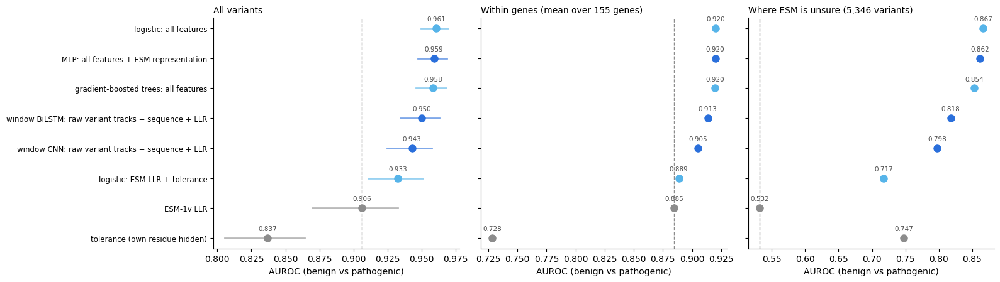

In [16]:
# model comparison on the variant task: three AUROCs per model
kind_colour = lambda n: ("0.55" if n in ("ESM-1v LLR", "tolerance (own residue hidden)")
                         else "#2a6fdb" if n.startswith(("MLP", "window")) else "#56B4E9")
vt = variant_table.sort_values("AUROC")
yy = np.arange(len(vt))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, col in zip(axes, ["AUROC", "within-gene AUROC", "AUROC where ESM is unsure"]):
    for k, (name, r) in enumerate(vt.iterrows()):
        c = kind_colour(name)
        if col == "AUROC":
            ax.plot([r.lo, r.hi], [k, k], color=c, lw=2, alpha=0.6)
        ax.plot(r[col], k, "o", color=c, ms=8)
        ax.text(r[col], k + 0.25, f"{r[col]:.3f}", fontsize=7.5, ha="center", color="0.3")
    ax.axvline(vt.loc["ESM-1v LLR", col], color="0.55", ls="--", lw=1)
    ax.set_title({"AUROC": "All variants", "within-gene AUROC": f"Within genes (mean over {int(vt.genes.iloc[0])} genes)",
                  "AUROC where ESM is unsure": f"Where ESM is unsure ({esm_unsure.sum():,} variants)"}[col],
                 loc="left", fontsize=10)
    ax.set_xlabel("AUROC (benign vs pathogenic)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(yy, vt.index, fontsize=8.5)
fig.tight_layout(); plt.show()

**Which feature groups matter for the variant task?** The tree ensemble from above, refitted with different feature groups, scored on all variants and within genes. Three views:
- **alone:** how much each group knows by itself;
- **added to ESM:** the ESM scores plus one group, compared with the ESM scores alone. This is the direct test of the hypothesis: does *human variant data* add to evolution, and does it add more than structure or annotations do?
- **removed from all:** does anything else already cover this group?

Bars in the two difference panels show 95% ranges from a paired gene bootstrap: the same resampled genes for both models, so the range reflects only the difference. The ROC curves at the bottom right compare the main models on all variants (solid) and where ESM is unsure (dotted).

trees, all features: AUROC 0.958 | ESM scores only: 0.904
                         alone  alone, within genes  added to ESM  added to ESM, within genes  removed  removed, within genes
substitution type        0.713                0.716         0.015                       0.013   -0.003                 -0.003
gene-wide variant rates  0.721                0.505         0.007                      -0.012    0.001                  0.002
annotations (§8)         0.795                0.716         0.009                       0.004    0.000                  0.001
structure (§7)           0.875                0.798         0.036                       0.011   -0.004                 -0.004
disorder + conservation  0.893                0.816         0.040                       0.017   -0.004                  0.000
human variants nearby    0.894                0.797         0.029                       0.009   -0.005                 -0.006
ESM scores               0.904                0.889         

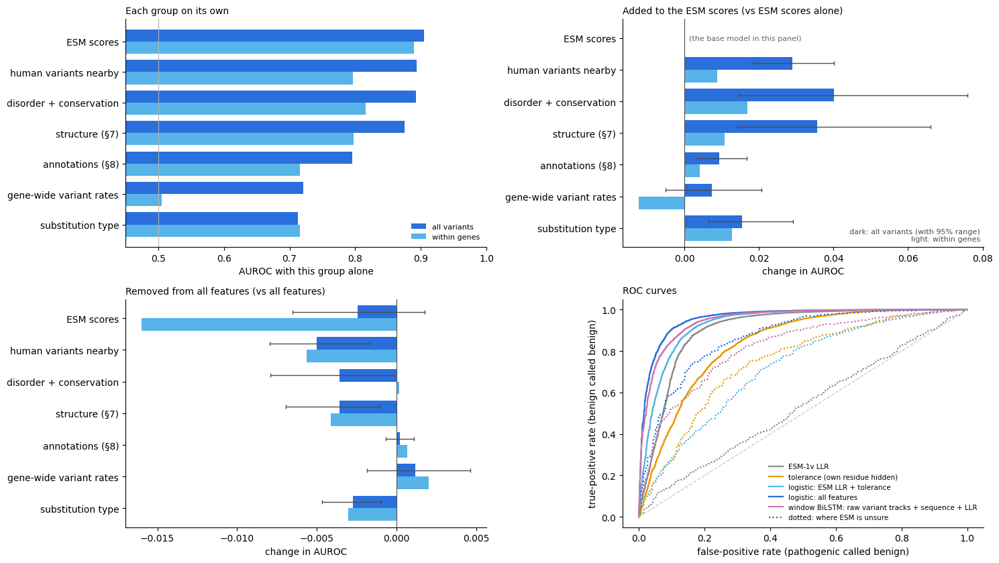

In [17]:
# feature-group ablation with the tree ensemble (alone / added to ESM / removed), and ROC curves of the main models
cache = os.path.join(BASE_DIR, "ablation_variant_features.parquet")
group_pred = pd.read_parquet(cache) if os.path.exists(cache) and not RERUN else pd.DataFrame(index=lab.index)
ESM_COLS = VARIANT_GROUPS["ESM scores"]
for g, cols in VARIANT_GROUPS.items():
    plans = [(f"only {g}", cols), (f"without {g}", [c for c in ALL_VAR_FEATURES if c not in cols])]
    if g != "ESM scores":
        plans.append((f"ESM + {g}", ESM_COLS + cols))
    for plan, use in plans:
        if plan not in group_pred:
            group_pred[plan] = cross_validated(trees, lab[use].to_numpy())
group_pred.to_parquet(cache)


def auroc_gain(a, b, n=500):
    '''AUROC(a) - AUROC(b) on the same variants, with a paired gene-bootstrap 95% range.'''
    a, b = np.asarray(a), np.asarray(b)
    stat = lambda rows: (roc_auc_score(y_lab[rows], a[rows]) - roc_auc_score(y_lab[rows], b[rows])
                         if len(set(y_lab[rows])) == 2 else np.nan)
    return (roc_auc_score(y_lab, a) - roc_auc_score(y_lab, b), *gene_bootstrap(stat, lab.gene, n))


full = var_pred["gradient-boosted trees: all features"]
esm_only = group_pred["only ESM scores"]
within = lambda p: three_aurocs(p, ci=False)["within-gene AUROC"]
rows = {}
for g in VARIANT_GROUPS:
    alone = three_aurocs(group_pred[f"only {g}"], ci=False)
    r = {"alone": alone["AUROC"], "alone, within genes": alone["within-gene AUROC"]}
    r["removed"], r["removed lo"], r["removed hi"] = auroc_gain(group_pred[f"without {g}"], full)
    r["removed, within genes"] = within(group_pred[f"without {g}"]) - within(full)
    if g != "ESM scores":
        r["added to ESM"], r["added lo"], r["added hi"] = auroc_gain(group_pred[f"ESM + {g}"], esm_only)
        r["added to ESM, within genes"] = within(group_pred[f"ESM + {g}"]) - within(esm_only)
    rows[g] = r
abl = pd.DataFrame(rows).T.sort_values("alone")
print(f"trees, all features: AUROC {roc_auc_score(y_lab, full):.3f} | ESM scores only: {roc_auc_score(y_lab, esm_only):.3f}")
print(abl[["alone", "alone, within genes", "added to ESM", "added to ESM, within genes", "removed",
           "removed, within genes"]].astype(float).round(3).to_string())

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
yy = np.arange(len(abl))
ax = axes[0, 0]
ax.barh(yy + 0.2, abl.alone, height=0.4, color="#2a6fdb", label="all variants")
ax.barh(yy - 0.2, abl["alone, within genes"], height=0.4, color="#56B4E9", label="within genes")
ax.set_xlim(0.45, 1); ax.axvline(0.5, color="0.7", lw=0.8)
ax.set_yticks(yy, abl.index); ax.set_xlabel("AUROC with this group alone")
ax.set_title("Each group on its own", loc="left", fontsize=10); ax.legend(frameon=False, fontsize=8, loc="lower right")
for ax, key, lo, hi, title in [
        (axes[0, 1], "added to ESM", "added lo", "added hi", "Added to the ESM scores (vs ESM scores alone)"),
        (axes[1, 0], "removed", "removed lo", "removed hi", "Removed from all features (vs all features)")]:
    d = abl[key].astype(float)
    ok = d.notna().to_numpy()
    ax.barh(yy[ok] + 0.2, d[ok], height=0.4, color="#2a6fdb",
            xerr=[(d - abl[lo].astype(float))[ok], (abl[hi].astype(float) - d)[ok]],
            error_kw=dict(ecolor="0.3", lw=1, capsize=2))
    ax.barh(yy[ok] - 0.2, abl[f"{key}, within genes"].astype(float)[ok], height=0.4, color="#56B4E9")
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_yticks(yy, abl.index); ax.set_xlabel("change in AUROC"); ax.set_ylim(-0.6, len(abl) - 0.4)
    ax.set_title(title, loc="left", fontsize=10)
axes[0, 1].text(0, list(abl.index).index("ESM scores"), "  (the base model in this panel)", va="center", fontsize=8, color="0.4")
axes[0, 1].text(0.99, 0.02, "dark: all variants (with 95% range)\nlight: within genes", transform=axes[0, 1].transAxes,
                ha="right", va="bottom", fontsize=8, color="0.3")
main = ["ESM-1v LLR", "tolerance (own residue hidden)", "logistic: ESM LLR + tolerance", "logistic: all features",
        "window BiLSTM: raw variant tracks + sequence + LLR"]
scores = {**singles, **{c: var_pred[c] for c in var_pred}}
ax = axes[1, 1]
for name, c in zip(main, ["0.55", "#E69F00", "#56B4E9", "#2a6fdb", "#CC79A7"]):
    s = np.asarray(scores[name], float)
    for subset, ls in [(np.ones(len(lab), bool), "-"), (esm_unsure, ":")]:
        fpr, tpr, _ = roc_curve(y_lab[subset], s[subset])
        ax.plot(fpr, tpr, color=c, ls=ls, lw=1.6, label=name if ls == "-" else None)
ax.plot([0, 1], [0, 1], color="0.8", ls="--", lw=1)
ax.plot([], [], color="0.3", ls=":", label="dotted: where ESM is unsure")
ax.set_xlabel("false-positive rate (pathogenic called benign)"); ax.set_ylabel("true-positive rate (benign called benign)")
ax.set_title("ROC curves", loc="left", fontsize=10); ax.legend(frameon=False, fontsize=7.5, loc="lower right")
for a in axes.flat: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 14i. Updated conclusions: what 14f–14h mean for §15

**First run (2026-10-21; the cells above reproduce these numbers from the cache):**

| question | result |
|---|---|
| architectures on the per-residue target (14f) | within-gene Spearman on unseen genes, mean of 3 seeds: from scratch 0.03–0.05 (window MLP 0.041, CNN 0.032, BiLSTM 0.054); frozen ESM-1v 0.09–0.125 (linear probe 0.105, MLP head 0.090, CNN head 0.099, **BiLSTM head 0.125**). Noise ceiling 0.39 |
| per-residue models as variant scores (14f) | validation genes, 641 pathogenic / 742 benign: every trained per-residue model 0.50–0.79 AUROC, far below ESM-1v's LLR (0.94) |
| which residue features matter (14g, part 1) | trees on all feature groups 0.126 (95% range 0.09–0.17). Only **disorder** is a real loss when removed (−0.047); structure, annotations, conservation and position add nothing reliable to this target |
| which target recipe (14g, part 2) | **ClinVar track from pathogenic variants only**: noise ceiling 0.37 → **0.61**, linear probe 0.10 → **0.32**, held-out AUROC of the track 0.79 → **0.84**. Dropping only ClinVar-benign: small gain (0.79 → 0.80). gnomAD singletons: more reproducible (0.46) but less useful (AUROC 0.76; the probe falls to chance). Smoothing width: little effect |
| variant task, all variants (14h) | 5,449 pathogenic + 9,890 benign variants in 716 genes, each scored by a model that never saw its cluster: ESM-1v 0.906, tolerance 0.837, logistic ESM + tolerance 0.933, **logistic / trees / MLP on all features 0.958–0.961**, window BiLSTM on raw variant tracks 0.950, window CNN 0.943 |
| variant task, within genes (155 genes) | ESM 0.885 → all features **0.920** |
| variant task, where ESM is unsure (5,346 variants) | ESM 0.53 (chance), tolerance alone 0.75, **all features 0.87** |
| what each group adds to ESM (14h, trees) | disorder + conservation +0.040, structure +0.036, **human variants nearby +0.029** (all variants; 95% ranges exclude 0). Within genes the gains are smaller: +0.017, +0.011, +0.009. Removing any one group from all features costs ≤ 0.006: the groups overlap heavily |

**What this says:**
1. **For the per-residue target, the architecture isn't the bottleneck.** ESM's pre-training roughly doubles what any network learns from scratch on ~850 proteins. Context helps only a little (BiLSTM > CNN ≈ window MLP from scratch; the BiLSTM head is the best on ESM). The best model reaches a third of the noise ceiling, and the ceiling itself is low. LoRA fine-tuning (§15) would likely add a few hundredths, not change the picture.
2. **The target recipe matters more than the model.** Building the ClinVar side of the track from pathogenic variants only makes the target far more reproducible and three times more learnable, and it classifies held-out variants better. §3 deliberately counts every ClinVar variant, VUS included, as evidence of *intolerance*. For this target, that appears to dilute the signal. Part of the gain is that pathogenic variants cluster in hotspots, which both halves of the data see. ClinVar labels then enter the target, so they must stay out of anything used to evaluate it, as 14g does by excluding the held-out variants.
3. **The variant-severity task works, and it supports the hypothesis.** Combining ESM with human variant density, structure, disorder and annotations lifts the AUROC from 0.906 to 0.96 overall and from 0.885 to 0.92 within genes. Where ESM is unsure, it lifts the AUROC from chance to 0.87. Human variant data adds to evolution by itself (+0.029), but so do structure and disorder, and they partly carry the same information: they all mark constrained regions.
4. **Simple models are enough for the variant task.** Logistic regression on the hand-made features matches the trees and the MLP. The window networks, which learn their own "smoothing" from the raw positions of nearby variants, come close (0.950) but don't beat `convolve_v4` plus the other features. The limit is the information available, not model capacity.

**Recommendation before §15:**
1. **Make the variant-level model (14h) the main product.** It already beats ESM on unseen gene clusters, runs on this laptop in minutes, and its output is per substitution. Its final test is the untouched test genes (§16).
2. **If you still want a Biowulf run, change the target first.** Set `CLINVAR_GROUPS = ("pathogenic",)` in §3, rerun §3–§11 to rebuild the records, and rerun 14a–14d. A model fine-tuned on that target has three times more learnable signal, and its per-residue prediction could become one more feature for the 14h model.
3. **Running §15 unchanged** would mostly measure how much LoRA adds over the 0.125 of the frozen-ESM BiLSTM head, on a target with a 0.39 ceiling.

---
## 15. Packaging and running the job on Biowulf

**Goal:** copy `tolerance_job/` to Biowulf, set up the software there once, and run the training on an NIH GPU. This section writes every file Biowulf needs, checks them here, and lists the exact commands to type on the cluster.

### What an HPC cluster is, in one paragraph
Biowulf is thousands of computers ("**nodes**") in a data centre, shared by everyone at NIH. You never sit at them. You log in remotely to a small front-door computer (the **login node**), describe the work you want done in a short script (a **job**), and hand it to a program called **Slurm** (the **scheduler**). Slurm puts the job in a **queue** and, when a node with the resources you asked for (e.g. one GPU, 48 GB of memory, 24 hours) becomes free, runs your script there, unattended, while you're logged out. Everything the script prints goes into a log file; everything it saves lands in your storage. The rule that makes it work: **say what you need, and Slurm finds where and when.**

### Words used below
| word | meaning |
|---|---|
| **node** | one computer of the cluster: CPUs, memory, sometimes GPUs |
| **login node** (`biowulf.nih.gov`) | where you land after `ssh`. For editing, submitting and checking only, never heavy computing |
| **helix** (`helix.nih.gov`) | a separate computer for **copying files** in and out, and for downloads |
| **Slurm** | the scheduler: queues jobs and starts them on suitable nodes |
| **batch job** (`sbatch`) | a script Slurm runs unattended; you can log out |
| **interactive session** (`sinteractive`) | Slurm gives *you* a node to type commands on, for testing and setup |
| **partition** | a group of nodes; GPUs are in the `gpu` partition |
| **GRES** | "generic resources" you request by name: GPUs (`gpu:a100:1`) and local disk (`lscratch:20`) |
| **wall time** (`--time`) | the maximum real time your job may run before Slurm stops it |
| **job ID** | the number Slurm gives each job; used in log names and to check or cancel it |
| **`/home/$USER`** | small personal space (configs, scripts). Easy to fill, so don't put big files here |
| **`/data/$USER`** | your large project space, visible from every node: the job folder, software, model weights, results |
| **`/lscratch/$SLURM_JOB_ID`** | fast disk inside the node you were given, only while the job runs, deleted afterwards |
| **conda environment** | a self-contained folder of Python plus packages (torch, esm), so the job uses exactly the versions tested here |
| **`$USER`** | the shell's name for your username; on Biowulf it fills itself in |

### The plan
**This Mac has no NIH network access**, so files travel in two hops: this Mac → an NIH computer (USB drive or NIH-approved cloud storage) → Biowulf (`scp` from the NIH computer). The package is small (~4 MB), and everything large (Miniforge, the ESM-2 weights) is downloaded on Biowulf itself.

| when | where | step |
|---|---|---|
| once | this Mac | 15b–15e: write the Biowulf files; 15f: check them and build the **transfer bundle** (archive + checksum + `WALKTHROUGH.md`) |
| once | NIH computer | 15g part A–B: verify the bundle, upload it to Biowulf, unpack it |
| once | Biowulf | 15g part C: install conda, create the environment, download ESM-2 weights |
| per run | Biowulf | 15g parts D–F: short GPU test, submit, monitor |
| per run | NIH computer → this Mac | 15g part G: bring the results back for §16 |
| if needed | Biowulf | 15g part H: resume a run that hit its time limit |

`WALKTHROUGH.md` in the bundle repeats every step as plain text, so you can follow it on the NIH computer without this notebook.

**About the details:** the commands follow Biowulf's long-standing conventions. When this section was written (2026-10-21), hpc.nih.gov was temporarily offline, so the GPU type names and the time limits couldn't be re-checked. On Biowulf, `freen` lists the GPU types available now and `batchlim` the limits. Compare them with the values in `submit.sh` before the first real run. The HPC user guide (`hpc.nih.gov/docs/userguide.html`) is the authority.

### 15a. The map: what lives where, and how the pieces talk

**Top:** the parts of Biowulf you'll use, and what travels between them.
- Files go **from this Mac to an NIH computer** (USB or cloud storage), and from there **to helix** (`scp`). You **log in** to the login node from the NIH computer.
- From there you **submit**; Slurm **runs** the job on a GPU node.
- Every node sees the same `/data/$USER`. That's how the job finds the code and data you copied, and how you find its results afterwards.

**Bottom:** the order of operations, lettered as in the walk-along (15g / `WALKTHROUGH.md`). A–C happen once; D–G for every training run; H only if a run hits its time limit.

In [ ]:
# diagrams: Biowulf's parts, and the order of operations
from matplotlib.patches import FancyBboxPatch

def node_box(ax, x, y, w, h, title, sub, face, title_color="black"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", facecolor=face,
                                edgecolor="0.4", lw=1))
    ax.text(x + w / 2, y + h - 0.22, title, ha="center", va="top", fontsize=9.5, fontweight="bold", color=title_color)
    ax.text(x + w / 2, y + h - 0.62, sub, ha="center", va="top", fontsize=7.8, color="0.25")

def link(ax, p0, p1, text, color="0.35", offset=(0, 0.12)):
    ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4))
    ax.text((p0[0] + p1[0]) / 2 + offset[0], (p0[1] + p1[1]) / 2 + offset[1], text, ha="center", fontsize=8, color=color)

fig, axes = plt.subplots(2, 1, figsize=(15, 9.5), gridspec_kw={"height_ratios": [1.35, 1]})
ax = axes[0]
node_box(ax, 0.0, 2.2, 2.2, 1.6, "this Mac", "notebook builds\ntolerance_job.tar.gz\n(no NIH network)", "#eeeeee")
node_box(ax, 2.9, 2.2, 2.3, 1.6, "NIH computer", "on the NIH network:\nterminal (ssh, scp)\n+ WALKTHROUGH.md", "#f2f2f2")
node_box(ax, 5.9, 3.5, 2.5, 1.4, "helix.nih.gov", "data-transfer host:\nuploads (scp)\nand downloads (wget)", "#fdebd0")
node_box(ax, 5.9, 0.9, 2.5, 1.6, "biowulf.nih.gov", "login node:\nedit, submit, monitor\n(no heavy computing)", "#dbe7fb")
node_box(ax, 9.1, 0.9, 2.0, 1.6, "Slurm", "the scheduler:\nqueue → finds a node\n→ starts your job", "#e8daef")
node_box(ax, 11.8, 0.4, 3.4, 2.6, "GPU compute node", "1 × A100 GPU, 8 CPU cores,\n48 GB memory (as requested)\n\nruns submit.sh → train.py\n/lscratch/$SLURM_JOB_ID\n(fast local disk, this job only)",
         "#d5f5e3")
node_box(ax, 9.1, 3.5, 6.1, 1.6, "/data/$USER  (shared storage, seen by every node)",
         "tolerance_job/  (code, data, configs; results in runs/<job ID>/)\n"
         "conda/  (Python + packages)    torch_cache/  (ESM-2 weights)", "#fef9e7")
link(ax, (2.2, 3.0), (2.9, 3.0), "USB /\ncloud", offset=(0, 0.2))
link(ax, (5.2, 3.4), (5.9, 4.1), "scp", offset=(-0.15, 0.12))
link(ax, (5.2, 2.6), (5.9, 1.9), "ssh", offset=(-0.15, -0.3))
link(ax, (8.4, 1.7), (9.1, 1.7), "sbatch", offset=(0, 0.15))
link(ax, (11.1, 1.7), (11.8, 1.7), "runs", offset=(0, 0.15))
link(ax, (8.4, 4.2), (9.1, 4.3), "writes", offset=(0, -0.32))
ax.annotate("", xy=(13.5, 3.5), xytext=(13.5, 3.0), arrowprops=dict(arrowstyle="<|-|>", color="0.35", lw=1.4))
ax.text(13.65, 3.25, "reads code / data,\nwrites results", fontsize=8, color="0.35", va="center")
ax.set_xlim(-0.2, 15.4); ax.set_ylim(0.2, 5.4); ax.axis("off")
ax.set_title("Biowulf: who does what", loc="left", fontsize=11)

ax = axes[1]
once = ["A–B  move + unpack\n(Mac → NIH computer → scp)", "C1  download weights\n(ESM-2, on helix)",
        "C2  install conda\n(sinteractive)", "C3  create environment\n(sinteractive + GPU)"]
per_run = ["D  short GPU test\n(sinteractive, timing.json)", "E  sbatch submit.sh\n(login node; prints a job ID)",
           "F  queue → running\n(squeue, logs/, dashboard)", "G  bring results back\n(scp → NIH computer → Mac)"]
for row, (items, face, label) in enumerate([(once, "#fdebd0", "once"), (per_run, "#d5f5e3", "every run")]):
    y = 2.0 - row * 1.6
    ax.text(-0.2, y + 0.45, label, ha="right", va="center", fontsize=10, fontweight="bold", color="0.35")
    for k, text in enumerate(items):
        node_box(ax, k * 3.7, y, 3.1, 0.95, text.split("\n")[0], text.split("\n")[1], face)
        if k < len(items) - 1:
            link(ax, (k * 3.7 + 3.1, y + 0.47), ((k + 1) * 3.7, y + 0.47), "")
ax.annotate("", xy=(3.7 * 2 + 1.55, 0.4), xytext=(3.7 * 2 + 1.55, -0.45),
            arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=1.3, connectionstyle="arc3,rad=0"))
ax.text(3.7 * 2 + 1.75, -0.35, "hit the time limit (TIMEOUT)? → H  sbatch again with RUN_DIR = same folder: it resumes from last.pt",
        fontsize=8.5, color="#d62728")
ax.set_xlim(-1.4, 15.2); ax.set_ylim(-0.6, 3.2); ax.axis("off")
ax.set_title("Order of operations", loc="left", fontsize=11)
fig.tight_layout(); plt.show()

### 15b. The software recipe: `environment.yml` (+ a timing config)

Biowulf doesn't have this notebook's Python packages. A **conda environment** recreates them in a folder under `/data/$USER/conda`, from a short recipe file, `environment.yml`, that lists exactly what to install:
- **Pinned versions:** the same ones tested here (Python 3.10, numpy 1.26, torch 2.5.1, fair-esm 2.0.0), so Biowulf runs what was checked on this Mac.
- **The Linux torch package from PyPI includes NVIDIA CUDA support**, so it can use the A100. No separate CUDA install is needed.
- **Only what the training scripts import** (`numpy`, `torch`, `esm`). pandas, matplotlib and the like stay in the notebook.

This cell also writes **`configs/timing.json`**: the full model on 32 proteins for one epoch, used in the short GPU test (15g step 5) to measure speed and memory before the long run. It also creates `setup/` (one-time scripts) and `logs/` (where Slurm writes job output; it must exist before submitting).

In [ ]:
# write environment.yml and configs/timing.json; create setup/ and logs/
import shutil, subprocess

SETUP_DIR, LOGS_DIR = os.path.join(JOB_DIR, "setup"), os.path.join(JOB_DIR, "logs")
os.makedirs(SETUP_DIR, exist_ok=True); os.makedirs(LOGS_DIR, exist_ok=True)
open(os.path.join(LOGS_DIR, "README.txt"), "w").write("Slurm writes each job's output here: <job name>_<job ID>.out\n")

ENVIRONMENT_YML = f'''# conda recipe for the tolerance model on Biowulf -- create with setup/02_create_env.sh
name: tolerance
channels:
  - conda-forge                  # community channel; no licence restrictions
dependencies:
  - python=3.10                  # same as this Mac ({sys.version.split()[0]})
  - numpy=1.26                   # same as this Mac ({np.__version__})
  - pip
  - pip:
      - torch=={torch.__version__.split("+")[0]}            # Linux wheel includes NVIDIA CUDA support
      - fair-esm=={getattr(esm, "__version__", "2.0.0")}          # the ESM models (import esm)
'''
open(os.path.join(JOB_DIR, "environment.yml"), "w").write(ENVIRONMENT_YML)
print(ENVIRONMENT_YML)

timing = {**configs["full"], "epochs": 1, "max_proteins": 32, "log_every": 2, "num_workers": 2}
with open(os.path.join(CONFIG_DIR, "timing.json"), "w") as f:
    json.dump(timing, f, indent=1)
print("configs:", sorted(os.listdir(CONFIG_DIR)), "| new folders: setup/, logs/")

### 15c. One-time setup scripts

Three short shell scripts, run once on Biowulf, in this order. (A shell script is just the commands you'd otherwise type, saved in a file. `bash script.sh` runs them.)

| script | where to run it | what it does | time |
|---|---|---|---|
| `setup/01_install_conda.sh` | an interactive session (`sinteractive`) | installs **Miniforge** (conda + mamba, using conda-forge) into `/data/$USER/conda` | ~2 min |
| `setup/02_create_env.sh` | an interactive session **with a GPU** | builds the `tolerance` environment from `environment.yml`, then checks that PyTorch sees the GPU | ~5–10 min |
| `setup/03_download_weights.sh` | **helix** | downloads ESM-2 650M (~2.5 GB) and the small 8M model into `/data/$USER/torch_cache` | ~2–5 min |

Why these places:
- **The login node is shared by everyone**, so installs go in an interactive session.
- **Downloads go through helix**, the host meant for moving data.
- **Weights are fetched once, before any job runs:** a training job never depends on an internet download halfway through. (Compute nodes can reach the internet through a proxy, but a one-time download is simpler and faster.)

The three cells below write the scripts with `%%writefile`, as §11–12 did for the Python files. Every line is commented. **They are code cells on purpose:** running one saves its text to a file. Shell scripts may be coloured as if they were Python; that's only the editor's colouring.

**If Biowulf's "Conda on Biowulf" page recommends its own installer helper, use that instead of `01_install_conda.sh`.** Everything else works the same, as long as conda ends up in `/data/$USER/conda`.

In [ ]:
%%writefile ../results/tolerance_model/tolerance_job/setup/01_install_conda.sh
#!/bin/bash
# 01_install_conda.sh -- ONE-TIME: install Miniforge (conda + mamba, using conda-forge) into /data/$USER/conda.
# Run inside an interactive session, not on the login node:
#     sinteractive --mem=8g --gres=lscratch:10
#     cd /data/$USER/tolerance_job && bash setup/01_install_conda.sh
set -eo pipefail                                      # stop at the first error

PREFIX=/data/$USER/conda                              # conda lives in /data: /home is too small
if [ -d "$PREFIX" ]; then
    echo "$PREFIX already exists -- nothing to do"; exit 0
fi
cd "/lscratch/${SLURM_JOB_ID:-}" 2>/dev/null || cd /tmp   # download into the node's fast local disk
wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh
bash Miniforge3-Linux-x86_64.sh -b -p "$PREFIX"      # -b: no questions asked; -p: where to install
rm Miniforge3-Linux-x86_64.sh
echo "Miniforge installed in $PREFIX"
echo "use it in any session with:  source $PREFIX/etc/profile.d/conda.sh"

In [ ]:
%%writefile ../results/tolerance_model/tolerance_job/setup/02_create_env.sh
#!/bin/bash
# 02_create_env.sh -- ONE-TIME: build the 'tolerance' conda environment from environment.yml, then check the GPU.
# Run inside an interactive session WITH a GPU, so the check at the end means something:
#     sinteractive --partition=gpu --gres=gpu:a100:1,lscratch:20 --mem=16g --cpus-per-task=4
#     cd /data/$USER/tolerance_job && bash setup/02_create_env.sh
set -eo pipefail

source /data/$USER/conda/etc/profile.d/conda.sh       # makes the 'conda' command available in this shell
export TMPDIR=/lscratch/$SLURM_JOB_ID                 # unpack packages on the fast local disk ...
export PIP_CACHE_DIR=$TMPDIR/pip-cache                # ... and keep pip's download cache out of /home

if conda env list | grep -q "^tolerance "; then
    echo "environment 'tolerance' exists -- updating it from environment.yml"
    mamba env update -n tolerance -f environment.yml
else
    mamba env create -f environment.yml               # mamba = a faster drop-in for conda
fi

conda activate tolerance
python - <<'PY'
import torch, esm
print("torch", torch.__version__, "| esm", getattr(esm, "__version__", "?"))
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU visible -- are you on a GPU node?")
PY

In [ ]:
%%writefile ../results/tolerance_model/tolerance_job/setup/03_download_weights.sh
#!/bin/bash
# 03_download_weights.sh -- ONE-TIME: download the ESM-2 weights into /data/$USER/torch_cache,
# so training jobs never download anything mid-run. Run on helix (the data-transfer host):
#     ssh YOUR_NIH_USERNAME@helix.nih.gov
#     bash /data/$USER/tolerance_job/setup/03_download_weights.sh
set -eo pipefail

DEST=/data/$USER/torch_cache/hub/checkpoints          # where esm.pretrained looks when TORCH_HOME=/data/$USER/torch_cache
mkdir -p "$DEST"
cd "$DEST"
for name in esm2_t33_650M_UR50D esm2_t6_8M_UR50D; do # the real model (~2.5 GB) and the smoke-test model (~30 MB)
    [ -f "$name.pt" ] || wget -nv "https://dl.fbaipublicfiles.com/fair-esm/models/$name.pt"
    [ -f "$name-contact-regression.pt" ] || \
        wget -nv "https://dl.fbaipublicfiles.com/fair-esm/regression/$name-contact-regression.pt"
done
ls -lh "$DEST"

### 15d. The job script: `submit.sh`

This is the file you hand to Slurm (`sbatch submit.sh`). It has two parts:

**1. The `#SBATCH` lines: what to reserve.** To bash they're comments; `sbatch` reads them as the resource request:

| line | means | how chosen |
|---|---|---|
| `--partition=gpu` | run on the GPU nodes | needed for any GPU |
| `--gres=gpu:a100:1,lscratch:20` | one A100 GPU and 20 GB of fast local disk | A100s have 40–80 GB of GPU memory, enough for ESM-2 650M + LoRA at batch size 4. `freen` shows which GPU types exist |
| `--cpus-per-task=8` | 8 CPU cores | feeding data to the GPU (`num_workers: 4`) plus overhead |
| `--mem=48g` | 48 GB of ordinary memory (RAM) | the model (2.6 GB) and data are small; this leaves a wide margin |
| `--time=24:00:00` | stop after 24 hours | adjust after the timing test; shorter jobs usually start sooner. `batchlim` shows the maximum |
| `--output=logs/%x_%j.out` | where printed output goes | `%x` = job name, `%j` = job ID |
| `--mail-type=END,FAIL` | e-mail when the job ends or fails | so you don't need to keep checking |

**2. The commands: what to do once the node is ready.**
1. Print where it's running and which GPU it got.
2. Activate the conda environment and point `TORCH_HOME` at the downloaded weights.
3. If the output folder already has a `last.pt`, add `--resume`.
4. Run `train.py`.

Two settings can be changed at submit time without editing the file:
- `CONFIG`: which config to run (default `configs/full.json`);
- `RUN_DIR`: where results go (default `runs/<job ID>`).

Example: `sbatch --export=ALL,CONFIG=configs/timing.json submit.sh`.

In [ ]:
%%writefile ../results/tolerance_model/tolerance_job/submit.sh
#!/bin/bash
# submit.sh -- the Biowulf batch job that trains the tolerance model.
# Submit from inside the job folder:
#     cd /data/$USER/tolerance_job
#     sbatch submit.sh                                             # full run (configs/full.json)
#     sbatch --export=ALL,CONFIG=configs/timing.json submit.sh     # short timing test as a batch job
#     sbatch --export=ALL,RUN_DIR=runs/12345678 submit.sh          # continue a run that hit its time limit
#
# ---- what to reserve: sbatch reads these #SBATCH lines; bash treats them as comments ----
#SBATCH --job-name=tolerance
#SBATCH --partition=gpu                     # the GPU nodes
#SBATCH --gres=gpu:a100:1,lscratch:20       # one A100 GPU + 20 GB fast local disk (check types with: freen)
#SBATCH --cpus-per-task=8                   # CPU cores: data loading (num_workers 4) + overhead
#SBATCH --mem=48g                           # ordinary memory (RAM) on the node -- not GPU memory
#SBATCH --time=24:00:00                     # wall-time limit hh:mm:ss -- set from the timing test (see: batchlim)
#SBATCH --output=logs/%x_%j.out             # everything printed goes here (%x = job name, %j = job ID)
#SBATCH --mail-type=END,FAIL                # e-mail when the job ends or fails
set -eo pipefail                            # stop at the first error instead of carrying on

CONFIG=${CONFIG:-configs/full.json}         # settings file (change at submit time with --export=ALL,CONFIG=...)
RUN_DIR=${RUN_DIR:-runs/$SLURM_JOB_ID}      # results folder: one per job unless you pass RUN_DIR to resume

echo "job $SLURM_JOB_ID on $(hostname), started $(date)"
echo "config $CONFIG -> results in $RUN_DIR"
nvidia-smi --query-gpu=name,memory.total --format=csv    # which GPU Slurm gave us

source /data/$USER/conda/etc/profile.d/conda.sh           # the conda installed by setup/01
conda activate tolerance                                  # the environment built by setup/02
export TORCH_HOME=/data/$USER/torch_cache                 # the weights downloaded by setup/03
export TMPDIR=/lscratch/$SLURM_JOB_ID                     # temporary files on the node's fast local disk

RESUME=""
if [ -f "$RUN_DIR/last.pt" ]; then                        # an earlier job left a checkpoint here -> continue it
    RESUME="--resume"
    echo "found $RUN_DIR/last.pt -- resuming"
fi

python src/train.py --config "$CONFIG" --out "$RUN_DIR" $RESUME
echo "finished $(date)"

### 15e. `README.md`: the instructions travel with the job

`README.md` goes inside `tolerance_job/`, and the same text also travels next to the archive as `WALKTHROUGH.md`. It's the complete step-by-step guide (15g) as plain text, readable in any text editor on the NIH computer, with no notebook or VS Code needed.

**The next cell is a code cell on purpose:** its content is markdown text, but running it saves that text to `README.md` (`%%writefile`). VS Code may colour it like Python; nothing has been converted.

%%writefile ../results/tolerance_model/tolerance_job/README.md
# tolerance_job: training the tolerance model on Biowulf

Fine-tunes ESM-2 (LoRA) to predict per-residue missense tolerance from protein sequence.
Built by figures/notebooks/05_tolerance_score_modelling.ipynb (sections 11-15).
This file is the complete guide: readable in any text editor (Notepad, TextEdit), no notebook needed.

## What is in this package
| path | what |
|---|---|
| data/ | train.pt / val.pt / test.pt (one record per protein), dataset_info.json, split_manifest.json |
| src/ | dataset.py (windows + batches), model.py (ESM + head, LoRA), train.py (the training loop) |
| configs/ | smoke.json (tiny check), timing.json (full model, 32 proteins, 1 epoch), full.json (the real run) |
| setup/ | one-time setup: 01_install_conda.sh, 02_create_env.sh, 03_download_weights.sh |
| submit.sh | the Slurm batch job |
| environment.yml | the Python packages, pinned to the versions tested |
| logs/ | Slurm writes each job's output here: tolerance_<job ID>.out |
| runs/<job ID>/ | created by each job: metrics.csv, best.pt, last.pt, val_predictions.pt, config.json, run_info.json |

## Step by step: from the NIH computer to results

Replace `USERNAME` with your NIH login name everywhere. Lines starting with `#` are explanations; don't type them.

**Which terminal on the NIH computer?**
- **Windows:** open **PowerShell** (Start menu → type "PowerShell"). Windows 10/11 have `ssh` and `scp` built in.
- **Mac:** open the **Terminal** app.
- **No command line available?** **WinSCP** or **FileZilla** (SFTP to `helix.nih.gov`, port 22) upload by drag-and-drop; then log in with PuTTY or MobaXterm for the commands.

**A. Check the bundle on the NIH computer** (the `transfer/` folder, copied from this Mac). Go to the folder, then compute the fingerprint and compare it with the one in `tolerance_job.tar.gz.sha256`:
```
cd PATH\TO\transfer                                   # e.g.  cd $HOME\Downloads\transfer
Get-FileHash tolerance_job.tar.gz -Algorithm SHA256    # Windows PowerShell
shasum -a 256 tolerance_job.tar.gz                     # Mac
```
The long code printed must equal the one in the `.sha256` file (Windows prints it in capitals; that's fine).

**B. Upload and unpack** (from the same folder on the NIH computer):
```
scp tolerance_job.tar.gz tolerance_job.tar.gz.sha256 USERNAME@helix.nih.gov:/data/USERNAME/
ssh USERNAME@helix.nih.gov                             # log in to helix (asks for your NIH password)
cd /data/$USER
sha256sum -c tolerance_job.tar.gz.sha256               # must say: tolerance_job.tar.gz: OK
tar -xzf tolerance_job.tar.gz                          # unpack -> /data/$USER/tolerance_job/
ls tolerance_job                                       # README.md configs data environment.yml logs setup src submit.sh
```

**C. One-time setup** (~20 min). Still on helix, download the ESM-2 weights first:
```
bash /data/$USER/tolerance_job/setup/03_download_weights.sh    # ~2.5 GB into /data/$USER/torch_cache
exit
```
Then log in to Biowulf. Install conda in a small interactive session, then build the environment in a GPU session:
```
ssh USERNAME@biowulf.nih.gov
sinteractive --mem=8g --gres=lscratch:10              # wait for the prompt to change (you're on a node now)
cd /data/$USER/tolerance_job
bash setup/01_install_conda.sh
exit                                                   # back to the login node
sinteractive --partition=gpu --gres=gpu:a100:1,lscratch:20 --mem=16g --cpus-per-task=4
cd /data/$USER/tolerance_job
bash setup/02_create_env.sh                            # must end with: CUDA available: True | NVIDIA A100 ...
exit
```
Before the first run, check the two cluster details that couldn't be verified when this was written: `freen` (GPU types; is `a100` listed?) and `batchlim` (time limits for the `gpu` partition). If needed, edit `submit.sh` with `nano submit.sh` (Ctrl-O saves, Ctrl-X exits).

**D. Short GPU test** (before every *first* run of a new config):
```
sinteractive --partition=gpu --gres=gpu:a100:1,lscratch:20 --mem=48g --cpus-per-task=8 --time=2:00:00
cd /data/$USER/tolerance_job
source /data/$USER/conda/etc/profile.d/conda.sh && conda activate tolerance
export TORCH_HOME=/data/$USER/torch_cache
python src/train.py --config configs/smoke.json --out runs/test_smoke      # ~1 min: does everything run on the GPU?
python src/train.py --config configs/timing.json --out runs/test_timing &  # full model, 32 proteins, 1 epoch
watch -n 5 nvidia-smi                                  # GPU memory while it runs; Ctrl-C stops watching
```
Note two numbers:
- **Peak GPU memory** in `nvidia-smi`. If it's close to the card's limit, halve `batch_size` and double `grad_accum` in `configs/full.json`.
- **Seconds per epoch** on the last line of the timing run. Full epoch ≈ that × 854 / 32; full run ≈ full epoch × 20. Set `--time` in `submit.sh` to about 1.5× that.

Then `exit`.

**E. Submit the real run** (from the login node):
```
cd /data/$USER/tolerance_job
sbatch submit.sh                                       # prints: Submitted batch job 12345678 -- note the number
```
You can log out now; the job runs without you, and you'll get an e-mail when it ends.

**F. Monitor** (log in again any time):

| command | shows |
|---|---|
| `squeue -u $USER` | your jobs: `PD` = waiting in the queue, `R` = running |
| `tail -f /data/$USER/tolerance_job/logs/tolerance_12345678.out` | the job's output as it happens (Ctrl-C stops *watching*, not the job) |
| `jobload -u $USER` | CPU and memory use of running jobs |
| `jobhist 12345678` | what a finished job used, and how it ended (`COMPLETED`, `FAILED`, `TIMEOUT`) |
| `scancel 12345678` | cancel a job |
| user dashboard (hpc.nih.gov/dashboard) | the same in a web browser on the NIH computer |

**G. Bring the results back** (results are small: LoRA checkpoints are a few MB). On helix, pack one run:
```
ssh USERNAME@helix.nih.gov
cd /data/$USER/tolerance_job
tar -czf /data/$USER/run_12345678.tar.gz runs/12345678 logs/tolerance_12345678.out
exit
```
Download it on the NIH computer, then move it to this Mac (USB / cloud) and unpack it into `results/tolerance_model/biowulf_runs/`, where §16 looks for it:
```
scp USERNAME@helix.nih.gov:/data/USERNAME/run_12345678.tar.gz .
```

**H. If the job hit its time limit** (`jobhist` says `TIMEOUT`): submit again with the same output folder. `submit.sh` finds `last.pt` and continues:
```
cd /data/$USER/tolerance_job
sbatch --export=ALL,RUN_DIR=runs/12345678 submit.sh
```

### When something goes wrong
| symptom | likely cause | fix |
|---|---|---|
| `scp`/`ssh`: connection refused or timed out | not on the NIH network | use the NIH computer, on site or on VPN |
| `sha256sum -c` says FAILED | the archive was damaged in transfer | copy it again |
| `CUDA out of memory` | batch too large for the GPU | halve `batch_size`, double `grad_accum` in `configs/full.json` |
| `ModuleNotFoundError: No module named 'esm'` | environment not active | the `source …conda.sh` / `conda activate tolerance` lines; rerun step C's `02_create_env.sh` |
| `Disk quota exceeded` | big files in `/home` | keep conda, `torch_cache` and `runs/` under `/data/$USER` |
| a download starts inside the job | weights not found | `ls /data/$USER/torch_cache/hub/checkpoints` should list the `esm2_*` files |
| job waits (`PD`) for a long time | the GPUs asked for are busy | `freen`; a shorter `--time`; or another GPU type (e.g. `v100x`, runs in slower 32-bit) |
| `TIMEOUT` | wall time too short | step H (resume), and raise `--time` |
| `logs/…out` not created | submitted from another folder | `cd /data/$USER/tolerance_job` before `sbatch` |

### 15f. Check the package and build the transfer bundle

**Checks:**
- every shell script passes `bash -n` (syntax check without running);
- scripts are made executable;
- `submit.sh` asks for a GPU;
- everything `submit.sh` refers to exists in the folder.

**The bundle** (`results/tolerance_model/transfer/`) holds three files to move to the NIH computer together:

| file | what |
|---|---|
| `tolerance_job.tar.gz` | the whole job folder in one compressed file (an archive, like a .zip), without local test runs and Python caches |
| `tolerance_job.tar.gz.sha256` | the archive's **checksum**: a fingerprint that changes if even one byte is damaged in transfer. 15g part A shows how to compare it on the NIH computer and on Biowulf |
| `WALKTHROUGH.md` | the step-by-step guide (same text as `README.md`) |

**Moving it to the NIH computer:** copy the `transfer/` folder with a USB drive, or through NIH-approved cloud storage (e.g. your institute's Box or OneDrive). It contains only public-data derivatives (gnomAD, ClinVar, UniProt sequences) and code, no patient information. Follow your institute's rules for moving files onto NIH computers.

In [101]:
# check the package, then build the transfer bundle: archive + checksum + walkthrough
import tarfile, hashlib

checks = []
scripts = [os.path.join(JOB_DIR, "submit.sh")] + sorted(
    os.path.join(SETUP_DIR, f) for f in os.listdir(SETUP_DIR) if f.endswith(".sh"))
for path in scripts:
    ok = subprocess.run(["bash", "-n", path], capture_output=True, text=True).returncode == 0   # syntax only
    os.chmod(path, 0o755)                                                                      # executable
    checks.append((f"bash syntax OK: {os.path.relpath(path, JOB_DIR)}", ok))
submit_text = open(os.path.join(JOB_DIR, "submit.sh")).read()
checks.append(("submit.sh requests a GPU", "--partition=gpu" in submit_text and "gpu:" in submit_text))
for needed in ["src/train.py", "configs/full.json", "configs/timing.json", "data/train.pt", "data/val.pt",
               "data/dataset_info.json", "environment.yml", "logs", "README.md"]:
    checks.append((f"present: {needed}", os.path.exists(os.path.join(JOB_DIR, needed))))
for name, ok in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

# the archive: everything Biowulf needs, nothing else (no local runs, no Python caches, no Mac '._' files)
TRANSFER_DIR = os.path.join(OUT, "transfer")
os.makedirs(TRANSFER_DIR, exist_ok=True)
archive = os.path.join(TRANSFER_DIR, "tolerance_job.tar.gz")
def keep(info):
    parts = info.name.split("/")
    if any(p in ("runs", "__pycache__") or p.startswith("._") or p == ".DS_Store" for p in parts):
        return None                                                    # leave it out of the archive
    info.uid = info.gid = 0; info.uname = info.gname = ""              # don't carry this Mac's user ids
    return info
os.environ["COPYFILE_DISABLE"] = "1"                                   # macOS: no hidden '._' metadata files
with tarfile.open(archive, "w:gz") as tar:
    tar.add(JOB_DIR, arcname="tolerance_job", filter=keep)

sha = hashlib.sha256(open(archive, "rb").read()).hexdigest()           # the fingerprint
open(archive + ".sha256", "w").write(f"{sha}  tolerance_job.tar.gz\n")   # same format as the 'sha256sum' tool
shutil.copy(os.path.join(JOB_DIR, "README.md"), os.path.join(TRANSFER_DIR, "WALKTHROUGH.md"))

with tarfile.open(archive) as tar:
    members = [m.name for m in tar.getmembers() if m.isfile()]
print(f"\narchive: {len(members)} files, {os.path.getsize(archive) / 1e6:.1f} MB")
for m in members:
    print("   ", m)
print(f"\nsha256: {sha}")
print(f"\ntransfer bundle ready -> {TRANSFER_DIR}")
for f in sorted(os.listdir(TRANSFER_DIR)):
    print(f"    {f:30s} {os.path.getsize(os.path.join(TRANSFER_DIR, f)) / 1e6:6.2f} MB")

python(55125) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(55126) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(55127) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


PASS  bash syntax OK: submit.sh
PASS  bash syntax OK: setup/01_install_conda.sh
PASS  bash syntax OK: setup/02_create_env.sh
PASS  submit.sh requests a GPU
PASS  present: src/train.py
PASS  present: configs/full.json
PASS  present: configs/timing.json
PASS  present: data/train.pt
PASS  present: data/val.pt
PASS  present: data/dataset_info.json
PASS  present: environment.yml
PASS  present: logs
PASS  present: README.md

archive: 17 files, 3.7 MB
    tolerance_job/README.md
    tolerance_job/configs/full.json
    tolerance_job/configs/smoke.json
    tolerance_job/configs/timing.json
    tolerance_job/data/dataset_info.json
    tolerance_job/data/split_manifest.json
    tolerance_job/data/test.pt
    tolerance_job/data/train.pt
    tolerance_job/data/val.pt
    tolerance_job/environment.yml
    tolerance_job/logs/README.txt
    tolerance_job/setup/01_install_conda.sh
    tolerance_job/setup/02_create_env.sh
    tolerance_job/src/dataset.py
    tolerance_job/src/model.py
    tolerance_job/

### 15g. Step by step: from the NIH computer to results

This is the same text as `WALKTHROUGH.md` in the transfer bundle, so you can follow it on the NIH computer. Replace `USERNAME` with your NIH login name everywhere. Lines starting with `#` are explanations; don't type them.

**Which terminal on the NIH computer?**
- **Windows:** open **PowerShell** (Start menu → type "PowerShell"). Windows 10/11 have `ssh` and `scp` built in.
- **Mac:** open the **Terminal** app.
- **No command line available?** **WinSCP** or **FileZilla** (SFTP to `helix.nih.gov`, port 22) upload by drag-and-drop; then log in with PuTTY or MobaXterm for the commands.

**A. Check the bundle on the NIH computer** (the `transfer/` folder, copied from this Mac). Go to the folder, then compute the fingerprint and compare it with the one in `tolerance_job.tar.gz.sha256`:
```
cd PATH\TO\transfer                                   # e.g.  cd $HOME\Downloads\transfer
Get-FileHash tolerance_job.tar.gz -Algorithm SHA256    # Windows PowerShell
shasum -a 256 tolerance_job.tar.gz                     # Mac
```
The long code printed must equal the one in the `.sha256` file (Windows prints it in capitals; that's fine).

**B. Upload and unpack** (from the same folder on the NIH computer):
```
scp tolerance_job.tar.gz tolerance_job.tar.gz.sha256 USERNAME@helix.nih.gov:/data/USERNAME/
ssh USERNAME@helix.nih.gov                             # log in to helix (asks for your NIH password)
cd /data/$USER
sha256sum -c tolerance_job.tar.gz.sha256               # must say: tolerance_job.tar.gz: OK
tar -xzf tolerance_job.tar.gz                          # unpack -> /data/$USER/tolerance_job/
ls tolerance_job                                       # README.md configs data environment.yml logs setup src submit.sh
```

**C. One-time setup** (~20 min). Still on helix, download the ESM-2 weights first:
```
bash /data/$USER/tolerance_job/setup/03_download_weights.sh    # ~2.5 GB into /data/$USER/torch_cache
exit
```
Then log in to Biowulf. Install conda in a small interactive session, then build the environment in a GPU session:
```
ssh USERNAME@biowulf.nih.gov
sinteractive --mem=8g --gres=lscratch:10              # wait for the prompt to change (you're on a node now)
cd /data/$USER/tolerance_job
bash setup/01_install_conda.sh
exit                                                   # back to the login node
sinteractive --partition=gpu --gres=gpu:a100:1,lscratch:20 --mem=16g --cpus-per-task=4
cd /data/$USER/tolerance_job
bash setup/02_create_env.sh                            # must end with: CUDA available: True | NVIDIA A100 ...
exit
```
Before the first run, check the two cluster details that couldn't be verified when this was written: `freen` (GPU types; is `a100` listed?) and `batchlim` (time limits for the `gpu` partition). If needed, edit `submit.sh` with `nano submit.sh` (Ctrl-O saves, Ctrl-X exits).

**D. Short GPU test** (before every *first* run of a new config):
```
sinteractive --partition=gpu --gres=gpu:a100:1,lscratch:20 --mem=48g --cpus-per-task=8 --time=2:00:00
cd /data/$USER/tolerance_job
source /data/$USER/conda/etc/profile.d/conda.sh && conda activate tolerance
export TORCH_HOME=/data/$USER/torch_cache
python src/train.py --config configs/smoke.json --out runs/test_smoke      # ~1 min: does everything run on the GPU?
python src/train.py --config configs/timing.json --out runs/test_timing &  # full model, 32 proteins, 1 epoch
watch -n 5 nvidia-smi                                  # GPU memory while it runs; Ctrl-C stops watching
```
Note two numbers:
- **Peak GPU memory** in `nvidia-smi`. If it's close to the card's limit, halve `batch_size` and double `grad_accum` in `configs/full.json`.
- **Seconds per epoch** on the last line of the timing run. Full epoch ≈ that × 854 / 32; full run ≈ full epoch × 20. Set `--time` in `submit.sh` to about 1.5× that.

Then `exit`.

**E. Submit the real run** (from the login node):
```
cd /data/$USER/tolerance_job
sbatch submit.sh                                       # prints: Submitted batch job 12345678 -- note the number
```
You can log out now; the job runs without you, and you'll get an e-mail when it ends.

**F. Monitor** (log in again any time):

| command | shows |
|---|---|
| `squeue -u $USER` | your jobs: `PD` = waiting in the queue, `R` = running |
| `tail -f /data/$USER/tolerance_job/logs/tolerance_12345678.out` | the job's output as it happens (Ctrl-C stops *watching*, not the job) |
| `jobload -u $USER` | CPU and memory use of running jobs |
| `jobhist 12345678` | what a finished job used, and how it ended (`COMPLETED`, `FAILED`, `TIMEOUT`) |
| `scancel 12345678` | cancel a job |
| user dashboard (hpc.nih.gov/dashboard) | the same in a web browser on the NIH computer |

**G. Bring the results back** (results are small: LoRA checkpoints are a few MB). On helix, pack one run:
```
ssh USERNAME@helix.nih.gov
cd /data/$USER/tolerance_job
tar -czf /data/$USER/run_12345678.tar.gz runs/12345678 logs/tolerance_12345678.out
exit
```
Download it on the NIH computer, then move it to this Mac (USB / cloud) and unpack it into `results/tolerance_model/biowulf_runs/`, where §16 looks for it:
```
scp USERNAME@helix.nih.gov:/data/USERNAME/run_12345678.tar.gz .
```

**H. If the job hit its time limit** (`jobhist` says `TIMEOUT`): submit again with the same output folder. `submit.sh` finds `last.pt` and continues:
```
cd /data/$USER/tolerance_job
sbatch --export=ALL,RUN_DIR=runs/12345678 submit.sh
```

### When something goes wrong
| symptom | likely cause | fix |
|---|---|---|
| `scp`/`ssh`: connection refused or timed out | not on the NIH network | use the NIH computer, on site or on VPN |
| `sha256sum -c` says FAILED | the archive was damaged in transfer | copy it again |
| `CUDA out of memory` | batch too large for the GPU | halve `batch_size`, double `grad_accum` in `configs/full.json` |
| `ModuleNotFoundError: No module named 'esm'` | environment not active | the `source …conda.sh` / `conda activate tolerance` lines; rerun step C's `02_create_env.sh` |
| `Disk quota exceeded` | big files in `/home` | keep conda, `torch_cache` and `runs/` under `/data/$USER` |
| a download starts inside the job | weights not found | `ls /data/$USER/torch_cache/hub/checkpoints` should list the `esm2_*` files |
| job waits (`PD`) for a long time | the GPUs asked for are busy | `freen`; a shorter `--time`; or another GPU type (e.g. `v100x`, runs in slower 32-bit) |
| `TIMEOUT` | wall time too short | step H (resume), and raise `--time` |
| `logs/…out` not created | submitted from another folder | `cd /data/$USER/tolerance_job` before `sbatch` |

---
## 16. Final test: the variant-severity model on the untouched test genes

**Why this section exists:** every number so far came from the training and validation genes. Validation genes were used to *choose* things: models, features, settings. That makes their scores slightly optimistic, because the choices that won were partly lucky. The **test genes** (§10: 107 proteins, whole clusters, never used for anything) give the honest answer: how well does the chosen model work on genes it has never seen, chosen by nobody?

That only works once. If you look at the test result, change the model and test again, the test becomes another validation set. So this section follows a strict order:
1. **Write the plan down first (16a):** the model, the comparisons, and what counts as success. The plan is saved, with a fingerprint, *before* any test variant is loaded.
2. **Rehearse (`FINAL_RUN = False`):** the whole section runs with the validation genes standing in for the test genes, through exactly the same code. Fix anything that breaks here.
3. **Run the test once (`FINAL_RUN = True`).** The results are saved with the plan's fingerprint. Re-running later reproduces the same numbers. If the plan has been changed since, the cell refuses to run, because that would be a second look.

**What is tested:** the 14h approach. A model is trained on every labelled ClinVar variant in the training + validation genes, with the same features and the same residue hiding, then scores every labelled variant in the test genes.

| role | model | why |
|---|---|---|
| **primary** | logistic regression, all 14h features | the best in 14h (tied with trees and MLP), and the simplest |
| comparator | ESM-1v LLR | the score to beat: evolution alone |
| comparator | tolerance (own residue hidden) | human variant data alone |
| comparator | logistic regression, ESM LLR + tolerance | evolution + human variant data, nothing else |
| secondary | gradient-boosted trees, all features | a check that the result doesn't depend on the model type |

The MLP and the window networks aren't included: in 14h they were no better than logistic regression, and every extra model is one more chance of a lucky winner.

| step | what |
|---|---|
| 16a | the plan, saved before the test genes are touched |
| 16b | the training and test variants |
| 16c | fit the models, score the test variants |
| 16d | the scores, with 95% ranges |
| 16e | the verdict on the pre-registered questions |
| 16f | a closer look: ROC curves, calibration, gene by gene |
| 16g | the result explained: the data, the training, the safeguards, accuracy, and the interpretation |
| 16h | (later) evaluating a model returned from Biowulf |

This section uses objects from all of §14 (`lab`, `add_variant_features`, `logistic`, `trees`, the bootstrap helpers). After a kernel restart, run §1, then all of §14 starting with its reload cell (everything is cached, ~6 min), then §16.

### 16a. The plan, written down before the test

Everything that decides the outcome is fixed here: the models with their features and settings, the target recipe from §3, and the **pre-registered questions**. Each question compares two scores on the test variants. It **passes** when the whole 95% range of the difference is above 0, so that a better score isn't just luck in which genes happened to land in the test set.

| question | compares | on |
|---|---|---|
| Q1 | primary vs ESM-1v | all test variants |
| Q2 | primary vs ESM-1v | within genes (genes with ≥ 3 pathogenic and ≥ 3 benign) |
| Q3 | primary vs ESM-1v | variants ESM calls mild (LLR above the median of *training* benign variants) |
| Q4 | ESM + tolerance vs ESM-1v | all test variants: does human variant data add to evolution in new genes? |

Q2 will have fewer genes than in 14h, because the test set is a tenth of the genes, so its range will be wide. A Q2 that doesn't pass may simply mean there isn't enough data to tell.

The plan is saved to `results/tolerance_model/final_test/plan.json` together with a **fingerprint**: a short code computed from the plan's text. Changing anything in the plan changes the fingerprint.

In [18]:
# 16a: the plan, saved (with a fingerprint) before any test variant is loaded
import hashlib

FINAL_RUN = True          # False: rehearsal (validation genes stand in for the test genes). True: the one real test
TEST_DIR = os.path.join(OUT, "final_test" if FINAL_RUN else "final_test_rehearsal")
os.makedirs(TEST_DIR, exist_ok=True)

PRIMARY = "logistic: all features"
MODELS = {   # name -> (how to build it, feature columns); fitted on the training variants
    "logistic: all features": (logistic, ALL_VAR_FEATURES),
    "logistic: ESM LLR + tolerance": (logistic, ["esm_llr", "tolerance"]),
    "gradient-boosted trees: all features": (trees, ALL_VAR_FEATURES),
}
SINGLE_SCORES = {"ESM-1v LLR": "esm_llr", "tolerance (own residue hidden)": "tolerance"}   # no training; higher = benign
QUESTIONS = {   # name -> (model, reference, subset); passes when the 95% range of (model - reference) is above 0
    "Q1: primary beats ESM-1v on all variants": (PRIMARY, "ESM-1v LLR", "all variants"),
    "Q2: primary beats ESM-1v within genes": (PRIMARY, "ESM-1v LLR", "within genes"),
    "Q3: primary beats ESM-1v where ESM is unsure": (PRIMARY, "ESM-1v LLR", "ESM unsure"),
    "Q4: human variant data adds to ESM": ("logistic: ESM LLR + tolerance", "ESM-1v LLR", "all variants"),
}
PLAN = {
    "primary model": PRIMARY,
    "models": {name: {"features": cols, "settings": repr(make())} for name, (make, cols) in MODELS.items()},
    "single scores": SINGLE_SCORES,
    "questions": QUESTIONS,
    "pass rule": "the whole 95% range of the AUROC difference is above 0",
    "bootstrap": "1000 resamples of whole genes, seed 0",
    "within genes": "mean AUROC over genes with >= 3 pathogenic and >= 3 benign variants",
    "ESM unsure": "esm_llr above the median esm_llr of benign TRAINING variants",
    "variants": "ClinVar pathogenic / benign missense, >= 1 review star; own residue hidden in 5 groups (14h)",
    "target recipe (§3)": {"GNOMAD_MIN_COUNT": GNOMAD_MIN_COUNT, "CLINVAR_GROUPS": CLINVAR_GROUPS, "X_MODE": X_MODE},
}
plan_id = hashlib.sha256(json.dumps(PLAN, sort_keys=True, default=str).encode()).hexdigest()[:12]

results_file = os.path.join(TEST_DIR, "results.json")
if FINAL_RUN and os.path.exists(results_file):
    done = json.load(open(results_file))
    if done["plan_id"] != plan_id:
        raise RuntimeError(f"The test genes were already used on {done['run']} with plan {done['plan_id']}; the plan "
                           f"has changed since (now {plan_id}). Running again would be a second look at the test set. "
                           "Restore the original plan to reproduce the result, or report any new run as post-hoc.")
    print(f"the test already ran on {done['run']} with this exact plan: re-running reproduces it")
plan_file = os.path.join(TEST_DIR, "plan.json")
if not os.path.exists(plan_file) or json.load(open(plan_file))["plan_id"] != plan_id:
    json.dump({**PLAN, "plan_id": plan_id, "written": time.strftime("%Y-%m-%d %H:%M")}, open(plan_file, "w"),
              indent=1, default=str)
print(f"{'FINAL RUN: test genes' if FINAL_RUN else 'REHEARSAL: validation genes stand in for the test genes'}\n"
      f"plan {plan_id} saved to {plan_file}")
for q, (a, b, subset) in QUESTIONS.items():
    print(f"  {q:48s} {a} vs {b}, {subset}")

FINAL RUN: test genes
plan 9d090042fbe2 saved to /Users/awlehr/LehrPDI/figures/results/tolerance_model/final_test/plan.json
  Q1: primary beats ESM-1v on all variants         logistic: all features vs ESM-1v LLR, all variants
  Q2: primary beats ESM-1v within genes            logistic: all features vs ESM-1v LLR, within genes
  Q3: primary beats ESM-1v where ESM is unsure     logistic: all features vs ESM-1v LLR, ESM unsure
  Q4: human variant data adds to ESM               logistic: ESM LLR + tolerance vs ESM-1v LLR, all variants


### 16b. The training variants and the test variants

- **Training variants:** every labelled variant in the training + validation genes. This is the 14h table `lab`, with features built exactly as in 14h.
- **Test variants:** every labelled variant in the test genes, with features built by the same function (`add_variant_features`). Each test variant's own residue is hidden too.

In the rehearsal, the training variants are those in the training genes only, and the validation genes play the test genes.

A check confirms that no gene and no cluster appears on both sides. The figure compares the two sides: a test set with a very different mix of pathogenic and benign variants, or of variants ESM finds hard, shifts the scores. That is worth knowing before reading them.

                   training      test
variants          15339.000  1357.000
pathogenic         5449.000   602.000
benign             9890.000   755.000
genes               716.000    85.000
clusters            424.000    55.000
share ESM-unsure      0.349     0.492
genes with >= 3 of each class (for within-gene scores): 8


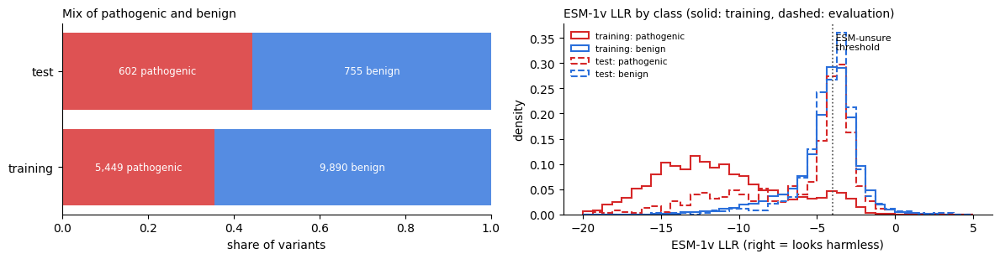

In [19]:
# 16b: the training variants and the test (or rehearsal) variants
if FINAL_RUN:
    test_recs = torch.load(os.path.join(DATA_DIR, "test.pt"), weights_only=True)
    fit_tab = lab                                                     # 14h: training + validation genes
    eval_tab, _ = add_variant_features(labelled_variants({g: r for r in test_recs for g in r["genes"]}))
else:
    val_genes = {g for r in probe_val for g in r["genes"]}
    fit_tab, eval_tab = lab[~lab.gene.isin(val_genes)], lab[lab.gene.isin(val_genes)].reset_index(drop=True)
assert not set(fit_tab.gene) & set(eval_tab.gene), "a gene is on both sides"
assert not set(fit_tab.cluster) & set(eval_tab.cluster), "a cluster is on both sides"

y_eval = eval_tab.benign.to_numpy()
UNSURE_LLR = fit_tab.loc[fit_tab.benign, "esm_llr"].median()        # threshold from TRAINING variants only
unsure_eval = (eval_tab.esm_llr > UNSURE_LLR).to_numpy()
n_each = eval_tab.groupby("gene").benign.agg(["sum", "size"])
genes_both = int(((n_each["sum"] >= 3) & (n_each["size"] - n_each["sum"] >= 3)).sum())
side = {"training": fit_tab, "test" if FINAL_RUN else "rehearsal (validation)": eval_tab}
print(pd.DataFrame({name: {"variants": len(t), "pathogenic": int((~t.benign).sum()), "benign": int(t.benign.sum()),
                           "genes": t.gene.nunique(), "clusters": t.cluster.nunique(),
                           "share ESM-unsure": float((t.esm_llr > UNSURE_LLR).mean())} for name, t in side.items()}).round(3).to_string())
print(f"genes with >= 3 of each class (for within-gene scores): {genes_both}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for k, (name, t) in enumerate(side.items()):
    share_p = (~t.benign).mean()
    axes[0].barh(k, share_p, color="#d62728", alpha=0.8)
    axes[0].barh(k, 1 - share_p, left=share_p, color="#2a6fdb", alpha=0.8)
    axes[0].text(share_p / 2, k, f"{(~t.benign).sum():,} pathogenic", ha="center", va="center", color="white", fontsize=8.5)
    axes[0].text(share_p + (1 - share_p) / 2, k, f"{t.benign.sum():,} benign", ha="center", va="center", color="white", fontsize=8.5)
    for b, c in [(False, "#d62728"), (True, "#2a6fdb")]:
        axes[1].hist(t.esm_llr[t.benign == b], bins=40, range=(-20, 5), density=True, histtype="step", lw=1.5, color=c,
                     ls="-" if k == 0 else "--", label=f"{name}: {'benign' if b else 'pathogenic'}")
axes[0].set_yticks(range(len(side)), list(side)); axes[0].set_xlim(0, 1); axes[0].set_xlabel("share of variants")
axes[0].set_title("Mix of pathogenic and benign", loc="left", fontsize=10)
axes[1].axvline(UNSURE_LLR, color="0.3", ls=":", lw=1.2)
axes[1].text(UNSURE_LLR, axes[1].get_ylim()[1] * 0.95, " ESM-unsure\n threshold", fontsize=8, va="top")
axes[1].set_xlabel("ESM-1v LLR (right = looks harmless)"); axes[1].set_ylabel("density")
axes[1].set_title("ESM-1v LLR by class (solid: training, dashed: evaluation)", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=7.5, loc="upper left")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 16c. Fit the models, score the test variants

Each model is fitted **once** on all the training variants. No cross-validation is needed here, because the test variants are a separate set. The fitted model then gives every test variant a probability of being benign. The two single scores need no fitting. All predictions are saved to `predictions.parquet` in the results folder, one row per test variant.

  logistic: all features                   fitted on 15,339 variants (0.1 s)
  logistic: ESM LLR + tolerance            fitted on 15,339 variants (0.0 s)
  gradient-boosted trees: all features     fitted on 15,339 variants (2.0 s)


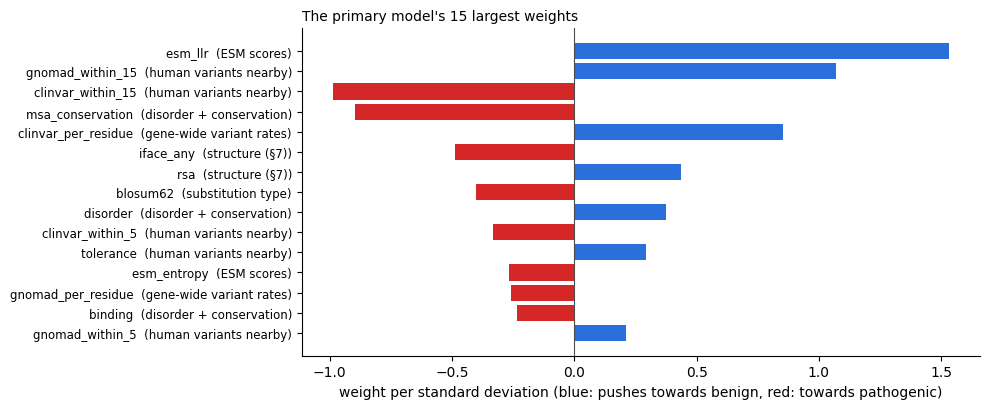

In [20]:
# 16c: fit each model on the training variants, score the evaluation variants
pred_eval = pd.DataFrame({name: eval_tab[col].to_numpy(float) for name, col in SINGLE_SCORES.items()})
fitted = {}
for name, (make, cols) in MODELS.items():
    t0 = time.time()
    fitted[name] = make().fit(fit_tab[cols].to_numpy(), fit_tab.benign.to_numpy())
    pred_eval[name] = fitted[name].predict_proba(eval_tab[cols].to_numpy())[:, 1]          # P(benign)
    print(f"  {name:40s} fitted on {len(fit_tab):,} variants ({time.time() - t0:.1f} s)")
pd.concat([eval_tab[["id", "gene", "position", "protein_consequence", "clinsig_group", "stars"]].reset_index(drop=True),
           pred_eval], axis=1).to_parquet(os.path.join(TEST_DIR, "predictions.parquet"))

# which features the primary model leans on: standardised weights (positive = pushes towards benign)
names = fitted[PRIMARY][:-1].get_feature_names_out()                 # 'x12' = column 12; 'missingindicator_x12' = was it missing
coef = pd.Series(fitted[PRIMARY][-1].coef_[0], index=names)
weights = pd.Series({ALL_VAR_FEATURES[int(n[1:])]: w for n, w in coef.items() if n.startswith("x")})
group_of = {c: g for g, cols in VARIANT_GROUPS.items() for c in cols}
top = weights.reindex(weights.abs().sort_values(ascending=False).index[:15])
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(range(len(top))[::-1], top, color=["#2a6fdb" if v > 0 else "#d62728" for v in top])
ax.set_yticks(range(len(top))[::-1], [f"{c}  ({group_of[c]})" for c in top.index], fontsize=8.5)
ax.axvline(0, color="0.3", lw=0.8)
ax.set_xlabel("weight per standard deviation (blue: pushes towards benign, red: towards pathogenic)")
ax.set_title("The primary model's 15 largest weights", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 16d. The scores

The same three scores as in 14h, now on the test variants: AUROC on all variants (with its 95% range from a gene bootstrap), mean AUROC within genes, and AUROC where ESM is unsure. The dashed line marks ESM-1v. Compare with 14h's cross-validated numbers. Somewhat lower scores are normal; much lower would mean 14h was optimistic.

                                      AUROC     lo     hi  within-gene AUROC  AUROC where ESM is unsure
ESM-1v LLR                            0.620  0.506  0.915              0.749                      0.545
tolerance (own residue hidden)        0.828  0.747  0.855              0.754                      0.839
logistic: all features                0.890  0.822  0.975              0.904                      0.879
logistic: ESM LLR + tolerance         0.826  0.778  0.940              0.831                      0.833
gradient-boosted trees: all features  0.860  0.770  0.978              0.931                      0.840

for comparison, 14h cross-validation (training + validation genes):
                                      AUROC  within-gene AUROC  AUROC where ESM is unsure
ESM-1v LLR                            0.906              0.885                      0.532
tolerance (own residue hidden)        0.837              0.728                      0.747
logistic: all features               

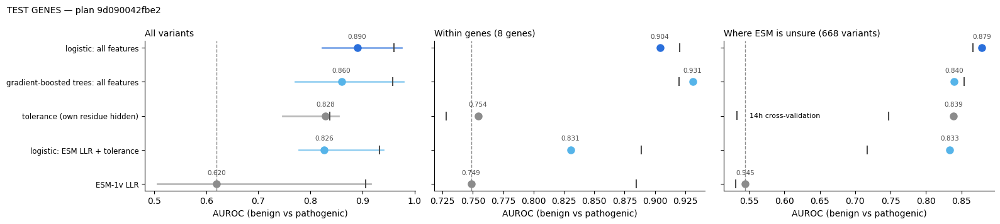

In [21]:
# 16d: the three AUROCs for every model on the evaluation variants
genes_eval = eval_tab.gene.to_numpy()


def per_gene_auroc(score, min_each=3):
    '''AUROC inside each gene with >= min_each variants of both classes.'''
    s = np.asarray(score, float)
    rows = pd.Series(np.arange(len(s))).groupby(genes_eval).indices
    return pd.Series({g: roc_auc_score(y_eval[i], s[i]) for g, i in rows.items()
                      if min_each <= y_eval[i].sum() <= len(i) - min_each})


def scores_of(score):
    s = np.asarray(score, float)
    auc, lo, hi = auroc_ci(y_eval, s, genes_eval)
    return {"AUROC": auc, "lo": lo, "hi": hi, "within-gene AUROC": per_gene_auroc(s).mean(),
            "AUROC where ESM is unsure": roc_auc_score(y_eval[unsure_eval], s[unsure_eval])}


test_table = pd.DataFrame({name: scores_of(pred_eval[name]) for name in pred_eval}).T
cv_14h = variant_table.reindex(test_table.index)[["AUROC", "within-gene AUROC", "AUROC where ESM is unsure"]]
print(test_table.round(3).to_string())
print("\nfor comparison, 14h cross-validation (training + validation genes):")
print(cv_14h.round(3).to_string())

vt = test_table.sort_values("AUROC")
colour = lambda n: "0.55" if n in SINGLE_SCORES else "#2a6fdb" if n == PRIMARY else "#56B4E9"
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, col, title in zip(axes, ["AUROC", "within-gene AUROC", "AUROC where ESM is unsure"],
                          ["All variants", f"Within genes ({len(per_gene_auroc(pred_eval[PRIMARY]))} genes)",
                           f"Where ESM is unsure ({unsure_eval.sum():,} variants)"]):
    for k, (name, r) in enumerate(vt.iterrows()):
        if col == "AUROC":
            ax.plot([r.lo, r.hi], [k, k], color=colour(name), lw=2, alpha=0.6)
        ax.plot(r[col], k, "o", color=colour(name), ms=8)
        ax.plot(cv_14h.loc[name, col], k, "|", color="0.3", ms=10, mew=1.5)
        ax.text(r[col], k + 0.28, f"{r[col]:.3f}", ha="center", fontsize=7.5, color="0.3")
    ax.axvline(vt.loc["ESM-1v LLR", col], color="0.55", ls="--", lw=1)
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel("AUROC (benign vs pathogenic)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(vt)), vt.index, fontsize=8.5)
axes[2].plot([], [], "|", color="0.3", ms=10, mew=1.5, label="14h cross-validation")
axes[2].legend(frameon=False, fontsize=8, loc="center left")
fig.suptitle(("TEST GENES" if FINAL_RUN else "REHEARSAL (validation genes)") + f" — plan {plan_id}", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

### 16e. The verdict

Each pre-registered question compares two scores on the **same** test variants. A **paired bootstrap** resamples whole test genes 1,000 times and recomputes the *difference* each time; the middle 95% of those differences is the range. A question passes when the whole range is above 0. Within genes, the difference is computed gene by gene, and the genes are resampled.

In the final run, this cell also saves `results.json`, the official result, stamped with the plan's fingerprint and the date.

TEST GENES, plan 9d090042fbe2
  PASS  Q1: primary beats ESM-1v on all variants         +0.270  (95% range +0.048 to +0.447)
  not shown  Q2: primary beats ESM-1v within genes            +0.156  (95% range -0.001 to +0.321)
  PASS  Q3: primary beats ESM-1v where ESM is unsure     +0.335  (95% range +0.182 to +0.474)
  PASS  Q4: human variant data adds to ESM               +0.206  (95% range +0.021 to +0.299)
official result saved to /Users/awlehr/LehrPDI/figures/results/tolerance_model/final_test/results.json


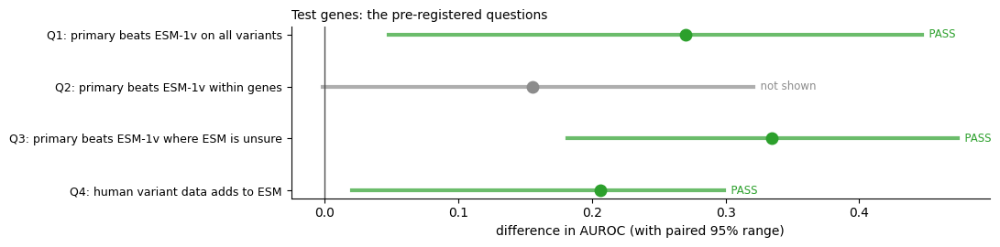

In [22]:
# 16e: the pre-registered questions, answered with paired gene-bootstrap ranges
def difference(a, b, subset):
    '''AUROC(a) - AUROC(b) on the evaluation variants, with a paired 95% range from resampling whole genes.'''
    sa, sb = pred_eval[a].to_numpy(), pred_eval[b].to_numpy()
    if subset == "within genes":
        d = per_gene_auroc(sa) - per_gene_auroc(sb)
        return d.mean(), *gene_bootstrap(lambda rows: d.to_numpy()[rows].mean(), d.index)
    keep = unsure_eval if subset == "ESM unsure" else np.ones(len(sa), bool)
    y, g, sa, sb = y_eval[keep], genes_eval[keep], sa[keep], sb[keep]
    stat = lambda rows: (roc_auc_score(y[rows], sa[rows]) - roc_auc_score(y[rows], sb[rows])
                         if len(set(y[rows])) == 2 else np.nan)
    return roc_auc_score(y, sa) - roc_auc_score(y, sb), *gene_bootstrap(stat, g)


verdict = pd.DataFrame({q: dict(zip(["difference", "lo", "hi"], difference(a, b, subset)))
                        for q, (a, b, subset) in QUESTIONS.items()}).T
verdict["passes"] = verdict.lo > 0
print(("TEST GENES" if FINAL_RUN else "REHEARSAL (validation genes; not the test)") + f", plan {plan_id}")
for q, r in verdict.iterrows():
    print(f"  {'PASS' if r.passes else 'not shown'}  {q:48s} {r.difference:+.3f}  (95% range {r.lo:+.3f} to {r.hi:+.3f})")

if FINAL_RUN and not os.path.exists(results_file):                      # first run only: never overwrite the official result
    json.dump({"plan_id": plan_id, "run": time.strftime("%Y-%m-%d %H:%M"),
               "variants": {"pathogenic": int((~y_eval).sum()), "benign": int(y_eval.sum()),
                            "genes": int(eval_tab.gene.nunique())},
               "scores": test_table.round(4).to_dict(orient="index"),
               "questions": verdict.round(4).to_dict(orient="index")},
              open(results_file, "w"), indent=1, default=str)
    print(f"official result saved to {results_file}")
elif FINAL_RUN:
    print(f"official result from {json.load(open(results_file))['run']} kept unchanged in {results_file}")

fig, ax = plt.subplots(figsize=(11, 2.8))
yy = np.arange(len(verdict))[::-1]
for k, (q, r) in zip(yy, verdict.iterrows()):
    c = "#2ca02c" if r.passes else "0.55"
    ax.plot([r.lo, r.hi], [k, k], color=c, lw=3, alpha=0.7)
    ax.plot(r.difference, k, "o", color=c, ms=9)
    ax.text(r.hi, k, f"  {'PASS' if r.passes else 'not shown'}", va="center", fontsize=8.5, color=c)
ax.axvline(0, color="0.3", lw=1)
ax.set_yticks(yy, verdict.index, fontsize=9)
ax.set_xlabel("difference in AUROC (with paired 95% range)")
ax.set_title(("Test genes" if FINAL_RUN else "Rehearsal on validation genes") + ": the pre-registered questions",
             loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 16f. A closer look

Three views of the primary model on the test variants:
- **ROC curves:** the whole trade-off between catching pathogenic variants and mislabelling benign ones, for all variants (solid) and where ESM is unsure (dotted).
- **Calibration:** the model outputs a *probability* of being benign. Group the test variants by that probability and check how many really are benign. Points on the diagonal mean an output of 0.8 really is right about 80% of the time. The probabilities reflect the training mix of pathogenic and benign, so a test set with a different mix shifts them, even if the ranking (AUROC) is good. The **Brier score** (mean squared error of the probabilities; lower is better) summarises calibration and sharpness together.
- **Gene by gene:** each dot is a test gene with ≥ 3 variants of each class, placed by its AUROC with ESM alone (x) and with the primary model (y). Dots above the diagonal are genes where the model separates pathogenic from benign better than ESM.

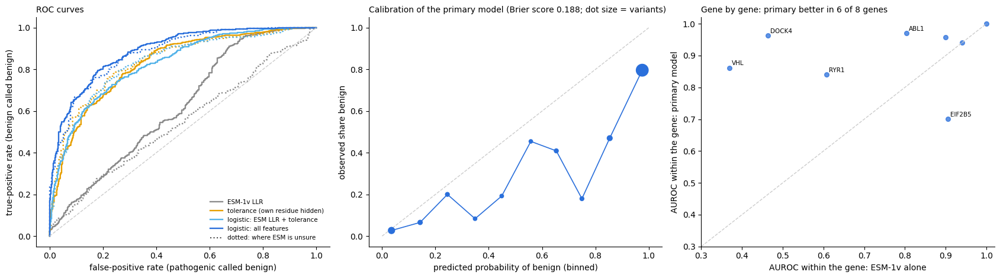

In [23]:
# 16f: ROC curves, calibration, and gene by gene
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
for name, c in [("ESM-1v LLR", "0.55"), ("tolerance (own residue hidden)", "#E69F00"),
                ("logistic: ESM LLR + tolerance", "#56B4E9"), (PRIMARY, "#2a6fdb")]:
    for subset, ls in [(np.ones(len(y_eval), bool), "-"), (unsure_eval, ":")]:
        fpr, tpr, _ = roc_curve(y_eval[subset], pred_eval[name].to_numpy()[subset])
        ax.plot(fpr, tpr, color=c, ls=ls, lw=1.7, label=name if ls == "-" else None)
ax.plot([0, 1], [0, 1], color="0.8", ls="--", lw=1)
ax.plot([], [], color="0.3", ls=":", label="dotted: where ESM is unsure")
ax.set_xlabel("false-positive rate (pathogenic called benign)"); ax.set_ylabel("true-positive rate (benign called benign)")
ax.set_title("ROC curves", loc="left", fontsize=10); ax.legend(frameon=False, fontsize=7.5, loc="lower right")

ax = axes[1]
p = pred_eval[PRIMARY].to_numpy()
bins = np.linspace(0, 1, 11); which = np.clip(np.digitize(p, bins) - 1, 0, 9)
centre = [p[which == b].mean() for b in range(10) if (which == b).sum() >= 10]
observed = [y_eval[which == b].mean() for b in range(10) if (which == b).sum() >= 10]
size = [(which == b).sum() for b in range(10) if (which == b).sum() >= 10]
ax.plot([0, 1], [0, 1], color="0.8", ls="--", lw=1)
ax.plot(centre, observed, "-", color="#2a6fdb", lw=1.2)
ax.scatter(centre, observed, s=np.array(size) / max(size) * 200 + 15, color="#2a6fdb", zorder=3)
ax.set_xlabel("predicted probability of benign (binned)"); ax.set_ylabel("observed share benign")
ax.set_title(f"Calibration of the primary model (Brier score {brier_score_loss(y_eval, p):.3f}; "
             f"dot size = variants)", loc="left", fontsize=10)

ax = axes[2]
per_gene = pd.DataFrame({"ESM": per_gene_auroc(pred_eval["ESM-1v LLR"]), "primary": per_gene_auroc(p)})
ax.plot([0, 1], [0, 1], color="0.8", ls="--", lw=1)
ax.scatter(per_gene.ESM, per_gene.primary, s=30, color="#2a6fdb", alpha=0.75)
for g, r in per_gene.iterrows():
    if abs(r.primary - r.ESM) > 0.15:
        ax.annotate(g, (r.ESM, r.primary), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
better = (per_gene.primary > per_gene.ESM).sum()
ax.set_xlim(min(0.3, per_gene.min().min() - 0.05), 1.02); ax.set_ylim(ax.get_xlim())
ax.set_xlabel("AUROC within the gene: ESM-1v alone"); ax.set_ylabel("AUROC within the gene: primary model")
ax.set_title(f"Gene by gene: primary better in {better} of {len(per_gene)} genes", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

### 16g. The result, explained

**The final test ran once, on 2026-10-21 at 17:52, with plan `9d090042fbe2`** (the plan was saved at 17:50 and wasn't changed between rehearsal and test). The test set: 1,357 labelled variants (602 pathogenic, 755 benign) in 85 test genes from 55 clusters, none of which had been used for anything before.

| question | difference in AUROC | 95% range | result |
|---|---|---|---|
| Q1: primary beats ESM-1v on all variants | **+0.270** (0.890 vs 0.620) | +0.048 to +0.447 | **PASS** |
| Q2: primary beats ESM-1v within genes | +0.156 (0.904 vs 0.749) | −0.001 to +0.321 | not shown (8 genes) |
| Q3: primary beats ESM-1v where ESM is unsure | **+0.335** (0.879 vs 0.545) | +0.182 to +0.474 | **PASS** |
| Q4: human variant data adds to ESM | **+0.206** (0.826 vs 0.620) | +0.021 to +0.299 | **PASS** |

| score on the test genes | ESM-1v | tolerance | ESM + tolerance | **primary** (all features) | trees (all features) |
|---|---|---|---|---|---|
| AUROC, all variants | 0.620 | 0.828 | 0.826 | **0.890** | 0.860 |
| AUROC within genes (8 genes) | 0.749 | 0.754 | 0.831 | **0.904** | 0.931 |
| AUROC where ESM is unsure (668 variants) | 0.545 | 0.839 | 0.833 | **0.879** | 0.840 |
| *14h cross-validation, for comparison* | *0.906* | *0.837* | *0.933* | *0.961* | *0.958* |

The pre-registered verdict is final; the cells below explain it. They draw schematics of **what data went into the model**, **how it was trained** and **how the test was kept honest**, then look at **how accurate the labels and predictions are**, and **why ESM-1v scored so much lower here than in 14h**. Everything from "how accurate" onwards is **descriptive and post hoc**: it was examined *after* seeing the result, so it explains the verdict but doesn't change it.

The cells read the official files in `results/tolerance_model/final_test/` (`plan.json`, `results.json`, `predictions.parquet`), so they show the official numbers even after a kernel restart (§1 and the §14 reload cell are enough).

#### What went into the model

One row per variant; the answer to learn is its ClinVar classification. Everything else is evidence the model can use, from five kinds of source:

| source | what it measures | features |
|---|---|---|
| **ClinVar classifications** (≥ 1 review star) | the **label**: pathogenic / likely pathogenic vs benign / likely benign | the thing to predict, never an input |
| **gnomAD v4** (healthy population) + **all ClinVar missense** | *human* constraint: how many variants are tolerated nearby, and where disease reports cluster | tolerance (`convolve_v4`), the gnomAD / ClinVar density tracks, counts within ±5 / ±15 residues, gene-wide rates |
| **ESM-1v** (650 M-parameter protein language model, frozen) | *evolutionary* constraint: how surprising this amino acid change is, given millions of related proteins | LLR of the substitution; the residue's wild-type log-probability, entropy, mean LLR |
| **substitution chemistry** | how different the new amino acid is | BLOSUM62, Grantham distance, change in hydrophobicity |
| **structure** (PDB first, AlphaFold otherwise, §7) | where the residue sits | relative solvent accessibility, pLDDT, buried surface, binding interfaces |
| **annotations** (InterPro, UniProt, MobiDB, ELM, §8) + **AIUPred** | what the residue does | domains, motifs, PTMs, sites, disorder, conservation |

**Hiding each variant's own residue.** Every human-variant feature was computed from tracks rebuilt *without any variant at that residue* (14h). Otherwise a pathogenic variant would partly vouch for itself, or for a second pathogenic substitution at the same position.

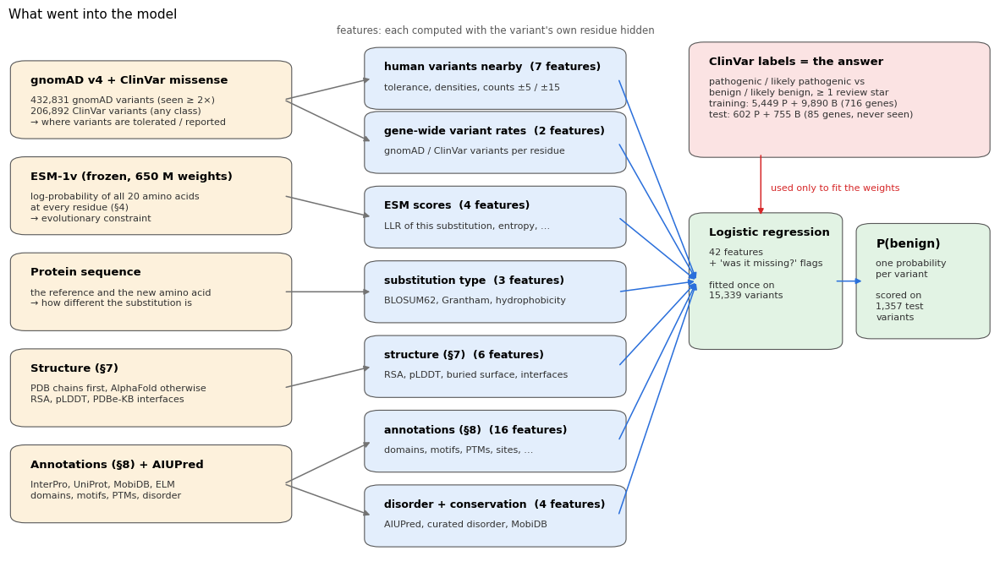

In [24]:
# schematic: the data that went into the model, with the real counts
from matplotlib.patches import FancyBboxPatch

official = os.path.join(OUT, "final_test")
plan = json.load(open(os.path.join(official, "plan.json")))
result = json.load(open(os.path.join(official, "results.json")))
test_pred = pd.read_parquet(os.path.join(official, "predictions.parquet"))
test_pred["benign"] = test_pred.clinsig_group.eq("benign")
train_genes = set(psd_seq_df.gene[psd_seq_df.split.isin(["train", "val"])])
train_lab = variant_df[(variant_df.database == "ClinVar") & variant_df.clinsig_group.isin(["pathogenic", "benign"])
                       & (variant_df.stars >= 1) & variant_df.gene.isin(train_genes)].drop_duplicates("id")
n_feat = {g: len(c) for g, c in VARIANT_GROUPS.items()}
n_gnomad = int((tolerance_variants.database == "GnomAD").sum()); n_clinvar = int((tolerance_variants.database == "ClinVar").sum())


def box(ax, x, y, w, h, title, body, colour, title_size=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.008,rounding_size=0.015", fc=colour, ec="0.35", lw=0.8))
    ax.text(x + 0.012, y + h - 0.018, title, fontsize=title_size, weight="bold", va="top")
    ax.text(x + 0.012, y + h - 0.058, body, fontsize=8, va="top", color="0.2", linespacing=1.35)


def arrow(ax, x0, y0, x1, y1, colour="0.45"):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.1, shrinkA=2, shrinkB=2))


fig, ax = plt.subplots(figsize=(15, 8.2)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
SRC, FEAT, MOD = "#fdf1dc", "#e3eefc", "#e2f3e4"
sources = [   # y, title, body
    (0.86, "gnomAD v4 + ClinVar missense", f"{n_gnomad:,} gnomAD variants (seen ≥ 2×)\n{n_clinvar:,} ClinVar variants (any class)\n→ where variants are tolerated / reported"),
    (0.68, "ESM-1v (frozen, 650 M weights)", "log-probability of all 20 amino acids\nat every residue (§4)\n→ evolutionary constraint"),
    (0.50, "Protein sequence", "the reference and the new amino acid\n→ how different the substitution is"),
    (0.32, "Structure (§7)", "PDB chains first, AlphaFold otherwise\nRSA, pLDDT, PDBe-KB interfaces"),
    (0.14, "Annotations (§8) + AIUPred", "InterPro, UniProt, MobiDB, ELM\ndomains, motifs, PTMs, disorder"),
]
for y, t, b in sources:
    box(ax, 0.01, y - 0.065, 0.27, 0.13, t, b, SRC)
groups = [   # y, group name, example features, which source rows feed it
    (0.90, "human variants nearby", "tolerance, densities, counts ±5 / ±15", [0]),
    (0.78, "gene-wide variant rates", "gnomAD / ClinVar variants per residue", [0]),
    (0.64, "ESM scores", "LLR of this substitution, entropy, …", [1]),
    (0.50, "substitution type", "BLOSUM62, Grantham, hydrophobicity", [2]),
    (0.36, "structure (§7)", "RSA, pLDDT, buried surface, interfaces", [3]),
    (0.22, "annotations (§8)", "domains, motifs, PTMs, sites, …", [4]),
    (0.08, "disorder + conservation", "AIUPred, curated disorder, MobiDB", [4]),
]
for y, g, ex, feeds in groups:
    box(ax, 0.37, y - 0.05, 0.25, 0.10, f"{g}  ({n_feat[g]} features)", ex, FEAT, 9)
    for s in feeds:
        arrow(ax, 0.28, sources[s][0], 0.37, y)
    arrow(ax, 0.62, y, 0.70, 0.52, "#2a6fdb")
box(ax, 0.70, 0.40, 0.14, 0.24, "Logistic regression", f"{sum(n_feat.values())} features\n+ 'was it missing?' flags\n\nfitted once on\n{len(train_lab):,} variants", MOD, 9.5)
arrow(ax, 0.84, 0.52, 0.87, 0.52, "#2a6fdb")
box(ax, 0.87, 0.42, 0.12, 0.20, "P(benign)", f"one probability\nper variant\n\nscored on\n{len(test_pred):,} test\nvariants", MOD, 10)
box(ax, 0.70, 0.76, 0.29, 0.20, "ClinVar labels = the answer",
    f"pathogenic / likely pathogenic vs\nbenign / likely benign, ≥ 1 review star\n"
    f"training: {(train_lab.clinsig_group == 'pathogenic').sum():,} P + {(train_lab.clinsig_group == 'benign').sum():,} B "
    f"({train_lab.gene.nunique()} genes)\ntest: {(~test_pred.benign).sum():,} P + {test_pred.benign.sum():,} B "
    f"({test_pred.gene.nunique()} genes, never seen)", "#fbe3e3")
arrow(ax, 0.765, 0.76, 0.765, 0.64, "#d62728")
ax.text(0.775, 0.69, "used only to fit the weights", fontsize=8, color="#d62728")
ax.text(0.495, 0.985, "features: each computed with the variant's own residue hidden", ha="center", fontsize=8.5, color="0.35")
ax.set_title("What went into the model", loc="left", fontsize=11)
plt.show()

#### How the model was trained

The primary model is a **logistic regression**, the simplest model that turns many numbers into one probability:
1. **Prepare the features.** A missing value (for example, no structure for that residue) is filled with the median, and a "was it missing?" flag is added, so the model can learn whether missingness itself carries information. Every feature is then **standardised**: shifted and scaled to mean 0 and spread 1, so weights are comparable.
2. **Weighted sum.** Each feature is multiplied by its own weight and the products are added up: one number *z* per variant. Positive weights push towards benign, negative towards pathogenic (16c shows the largest).
3. **S-curve.** *z* goes through the logistic function, 1 / (1 + e^(−z)), which squeezes any number into a probability between 0 and 1.
4. **Fitting** means choosing the weights that make the 15,339 training labels as likely as possible (**maximum likelihood**). A small penalty on large weights (L2, the scikit-learn default) keeps the model from leaning too hard on any one feature. The fit takes a fraction of a second and happened **once**, before the test genes were scored.

The right-hand plot puts the real test variants on that S-curve: each variant's *z*, coloured by its true label. A good model puts pathogenic variants on the left (low *z*) and benign on the right.

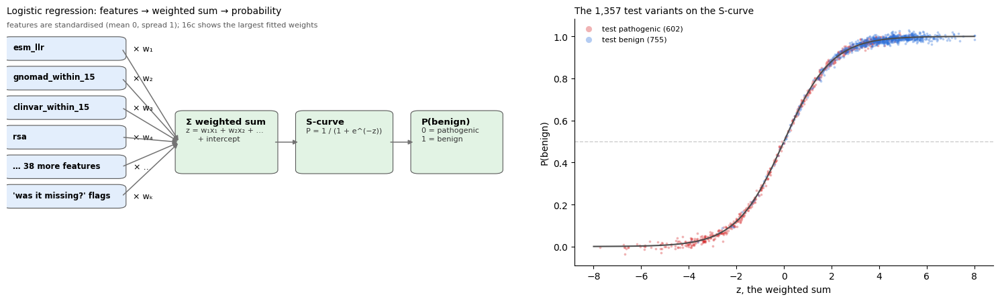

In [25]:
# schematic: logistic regression in three steps, and the real test variants on its S-curve
P = plan["primary model"]
p_test = test_pred[P].clip(1e-6, 1 - 1e-6).to_numpy()
z = np.log(p_test / (1 - p_test))                                     # back from probability to the weighted sum

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]; ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
feats = [("esm_llr", "w₁"), ("gnomad_within_15", "w₂"), ("clinvar_within_15", "w₃"), ("rsa", "w₄"),
         (f"… {sum(n_feat.values()) - 4} more features", "…"), ("'was it missing?' flags", "wₖ")]
for k, (f, w) in enumerate(feats):
    y = 0.88 - k * 0.12
    box(ax, 0.0, y - 0.04, 0.22, 0.08, f, "", FEAT, 8.5)
    ax.text(0.26, y, f"× {w}", fontsize=9, va="center", ha="center")
    arrow(ax, 0.22, y, 0.33, 0.50)
box(ax, 0.33, 0.38, 0.18, 0.24, "Σ weighted sum", "z = w₁x₁ + w₂x₂ + …\n     + intercept", MOD, 9.5)
arrow(ax, 0.51, 0.50, 0.56, 0.50)
box(ax, 0.56, 0.38, 0.17, 0.24, "S-curve", "P = 1 / (1 + e^(−z))", MOD, 9.5)
arrow(ax, 0.73, 0.50, 0.78, 0.50)
box(ax, 0.78, 0.38, 0.16, 0.24, "P(benign)", "0 = pathogenic\n1 = benign", MOD, 9.5)
ax.text(0.0, 0.99, "features are standardised (mean 0, spread 1); 16c shows the largest fitted weights",
        fontsize=8, color="0.35", va="top")
ax.set_title("Logistic regression: features → weighted sum → probability", loc="left", fontsize=10)

ax = axes[1]
zz = np.linspace(-8, 8, 200)
ax.plot(zz, 1 / (1 + np.exp(-zz)), color="0.3", lw=1.5)
rng_j = np.random.default_rng(0)
for is_b, c, lab_ in [(False, "#d62728", "pathogenic"), (True, "#2a6fdb", "benign")]:
    sel = test_pred.benign.to_numpy() == is_b
    ax.scatter(np.clip(z[sel], -8, 8), 1 / (1 + np.exp(-np.clip(z[sel], -8, 8))) + rng_j.normal(0, 0.012, sel.sum()),
               s=7, alpha=0.35, color=c, linewidths=0, label=f"test {lab_} ({sel.sum()})")
ax.axhline(0.5, color="0.8", ls="--", lw=1)
ax.set_xlabel("z, the weighted sum"); ax.set_ylabel("P(benign)")
ax.set_title(f"The {len(test_pred):,} test variants on the S-curve", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, markerscale=2.5, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

#### How the test was kept honest

Four safeguards, in the order they were applied:
1. **Whole genes, whole families (§10).** Genes were grouped into clusters of homologs (shared sequence or PANTHER family), and whole clusters were dealt into training, validation and test. A test gene never has a close relative in training, so the model can't simply recognise a familiar protein.
2. **Every choice made without the test genes (§14).** Models, features and settings were compared by cross-validation *within* training + validation genes (14h), each fold holding out whole clusters.
3. **Plan first, one look (16a).** The model, the comparisons and the pass rule were saved with a fingerprint before any test variant was loaded. The test ran once, with that plan.
4. **Uncertainty from whole genes (16d–16e).** Variants in the same gene aren't independent, so the 95% ranges come from resampling *genes*, 1,000 times. Each question compares two scores on the same resampled genes (**paired**), so the range reflects only the difference.

Inside every gene, a fifth safeguard: **residue hiding**. The residues with labelled variants are dealt into 5 groups, and the features of a variant in group *k* come from tracks rebuilt without any variant at group-*k* residues.

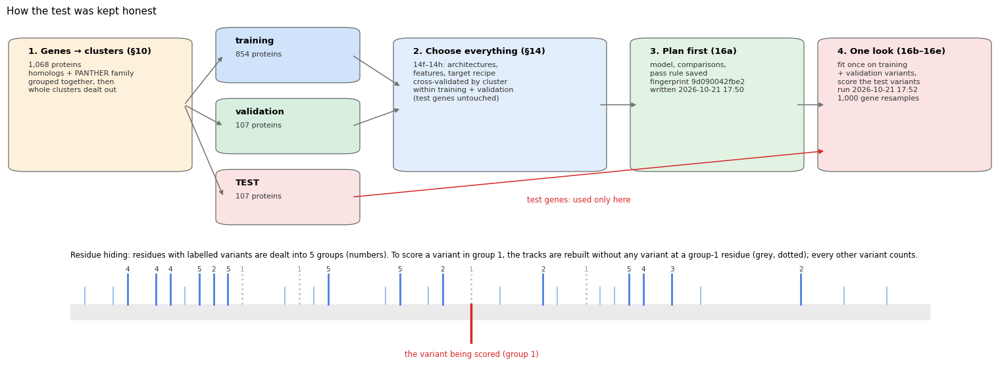

In [ ]:
# schematic: the split, the order of events, and residue hiding
counts = {s: info["counts"][s]["proteins"] for s in ["train", "val", "test"]}
fig = plt.figure(figsize=(15, 5.4))
ax = fig.add_axes([0, 0.40, 1, 0.60]); ax.set_xlim(0, 1); ax.set_ylim(0.37, 0.97); ax.axis("off")
box(ax, 0.01, 0.55, 0.17, 0.36, "1. Genes → clusters (§10)", f"{sum(counts.values()):,} proteins\nhomologs + PANTHER family\ngrouped together, then\nwhole clusters dealt out", SRC)
for k, (s, c, colr) in enumerate([("train", counts["train"], "#cfe3fa"), ("val", counts["val"], "#d8efe0"), ("test", counts["test"], "#fbe3e3")]):
    box(ax, 0.22, 0.80 - k * 0.20, 0.13, 0.14, {"train": "training", "val": "validation", "test": "TEST"}[s], f"{c} proteins", colr)
    arrow(ax, 0.18, 0.73, 0.22, 0.87 - k * 0.20)
box(ax, 0.40, 0.55, 0.20, 0.36, "2. Choose everything (§14)", "14f–14h: architectures,\nfeatures, target recipe\ncross-validated by cluster\nwithin training + validation\n(test genes untouched)", FEAT)
arrow(ax, 0.35, 0.87, 0.40, 0.78); arrow(ax, 0.35, 0.67, 0.40, 0.72)
box(ax, 0.64, 0.55, 0.16, 0.36, "3. Plan first (16a)", f"model, comparisons,\npass rule saved\nfingerprint {plan['plan_id']}\nwritten {plan['written']}", MOD)
arrow(ax, 0.60, 0.73, 0.64, 0.73)
box(ax, 0.83, 0.55, 0.16, 0.36, "4. One look (16b–16e)", f"fit once on training\n+ validation variants,\nscore the test variants\nrun {result['run']}\n1,000 gene resamples", "#fbe3e3")
arrow(ax, 0.80, 0.73, 0.83, 0.73)
arrow(ax, 0.35, 0.47 + 0.0, 0.83, 0.60, "#d62728")
ax.text(0.58, 0.455, "test genes: used only here", color="#d62728", fontsize=8.5, ha="center")
ax.set_title("How the test was kept honest", loc="left", fontsize=11)

# residue hiding, drawn on one stretch of a protein
ax2 = fig.add_axes([0.05, 0.02, 0.9, 0.34])
L_demo = 60; rng_h = np.random.default_rng(3)
labelled_pos = np.sort(rng_h.choice(np.arange(3, L_demo - 3), 18, replace=False))
group = rng_h.integers(0, 5, len(labelled_pos))
other_pos = np.sort(rng_h.choice(np.setdiff1d(np.arange(L_demo), labelled_pos), 14, replace=False))
target = labelled_pos[np.argmin(np.abs(labelled_pos - 30))]; tg = group[labelled_pos == target][0]
ax2.add_patch(plt.Rectangle((0, -0.15), L_demo, 0.3, color="0.92"))
for p_, g_ in zip(labelled_pos, group):
    hidden = g_ == tg
    ax2.plot([p_, p_], [0.15, 0.75], color="0.75" if hidden else "#4a7fe0", lw=2, ls=":" if hidden else "-")
    ax2.text(p_, 0.82, str(g_ + 1), ha="center", fontsize=7.5, color="0.6" if hidden else "0.2")
for p_ in other_pos:
    ax2.plot([p_, p_], [0.15, 0.5], color="#4a7fe0", lw=1.2, alpha=0.6)
ax2.plot([target, target], [-0.6, 0.15], color="#d62728", lw=2.5)
ax2.text(target, -0.75, f"the variant being scored (group {tg + 1})", ha="center", va="top", fontsize=8.5, color="#d62728")
ax2.text(0, 1.05, f"Residue hiding: residues with labelled variants are dealt into 5 groups (numbers). To score a variant in group {tg + 1}, "
         f"the tracks are rebuilt without any variant at a group-{tg + 1} residue (grey, dotted); every other variant counts.",
         fontsize=8.5, va="bottom")
ax2.set_xlim(-1, L_demo + 1); ax2.set_ylim(-1.1, 1.3); ax2.axis("off")
plt.show()

#### How accurate are the labels, and the predictions? *(descriptive, after the test)*

**The labels.** ClinVar classifications are submitted by laboratories, and their reliability varies. **Review stars** summarise it: ★ one submitter with stated criteria; ★★ several submitters, no conflict; ★★★ an expert panel. Only ≥ ★ variants with a clear pathogenic or benign call were used, and conflicting ones were excluded. Two things to know about the test labels:
- Most test labels are single-submitter (★), as in training.
- The ★★★ test labels come almost entirely from **one gene, RYR1**, where an expert panel classifies variants for malignant hyperthermia susceptibility.

**The test set's makeup.** Three genes, **RYR1** (315 variants, 82% pathogenic), **ABL1** (200, 91% benign) and **VHL** (190, 87% pathogenic), hold **52% of all test variants**. That happened by chance in the §10 split, but it means pooled scores largely reflect these three genes.

**The predictions as decisions.** AUROC measures *ranking*. A clinician needs a *decision*: call a variant benign when P(benign) ≥ 0.5. The confusion matrix shows how that decision fares, and the calibration plot shows whether the probabilities can be taken at face value, per gene group.

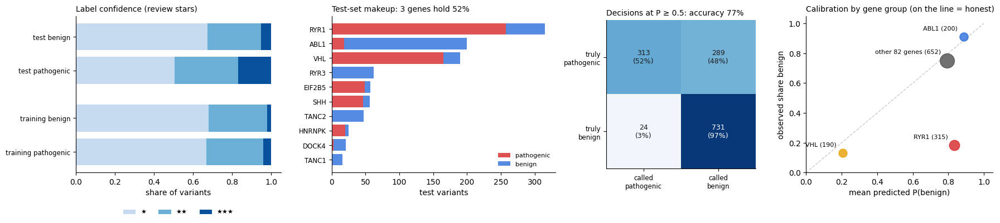

at P(benign) >= 0.5: accuracy 0.769 | benign called benign 0.97 | pathogenic called pathogenic 0.52 | Brier score 0.188 (14h rehearsal on validation genes: 0.040)
other 82 genes (652 variants): AUROC primary 0.963 vs ESM-1v 0.911


In [ ]:
# descriptive (post hoc): label confidence, test-set makeup, decisions at P >= 0.5, calibration by gene group
from sklearn.metrics import confusion_matrix, brier_score_loss

y_t = test_pred.benign.to_numpy(); p_t = test_pred[P].to_numpy()
big3 = ["RYR1", "ABL1", "VHL"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1.1, 1.2, 0.8, 1]})

ax = axes[0]                                                         # review stars by class, training vs test
for k, (name, t) in enumerate([("training", train_lab.assign(benign=train_lab.clinsig_group.eq("benign"))), ("test", test_pred)]):
    for j, b in enumerate([False, True]):
        share = t[t.benign == b].stars.value_counts(normalize=True).reindex([1, 2, 3], fill_value=0)
        left = 0
        for s, c in zip([1, 2, 3], ["#c6dbef", "#6baed6", "#08519c"]):
            ax.barh(k * 2.4 + j, share[s], left=left, color=c, label=f"{'★' * s}" if k == 0 and j == 0 else None)
            left += share[s]
ax.set_yticks([0, 1, 2.4, 3.4], ["training pathogenic", "training benign", "test pathogenic", "test benign"], fontsize=8.5)
ax.set_xlabel("share of variants"); ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Label confidence (review stars)", loc="left", fontsize=10)

ax = axes[1]                                                         # the 10 largest test genes
per = test_pred.groupby("gene").benign.agg(["size", "sum"]).sort_values("size", ascending=False).head(10)[::-1]
ax.barh(range(len(per)), per["size"] - per["sum"], color="#d62728", alpha=0.8, label="pathogenic")
ax.barh(range(len(per)), per["sum"], left=per["size"] - per["sum"], color="#2a6fdb", alpha=0.8, label="benign")
ax.set_yticks(range(len(per)), per.index, fontsize=8.5); ax.set_xlabel("test variants")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(f"Test-set makeup: 3 genes hold {test_pred.gene.isin(big3).mean():.0%}", loc="left", fontsize=10)

ax = axes[2]                                                         # confusion matrix at P(benign) >= 0.5
cm = confusion_matrix(y_t, p_t >= 0.5)                                # rows: true (pathogenic, benign); cols: called
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center", fontsize=9,
                color="white" if cm[i, j] / cm[i].sum() > 0.6 else "0.1")
ax.set_xticks([0, 1], ["called\npathogenic", "called\nbenign"], fontsize=8.5); ax.set_yticks([0, 1], ["truly\npathogenic", "truly\nbenign"], fontsize=8.5)
ax.set_title(f"Decisions at P ≥ 0.5: accuracy {(cm[0, 0] + cm[1, 1]) / cm.sum():.0%}", loc="left", fontsize=10)

ax = axes[3]                                                         # calibration by gene group
groups_c = {**{g: test_pred.gene == g for g in big3}, "other 82 genes": ~test_pred.gene.isin(big3)}
ax.plot([0, 1], [0, 1], color="0.8", ls="--", lw=1)
for (name, m), c in zip(groups_c.items(), ["#d62728", "#2a6fdb", "#E69F00", "0.3"]):
    m = m.to_numpy()
    ax.scatter(p_t[m].mean(), y_t[m].mean(), s=m.sum() / 2 + 20, color=c, alpha=0.8, zorder=3)
    ax.annotate(f"{name} ({m.sum()})", (p_t[m].mean(), y_t[m].mean()), fontsize=8, xytext=(-8, 9), textcoords="offset points", ha="right")
ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05)
ax.set_xlabel("mean predicted P(benign)"); ax.set_ylabel("observed share benign")
ax.set_title("Calibration by gene group (on the line = honest)", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_t, p_t >= 0.5).ravel()
print(f"at P(benign) >= 0.5: accuracy {(tp + tn) / len(y_t):.3f} | benign called benign {tp / (tp + fn):.2f} | "
      f"pathogenic called pathogenic {tn / (tn + fp):.2f} | Brier score {brier_score_loss(y_t, p_t):.3f} "
      f"(14h rehearsal on validation genes: 0.040)")
rest = ~test_pred.gene.isin(big3)
print(f"other 82 genes ({rest.sum()} variants): AUROC primary {roc_auc_score(y_t[rest], p_t[rest]):.3f} vs "
      f"ESM-1v {roc_auc_score(y_t[rest], test_pred['ESM-1v LLR'][rest]):.3f}")

#### Why ESM-1v scored so much lower on the test genes *(descriptive, after the test)*

In 14h, ESM-1v reached 0.906 on all variants. On the test genes it reached 0.620, with a 95% range of 0.51–0.92. A range that wide means a few genes drive the number. The plot shows each score's distribution by class in the three large genes and in the other 82:
- **ESM-1v** gives many **RYR1** and **VHL** pathogenic variants *mild* scores, close to the benign variants of **ABL1**. Pooled across genes, ESM's scale doesn't line up: a "mild" LLR means pathogenic in RYR1 and benign in ABL1.
- **The primary model** uses gene-level and neighbourhood evidence (how many variants are tolerated or reported nearby), so it separates the classes better both within and across these genes. It isn't perfect: RYR1's pathogenic variants still get fairly high P(benign).
- **In the other 82 genes**, ESM-1v scores 0.911 and the primary model 0.963. That is the same gap as in 14h (0.906 vs 0.961): the model's advantage there is stable, while the extreme Q1 difference (+0.27) partly reflects this test set's makeup.

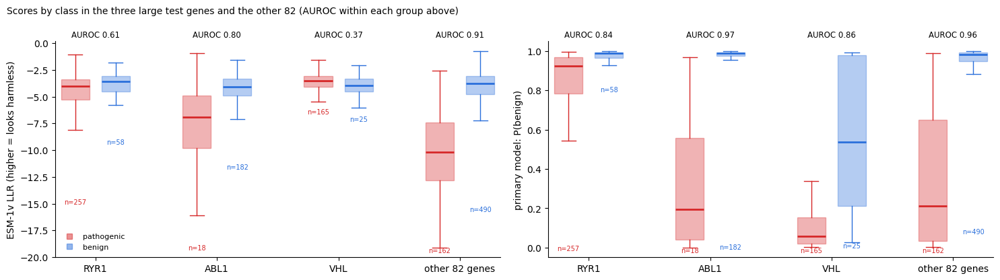

In [ ]:
# descriptive (post hoc): each score by class, in the three large test genes and the rest
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
groups_w = [*big3, "other 82 genes"]
for ax, col, label_ in [(axes[0], "ESM-1v LLR", "ESM-1v LLR (higher = looks harmless)"), (axes[1], P, "primary model: P(benign)")]:
    for k, gname in enumerate(groups_w):
        m = (test_pred.gene == gname) if gname in big3 else ~test_pred.gene.isin(big3)
        for j, (b, c) in enumerate([(False, "#d62728"), (True, "#2a6fdb")]):
            v = test_pred.loc[m & (test_pred.benign == b), col]
            if len(v):
                ax.boxplot(v, positions=[k * 3 + j], widths=0.7, showfliers=False, patch_artist=True,
                           boxprops=dict(facecolor=c, alpha=0.35, color=c), medianprops=dict(color=c, lw=2),
                           whiskerprops=dict(color=c), capprops=dict(color=c))
                ax.text(k * 3 + j, v.min(), f"n={len(v)}", ha="center", va="top", fontsize=7, color=c)
        within = roc_auc_score(test_pred.benign[m], test_pred[col][m]) if test_pred.benign[m].nunique() == 2 else np.nan
        ax.text(k * 3 + 0.5, 1.02, f"AUROC {within:.2f}", transform=ax.get_xaxis_transform(), ha="center", fontsize=8.5)
    ax.set_xticks([k * 3 + 0.5 for k in range(len(groups_w))], groups_w)
    ax.set_ylabel(label_); ax.spines[["top", "right"]].set_visible(False)
axes[0].plot([], [], "s", color="#d62728", alpha=0.5, label="pathogenic"); axes[0].plot([], [], "s", color="#2a6fdb", alpha=0.5, label="benign")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Scores by class in the three large test genes and the other 82 (AUROC within each group above)", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

#### Interpretation

**What the pre-registered test shows:**
1. **The model works on genes nobody chose.** On 85 untouched test genes it separates pathogenic from benign variants with AUROC 0.89, against 0.62 for ESM-1v alone (Q1, PASS).
2. **It is most useful where evolution is unsure.** Among the variants ESM-1v calls mild (half of the test set), ESM is at chance (0.545). The model reaches 0.879 (Q3, PASS, the clearest result). This is the situation the project was built for: variants that look harmless to evolution but sit in regions that human data mark as intolerant.
3. **Human variant data adds to evolution in new genes.** ESM + tolerance beats ESM alone (Q4, PASS). Tolerance alone (0.828) also beats ESM alone here. This is the core of the hypothesis.
4. **Within genes, the direction holds, but the test is too small to be sure.** Only 8 test genes have ≥ 3 variants of each class. The model is better in 5 of them, tied in 2 and worse in 1 (EIF2B5); the mean gain is +0.156, but the range just touches 0 (Q2, not shown). "Not shown" isn't "shown false": 14h's cross-validation over 155 genes found the same direction (0.920 vs 0.885).

**What the closer look adds (post hoc, so it explains rather than tests):**
- **The size of the Q1 gap partly reflects this particular test set.** Three genes hold half the test variants, and ESM-1v does badly in two of them (RYR1 and VHL) and across them. In the other 82 test genes the gap is 0.963 vs 0.911, the same as in 14h. A fair one-line summary is "about +0.05 AUROC over ESM-1v in typical genes, and much more in genes where ESM struggles".
- **The ranking is good, but the probabilities are not yet trustworthy for new genes.** At P(benign) ≥ 0.5, 97% of benign variants are called benign, but only 52% of pathogenic ones are called pathogenic (accuracy 77%; Brier 0.19 vs 0.04 on validation genes). Most of the miss is **RYR1**, where pathogenic variants get P(benign) ≈ 0.8. A plausible reason, worth checking: RYR1's expert-panel pathogenic variants are mostly for **malignant hyperthermia susceptibility**, which causes no symptoms without anaesthetic triggers. Carriers can then appear in a "healthy" population, which makes nearby residues look tolerant to both gnomAD-based and evolution-based scores. Reduced-penetrance and conditional disorders are where the human-tolerance assumption is weakest.

**Limitations to state alongside the result:** a small test set dominated by three genes; ClinVar labels of mixed confidence (mostly ★); 52% of test variants in three genes, so the gene-bootstrap ranges are wide; probabilities calibrated to the training mix of genes; one model family (logistic regression) pre-registered as primary.

**What comes next:**
1. **Refit on everything, then score unlabelled variants.** Refit the primary model on training + validation + test variants, and score every VUS and every unlabelled gnomAD / ClinVar missense variant in the postsynaptic genes, with each variant's own residue included as evidence.
2. **Report ranks or calibrated scores, not raw probabilities.** Within-gene percentiles, or a recalibration fitted on genes like RYR1, avoid over-reading P(benign) in a new gene.
3. **Flag conditional / reduced-penetrance genes** (RYR1, CACNA1S and similar) where population data can't vouch for tolerance, and treat human-variant features there with caution.
4. **For the paper or report:** `plan.json` (written 17:50) and `results.json` (run 17:52) document what was decided before the test and what came out; the four questions above are the pre-registered result; everything in this subsection after the verdict is labelled post hoc.

### 16h. (Later) Evaluating a model returned from Biowulf

If §15's fine-tuning is run, with the current or a changed target, its evaluation goes here, on the same test genes:
1. Load the best checkpoint and predict the per-residue tolerance for the **test** genes, stitching long proteins as in §11.
2. Per-residue: within-gene Spearman with the target, against the noise ceiling (14a) and the frozen-ESM heads (14f).
3. Variant level: add its prediction as one more feature to the 14h model, and repeat 16c–16e as a **new, separately reported** comparison. The 16e result above stays the pre-registered one.
4. Show a test protein in the §9 viewer, coloured by predicted vs observed tolerance.